# BatteryX | Final training and evaluation

BatteryX predicts lithium-ion battery state of health (SOH) and remaining useful life (RUL). It combines discharge-curve shape, causal cycle history and operating conditions with attention over similar fitting cells. The model learns from a physics-guided loss and an auxiliary fade-rate head, and applies a separate causal monotone projection to SOH trajectories.

## Run on Kaggle

Enable a GPU, mount the same NASA, Oxford and CALCE inputs, and enable internet for Hugging Face BatteryLife downloads if a cache is unavailable. Start a fresh session for the first run and run this notebook top to bottom. The full configuration uses the existing data filters, training-cycle sampling policy, three seeds and five folds. Calibration and test scoring retain the full eligible evaluation records. The output directory is `/kaggle/working/batteryx_training_v3`. Completed fits can be reused while those working files persist in the Kaggle session.

| Section | Evaluation |
|---|---|
| 10 | Cell-disjoint five-fold cross-validation |
| 11 | Leave one dataset out |
| 12 | Leave one chemistry out |
| 13 | Few-shot adaptation with matched zero-shot controls |
| 14 | Early-life cycle-life prediction |
| 14.5 | SOH prognostics without direct capacity inputs |
| 15–20 | Matched baselines, ablations, diagnostics, inference verification and run accounting |

The prior run's matched RUL references were 182.48 cycles MAE for BatteryX and 148.11 for ExtraTrees. This notebook generates fresh metrics. Compare on the same splits and report capacity-derived and capacity-free SOH separately. The milestone's charging-policy optimizer and natural-language diagnostic layer sit outside this training notebook.

In [1]:
CORE_SOURCE = "\"\"\"\nBatteryX Core Engine (batteryx_core.py)\n=======================================\nSingle source of truth for BatteryX:\n- Cell schema & causal feature engineering\n- Water-filling balanced dataset weighting\n- Graph bank with outcome provenance & vectorized causal retrieval\n- Multimodal neural architecture (CurveCNN, SeqEnc, CellGAT, BatteryX)\n- Causal monotone projection\n- Split-conformal calibration & evaluation metrics\n- Training engine with ModelEMA & patience early stopping\n- Paired cell-level bootstrap confidence intervals\n\"\"\"\n\nimport os\nimport sys\nimport math\nimport copy\nimport random\nimport hashlib\nfrom dataclasses import dataclass\nfrom typing import Dict, List, Tuple, Optional, Any\n\nimport numpy as np\nimport pandas as pd\nfrom scipy.ndimage import uniform_filter1d\nfrom scipy.stats import spearmanr\n\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\n\nCHEMS = ['LCO', 'LFP', 'NMC', 'NCA', 'Mixed']\nFORMS = ['cylindrical', 'pouch', 'prismatic', 'unknown']\nCOND_NUM = ['temp_C', 'c_rate_charge', 'c_rate_discharge', 'v_max', 'v_min', 'nominal_Ah']\n\n# Causal history features: feature 0 is non-capacity; features 1-7 are capacity-derived\nF_NAMES = [\n    'norm_cycle',        # 0: k / 1000.0 (non-capacity)\n    'cap_proxy',         # 1: q_k / nominal_Ah (capacity-derived)\n    'fade_q0',           # 2: (q_0 - q_k) / q_0 (capacity-derived)\n    'fade_rate_10',      # 3: (q_{k-10} - q_k) / c_step_10 (capacity-derived)\n    'fade_rate_25',      # 4: (q_{k-25} - q_k) / c_step_25 (capacity-derived)\n    'fade_rate_50',      # 5: (q_{k-50} - q_k) / c_step_50 (capacity-derived)\n    'cum_throughput',    # 6: sum(q_0..k) / nominal_Ah (capacity-derived)\n    'early_descriptor'   # 7: mean(q_0..min(k,20)) / nominal_Ah (capacity-derived)\n]\n\n\n\n\n# Explicit input-provenance manifest for the capacity-free evaluation.\n# The SOH/RUL labels remain targets; they are never included in model inputs.\nCAPACITY_FREE_SPEC = {\n    'retained_seq_features': ['norm_cycle'],\n    'excluded_seq_features': F_NAMES[1:],\n    'retained_cond_features': [name for name in COND_NUM if name != 'nominal_Ah'] + CHEMS + FORMS,\n    'excluded_cond_features': ['nominal_Ah'],\n    'retained_curve_channels': ['q_tilde_shape', 'dq_dv_shape'],\n    'excluded_curve_channels': ['nominal_capacity_scaling'],\n    'retained_bank_features': ['temp_C', 'c_rate_charge', 'c_rate_discharge', 'v_max', 'v_min',\n                               'chemistry_one_hot', 'form_one_hot'],\n    'excluded_bank_features': ['nominal_Ah', 'log_life', 'mean_fade', 'soh_25', 'soh_50', 'soh_75', 'early_cap'],\n    'note': 'All measured-capacity-derived inputs and all bank outcomes are excluded. SOH remains a supervised target only. Curves retain span-normalized electrochemical shape [0, 1].'\n}\n\n# ==============================================================================\n# 1. DATA SCHEMA & CAUSAL FEATURE EXTRACTION\n# ==============================================================================\n\n@dataclass\nclass Cell:\n    cell_id: str\n    dataset: str\n    chem: str\n    form: str\n    cond_num: np.ndarray        # [6] Numerical operating conditions\n    q_dis: np.ndarray           # [K] Discharge capacities (Ah)\n    cycles: np.ndarray          # [K] Cycle indices\n    soh: np.ndarray             # [K] SOH labels (q_dis / q0)\n    rul: np.ndarray             # [K] Ground truth RUL (exact or lower bound)\n    eol_cycle: Optional[int]    # Ground truth EOL cycle index (if exact RUL known)\n    censored: bool              # True if EOL not observed\n    curves: np.ndarray          # [K, L, 2] Delta-Q and dQ/dV curves\n    features: np.ndarray        # [K, 8] Causal history features\n    v_grid: np.ndarray          # [L] Discretized voltage points\n    q0: float                   # Initial discharge capacity (Ah)\n\n    def __hash__(self):\n        return hash(self.cell_id)\n\n    def __eq__(self, other):\n        if isinstance(other, Cell):\n            return self.cell_id == other.cell_id\n        return False\n\n\ndef normalize_form_factor(form_raw: Any) -> str:\n    \"\"\"Normalizes arbitrary form factor strings. Never defaults silently (Fix D14).\"\"\"\n    f = str(form_raw).lower()\n    if any(k in f for k in ['cyl', '18650', '21700']):\n        return 'cylindrical'\n    elif 'pouch' in f:\n        return 'pouch'\n    elif any(k in f for k in ['prism', 'can']):\n        return 'prismatic'\n    return 'unknown'\n\n\ndef cycle_summary(v, q, temp, q0, vmax, vmin, L=64, window_frac=(0.10, 0.90)):\n    \"\"\"Converts raw discharge (V, Q, T) curve into normalized shape Q_tilde(V) in [0, 1] and dQ_tilde/dV.\"\"\"\n    v = np.asarray(v, dtype=float)\n    q = np.asarray(q, dtype=float)\n    valid = np.isfinite(v) & np.isfinite(q)\n    v, q = v[valid], q[valid]\n    if len(v) < 10:\n        return None\n\n    lo = vmin + window_frac[0] * (vmax - vmin)\n    hi = vmin + window_frac[1] * (vmax - vmin)\n    if hi <= lo:\n        lo, hi = vmin, vmax\n    v_grid = np.linspace(lo, hi, L)\n\n    sort_idx = np.argsort(v)\n    v_sort = v[sort_idx]\n    q_sort = q[sort_idx]\n    q_interp = np.interp(v_grid, v_sort, q_sort, left=0.0, right=float(q_sort.max()))\n\n    # Per-cycle span normalization is independent of initial capacity q0.\n    # A near-flat/invalid span carries no reliable shape information; encode\n    # that case as zeros rather than falling back to q0 (which would leak it).\n    q_min = float(q_sort.min())\n    q_span = float(q_sort.max() - q_min)\n    if np.isfinite(q_span) and q_span > 1e-4:\n        q_tilde = np.clip((q_interp - q_min) / q_span, 0.0, 1.0)\n    else:\n        q_tilde = np.zeros_like(q_interp, dtype=np.float64)\n    dq_dv = np.gradient(q_tilde, v_grid)\n    dq_dv = uniform_filter1d(dq_dv, size=max(1, L // 16))\n\n    curves = np.stack([q_tilde, dq_dv], axis=-1)  # [L, 2]\n    return curves, v_grid\n\n\ndef make_cell(cell_id, dataset, chem, form, cond_num, cycles, q_dis, curves_arr, v_grid,\n              min_cycles=20, eol_soh=0.80, eol_persistence=3):\n    \"\"\"Create a validated cell. EOL requires a persistent threshold crossing.\n\n    A cell is right-censored when no run of `eol_persistence` consecutive\n    measured cycles is at/below eol_soh. This prevents one isolated noisy\n    capacity point from assigning EOL. The persistence rule is configurable.\n    \"\"\"\n    cycles = np.asarray(cycles, dtype=np.int32).reshape(-1)\n    q_dis = np.asarray(q_dis, dtype=np.float32).reshape(-1)\n    cond_num = np.asarray(cond_num, dtype=np.float32).reshape(-1)\n    curves = np.asarray(curves_arr, dtype=np.float32)\n    v_grid = np.asarray(v_grid, dtype=np.float32).reshape(-1)\n\n    if len(cycles) < int(min_cycles):\n        return None\n    if len(cycles) != len(q_dis) or curves.ndim != 3 or curves.shape[0] != len(cycles):\n        raise ValueError(f\"{cell_id}: cycles, capacities and curves are not aligned\")\n    if cond_num.shape != (6,):\n        raise ValueError(f\"{cell_id}: cond_num must contain exactly 6 values\")\n    if curves.shape[2] != 2 or curves.shape[1] != len(v_grid):\n        raise ValueError(f\"{cell_id}: curves must have shape [K, L, 2] aligned to v_grid\")\n    if len(v_grid) < 10 or not np.isfinite(v_grid).all():\n        raise ValueError(f\"{cell_id}: invalid voltage grid\")\n    if not np.isfinite(cycles).all() or np.any(cycles <= 0) or np.any(np.diff(cycles) <= 0):\n        raise ValueError(f\"{cell_id}: cycle indices must be positive and strictly increasing\")\n    if not np.isfinite(q_dis).all() or np.any(q_dis <= 0):\n        raise ValueError(f\"{cell_id}: discharge capacities must be finite and positive\")\n    if not np.isfinite(curves).all():\n        raise ValueError(f\"{cell_id}: non-finite curve values; clean the raw curve rather than hiding invalid labels\")\n\n    q0 = float(q_dis[0])\n    nom_ah = float(cond_num[5])\n    if not np.isfinite(nom_ah) or nom_ah <= 0 or q0 <= 0.05 * nom_ah:\n        return None\n\n    soh = q_dis / q0\n    below = soh <= float(eol_soh)\n    persistence = max(1, int(eol_persistence))\n    eol_idx = None\n    if len(below) >= persistence:\n        for i in range(0, len(below) - persistence + 1):\n            if bool(np.all(below[i:i + persistence])):\n                eol_idx = i\n                break\n\n    if eol_idx is not None:\n        eol_cycle = int(cycles[eol_idx])\n        rul = np.maximum(0.0, (eol_cycle - cycles).astype(np.float32))\n        censored = False\n    else:\n        eol_cycle = None\n        censored = True\n        rul = np.maximum(0.0, (float(cycles[-1]) - cycles).astype(np.float32))\n\n    K = len(cycles)\n    feats = np.zeros((K, 8), dtype=np.float32)\n    for k in range(K):\n        c_k = float(cycles[k])\n        q_k = float(q_dis[k])\n        feats[k, 0] = c_k / 1000.0\n        feats[k, 1] = q_k / max(nom_ah, 1e-4)\n        feats[k, 2] = (q0 - q_k) / max(q0, 1e-4)\n        k10 = max(0, k - 10)\n        k25 = max(0, k - 25)\n        k50 = max(0, k - 50)\n        feats[k, 3] = (float(q_dis[k10]) - q_k) / max(1.0, float(cycles[k] - cycles[k10]))\n        feats[k, 4] = (float(q_dis[k25]) - q_k) / max(1.0, float(cycles[k] - cycles[k25]))\n        feats[k, 5] = (float(q_dis[k50]) - q_k) / max(1.0, float(cycles[k] - cycles[k50]))\n        feats[k, 6] = float(np.sum(q_dis[:k + 1])) / max(nom_ah, 1e-4)\n        feats[k, 7] = float(np.mean(q_dis[:min(k + 1, 20)])) / max(nom_ah, 1e-4)\n\n    return Cell(\n        cell_id=str(cell_id), dataset=str(dataset), chem=str(chem), form=str(form),\n        cond_num=cond_num, q_dis=q_dis, cycles=cycles, soh=soh.astype(np.float32),\n        rul=rul.astype(np.float32), eol_cycle=eol_cycle, censored=bool(censored),\n        curves=curves, features=feats, v_grid=v_grid, q0=q0\n    )\n\n\n# ==============================================================================\n# 2. BALANCED WATER-FILLING DATASET WEIGHTING (Requirement C2)\n# ==============================================================================\n\ndef solve_water_filling_weights(fit_cells: List[Cell], cap: float = 0.25) -> Tuple[Dict[str, float], Dict[str, float], bool]:\n    \"\"\"\n    Solves dataset share_i = min(0.25, lambda * raw_share_i) such that sum(shares) == 1.0.\n    Feasible only if D >= 4. If D < 4, uses equal shares (1/D) and reports infeasibility.\n    Returns: (cell_weights, sample_weights, is_feasible).\n    \"\"\"\n    ds_counts: Dict[str, int] = {}\n    for c in fit_cells:\n        ds_counts[c.dataset] = ds_counts.get(c.dataset, 0) + 1\n\n    D = len(ds_counts)\n    total_fit_cells = len(fit_cells)\n\n    if D < 4:\n        # Mathematically infeasible to cap every dataset at 25% when D < 4\n        is_feasible = False\n        ds_shares = {ds: 1.0 / D for ds in ds_counts}\n    else:\n        is_feasible = True\n        raw_shares = {ds: count / total_fit_cells for ds, count in ds_counts.items()}\n        # Iterative water-filling bisection for lambda\n        low_l = 0.0\n        high_l = 100.0\n        for _ in range(100):\n            mid_l = (low_l + high_l) / 2.0\n            shares = {ds: min(cap, mid_l * r_s) for ds, r_s in raw_shares.items()}\n            tot = sum(shares.values())\n            if tot < 1.0:\n                low_l = mid_l\n            else:\n                high_l = mid_l\n\n        ds_shares = {ds: min(cap, low_l * raw_shares[ds]) for ds in ds_counts}\n        # Final exact normalization\n        s_sum = sum(ds_shares.values())\n        ds_shares = {ds: s / s_sum for ds, s in ds_shares.items()}\n\n    # Compute per-cell weight = ds_share / n_fit_cells_of_dataset\n    cell_weights = {}\n    for c in fit_cells:\n        cell_weights[c.cell_id] = ds_shares[c.dataset] / ds_counts[c.dataset]\n\n    # Verify cell weights sum to 1.0\n    c_sum = sum(cell_weights.values())\n    cell_weights = {cid: w / c_sum for cid, w in cell_weights.items()}\n\n    return ds_shares, cell_weights, is_feasible\n\n\n# ==============================================================================\n# 3. NORMALIZATION STATS & OUTCOME-BEARING GRAPH BANK (Requirements F, G)\n# ==============================================================================\n\ndef fit_stats(fit_cells: List[Cell], eol_soh: float = 0.80) -> Dict[str, Any]:\n    \"\"\"Fit-only robust imputation/scaling statistics. Targets are never imputed.\"\"\"\n    if not fit_cells:\n        raise ValueError(\"Cannot fit normalization statistics on an empty fit split.\")\n\n    cond = np.vstack([np.asarray(c.cond_num, dtype=np.float64).reshape(1, -1) for c in fit_cells])\n    feat = np.vstack([np.asarray(c.features, dtype=np.float64).reshape(-1, np.asarray(c.features).shape[-1]) for c in fit_cells])\n\n    def _fit_matrix(x, label):\n        if x.ndim != 2 or not np.isfinite(x).any(axis=0).any():\n            raise ValueError(f\"{label}: no finite input values available.\")\n        med = np.zeros(x.shape[1], dtype=np.float64)\n        filled = x.copy()\n        for j in range(x.shape[1]):\n            good = np.isfinite(x[:, j])\n            med[j] = float(np.median(x[good, j])) if good.any() else 0.0\n            filled[~good, j] = med[j]\n        mean = filled.mean(axis=0)\n        std = filled.std(axis=0)\n        std = np.where(np.isfinite(std) & (std > 1e-5), std, 1.0)\n        return med, mean, std\n\n    cond_impute, cond_mean, cond_std = _fit_matrix(cond, 'Condition features')\n    feat_impute, feat_mean, feat_std = _fit_matrix(feat, 'Sequence features')\n\n    soh_parts = [np.asarray(c.soh, dtype=np.float64).reshape(-1) for c in fit_cells]\n    all_soh = np.concatenate(soh_parts)\n    if not np.isfinite(all_soh).all():\n        raise ValueError(\"Non-finite SOH targets found in fit cells; target labels must be fixed or excluded, not imputed.\")\n\n    log_rul = []\n    for c in fit_cells:\n        if not c.censored:\n            r = np.asarray(c.rul, dtype=np.float64)\n            valid = np.isfinite(r) & (r > 0)\n            if valid.any():\n                log_rul.extend(np.log1p(r[valid]).tolist())\n    if not log_rul:\n        raise ValueError(\"Fit split contains no exact positive RUL targets for normalization.\")\n    log_rul = np.asarray(log_rul, dtype=np.float64)\n\n    return {\n        'cond_mean': cond_mean.tolist(), 'cond_std': cond_std.tolist(),\n        'feat_mean': feat_mean.tolist(), 'feat_std': feat_std.tolist(),\n        'cond_impute': cond_impute.tolist(), 'feat_impute': feat_impute.tolist(),\n        'soh_mean': float(np.mean(all_soh)), 'soh_std': max(float(np.std(all_soh)), 1e-5),\n        'log_rul_mean': float(np.mean(log_rul)), 'log_rul_std': max(float(np.std(log_rul)), 1e-5),\n        'eol_soh': float(eol_soh)\n    }\n\n\ndef build_bank(fit_cells: List[Cell], stats: Dict[str, Any]) -> Dict[str, Any]:\n    \"\"\"\n    Constructs descriptor and outcome bank strictly from fit cells (Requirement G).\n    Bank features: 15 descriptor dims + 6 outcome dims = 21 dims total.\n    \"\"\"\n    c_means = np.array(stats['cond_mean'])\n    c_stds = np.array(stats['cond_std'])\n\n    descs = []\n    outcomes = []\n    cell_ids = []\n    datasets = []\n    chems = []\n\n    for c in fit_cells:\n        c_raw = np.asarray(c.cond_num, dtype=np.float32).copy()\n        c_med = np.asarray(stats.get('cond_impute', c_means), dtype=np.float32)\n        c_raw[~np.isfinite(c_raw)] = c_med[~np.isfinite(c_raw)]\n        c_norm = (c_raw - c_means) / c_stds\n        chem_oh = np.zeros(len(CHEMS), dtype=np.float32)\n        if c.chem in CHEMS:\n            chem_oh[CHEMS.index(c.chem)] = 1.0\n        form_oh = np.zeros(len(FORMS), dtype=np.float32)\n        if c.form in FORMS:\n            form_oh[FORMS.index(c.form)] = 1.0\n\n        # Descriptor: normalized conditions (6) + chem (5) + form (4) = 15 dims\n        desc = np.concatenate([c_norm, chem_oh, form_oh]).astype(np.float32)\n\n        # Outcomes: log total life, mean fade rate, SOH at 25/50/75%, early capacity = 6 dims\n        total_life = float(c.eol_cycle) if c.eol_cycle is not None else float(c.cycles[-1])\n        log_life = math.log1p(total_life)\n        mean_fade = float(c.q0 - c.q_dis[-1]) / max(1.0, float(len(c.cycles))) * 100.0\n\n        k25 = min(len(c.soh) - 1, max(0, int(len(c.soh) * 0.25)))\n        k50 = min(len(c.soh) - 1, max(0, int(len(c.soh) * 0.50)))\n        k75 = min(len(c.soh) - 1, max(0, int(len(c.soh) * 0.75)))\n        soh_25 = float(c.soh[k25])\n        soh_50 = float(c.soh[k50])\n        soh_75 = float(c.soh[k75])\n        early_cap = float(c.q0) / max(float(c.cond_num[5]), 1e-4)\n\n        outcome_vec = np.array([log_life, mean_fade, soh_25, soh_50, soh_75, early_cap], dtype=np.float32)\n\n        descs.append(desc)\n        outcomes.append(outcome_vec)\n        cell_ids.append(c.cell_id)\n        datasets.append(c.dataset)\n        chems.append(c.chem)\n\n    desc_tensor = torch.tensor(np.array(descs), dtype=torch.float32)\n    outcome_tensor = torch.tensor(np.array(outcomes), dtype=torch.float32)\n    # Combined bank feature tensor [N_fit, 21]\n    combined_features = torch.cat([desc_tensor, outcome_tensor], dim=-1)\n\n    return {\n        'descriptors': desc_tensor,          # [N_fit, 15]\n        'outcomes': outcome_tensor,          # [N_fit, 6]\n        'bank_features': combined_features,  # [N_fit, 21]\n        'cell_ids': cell_ids,\n        'datasets': datasets,\n        'chems': chems\n    }\n\n\n# ==============================================================================\n# 4. CAUSAL VECTORIZED BATTERY POOL (Requirements F, G, D11)\n# ==============================================================================\n\nclass BatteryPool(torch.utils.data.Dataset):\n    \"\"\"\n    Fully pre-tensorized multimodal dataset.\n    Precomputes cell-level top-k graph neighbors once per cell (754 cells)\n    instead of running torch.topk on the CPU for every cycle sample.\n    \"\"\"\n    def __init__(self, cells: List[Cell], stats: Dict[str, Any], bank: Dict[str, Any],\n                 knn: int = 5, is_train: bool = False, p_domain_mask: float = 0.5,\n                 cell_weights: Optional[Dict[str, float]] = None, stride: int = 1,\n                 capacity_free: bool = False):\n        self.cells = cells\n        self.stats = stats\n        self.bank = bank\n        self.knn = knn\n        self.is_train = is_train\n        self.p_domain_mask = p_domain_mask\n        self.capacity_free = capacity_free\n        self.feature_manifest = copy.deepcopy(CAPACITY_FREE_SPEC) if capacity_free else {\n            'retained_seq_features': list(F_NAMES), 'excluded_seq_features': [],\n            'retained_cond_features': list(COND_NUM) + CHEMS + FORMS, 'excluded_cond_features': [],\n            'retained_curve_channels': ['q_tilde_shape', 'dq_dv_shape'], 'excluded_curve_channels': [],\n            'retained_bank_features': ['descriptors_15d', 'outcomes_6d'], 'excluded_bank_features': []\n        }\n        self.samples = []\n        self._build_index(stride, cell_weights)\n\n    def _pad_neighbors(self, feats: torch.Tensor) -> torch.Tensor:\n        if feats.shape[0] < self.knn:\n            feat_dim = feats.shape[1] if feats.shape[0] > 0 else self.bank['bank_features'].size(-1)\n            pad = torch.zeros(self.knn - feats.shape[0], feat_dim, dtype=feats.dtype)\n            feats = torch.cat([feats, pad], dim=0)\n        if self.capacity_free:\n            feats = feats.clone()\n            feats[:, 5] = 0.0\n            feats[:, 15:] = 0.0\n        return feats\n\n    def _build_index(self, stride: int, cell_weights: Optional[Dict[str, float]]):\n        c_mean = np.array(self.stats['cond_mean'], dtype=np.float32)\n        c_std = np.array(self.stats['cond_std'], dtype=np.float32)\n        f_mean = np.array(self.stats['feat_mean'], dtype=np.float32)\n        f_std = np.array(self.stats['feat_std'], dtype=np.float32)\n\n        bank_descs = self.bank['descriptors'].clone()\n        bank_feats_all = self.bank['bank_features'].clone()\n        if self.capacity_free:\n            bank_descs[:, 5] = 0.0\n            bank_feats_all[:, 5] = 0.0\n            bank_feats_all[:, 15:] = 0.0\n\n        bank_ds = self.bank['datasets']\n        bank_cids = self.bank['cell_ids']\n\n        for c_idx, cell in enumerate(self.cells):\n            K = len(cell.cycles)\n            cond_raw = np.asarray(cell.cond_num, dtype=np.float32).copy()\n            cond_med = np.asarray(self.stats.get('cond_impute', c_mean), dtype=np.float32)\n            cond_raw[~np.isfinite(cond_raw)] = cond_med[~np.isfinite(cond_raw)]\n            c_norm = (cond_raw - c_mean) / c_std\n            if self.capacity_free:\n                c_norm[5] = 0.0\n\n            chem_oh = np.zeros(len(CHEMS), dtype=np.float32)\n            if cell.chem in CHEMS:\n                chem_oh[CHEMS.index(cell.chem)] = 1.0\n            form_oh = np.zeros(len(FORMS), dtype=np.float32)\n            if cell.form in FORMS:\n                form_oh[FORMS.index(cell.form)] = 1.0\n            cond_vec = np.concatenate([c_norm, chem_oh, form_oh]).astype(np.float32)\n\n            feat_raw = np.asarray(cell.features, dtype=np.float32).copy()\n            feat_med = np.asarray(self.stats.get('feat_impute', f_mean), dtype=np.float32)\n            bad_feat = ~np.isfinite(feat_raw)\n            feat_raw[bad_feat] = np.broadcast_to(feat_med, feat_raw.shape)[bad_feat]\n            norm_feats = (feat_raw - f_mean) / f_std\n            if self.capacity_free:\n                norm_feats[:, 1:] = 0.0\n\n            # Precompute neighbor feature tensors ONCE per cell (instead of per cycle sample!)\n            self_mask = torch.tensor([b_cid != cell.cell_id for b_cid in bank_cids], dtype=torch.bool)\n            same_ds_mask = torch.tensor([b_ds == cell.dataset for b_ds in bank_ds], dtype=torch.bool)\n            q_desc = torch.tensor(cond_vec, dtype=torch.float32).unsqueeze(0)\n            dists_base = torch.norm(bank_descs - q_desc, dim=-1)\n            dists_base[~self_mask] = float('inf')\n\n            k_all = min(self.knn, int(torch.isfinite(dists_base).sum().item()))\n            neigh_all = bank_feats_all[torch.topk(dists_base, k_all, largest=False).indices] if k_all > 0 else torch.zeros(0, bank_feats_all.size(-1))\n            neigh_all = self._pad_neighbors(neigh_all)\n\n            dists_masked = dists_base.clone()\n            dists_masked[same_ds_mask] = float('inf')\n            k_mask = min(self.knn, int(torch.isfinite(dists_masked).sum().item()))\n            neigh_masked = bank_feats_all[torch.topk(dists_masked, k_mask, largest=False).indices] if k_mask > 0 else torch.zeros(0, bank_feats_all.size(-1))\n            neigh_masked = self._pad_neighbors(neigh_masked)\n\n            cell_w = cell_weights.get(cell.cell_id, 1.0 / len(self.cells)) if cell_weights else 1.0 / len(self.cells)\n            cyc_step = stride if not self.is_train else max(1, K // 80)\n            sampled_cycles = list(range(0, K, cyc_step))\n            sample_w = cell_w / max(1, len(sampled_cycles))\n\n            for k in sampled_cycles:\n                w_start = max(0, k - 64 + 1)\n                seq_chunk = norm_feats[w_start:k+1]\n                if len(seq_chunk) < 64:\n                    pad = np.zeros((64 - len(seq_chunk), 8), dtype=np.float32)\n                    seq_chunk = np.vstack([pad, seq_chunk])\n\n                curve = np.nan_to_num(\n                    np.asarray(cell.curves[k], dtype=np.float32), nan=0.0, posinf=0.0, neginf=0.0\n                ).transpose(1, 0)\n\n                soh_val = float(cell.soh[k])\n                rul_val = float(cell.rul[k])\n                if not (np.isfinite(soh_val) and np.isfinite(rul_val)):\n                    continue\n                total_life = float(cell.eol_cycle) if cell.eol_cycle is not None else float(cell.cycles[-1])\n                pre_eol = bool(cell.censored or (cell.eol_cycle is not None and int(cell.cycles[k]) < int(cell.eol_cycle)))\n                rul_frac = max(0.0, min(1.0, rul_val / max(total_life, 1.0)))\n                soh_z = (soh_val - self.stats['soh_mean']) / self.stats['soh_std']\n                rul_z = (math.log1p(max(0.0, rul_val)) - self.stats['log_rul_mean']) / self.stats['log_rul_std']\n\n                self.samples.append({\n                    'cond': torch.from_numpy(cond_vec),\n                    'seq': torch.from_numpy(seq_chunk),\n                    'curve': torch.from_numpy(curve),\n                    'neigh_all': neigh_all,\n                    'neigh_masked': neigh_masked,\n                    'soh_z': torch.tensor(soh_z, dtype=torch.float32),\n                    'rul_z': torch.tensor(rul_z, dtype=torch.float32),\n                    'rul_frac': torch.tensor(rul_frac, dtype=torch.float32),\n                    'soh_raw': torch.tensor(soh_val, dtype=torch.float32),\n                    'rul_raw': torch.tensor(rul_val, dtype=torch.float32),\n                    'censored': torch.tensor(1.0 if cell.censored else 0.0, dtype=torch.float32),\n                    'exact_mask': torch.tensor(0.0 if cell.censored else 1.0, dtype=torch.float32),\n                    'pre_eol_mask': torch.tensor(1.0 if pre_eol else 0.0, dtype=torch.float32),\n                    'total_life': torch.tensor(total_life, dtype=torch.float32),\n                    'sample_w': torch.tensor(sample_w, dtype=torch.float32),\n                    'cell_int_id': torch.tensor(c_idx, dtype=torch.long),\n                    'cycle': torch.tensor(int(cell.cycles[k]), dtype=torch.long),\n                    'cell_id': str(cell.cell_id),\n                    'dataset': str(cell.dataset),\n                    'chem': str(cell.chem),\n                    'cycle_k': int(cell.cycles[k]),\n                    'soh': soh_val,\n                    'rul': rul_val,\n                    'cond_vec': cond_vec,\n                    'dists': dists_base,\n                    'self_mask': self_mask,\n                    'same_ds_mask': same_ds_mask\n                })\n\n    def __len__(self):\n        return len(self.samples)\n\n    def __getitem__(self, idx):\n        s = self.samples[idx]\n        use_masked = self.is_train and (random.random() < self.p_domain_mask)\n        neighbors = s['neigh_masked'] if use_masked else s['neigh_all']\n        return {\n            'cond': s['cond'],\n            'seq': s['seq'],\n            'curve': s['curve'],\n            'neighbors': neighbors,\n            'soh_z': s['soh_z'],\n            'rul_z': s['rul_z'],\n            'rul_frac': s['rul_frac'],\n            'soh_raw': s['soh_raw'],\n            'rul_raw': s['rul_raw'],\n            'censored': s['censored'],\n            'exact_mask': s['exact_mask'],\n            'pre_eol_mask': s['pre_eol_mask'],\n            'total_life': s['total_life'],\n            'sample_w': s['sample_w'],\n            'cell_int_id': s['cell_int_id'],\n            'cycle': s['cycle'],\n            'cell_id': s['cell_id'],\n            'dataset': s['dataset'],\n            'chem': s['chem']\n        }\n\n\ndef assert_capacity_free_batch(batch: Dict[str, Any]) -> None:\n    \"\"\"Assert that a collated capacity-free batch contains no prohibited model inputs.\"\"\"\n    assert torch.all(batch['seq'][:, :, 1:] == 0), 'Capacity-derived sequence inputs are nonzero.'\n    if not torch.all(batch['curve'] == 0):\n        c0 = batch['curve'][:, 0, :]\n        assert c0.min() >= -0.05 and c0.max() <= 1.05, 'Curve channel 0 is not span-normalized shape in [0, 1]!'\n    assert torch.all(batch['cond'][:, 5] == 0), 'Nominal capacity condition input is nonzero.'\n    assert torch.all(batch['neighbors'][:, :, 5] == 0), 'Nominal capacity graph descriptor is nonzero.'\n    assert torch.all(batch['neighbors'][:, :, 15:] == 0), 'Outcome-derived graph inputs are nonzero.'\n\n# ==============================================================================\n# 5. NEURAL ARCHITECTURES & MONOTONE PROJECTION (Requirement A, N)\n# ==============================================================================\n\nclass CurveCNN(nn.Module):\n    \"\"\"1D-CNN processing continuous Delta-Q(V) and differential capacity curves.\"\"\"\n    def __init__(self, in_channels=2, d_model=64):\n        super().__init__()\n        self.net = nn.Sequential(\n            nn.Conv1d(in_channels, 32, kernel_size=5, padding=2),\n            nn.BatchNorm1d(32),\n            nn.GELU(),\n            nn.MaxPool1d(2),\n            nn.Conv1d(32, 64, kernel_size=5, padding=2),\n            nn.BatchNorm1d(64),\n            nn.GELU(),\n            nn.AdaptiveAvgPool1d(4),\n            nn.Flatten(),\n            nn.Linear(64 * 4, d_model),\n            nn.LayerNorm(d_model)\n        )\n\n    def forward(self, x):\n        return self.net(x)\n\n\nclass SeqEnc(nn.Module):\n    \"\"\"Temporal encoder processing historical cycle sequences with positional encoding.\"\"\"\n    def __init__(self, in_dim=8, d_model=64, seq_type='transformer', nhead=4, num_layers=2):\n        super().__init__()\n        self.seq_type = seq_type\n        self.proj = nn.Linear(in_dim, d_model)\n        self.pos_emb = nn.Parameter(torch.randn(1, 64, d_model) * 0.02)\n        if seq_type == 'transformer':\n            enc_layer = nn.TransformerEncoderLayer(\n                d_model=d_model, nhead=nhead, dim_feedforward=d_model * 2,\n                dropout=0.1, activation='gelu', batch_first=True\n            )\n            self.encoder = nn.TransformerEncoder(enc_layer, num_layers=num_layers)\n        else:\n            self.encoder = nn.LSTM(\n                d_model, d_model // 2, num_layers=num_layers,\n                batch_first=True, bidirectional=True\n            )\n        self.norm = nn.LayerNorm(d_model)\n\n    def forward(self, x):\n        h = self.proj(x)\n        if self.seq_type == 'transformer':\n            seq_len = x.size(1)\n            h = h + self.pos_emb[:, :seq_len, :]\n            out = self.encoder(h)\n        else:\n            out, _ = self.encoder(h)\n        return self.norm(out[:, -1, :])\n\n\nclass CellGAT(nn.Module):\n    \"\"\"Multi-head Graph Attention receiving neighbor descriptors + outcomes (21 dims).\"\"\"\n    def __init__(self, desc_dim=21, d_model=64, heads=4):\n        super().__init__()\n        self.heads = heads\n        self.d_model = d_model\n        self.q_proj = nn.Linear(d_model, d_model)\n        self.k_proj = nn.Linear(desc_dim, d_model)\n        self.v_proj = nn.Linear(desc_dim, d_model)\n        self.mha = nn.MultiheadAttention(embed_dim=d_model, num_heads=heads, batch_first=True)\n        self.out_proj = nn.Linear(d_model, d_model)\n        self.norm = nn.LayerNorm(d_model)\n\n    def forward(self, target_rep, neighbor_feats):\n        # target_rep: [B, d_model], neighbor_feats: [B, K, 21]\n        B = target_rep.size(0)\n        q = self.q_proj(target_rep).unsqueeze(1)  # [B, 1, d_model]\n        k = self.k_proj(neighbor_feats)           # [B, K, d_model]\n        v = self.v_proj(neighbor_feats)           # [B, K, d_model]\n\n        valid = neighbor_feats.abs().sum(dim=-1) > 0  # [B, K]\n        no_neighbors = ~valid.any(dim=1)             # [B]\n\n        padding_mask = ~valid\n        if no_neighbors.any():\n            padding_mask = padding_mask.clone()\n            padding_mask[no_neighbors] = False\n\n        attn_out, _ = self.mha(query=q, key=k, value=v, key_padding_mask=padding_mask)\n        attn_out = attn_out.squeeze(1)  # [B, d_model]\n        attn_out = self.out_proj(attn_out)\n        attn_out = attn_out.masked_fill(no_neighbors.unsqueeze(-1), 0.0)\n        return self.norm(target_rep + attn_out)\n\n\nclass BatteryX(nn.Module):\n    \"\"\"Unified multimodal degradation prognostics network with coupled SOH-RUL heads.\"\"\"\n    def __init__(self, cond_dim=15, desc_dim=21, d_model=64, seq_type='transformer',\n                 knn=5, heads=4, use_cnn=True, use_seq=True, use_tab=True,\n                 use_graph=True, use_monotone_head=False, stats: Optional[Dict[str, Any]] = None):\n        super().__init__()\n        self.use_cnn = use_cnn\n        self.use_seq = use_seq\n        self.use_tab = use_tab\n        self.use_graph = use_graph\n        self.use_monotone_head = use_monotone_head\n\n        # Normalized EOL margin anchor\n        if stats is not None and 'soh_mean' in stats and 'soh_std' in stats:\n            eol_soh = float(stats.get('eol_soh', 0.80))\n            eol_soh_z = (eol_soh - float(stats['soh_mean'])) / max(float(stats['soh_std']), 1e-4)\n        else:\n            eol_soh_z = -1.25  # Standard default corresponding to 0.80 SOH threshold\n        self.register_buffer('eol_soh_z', torch.tensor(eol_soh_z, dtype=torch.float32))\n\n        if use_cnn:\n            self.cnn = CurveCNN(in_channels=2, d_model=d_model)\n        if use_seq:\n            self.seq = SeqEnc(in_dim=8, d_model=d_model, seq_type=seq_type, nhead=heads)\n        if use_tab:\n            self.tab = nn.Sequential(\n                nn.Linear(cond_dim, d_model),\n                nn.GELU(),\n                nn.LayerNorm(d_model)\n            )\n\n        n_branches = sum([use_cnn, use_seq, use_tab])\n        fuse_in = max(1, n_branches * d_model)\n        self.fusion = nn.Sequential(\n            nn.Linear(fuse_in, d_model),\n            nn.GELU(),\n            nn.LayerNorm(d_model)\n        )\n\n        if use_graph:\n            self.gat = CellGAT(desc_dim=desc_dim, d_model=d_model, heads=heads)\n\n        self.soh_mu = nn.Linear(d_model, 1)\n        # Condition RUL heads explicitly on rep and predicted distance to EOL threshold\n        self.rul_mu = nn.Linear(d_model + 1, 1)\n        self.rul_frac_logits = nn.Linear(d_model + 1, 1)\n\n        if use_monotone_head:\n            self.mono_delta = nn.Sequential(\n                nn.Linear(d_model, 1),\n                nn.Softplus()\n            )\n\n    def forward(self, batch):\n        feats = []\n        if self.use_cnn:\n            feats.append(self.cnn(batch['curve']))\n        if self.use_seq:\n            feats.append(self.seq(batch['seq']))\n        if self.use_tab:\n            feats.append(self.tab(batch['cond']))\n\n        h = torch.cat(feats, dim=-1) if len(feats) > 0 else torch.zeros(batch['cond'].size(0), 64, device=batch['cond'].device)\n        rep = self.fusion(h)\n\n        if self.use_graph and 'neighbors' in batch:\n            rep = self.gat(rep, batch['neighbors'])\n\n        soh_pred = self.soh_mu(rep).squeeze(-1)\n        margin_to_eol = (soh_pred - self.eol_soh_z).unsqueeze(-1)\n        rul_in = torch.cat([rep, margin_to_eol], dim=-1)\n        rul_pred = self.rul_mu(rul_in).squeeze(-1)\n        frac_logits = self.rul_frac_logits(rul_in).squeeze(-1)\n\n        out = {\n            'soh_z': soh_pred,\n            'rul_z': rul_pred,\n            'rul_frac_logits': frac_logits,\n            'rep': rep\n        }\n        if self.use_monotone_head:\n            out['delta'] = self.mono_delta(rep).squeeze(-1)\n        return out\n\n\ndef causal_monotone_project(soh_raw: np.ndarray, window: int = 5) -> np.ndarray:\n    \"\"\"Causal monotone projection enforcing irreversible fade over past cycles strictly.\"\"\"\n    soh_raw = np.asarray(soh_raw, dtype=float)\n    K = len(soh_raw)\n    if K <= 1:\n        return soh_raw.copy()\n\n    alpha = 2.0 / (window + 1.0)\n    ema = np.zeros(K, dtype=float)\n    ema[0] = soh_raw[0]\n    for i in range(1, K):\n        ema[i] = alpha * soh_raw[i] + (1.0 - alpha) * ema[i - 1]\n\n    proj = np.zeros(K, dtype=float)\n    running_min = ema[0]\n    for i in range(K):\n        running_min = min(running_min, ema[i])\n        proj[i] = running_min\n    return proj\n\n\n# ==============================================================================\n# 6. LOSSES & SPLIT-CONFORMAL CALIBRATION (Requirements C2, I)\n# ==============================================================================\n\ndef combined_loss(outputs, batch, stats, lambda_phys=1.0, huber_delta=1.0, lambda_cens=0.5,\n                  use_weights=True, return_metrics=False):\n    \"\"\"Vectorized composite loss. Set return_metrics=True only when scalar logs are needed.\"\"\"\n    device = outputs['soh_z'].device\n    pred_soh = outputs['soh_z'].float()\n    pred_rul = outputs['rul_z'].float()\n    target_soh = batch['soh_z'].float()\n    target_rul = batch['rul_z'].float()\n\n    weights = batch['sample_w'].float() if use_weights and ('sample_w' in batch) else torch.ones_like(target_soh)\n    weights = weights / weights.mean().clamp_min(1e-6)\n\n    raw_l_soh = F.huber_loss(pred_soh, target_soh, delta=huber_delta, reduction='none')\n    l_soh = (raw_l_soh * weights).mean()\n\n    pre_eol = batch.get('pre_eol_mask', torch.ones_like(batch['exact_mask'])).float()\n    exact_mask = batch['exact_mask'].float() * pre_eol\n    w_exact = weights * exact_mask\n    exact_denom = w_exact.sum().clamp_min(1e-6)\n    raw_l_rul = F.huber_loss(pred_rul, target_rul, delta=huber_delta, reduction='none')\n    l_rul = (raw_l_rul * w_exact).sum() / exact_denom\n    raw_l_frac = F.binary_cross_entropy_with_logits(\n        outputs['rul_frac_logits'].float(), batch['rul_frac'].float(), reduction='none'\n    )\n    l_frac = (raw_l_frac * w_exact).sum() / exact_denom\n\n    cens_mask = batch['censored'].float()\n    w_cens = weights * cens_mask\n    cens_denom = w_cens.sum().clamp_min(1e-6)\n    viol = F.relu(target_rul - pred_rul)\n    l_cens = (viol * w_cens).sum() / cens_denom\n\n    # Stable two-pass lexicographic sort: cycle first, then cell ID. This avoids\n    # composite-key collisions and keeps all work on the tensor's current device.\n    if 'cell_int_id' in batch and 'cycle' in batch and len(batch['cycle']) > 1:\n        cell_ids = batch['cell_int_id'].to(device=device, dtype=torch.long)\n        cycles = batch['cycle'].to(device=device, dtype=torch.long)\n        by_cycle = torch.argsort(cycles, stable=True)\n        order = by_cycle[torch.argsort(cell_ids[by_cycle], stable=True)]\n        same_cell = cell_ids[order][1:] == cell_ids[order][:-1]\n        diffs = pred_soh[order][1:] - pred_soh[order][:-1]\n        same_float = same_cell.to(dtype=pred_soh.dtype)\n        l_phys = (F.relu(diffs) * same_float).sum() / same_float.sum().clamp_min(1.0)\n    else:\n        l_phys = pred_soh.new_zeros(())\n\n    # Optimize a small cycle-space term alongside log-RUL to penalize large\n    # absolute lifetime misses. Normalize using the fit partition only.\n    reference_rul = max(1.0, math.expm1(min(float(stats['log_rul_mean']), 12.0)))\n    cycle_log = pred_rul * float(stats['log_rul_std']) + float(stats['log_rul_mean'])\n    # Cap the training-only exponential to bound gradients on pathological batches.\n    relative_error = (torch.expm1(cycle_log.clamp(0.0, 16.0)) - batch['rul_raw'].float()) / reference_rul\n    l_cycle = (F.smooth_l1_loss(relative_error, torch.zeros_like(relative_error), reduction='none')\n               * w_exact).sum() / exact_denom\n\n    l_delta = pred_soh.new_zeros(())\n    if 'delta' in outputs and 'cell_int_id' in batch and 'cycle' in batch and len(batch['cycle']) > 1:\n        left, right = order[:-1], order[1:]\n        gap = (cycles[right] - cycles[left]).float()\n        valid = (same_cell & (gap > 0)).float()\n        target_rate = F.relu(target_soh[left] - target_soh[right]) / gap.clamp_min(1.0)\n        delta = outputs['delta'].float()\n        pred_rate = 0.5 * (delta[left] + delta[right])\n        rate_error = F.smooth_l1_loss(torch.log1p(pred_rate), torch.log1p(target_rate), reduction='none')\n        l_delta = (rate_error * valid).sum() / valid.sum().clamp_min(1.0)\n\n    total_loss = l_soh + l_rul + 0.2 * l_frac + lambda_cens * l_cens + lambda_phys * l_phys + 0.15 * l_cycle + 0.05 * l_delta\n    if return_metrics:\n        metrics = {\n            'loss': float(total_loss.detach().item()),\n            'l_soh': float(l_soh.detach().item()),\n            'l_rul': float(l_rul.detach().item()),\n            'l_cens': float(l_cens.detach().item()),\n            'l_phys': float(l_phys.detach().item()),\n            'l_cycle': float(l_cycle.detach().item()),\n            'l_fade_rate': float(l_delta.detach().item())\n        }\n    else:\n        metrics = {}\n    return total_loss, metrics\n\ndef compute_rul_interval(rul_z: float, q_conformal: Optional[float], stats: Dict[str, Any]) -> Tuple[float, float, float]:\n    \"\"\"\n    Computes lower bound, upper bound, and interval width in actual RUL cycles.\n    Inverse transform from normalized log-RUL space: z = (log(1 + RUL) - mu) / sigma.\n    Handles NaN, infinity, and finite quantiles separately.\n    Lower bound is clipped to zero.\n    \"\"\"\n    if q_conformal is None or math.isnan(q_conformal):\n        return float('nan'), float('nan'), float('nan')\n    if math.isinf(q_conformal):\n        return 0.0, float('inf'), float('inf')\n\n    mu = float(stats['log_rul_mean'])\n    sigma = float(stats['log_rul_std'])\n    z_lo = float(rul_z) - float(q_conformal)\n    z_hi = float(rul_z) + float(q_conformal)\n\n    log_lo = z_lo * sigma + mu\n    log_hi = z_hi * sigma + mu\n\n    r_lo = float(max(0.0, math.expm1(min(log_lo, 80.0))))\n    r_hi = float('inf') if log_hi > 80.0 else float(max(0.0, math.expm1(log_hi)))\n    width = float(r_hi - r_lo) if math.isfinite(r_hi) else float('inf')\n    return r_lo, r_hi, width\n\n\ndef required_conformal_cells(alpha: float, min_floor: int = 9) -> Tuple[int, int]:\n    \"\"\"Return (minimum finite-quantile cells, mathematical finite-quantile threshold).\"\"\"\n    if not (0.0 < float(alpha) < 1.0):\n        raise ValueError(f\"alpha must be in (0, 1), got {alpha}\")\n    n_min_finite = int(math.ceil((1.0 - float(alpha)) / float(alpha)))\n    return max(int(min_floor), n_min_finite), n_min_finite\n\n\ndef calibrate_conformal_rul_detailed(model, cal_pool, stats, alpha: float = 0.10,\n                                     allow_insufficient: bool = False) -> Dict[str, Any]:\n    \"\"\"Cell-level simultaneous split-conformal calibration with explicit status metadata.\"\"\"\n    return conformal_from_cell_scores(collect_conformal_cell_scores(model, cal_pool), alpha, allow_insufficient)\n\n\ndef collect_conformal_cell_scores(model, cal_pool):\n    \"\"\"Collect calibration residuals once for all requested confidence levels.\"\"\"\n    model.eval()\n    loader = torch.utils.data.DataLoader(cal_pool, batch_size=512, shuffle=False)\n    cell_errors: Dict[str, List[float]] = {}\n    with torch.no_grad():\n        for batch in loader:\n            device = next(model.parameters()).device\n            batch_dev = {k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in batch.items()}\n            output = model(batch_dev)\n            pred_z = output['rul_z'].detach().cpu().numpy()\n            true_z = batch['rul_z'].numpy()\n            exact = batch['exact_mask'].numpy()\n            pre_eol = batch.get('pre_eol_mask', torch.ones_like(batch['exact_mask'])).numpy()\n            cell_ids = batch['cell_id']\n            for cid, pred, true, is_exact, before_eol in zip(cell_ids, pred_z, true_z, exact, pre_eol):\n                if is_exact > 0.5 and before_eol > 0.5:\n                    cell_errors.setdefault(str(cid), []).append(abs(float(pred - true)))\n\n    return cell_errors\n\n\ndef conformal_from_cell_scores(cell_errors, alpha=0.10, allow_insufficient=False):\n    n_cal = len(cell_errors)\n    n_min_required, n_min_finite = required_conformal_cells(alpha, min_floor=9)\n    invalid_score_cells = [cid for cid, scores in cell_errors.items() if not scores or not np.isfinite(np.asarray(scores, dtype=float)).all()]\n    if invalid_score_cells:\n        info = {'alpha': float(alpha), 'n_cal': int(n_cal), 'n_min_required': int(n_min_required),\n                'n_min_finite': int(n_min_finite), 'rank': int(math.ceil((n_cal + 1) * (1.0 - float(alpha)))),\n                'calibration_status': 'invalid_nonfinite_scores', 'quantile_status': 'invalid_nonfinite_scores',\n                'q_conformal': float('nan'), 'reason': f'Non-finite calibration scores for cells: {invalid_score_cells[:5]}'}\n        if not allow_insufficient:\n            raise FloatingPointError(info['reason'])\n        return info\n    rank = int(math.ceil((n_cal + 1) * (1.0 - float(alpha))))\n    base = {\n        'alpha': float(alpha), 'n_cal': int(n_cal), 'n_min_required': int(n_min_required),\n        'n_min_finite': int(n_min_finite), 'rank': int(rank)\n    }\n    if n_cal < 9:\n        info = {**base, 'calibration_status': 'insufficient_calibration_cells',\n                'quantile_status': 'invalid_insufficient_data', 'q_conformal': float('nan'),\n                'reason': f'Only {n_cal} eligible exact-RUL calibration cells; {n_min_required} required for a finite quantile at alpha={alpha}.'}\n        if not allow_insufficient:\n            raise RuntimeError(info['reason'])\n        return info\n\n    cell_scores = sorted(max(scores) for scores in cell_errors.values() if scores)\n    if rank > n_cal:\n        return {**base, 'calibration_status': 'unbounded_interval',\n                'quantile_status': 'unbounded_interval', 'q_conformal': float('inf'),\n                'reason': f'Conformal rank {rank} exceeds {n_cal} eligible calibration cells.'}\n\n    q_value = float(cell_scores[rank - 1])\n    return {**base, 'calibration_status': 'finite_interval', 'quantile_status': 'finite',\n            'q_conformal': q_value, 'reason': 'OK'}\n\n\ndef calibrate_conformal_rul(model, cal_pool, stats, alpha=0.10, is_target_domain=False) -> float:\n    \"\"\"Compatibility wrapper. Raises for <9 eligible cells; returns infinity only for rank>n.\"\"\"\n    info = calibrate_conformal_rul_detailed(model, cal_pool, stats, alpha=alpha, allow_insufficient=False)\n    return float(info['q_conformal'])\n\n# ==============================================================================\n# 7. TRAINING ENGINE WITH PATIENCE EARLY STOPPING (Requirements E, Q)\n# ==============================================================================\n\nclass ModelEMA:\n    \"\"\"Exponential Moving Average of model parameters.\"\"\"\n    def __init__(self, model, decay=0.995):\n        self.decay = decay\n        self.shadow = {k: v.clone().detach() for k, v in model.state_dict().items()}\n\n    def update(self, model):\n        with torch.no_grad():\n            average, current = [], []\n            for name, value in model.state_dict().items():\n                shadow = self.shadow[name]\n                if torch.is_floating_point(value):\n                    average.append(shadow)\n                    current.append(value)\n                else:\n                    shadow.copy_(value)\n            if average:\n                torch._foreach_lerp_(average, current, 1.0 - self.decay)\n\n    def apply(self, model):\n        model.load_state_dict(self.shadow)\n\n\ndef set_eol_threshold_from_stats(model, stats):\n    \"\"\"Set the normalized EOL anchor from the current fit-fold statistics.\"\"\"\n    if not hasattr(model, 'eol_soh_z'):\n        return None\n    soh_mean = float(stats['soh_mean'])\n    soh_std = max(float(stats['soh_std']), 1e-4)\n    eol_soh = float(stats.get('eol_soh', 0.80))\n    eol_z = (eol_soh - soh_mean) / soh_std\n    if not math.isfinite(eol_z):\n        raise ValueError('Non-finite normalized EOL threshold; check fit-fold SOH statistics.')\n    with torch.no_grad():\n        model.eol_soh_z.copy_(model.eol_soh_z.new_tensor(eol_z))\n    return eol_z\n\n\ndef train_model(train_pool, val_pool, stats, model=None, epochs=25, lr=1e-3, wd=1e-4,\n                patience=7, log_interval=5, lambda_phys=1.0, huber_delta=1.0,\n                device='cpu', batch_size=256, num_workers=None, use_amp=None) -> Tuple[nn.Module, Dict[str, List[float]]]:\n    \"\"\"Train BatteryX with fold-correct EOL anchoring, EMA, AMP and efficient input transfer.\"\"\"\n    import time\n    from contextlib import nullcontext\n\n    if len(train_pool) == 0:\n        raise ValueError('Training pool is empty; revise the cell-level split or data filters.')\n    if len(val_pool) == 0:\n        raise ValueError('Validation pool is empty; a validation partition is required for early stopping.')\n\n    device_obj = torch.device(device)\n    if model is None:\n        model = BatteryX(stats=stats).to(device_obj)\n    else:\n        model = model.to(device_obj)\n    # Essential: many benchmark/ablation constructors pass a model without stats.\n    # Re-anchor its RUL heads to this run's fit-only normalization before EMA copies it.\n    set_eol_threshold_from_stats(model, stats)\n\n    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)\n    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(\n        optimizer, mode='min', factor=0.5, patience=2, threshold=1e-4, min_lr=lr * 0.1\n    )\n    ema = ModelEMA(model, decay=0.995)\n    ema_model = copy.deepcopy(model)\n\n    use_amp = (device_obj.type == 'cuda') if use_amp is None else bool(use_amp and device_obj.type == 'cuda')\n    try:\n        scaler = torch.amp.GradScaler('cuda', enabled=use_amp)\n    except (AttributeError, TypeError):\n        scaler = torch.cuda.amp.GradScaler(enabled=use_amp)\n\n    if num_workers is None:\n        num_workers = int(os.environ.get('BATTERYX_NUM_WORKERS', '2' if device_obj.type == 'cuda' and os.name != 'nt' else '0'))\n    num_workers = int(num_workers)\n    if num_workers < 0:\n        raise ValueError('num_workers must be >= 0.')\n    pin_memory = (device_obj.type == 'cuda')\n    loader_options = {'num_workers': num_workers, 'pin_memory': pin_memory}\n    if num_workers > 0:\n        loader_options.update({'persistent_workers': True, 'prefetch_factor': 2})\n\n    train_loader = torch.utils.data.DataLoader(\n        train_pool, batch_size=min(int(batch_size), len(train_pool)), shuffle=True, **loader_options\n    )\n    val_loader = torch.utils.data.DataLoader(\n        val_pool, batch_size=min(max(512, int(batch_size)), len(val_pool)), shuffle=False, **loader_options\n    )\n\n    best_metric = float('inf')\n    best_state = None\n    patience_counter = 0\n    history = {key: [] for key in (\n        'train_loss', 'val_metric', 'val_soh_mae', 'val_rul_mae_cycles',\n        'val_rul_median_life_relative_error', 'val_exact_cycles', 'learning_rate',\n        'train_seconds', 'validation_seconds', 'train_samples_per_second', 'is_best'\n    )}\n\n    for ep in range(1, epochs + 1):\n        t0 = time.time()\n        model.train()\n        ep_loss = torch.zeros((), device=device_obj, dtype=torch.float32)\n        epoch_finite = torch.ones((), device=device_obj, dtype=torch.bool)\n        n_b = 0\n\n        for b in train_loader:\n            b_dev = {\n                k: v.to(device_obj, non_blocking=pin_memory) if isinstance(v, torch.Tensor) else v\n                for k, v in b.items()\n            }\n            optimizer.zero_grad(set_to_none=True)\n            amp_context = (torch.autocast(device_type='cuda', dtype=torch.float16)\n                           if use_amp else nullcontext())\n            with amp_context:\n                out = model(b_dev)\n                loss, _ = combined_loss(\n                    out, b_dev, stats, lambda_phys=lambda_phys,\n                    huber_delta=huber_delta, return_metrics=False\n                )\n            epoch_finite = epoch_finite & torch.isfinite(loss.detach())\n            scaler.scale(loss).backward()\n            scaler.unscale_(optimizer)\n            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)\n            scaler.step(optimizer)\n            scaler.update()\n            ema.update(model)\n            ep_loss = ep_loss + loss.detach().float()\n            n_b += 1\n\n        # One device synchronization per epoch, not several for every minibatch.\n        epoch_values = torch.stack([ep_loss, epoch_finite.float()]).detach().cpu().tolist()\n        if epoch_values[1] < 0.5:\n            raise FloatingPointError('Non-finite training loss observed in this epoch; training stopped.')\n        train_loss = float(epoch_values[0]) / max(1, n_b)\n        history['train_loss'].append(train_loss)\n        t_epoch = time.time() - t0\n\n        # Validate on EMA weights using one persistent evaluation model.\n        ema.apply(ema_model)\n        ema_model.eval()\n\n        val_start = time.perf_counter()\n        val_soh_errs, val_norm_rul_errs, val_rul_errs = [], [], []\n        with torch.inference_mode():\n            for b in val_loader:\n                b_dev = {\n                    k: v.to(device_obj, non_blocking=pin_memory) if isinstance(v, torch.Tensor) else v\n                    for k, v in b.items()\n                }\n                out = ema_model(b_dev)\n                soh_p = out['soh_z'].float().cpu().numpy() * stats['soh_std'] + stats['soh_mean']\n                val_soh_errs.extend(np.abs(soh_p - b['soh_raw'].numpy()))\n\n                rul_p = np.expm1(np.maximum(0.0, out['rul_z'].float().cpu().numpy() * stats['log_rul_std'] + stats['log_rul_mean']))\n                pre = b.get('pre_eol_mask', torch.ones_like(b['exact_mask'])).numpy()\n                eligible = (b['exact_mask'].numpy() > 0.5) & (pre > 0.5)\n                error = np.abs(rul_p[eligible] - b['rul_raw'].numpy()[eligible])\n                val_rul_errs.extend(error)\n                val_norm_rul_errs.extend(error / np.maximum(1.0, b['total_life'].numpy()[eligible]))\n\n        if not val_soh_errs:\n            raise ValueError('Validation pool produced no finite SOH errors.')\n        val_soh_mae = float(np.mean(val_soh_errs))\n        val_norm_rul = float(np.median(val_norm_rul_errs)) if val_norm_rul_errs else float('nan')\n        comp_metric = val_soh_mae + val_norm_rul if np.isfinite(val_norm_rul) else val_soh_mae\n        if not np.isfinite(comp_metric) or not np.isfinite(val_soh_mae):\n            raise FloatingPointError('Non-finite validation predictions; checkpoint selection stopped.')\n        val_rul_mae = float(np.mean(val_rul_errs)) if val_rul_errs else float('nan')\n        history['val_metric'].append(comp_metric)\n        history['val_soh_mae'].append(val_soh_mae)\n        history['val_rul_mae_cycles'].append(val_rul_mae)\n        history['val_rul_median_life_relative_error'].append(val_norm_rul)\n        history['val_exact_cycles'].append(len(val_rul_errs))\n        history['learning_rate'].append(optimizer.param_groups[0]['lr'])\n        history['train_seconds'].append(t_epoch)\n        history['validation_seconds'].append(time.perf_counter() - val_start)\n        history['train_samples_per_second'].append(len(train_pool) / max(t_epoch, 1e-9))\n        history['is_best'].append(comp_metric < best_metric)\n        scheduler.step(comp_metric)\n\n        if comp_metric < best_metric:\n            best_metric = comp_metric\n            best_state = copy.deepcopy(ema_model.state_dict())\n            patience_counter = 0\n        else:\n            patience_counter += 1\n\n        if ep % log_interval == 0 or ep == epochs:\n            print(f\"   [Epoch {ep:2d}/{epochs:2d}] Loss {train_loss:.4f} | \"\n                  f\"Val score {comp_metric:.4f} | SOH MAE {val_soh_mae * 100:.2f} pp | \"\n                  f\"RUL MAE {val_rul_mae:.1f} cycles | LR {history['learning_rate'][-1]:.2e} | \"\n                  f\"Train/val {t_epoch:.1f}/{history['validation_seconds'][-1]:.1f}s\")\n        if patience_counter >= patience:\n            print(f\"   Early stopping triggered at epoch {ep} (patience={patience}).\")\n            break\n\n    if best_state is not None:\n        model.load_state_dict(best_state)\n    return model, history\n\ndef evaluate_pool(model, pool, stats, q_conformal: Optional[float] = None, save_csv_path: Optional[str] = None,\n                  protocol: str = 'in_dist', seed: int = 42) -> Tuple[Dict[str, float], pd.DataFrame]:\n    \"\"\"Evaluates pool, records prediction store with complete metadata, and returns metrics.\"\"\"\n    model.eval()\n    loader = torch.utils.data.DataLoader(pool, batch_size=512, shuffle=False)\n    cell_data: Dict[str, List[Dict[str, Any]]] = {}\n\n    with torch.no_grad():\n        for b in loader:\n            b_dev = {k: v.to(next(model.parameters()).device) if isinstance(v, torch.Tensor) else v for k, v in b.items()}\n            out = model(b_dev)\n            soh_pred = out['soh_z'].cpu().numpy() * stats['soh_std'] + stats['soh_mean']\n            rul_z = out['rul_z'].float().cpu().numpy()\n            rul_log = rul_z * stats['log_rul_std'] + stats['log_rul_mean']\n            if not (np.isfinite(soh_pred).all() and np.isfinite(rul_log).all()):\n                raise FloatingPointError('Non-finite predictions encountered during evaluation.')\n            rul_pred = np.expm1(np.clip(rul_log, 0.0, 80.0))\n\n            cycle = b['cycle'].numpy()\n            soh_true = b['soh_raw'].numpy()\n            rul_true = b['rul_raw'].numpy()\n            exact = b['exact_mask'].numpy()\n            pre_eol = b.get('pre_eol_mask', torch.ones_like(b['exact_mask'])).numpy()\n            life = b['total_life'].numpy()\n            for i, cell_id in enumerate(b['cell_id']):\n                cid = str(cell_id)\n                cell_data.setdefault(cid, []).append({\n                    'cycle': int(cycle[i]),\n                    'soh_pred_raw': float(soh_pred[i]),\n                    'soh_true': float(soh_true[i]),\n                    'rul_pred': float(rul_pred[i]),\n                    'rul_true': float(rul_true[i]),\n                    'rul_z_pred': float(rul_z[i]),\n                    'exact_mask': float(exact[i]),\n                    'pre_eol_mask': float(pre_eol[i]),\n                    'total_life': float(life[i]),\n                    'dataset': str(b['dataset'][i]),\n                    'chem': str(b['chem'][i]),\n                    'protocol': protocol,\n                    'seed': int(seed)\n                })\n\n    pred_records = []\n    all_soh_raw_errs, all_soh_proj_errs = [], []\n    all_rul_errs, all_norm_rul_errs, all_mdape_errs = [], [], []\n    covered_cycles = 0\n    total_exact_cycles = 0\n    covered_cells = 0\n    total_exact_cells = 0\n    widths, rel_widths = [], []\n\n    for cid, samples in cell_data.items():\n        samples = sorted(samples, key=lambda x: x['cycle'])\n        soh_raw = np.array([s['soh_pred_raw'] for s in samples])\n        soh_true = np.array([s['soh_true'] for s in samples])\n        soh_proj = causal_monotone_project(soh_raw)\n\n        all_soh_raw_errs.extend(np.abs(soh_raw - soh_true))\n        all_soh_proj_errs.extend(np.abs(soh_proj - soh_true))\n\n        exact_s = [s for s in samples if s['exact_mask'] > 0.5 and s.get('pre_eol_mask', 1.0) > 0.5]\n        cell_cov = True if exact_s else False\n\n        for idx, s in enumerate(samples):\n            r_p = s['rul_pred']\n            r_t = s['rul_true']\n            is_exact = s['exact_mask'] > 0.5 and s.get('pre_eol_mask', 1.0) > 0.5\n\n            if is_exact:\n                total_exact_cycles += 1\n                err = abs(r_p - r_t)\n                all_rul_errs.append(err)\n                all_norm_rul_errs.append(err / max(1.0, s['total_life']))\n                all_mdape_errs.append(err / max(1.0, r_t))\n\n            r_lo, r_hi, w = compute_rul_interval(s['rul_z_pred'], q_conformal, stats)\n\n            if is_exact:\n                if math.isfinite(w):\n                    widths.append(w)\n                    rel_widths.append(w / max(1.0, r_t))\n                    if (r_t >= r_lo) and (r_t <= r_hi):\n                        covered_cycles += 1\n                    else:\n                        cell_cov = False\n                elif math.isinf(w):\n                    covered_cycles += 1\n                else:\n                    cell_cov = False\n\n            pred_records.append({\n                'cell_id': cid,\n                'dataset': s['dataset'],\n                'chem': s['chem'],\n                'cycle': s['cycle'],\n                'protocol': s['protocol'],\n                'seed': s['seed'],\n                'soh_true': s['soh_true'],\n                'soh_pred_raw': float(soh_raw[idx]),\n                'soh_pred_proj': float(soh_proj[idx]),\n                'rul_true': r_t,\n                'rul_pred': r_p,\n                'rul_z_pred': s['rul_z_pred'],\n                'interval_lo': r_lo,\n                'interval_hi': r_hi,\n                'interval_width': w,\n                'interval_status': ('invalid_insufficient_data' if q_conformal is None or math.isnan(float(q_conformal)) else ('unbounded_interval' if math.isinf(float(q_conformal)) else 'finite')),\n                'exact_mask': s['exact_mask'],\n                'pre_eol_mask': s.get('pre_eol_mask', 1.0),\n                'total_life': s['total_life']\n            })\n\n        if exact_s:\n            total_exact_cells += 1\n            if cell_cov:\n                covered_cells += 1\n\n    pred_df = pd.DataFrame(pred_records)\n    if save_csv_path:\n        os.makedirs(os.path.dirname(save_csv_path) or '.', exist_ok=True)\n        pred_df.to_csv(save_csv_path, index=False)\n\n    if q_conformal is None or math.isnan(float(q_conformal)):\n        cycle_cov_pct = float('nan')\n        cell_cov_pct = float('nan')\n        mean_w = float('nan')\n        mean_rel_w = float('nan')\n        conformal_status = 'invalid_insufficient_data'\n    elif math.isinf(float(q_conformal)):\n        # An unbounded interval trivially covers all points but is not useful\n        # evidence of calibration quality. Do not report 100% coverage or width.\n        cycle_cov_pct = float('nan')\n        cell_cov_pct = float('nan')\n        mean_w = float('nan')\n        mean_rel_w = float('nan')\n        conformal_status = 'unbounded_interval'\n    else:\n        cycle_cov_pct = (covered_cycles / max(1, total_exact_cycles)) * 100.0 if total_exact_cycles else float('nan')\n        cell_cov_pct = (covered_cells / max(1, total_exact_cells)) * 100.0 if total_exact_cells else float('nan')\n        mean_w = float(np.mean(widths)) if widths else float('nan')\n        mean_rel_w = float(np.mean(rel_widths)) if rel_widths else float('nan')\n        conformal_status = 'finite'\n\n    metrics = {\n        'SOH_MAE_raw': float(np.mean(all_soh_raw_errs)) if all_soh_raw_errs else float('nan'),\n        'SOH_MAE_proj': float(np.mean(all_soh_proj_errs)) if all_soh_proj_errs else float('nan'),\n        'RUL_MAE': float(np.mean(all_rul_errs)) if all_rul_errs else float('nan'),\n        'RUL_PerCell_MAE_Life%': float(np.mean(all_norm_rul_errs)) * 100.0 if all_norm_rul_errs else float('nan'),\n        'RUL_MdAPE%': float(np.median(all_mdape_errs)) * 100.0 if all_mdape_errs else float('nan'),\n        'Conformal_Cycle_Cov%': cycle_cov_pct,\n        'Conformal_Cell_Cov%': cell_cov_pct,\n        'Conformal_Width_Cycles': mean_w,\n        'Conformal_Rel_Width%': mean_rel_w * 100.0 if math.isfinite(mean_rel_w) else mean_rel_w,\n        'Conformal_Status': conformal_status\n    }\n    return metrics, pred_df\n\n\n@torch.no_grad()\ndef predict_pool(model, pool, q_conformal: Optional[float] = None, batch_size: int = 512) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:\n    \"\"\"Infers physical SOH, RUL, and conformal interval bounds on a BatteryPool.\"\"\"\n    model.eval()\n    loader = torch.utils.data.DataLoader(pool, batch_size=batch_size, shuffle=False)\n    device = next(model.parameters()).device\n    st = pool.stats\n\n    soh_raw_list = []\n    rul_list = []\n    rul_lo_list = []\n    rul_hi_list = []\n\n    for b in loader:\n        b_dev = {k: v.to(device) if isinstance(v, torch.Tensor) else v for k, v in b.items()}\n        out = model(b_dev)\n        soh_z = out['soh_z'].cpu().numpy()\n        rul_z = out['rul_z'].cpu().numpy()\n\n        soh_raw = np.clip(soh_z * st['soh_std'] + st['soh_mean'], 0.0, 1.05)\n        rul_log = rul_z * st['log_rul_std'] + st['log_rul_mean']\n        if not (np.isfinite(soh_z).all() and np.isfinite(rul_z).all() and np.isfinite(rul_log).all()):\n            raise FloatingPointError('Non-finite predictions encountered during inference.')\n        rul_val = np.expm1(np.clip(rul_log, 0.0, 80.0))\n\n        soh_raw_list.extend(soh_raw)\n        rul_list.extend(rul_val)\n\n        for r_z in rul_z:\n            r_lo, r_hi, _ = compute_rul_interval(float(r_z), q_conformal, st)\n            rul_lo_list.append(r_lo)\n            rul_hi_list.append(r_hi)\n\n    return (np.array(soh_raw_list, dtype=np.float32),\n            np.array(rul_list, dtype=np.float32),\n            np.array(rul_lo_list, dtype=np.float32),\n            np.array(rul_hi_list, dtype=np.float32))\n\n\n\ndef paired_cell_bootstrap_ci(errs_a: Dict[str, float], errs_b: Dict[str, float],\n                             n_boot: int = 1000, seed: int = 42) -> Tuple[float, float, float, str]:\n    \"\"\"\n    Paired cell-level bootstrap resampling over common eligible test cells (Requirement M).\n    Returns: (diff_mean, ci_lo, ci_hi, significance_label).\n    \"\"\"\n    common_cids = sorted(list(set(errs_a.keys()).intersection(set(errs_b.keys()))))\n    if len(common_cids) == 0:\n        return 0.0, 0.0, 0.0, \"INSUFFICIENT DATA\"\n\n    diffs = np.array([errs_a[cid] - errs_b[cid] for cid in common_cids])\n    diff_mean = float(np.mean(diffs))\n\n    rng = np.random.RandomState(seed)\n    boot_means = []\n    n = len(common_cids)\n    for _ in range(n_boot):\n        idx = rng.choice(n, size=n, replace=True)\n        boot_means.append(float(np.mean(diffs[idx])))\n\n    ci_lo = float(np.percentile(boot_means, 2.5))\n    ci_hi = float(np.percentile(boot_means, 97.5))\n\n    if (ci_lo <= 0.0) and (ci_hi >= 0.0):\n        label = \"NO SIGNIFICANT DIFFERENCE\"\n    elif ci_hi < 0.0:\n        label = \"BETTER\"\n    else:\n        label = \"WORSE\"\n\n    return diff_mean, ci_lo, ci_hi, label\n"
with open('batteryx_core.py', 'w', encoding='utf-8') as f:
    f.write(CORE_SOURCE)
print('Wrote batteryx_core.py')

Wrote batteryx_core.py


In [2]:
import os, sys, json, math, glob, re, copy, pickle, random, hashlib, warnings
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional, Any
import numpy as np
import pandas as pd
import scipy.io as sio
from scipy.ndimage import uniform_filter1d
from scipy.stats import spearmanr
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings('ignore')

# Import core single source of truth (Requirement A)
import batteryx_core as bc

class CFG:
    # ---- Execution Mode & Environment (Requirement S1) ----
    RUN_MODE         = 'full'        # 'smoke' or 'full' (switch to 'smoke' for rapid smoke-testing)
    NOTEBOOK_PATH    = os.environ.get('NOTEBOOK_PATH', 'batteryx_repaired.ipynb')
    
    # ---- Paths (Auto-resolved dynamically in Section 2) ----
    NASA_ROOT        = None
    OXFORD_ROOT      = None
    CALCE_ROOT       = None
    BATTERYLIFE_ROOT = '/kaggle/working/batteryx_data/batterylife'
    CACHE_DIR        = '/kaggle/working/batteryx_cache'
    OUT_DIR          = '/kaggle/working/batteryx_training_v3'
    USE_SYNTHETIC_IF_MISSING = False  # HARD REQUIREMENT: Fail loudly if real data is missing
    
    # ---- Preprocessing & Curves ----
    EOL_SOH          = 0.80          # EOL threshold relative to initial valid discharge capacity
    EOL_PERSISTENCE  = 3             # consecutive measured cycles required to confirm EOL
    L                = 64            # Voltage grid discretization resolution for curves
    W                = 64            # Stage 3.4: Temporal sequence window length (historical cycles)
    WINDOW_FRAC      = (0.10, 0.90)  # Partial voltage window (avoids trivial capacity leakage)
    MIN_CYCLES       = 20            # Stage 1.3: Minimum valid cycles required after cleaning
    
    # ---- Architecture ----
    D_MODEL          = 64            # Latent embedding dimension
    SEQ_TYPE         = 'transformer' # 'transformer' or 'lstm'
    KNN              = 5             # Number of neighbors in similarity graph
    HEADS            = 4             # Attention heads in CellGAT
    USE_MONOTONE_HEAD = True         # Auxiliary fade-rate prediction, with separate causal SOH projection
    
    # ---- Training & Physics ----
    BATCH            = 256
    LR               = 1e-3
    WD               = 1e-4
    PATIENCE         = 7             # Early stopping patience (Requirement E, Fix D7)
    LAMBDA_PHYS      = 1.0           # Weight of the physics-informed loss term
    HUBER_DELTA      = 1.0           # Stage 3.1: Delta for Huber loss on point heads
    MONO_TOL         = 2e-3          # Noise tolerance for monotonic capacity fade
    SEED             = 42
    EMA_DECAY        = 0.995
    USE_AMP          = os.environ.get('BATTERYX_USE_AMP', '1' if torch.cuda.is_available() else '0') == '1'  # FP16 autocast + GradScaler on CUDA; set BATTERYX_USE_AMP=0 to disable
    NUM_WORKERS      = int(os.environ.get('BATTERYX_NUM_WORKERS', '2' if torch.cuda.is_available() and os.name != 'nt' else '0'))
    LOG_INTERVAL     = 1             # Requirement Q: Print epoch lines every 5 epochs
    CALIBRATION_FRACTION = 0.20      # Stage 2.1: Fraction of fitting cells reserved for conformal calibration
    CONFORMAL_ALPHA  = 0.10          # 90% target coverage (alpha = 0.10)
    N_MIN_CAL_FLOOR  = 9
    N_MIN_CAL_FINITE = int(math.ceil((1.0 - CONFORMAL_ALPHA) / CONFORMAL_ALPHA))
    N_MIN_CAL_REQUIRED = max(N_MIN_CAL_FLOOR, N_MIN_CAL_FINITE)
    K_SHOTS          = [1, 3, 5, 10] # Stage 4.4: Few-shot shot counts
    N_CYCLES         = [20, 50, 100] # Stage 4.5: Early-life cycle cutoffs

    # Dynamic run mode parameter assignment (Requirement S1)
    if RUN_MODE == 'smoke':
        EPOCHS = 2
        SEEDS = [42]
        MAX_CELLS = 80
        N_BOOTSTRAP = 50
    else:
        EPOCHS = 25
        SEEDS = [42, 43, 44, 45, 46] # 5 random seeds for statistical rigor
        MAX_CELLS = None
        N_BOOTSTRAP = 1000

os.makedirs(CFG.CACHE_DIR, exist_ok=True)
os.makedirs(CFG.OUT_DIR, exist_ok=True)

def seed_all(s=CFG.SEED):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
        torch.backends.cudnn.deterministic = True

seed_all()
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f"🚀 Execution Device: {DEVICE.upper()}")
if DEVICE == 'cuda':
    print(f"   GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"   Memory Allocated: {torch.cuda.memory_allocated(0)/(1024**2):.2f} MB")
print(f"🔧 Global Configuration Initialized: RUN_MODE='{CFG.RUN_MODE}', EPOCHS={CFG.EPOCHS}, SEEDS={CFG.SEEDS}, USE_AMP={CFG.USE_AMP}, NUM_WORKERS={CFG.NUM_WORKERS}.")


🚀 Execution Device: CUDA
   GPU Model: Tesla T4
   Memory Allocated: 0.00 MB
🔧 Global Configuration Initialized: RUN_MODE='full', EPOCHS=25, SEEDS=[42, 43, 44, 45, 46], USE_AMP=True, NUM_WORKERS=2.


## 1. Hugging Face BatteryLife Dataset Scale-Up
To provide robust statistical coverage across diverse commercial cells, we stream preprocessed cycling files from the Hugging Face repository `Battery-Life/BatteryLife_Processed`.

Per **Stage 1.4 & Fix D14, D16**:
- Files are streamed with a **per-subset cap** of $\le 60$ cells (chosen via a seeded random draw), avoiding alphabetical overrepresentation of single subsets and loading diverse subsets (MATR, RWTH, HUST, SNL, UL_PUR, etc.).
- Real discharge curves are resampled to float16 and stored in compact `.npz` format.
- Downloaded `.pkl` files are deleted immediately in a `finally` block to keep disk usage strictly bounded.
- Unknown form factors map to `'unknown'` and are counted without silent fallbacks (Fix D14).
- Failed downloads or parsing errors are explicitly counted and reported by error reason (Fix D16).


In [3]:
from huggingface_hub import HfApi, hf_hub_download

repo_id = "Battery-Life/BatteryLife_Processed"
token = None

try:
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("Battery")
except Exception:
    pass

try:
    api = HfApi()
    repo_files = api.list_repo_files(repo_id=repo_id, repo_type="dataset", token=token)
    pkl_files = [f for f in repo_files if f.endswith('.pkl') and not f.startswith('.')]
    print(f"✅ Connected to Hugging Face: {repo_id}")
    print(f"   Total available pickle files: {len(pkl_files)}")
except Exception as e:
    print(f"⚠️ Hugging Face connection failed or offline: {e}")
    pkl_files = []


✅ Connected to Hugging Face: Battery-Life/BatteryLife_Processed
   Total available pickle files: 1414


In [4]:

FORMS = ['cylindrical', 'pouch', 'prismatic', 'unknown']


def normalize_form_factor(form_raw: Any) -> str:
    return bc.normalize_form_factor(form_raw)


def process_and_cache_batterylife(
    target_files, repo_id, token, cache_dir, max_per_subset=60, max_workers=8
):
    """
    Stream BatteryLife pickle files in parallel (ThreadPoolExecutor), extract
    discharge trajectories, and save validated compact NPZ files.

    Supports the official BatteryLife top-level metadata schema and
    older nested-metadata variants.
    """
    import concurrent.futures

    os.makedirs(cache_dir, exist_ok=True)

    temp_download_dir = os.path.join(cache_dir, '_temp_dl')
    os.makedirs(temp_download_dir, exist_ok=True)

    subsets = {}
    for rel_path in target_files:
        subset = rel_path.split('/')[0] if '/' in rel_path else 'BL'
        subsets.setdefault(subset, []).append(rel_path)

    print(f"Grouped files into {len(subsets)} BatteryLife subsets.")

    rng = random.Random(CFG.SEED)
    selected_files = []

    for subset, files in sorted(subsets.items()):
        files = sorted(files)
        selected = rng.sample(files, min(max_per_subset, len(files)))
        selected_files.extend(selected)
        print(f"   {subset:12s}: selected {len(selected)} / {len(files)}")

    print(f"\nTotal selected files: {len(selected_files)} (parallel downloading with {max_workers} workers)")

    processed_count = 0
    reused_count = 0
    failure_counts = {}
    failure_examples = {}
    unknown_forms = 0
    unknown_chemistries = 0

    def record_failure(reason, filename):
        failure_counts[reason] = failure_counts.get(reason, 0) + 1
        examples = failure_examples.setdefault(reason, [])
        if len(examples) < 4:
            examples.append(filename)

    def as_float(value):
        try:
            result = float(value)
            return result if np.isfinite(result) else np.nan
        except (TypeError, ValueError):
            return np.nan

    def protocol_rate(protocol):
        """Extract documented rate_in_C values when available."""
        if protocol is None:
            return np.nan

        if isinstance(protocol, dict):
            items = [protocol]
        elif isinstance(protocol, (list, tuple)):
            items = protocol
        else:
            items = []

        rates = []
        for item in items:
            if isinstance(item, dict):
                for key in ('rate_in_C', 'c_rate', 'rate'):
                    rate = as_float(item.get(key))
                    if np.isfinite(rate) and rate > 0:
                        rates.append(rate)
                        break

        return float(np.median(rates)) if rates else np.nan

    def direct_or_protocol_rate(meta, direct_keys, protocol_key):
        for key in direct_keys:
            value = as_float(meta.get(key))
            if np.isfinite(value) and value > 0:
                return value
        return protocol_rate(meta.get(protocol_key))

    existing_npz = glob.glob(os.path.join(cache_dir, '*.npz'))
    print(f"Existing NPZ cache files: {len(existing_npz)}")

    def process_single_file(item):
        idx, rel_path = item
        filename = os.path.basename(rel_path)
        cell_tag = os.path.splitext(filename)[0]

        raw_prefix = rel_path.split('/')[0] if '/' in rel_path else 'BL'
        ds_prefix = (
            'BL_CALCE'
            if raw_prefix.upper() == 'CALCE'
            else f'BL_{raw_prefix}'
        )

        cache_name = f'{ds_prefix}_{cell_tag}'
        target_npz = os.path.join(cache_dir, cache_name + '.npz')

        # Reuse only validated schema-v3 files.
        if os.path.exists(target_npz):
            try:
                with np.load(target_npz, allow_pickle=True) as old:
                    valid_cache = (
                        'cache_version' in old.files
                        and int(np.asarray(old['cache_version']).item()) == 3
                        and {'cycles', 'q_dis', 'curves', 'v_grid',
                             'nominal_ah', 'vmax', 'vmin', 'chem',
                             'form', 'dataset'}.issubset(old.files)
                    )
                if valid_cache:
                    return {'status': 'reused', 'rel_path': rel_path}
            except Exception:
                pass

            try:
                os.remove(target_npz)
            except OSError:
                return {'status': 'failed', 'reason': 'stale_cache_not_replaceable', 'filename': filename}

        downloaded_file = None

        try:
            downloaded_file = hf_hub_download(
                repo_id=repo_id,
                filename=rel_path,
                repo_type='dataset',
                token=token,
                local_dir=temp_download_dir
            )

            with open(downloaded_file, 'rb') as f:
                data = pickle.load(f)

            if not isinstance(data, dict):
                return {'status': 'failed', 'reason': 'invalid_pickle_root', 'filename': filename}

            # IMPORTANT:
            # Official BatteryLife metadata is stored at the top level.
            # Also support older files with a nested metadata dictionary.
            meta = dict(data)
            nested_meta = data.get('metadata')

            if isinstance(nested_meta, dict):
                meta.update(nested_meta)

            cycle_data = data.get('cycle_data', meta.get('cycle_data', []))

            if not isinstance(cycle_data, (list, tuple)):
                return {'status': 'failed', 'reason': 'invalid_cycle_data', 'filename': filename}

            if len(cycle_data) < CFG.MIN_CYCLES:
                return {'status': 'failed', 'reason': 'short_cell', 'filename': filename}

            nominal_ah = as_float(meta.get('nominal_capacity_in_Ah'))

            if not np.isfinite(nominal_ah) or nominal_ah <= 0:
                return {'status': 'failed', 'reason': 'missing_nominal_capacity', 'filename': filename}

            # Chemistry from the official cathode_material field.
            cathode_raw = str(
                meta.get('cathode_material', meta.get('cathode', ''))
            ).upper()

            if 'LIFEPO4' in cathode_raw or 'LFP' in cathode_raw:
                chemistry = 'LFP'
            elif 'LICOO2' in cathode_raw or 'LCO' in cathode_raw:
                chemistry = 'LCO'
            elif 'NCA' in cathode_raw:
                chemistry = 'NCA'
            elif 'NMC' in cathode_raw or 'NCM' in cathode_raw:
                chemistry = 'NMC'
            else:
                chemistry = 'Mixed'

            form_factor = normalize_form_factor(
                meta.get('form_factor', 'unknown')
            )

            # Official field names are *_voltage_limit_in_V.
            vmax = as_float(
                meta.get('max_voltage_limit_in_V',
                         meta.get('max_voltage_in_V'))
            )
            vmin = as_float(
                meta.get('min_voltage_limit_in_V',
                         meta.get('min_voltage_in_V'))
            )

            all_voltage = []

            for cycle in cycle_data:
                if not isinstance(cycle, dict):
                    continue

                voltage = np.asarray(
                    cycle.get('voltage_in_V', []), dtype=float
                ).reshape(-1)

                voltage = voltage[np.isfinite(voltage)]

                if voltage.size:
                    all_voltage.append(voltage)

            if not all_voltage or sum(map(len, all_voltage)) < 100:
                return {'status': 'failed', 'reason': 'missing_voltage_data', 'filename': filename}

            all_voltage = np.concatenate(all_voltage)

            if not np.isfinite(vmax):
                vmax = float(np.nanpercentile(all_voltage, 99))

            if not np.isfinite(vmin):
                vmin = float(np.nanpercentile(all_voltage, 1))

            if not (1.5 <= vmin < vmax <= 5.0):
                return {'status': 'failed', 'reason': 'invalid_voltage_limits', 'filename': filename}

            c_rate_charge = direct_or_protocol_rate(
                meta,
                ['charge_rate_in_C', 'charge_c_rate', 'C_rate_charge'],
                'charge_protocol'
            )

            c_rate_discharge = direct_or_protocol_rate(
                meta,
                ['discharge_rate_in_C', 'discharge_c_rate', 'C_rate_discharge'],
                'discharge_protocol'
            )

            v_grid = np.linspace(
                vmin, vmax, CFG.L, dtype=np.float32
            )

            cycles_list = []
            q_dis_list = []
            temp_list = []
            curves_list = []

            last_cycle_number = 0

            for cyc_idx, c_dict in enumerate(cycle_data):

                if not isinstance(c_dict, dict):
                    continue

                v = np.asarray(
                    c_dict.get('voltage_in_V', []), dtype=float
                ).reshape(-1)

                q = np.asarray(
                    c_dict.get('discharge_capacity_in_Ah', []),
                    dtype=float
                ).reshape(-1)

                if len(v) < 10 or len(q) < 10 or len(v) != len(q):
                    continue

                valid = np.isfinite(v) & np.isfinite(q) & (q >= 0)
                v, q = v[valid], q[valid]

                if len(v) < 10:
                    continue

                q_scalar = as_float(
                    c_dict.get('discharge_capacity_in_Ah_scalar')
                )

                if not np.isfinite(q_scalar) or q_scalar <= 0:
                    q_scalar = float(np.max(q))

                if (
                    not np.isfinite(q_scalar)
                    or q_scalar <= 0.05 * nominal_ah
                ):
                    continue

                cycle_number = as_float(
                    c_dict.get('cycle_number', cyc_idx + 1)
                )

                if not np.isfinite(cycle_number):
                    cycle_number = cyc_idx + 1

                cycle_number = int(cycle_number)

                if cycle_number <= last_cycle_number:
                    continue

                # Remove duplicate voltage positions before interpolation.
                order = np.argsort(v, kind='stable')
                v_sorted = v[order]
                q_sorted = q[order]

                unique_v, inverse = np.unique(
                    v_sorted, return_inverse=True
                )

                if len(unique_v) < 10:
                    continue

                q_sum = np.bincount(inverse, weights=q_sorted)
                q_count = np.bincount(inverse)
                unique_q = q_sum / np.maximum(q_count, 1)

                q_interp = np.interp(
                    v_grid,
                    unique_v,
                    unique_q,
                    left=0.0,
                    right=float(unique_q[-1])
                ).astype(np.float16)

                if not np.isfinite(q_interp).all():
                    continue

                temperature = np.asarray(
                    c_dict.get('temperature_in_C', []), dtype=float
                ).reshape(-1)

                temperature = temperature[np.isfinite(temperature)]
                temp_mean = (
                    float(np.mean(temperature))
                    if temperature.size else np.nan
                )

                cycles_list.append(cycle_number)
                q_dis_list.append(q_scalar)
                temp_list.append(temp_mean)
                curves_list.append(q_interp)

                last_cycle_number = cycle_number

            if len(cycles_list) < CFG.MIN_CYCLES:
                return {'status': 'failed', 'reason': 'insufficient_valid_cycles', 'filename': filename}

            q_dis = np.asarray(q_dis_list, dtype=np.float32)

            # Final capacity sanity check against the declared nominal capacity.
            if not np.isfinite(q_dis).all() or np.any(q_dis <= 0):
                return {'status': 'failed', 'reason': 'invalid_capacity_values', 'filename': filename}

            np.savez_compressed(
                target_npz,
                cycles=np.asarray(cycles_list, dtype=np.int32),
                q_dis=q_dis,
                temp=np.asarray(temp_list, dtype=np.float32),
                curves=np.asarray(curves_list, dtype=np.float16),
                v_grid=v_grid,
                cache_version=np.int32(3),
                nominal_ah=np.float32(nominal_ah),
                vmax=np.float32(vmax),
                vmin=np.float32(vmin),
                c_rate_charge=np.float32(c_rate_charge),
                c_rate_discharge=np.float32(c_rate_discharge),
                chem=chemistry,
                form=form_factor,
                dataset=ds_prefix
            )

            if not os.path.isfile(target_npz) or os.path.getsize(target_npz) == 0:
                return {'status': 'failed', 'reason': 'cache_write_failed', 'filename': filename}

            return {
                'status': 'processed',
                'rel_path': rel_path,
                'chem': chemistry,
                'form': form_factor
            }

        except Exception as err:
            return {
                'status': 'failed',
                'reason': type(err).__name__,
                'filename': f'{filename}: {str(err)[:180]}'
            }

        finally:
            # Raw pickle files are temporary. Remove them after processing.
            if downloaded_file and os.path.isfile(downloaded_file):
                try:
                    os.remove(downloaded_file)
                except OSError:
                    pass

    with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers) as executor:
        items = list(enumerate(selected_files, 1))
        futures = {executor.submit(process_single_file, item): item for item in items}

        for future in concurrent.futures.as_completed(futures):
            res = future.result()
            st = res.get('status')
            if st == 'processed':
                processed_count += 1
                if res.get('chem') == 'Mixed':
                    unknown_chemistries += 1
                if res.get('form') == 'unknown':
                    unknown_forms += 1
            elif st == 'reused':
                reused_count += 1
            elif st == 'failed':
                record_failure(res.get('reason'), res.get('filename'))

            total_done = processed_count + reused_count + sum(failure_counts.values())
            if total_done % 25 == 0 or total_done == len(selected_files):
                print(
                    f'Processed {total_done}/{len(selected_files)} | '
                    f'New caches: {processed_count} | '
                    f'Reused caches: {reused_count} | '
                    f'Failures: {sum(failure_counts.values())}'
                )

    final_npz = glob.glob(os.path.join(cache_dir, '*.npz'))
    total_bytes = sum(os.path.getsize(p) for p in final_npz)

    print('\n' + '=' * 70)
    print('BATTERYLIFE STREAMING & CACHING COMPLETE')
    print('=' * 70)
    print(f'Selected files:             {len(selected_files)}')
    print(f'Newly processed cells:      {processed_count}')
    print(f'Reused valid cache files:   {reused_count}')
    print(f'Total NPZ cache files:      {len(final_npz)}')
    print(f'Total cache size:           {total_bytes / (1024**3):.3f} GB')
    print(f'Unknown form factors:       {unknown_forms}')
    print(f'Unmapped chemistries:       {unknown_chemistries}')

    if failure_counts:
        print('\nIngestion failures:')
        for reason, count in sorted(failure_counts.items()):
            print(f'  {reason}: {count}')
            for example in failure_examples.get(reason, []):
                print(f'      e.g. {example}')

    if not final_npz:
        raise RuntimeError(
            'BatteryLife preprocessing produced zero NPZ files. '
            'Review the failure reasons above before continuing.'
        )

    return len(final_npz)


if len(pkl_files) > 0:
    process_and_cache_batterylife(
        pkl_files,
        repo_id,
        token,
        CFG.CACHE_DIR,
        max_per_subset=60,
        max_workers=8
    )
else:
    raise RuntimeError(
        'No BatteryLife pickle files were discovered from Hugging Face.'
    )


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Grouped files into 18 BatteryLife subsets.
   CALB        : selected 27 / 27
   CALCE       : selected 13 / 13
   HNEI        : selected 14 / 14
   HUST        : selected 60 / 77
   ISU_ILCC    : selected 60 / 240
   MATR        : selected 60 / 169
   MICH        : selected 40 / 40
   MICH_EXP    : selected 18 / 18
   NA-ion      : selected 60 / 64
   RWTH        : selected 48 / 48
   SDU         : selected 60 / 86
   SNL         : selected 60 / 61
   Stanford    : selected 41 / 41
   Stanford_2  : selected 60 / 181
   Tongji      : selected 60 / 130
   UL_PUR      : selected 10 / 10
   XJTU        : selected 55 / 55
   ZN-coin     : selected 60 / 140

Total selected files: 806 (parallel downloading with 8 workers)
Existing NPZ cache files: 0


CALB/CALB_0_B187.pkl: reconstructing file:   0%|          |  0.00B / 1.80MB            

CALB/CALB_0_B185.pkl: reconstructing file:   0%|          |  0.00B / 1.80MB            

CALB/CALB_35_B247.pkl: reconstructing file:   0%|          |  0.00B / 2.22MB            

CALB/CALB_25_T25-1.pkl: reconstructing file:   0%|          |  0.00B / 1.87MB            

... (1,630 outputs left out)

ZN-coin/ZN-coin_447-2_20240104212627_07_(…): downloading bytes:           |  0.00B            

ZN-coin/ZN-coin_438-2_20231227204748_04_(…): reconstructing file:   0%|          |  0.00B / 57.9MB            

ZN-coin/ZN-coin_438-2_20231227204748_04_(…): downloading bytes:           |  0.00B            

Processed 800/806 | New caches: 746 | Reused caches: 0 | Failures: 54
Processed 806/806 | New caches: 746 | Reused caches: 0 | Failures: 60

BATTERYLIFE STREAMING & CACHING COMPLETE
Selected files:             806
Newly processed cells:      746
Reused valid cache files:   0
Total NPZ cache files:      746
Total cache size:           0.052 GB
Unknown form factors:       60
Unmapped chemistries:       226

Ingestion failures:
  invalid_voltage_limits: 60
      e.g. ZN-coin_209-2_20231205230252_07_8.pkl
      e.g. ZN-coin_452-3_20240116204046_08_4_Batch-3.pkl
      e.g. ZN-coin_435-1_20231227204625_03_2.pkl
      e.g. ZN-coin_405-1_20231209231331_08_2.pkl


## 2. Dynamic Path Auto-Discovery for Kaggle Multi-Dataset Mounts
Scans `/kaggle/input` and `/kaggle/working` recursively to resolve paths for NASA PCoE, Oxford, CALCE, and BatteryLife caches.


In [5]:
def discover_dataset_paths(cfg):
    """Find dataset roots, including Oxford's consolidated Cell1-Cell8 MAT file."""
    print("🔍 Discovering mounted dataset paths...")
    search_dirs = ['/kaggle/input', '/kaggle/working', '.', '..', 'd:/batteryxkaggle']

    # 1. NASA Search
    for s_dir in search_dirs:
        mats = glob.glob(os.path.join(s_dir, '**', 'B*.mat'), recursive=True)
        mats = [path for path in mats if re.fullmatch(r'B\d{4,}\.mat', os.path.basename(path), flags=re.IGNORECASE)]
        if mats:
            cfg.NASA_ROOT = os.path.dirname(mats[0])
            print(f"   • NASA PCoE: {cfg.NASA_ROOT}")
            break

    # 2. Oxford Search: prefer the official consolidated file (contains Cell1...Cell8).
    oxford_file = None
    individual_cell_files = []
    for s_dir in search_dirs:
        matches = glob.glob(os.path.join(s_dir, '**', 'Oxford_Battery_Degradation_Dataset_1.mat'), recursive=True)
        if matches:
            oxford_file = matches[0]
            break
    if oxford_file:
        cfg.OXFORD_ROOT = oxford_file  # loader accepts either a file path or a directory
        print(f"   • Oxford 1 (consolidated MAT): {cfg.OXFORD_ROOT}")
    else:
        for s_dir in search_dirs:
            individual_cell_files = glob.glob(os.path.join(s_dir, '**', 'Cell*.mat'), recursive=True)
            if individual_cell_files:
                cfg.OXFORD_ROOT = os.path.dirname(individual_cell_files[0])
                print(f"   • Oxford 1 (individual cell MAT files): {cfg.OXFORD_ROOT} ({len(individual_cell_files)} files)")
                break
        if not individual_cell_files:
            print("   • Oxford 1: not found")

    # 3. CALCE Search
    for s_dir in search_dirs:
        calce_files = glob.glob(os.path.join(s_dir, '**', '*CS2_33*.xlsx'), recursive=True) or \
                      glob.glob(os.path.join(s_dir, '**', '*CS2_33*.zip'), recursive=True)
        if calce_files:
            cfg.CALCE_ROOT = os.path.dirname(calce_files[0])
            print(f"   • CALCE Local: {cfg.CALCE_ROOT}")
            break

    # 4. BatteryLife Cache
    bl_npz = glob.glob(os.path.join(cfg.CACHE_DIR, '*.npz'))
    print(f"   • BatteryLife Cache: {cfg.CACHE_DIR} ({len(bl_npz)} .npz files)")
    return cfg

discover_dataset_paths(CFG)

🔍 Discovering mounted dataset paths...
   • NASA PCoE: /kaggle/input/datasets/sugrrsec/nasa-dataset/Nasa_dataset/Battery Data Set/Batteryageing
   • Oxford 1 (consolidated MAT): /kaggle/input/datasets/sugrrsec/oxford-dataset/Oxford_Battery_Degradation_Dataset_1.mat
   • CALCE Local: /kaggle/input/datasets/sugrrsec/cacle-dataset/CS2_33/CS2_33
   • BatteryLife Cache: /kaggle/working/batteryx_cache (746 .npz files)


__main__.CFG

## 3. Data Schema & Causal Feature Engineering

### Methodological Note on SOH Feature Dependence (Requirement H, Fix D10)
Degradation prognostics models frequently leak the SOH target into input features. To ensure scientific honesty:
- **Feature 0 (`norm_cycle`)**: Normalized cycle index $k / 1000.0$ (strictly non-capacity).
- **Features 1–7**: Derived from discharge capacity measurements ($q_k / Q_{\text{nom}}$, fade since $q_0$, short/medium/long fade slopes, throughput, early capacity).
- **Labeling Standard**: All SOH estimations utilizing Features 1–7 are explicitly reported and labeled as **"capacity-derived (trivial)"** in tables and plots, acknowledging that predicting capacity from capacity is near-trivial.
- **RUL & Early-Life Primacy**: RUL prediction (predicting future failure cycles) and early-life total life forecasting from truncated sequences represent the primary non-trivial scientific benchmarks.
- **EOL Guard**: Cycle 0 capacity measurements are guarded so $k > 0$ is required for EOL triggering, preventing spurious immediate EOL labels.


In [15]:
COND_NUM = bc.COND_NUM
CHEMS = bc.CHEMS
FORMS = bc.FORMS
F_NAMES = bc.F_NAMES

# Cell schema imported from core single source of truth
Cell = bc.Cell
print(f"📋 Causal feature schema initialized with {len(F_NAMES)} features (Feature 0: non-capacity, Features 1-7: capacity-derived).")


📋 Causal feature schema initialized with 8 features (Feature 0: non-capacity, Features 1-7: capacity-derived).


In [16]:
def cycle_summary(v, q, temp, q0, vmax, vmin, L=None):
    """Convert a measured discharge curve to normalized Delta-Q(V) and dQ/dV."""
    return bc.cycle_summary(v, q, temp, q0, vmax, vmin,
                            L=L or CFG.L, window_frac=CFG.WINDOW_FRAC)

def make_cell(cell_id, dataset, chem, form, cond_num, cycles, q_dis, curves_arr, v_grid):
    return bc.make_cell(cell_id, dataset, chem, form, cond_num, cycles, q_dis, curves_arr, v_grid,
                        min_cycles=CFG.MIN_CYCLES, eol_soh=CFG.EOL_SOH,
                        eol_persistence=CFG.EOL_PERSISTENCE)


## 4. Multi-Chemistry Dataset Loaders with Real Waveforms
Ingests four major battery degradation benchmarks:
1. **NASA PCoE**: Commercial 18650 LiCoO2 (LCO) cells cycled to EOL. Short cells ($<20$ cycles) dropped with logging (Fix F2).
2. **Oxford Degradation Dataset 1**: Coarse cycle index ($n=8$ cells), kept for SOH evaluation, excluded from macro-averaged RUL summaries (Stage 1.6).
3. **CALCE Local**: Prismatic CS2/CX2 cells labeled `CALCE_local` with chemistry `LCO` (Fix F1).
4. **BatteryLife Caches**: Multi-laboratory cohorts with compact `.npz` waveform extracts.


In [17]:
import os
import glob
import numpy as np
import scipy.io as sio

# Note: Assumes CFG, cycle_summary, and make_cell are defined/imported elsewhere in your environment.

def load_nasa(root):
    """Load NASA PCoE .mat files with record-wise temperature/current conditions.

    Records from materially different operating regimes are not blended into one
    synthetic static-condition cell: the dominant temperature/C-rate regime is kept.
    Capacity is interpreted from the scalar summary when present, otherwise from
    the span of the record's capacity trace.
    """
    if not root or not os.path.exists(root):
        print(f"NASA root not found: {root}")
        return []

    # --- HELPER FUNCTIONS (Defined at the top so they can be used in the loop) ---
    def scalar_field(obj, name):
        try:
            arr = np.asarray(obj[name], dtype=float).reshape(-1)
            arr = arr[np.isfinite(arr)]
            return float(arr[0]) if arr.size else float('nan')
        except Exception:
            return float('nan')

    def vector_field(obj, name):
        try:
            return np.asarray(obj[name], dtype=float).reshape(-1)
        except Exception:
            return np.asarray([], dtype=float)

    def representative_current_a(obj):
        # Current_load is preferred; Current_measured is the fallback.
        # Ignore near-zero startup/transient samples.
        for field in ('Current_load', 'Current_measured'):
            values = vector_field(obj, field)
            values = np.abs(values[np.isfinite(values)])
            values = values[values >= 0.05]

            if values.size:
                return float(np.median(values))

        return float('nan')

    # --- MAIN PROCESSING LOOP ---
    paths = sorted(glob.glob(os.path.join(root, '**', 'B*.mat'), recursive=True))
    cells, dropped = [], []
    nominal_ah, vmax, vmin = 2.0, 4.2, 2.7

    for fpath in paths:
        cid = os.path.splitext(os.path.basename(fpath))[0]
        try:
            mat = sio.loadmat(fpath)
            if cid not in mat:
                continue
            
            cyc = mat[cid][0, 0]['cycle']
            raw_records = []
            
            for i in range(cyc.shape[1]):
                rec = cyc[0, i]
                try:
                    op = str(rec['type'][0]).strip().lower()
                except Exception:
                    continue
                
                if op != 'discharge':
                    continue
                
                data = rec['data'][0, 0]
                v = vector_field(data, 'Voltage_measured')
                q_raw = vector_field(data, 'Capacity') # Fixed indentation here
                
                valid_v = np.isfinite(v)
                if valid_v.sum() < 10 or q_raw.size == 0:
                    continue
                
                v = v[valid_v]
                q_raw = q_raw[np.isfinite(q_raw)]
                if q_raw.size == 0:
                    continue
                
                if q_raw.size == 1:
                    q_scalar = float(q_raw[0])
                    q_trace = np.linspace(0.0, q_scalar, len(v), dtype=np.float32)
                else:
                    q_delta = float(q_raw[-1] - q_raw[0])
                    q_prog = (q_raw - q_raw[0]) if q_delta >= 0 else (q_raw[0] - q_raw)
                    q_prog = np.maximum(q_prog, 0.0)
                    q_scalar = float(np.nanmax(q_prog))
                    q_trace = np.interp(np.linspace(0, len(q_prog)-1, len(v)),
                                        np.arange(len(q_prog)), q_prog).astype(np.float32)
                
                if not np.isfinite(q_scalar) or q_scalar <= 0.05 * nominal_ah:
                    continue

                temp = scalar_field(rec, 'ambient_temperature')
                load = representative_current_a(data)

                c_rate = (load / nominal_ah) if np.isfinite(load) else float('nan')
                
                raw_records.append({
                    'record': len(raw_records) + 1, 
                    'v': v.astype(np.float32),
                    'q': q_trace.astype(np.float32), 
                    'capacity': q_scalar,
                    'temp': temp, 
                    'c_rate': c_rate
                })

            if len(raw_records) < CFG.MIN_CYCLES:
                dropped.append((cid, f"only {len(raw_records)} usable discharge records"))
                continue

            # Select a dominant operating regime instead of averaging mixed temperatures/rates.
            def regime_key(r):
                t = round(r['temp'] / 5.0) * 5.0 if np.isfinite(r['temp']) else None
                cr = round(r['c_rate'], 1) if np.isfinite(r['c_rate']) else None
                return (t, cr)
            
            counts = {}
            for rec in raw_records:
                counts[regime_key(rec)] = counts.get(regime_key(rec), 0) + 1
            
            dominant = max(counts, key=lambda k: (counts[k], k[0] is not None, k[1] is not None))
            selected = [r for r in raw_records if regime_key(r) == dominant] 
            
            if len(selected) < CFG.MIN_CYCLES: # Fixed indentation here
                dropped.append((cid, f"mixed operating regimes; dominant regime {dominant} has {len(selected)} cycles"))
                continue

            q0 = float(selected[0]['capacity'])
            if not (0.2 * nominal_ah <= q0 <= 2.0 * nominal_ah):
                dropped.append((cid, f"implausible first capacity q0={q0:.4f} Ah for nominal={nominal_ah:.2f} Ah"))
                continue

            cycles, q_dis, curves = [], [], []
            v_grid = None
            
            for rec in selected:
                result = cycle_summary(rec['v'], rec['q'], rec['temp'] if np.isfinite(rec['temp']) else 25.0,
                                       q0, vmax, vmin)
                if result is None:
                    continue
                curve, v_grid = result
                cycles.append(int(rec['record']))
                q_dis.append(float(rec['capacity']))
                curves.append(curve)

            if len(cycles) < CFG.MIN_CYCLES:
                dropped.append((cid, f"only {len(cycles)} usable curves after extraction"))
                continue
                
            # Store median conditions only after choosing a single dominant regime.
            temps = [r['temp'] for r in selected if np.isfinite(r['temp'])]
            rates = [r['c_rate'] for r in selected if np.isfinite(r['c_rate'])]
            temp_med = float(np.median(temps)) if temps else np.nan
            rate_med = float(np.median(rates)) if rates else np.nan
            
            if np.isfinite(rate_med) and not (0.05 <= rate_med <= 3.0):
                dropped.append((cid, f'implausible current/C-rate: {rate_med}C'))
                continue
                
            if not np.isfinite(rate_med): # Fixed indentation here
                print(f"NASA {cid}: C-rate unavailable; retaining as missing metadata.")
            
            cond = np.array([temp_med, np.nan, rate_med, vmax, vmin, nominal_ah], dtype=np.float32)
            cell = make_cell(cid, 'NASA', 'LCO', 'cylindrical', cond, cycles, q_dis,
                             curves, v_grid)
            if cell is not None:
                cells.append(cell)
                
        except Exception as exc:
            dropped.append((cid, f"{type(exc).__name__}: {exc}"))

    # --- FINAL SUMMARY AND RETURN ---
    print(f"NASA: loaded {len(cells)} cells; skipped {len(dropped)}.")
    for item in dropped[:15]:
        print('  -', item)
        
    return cells

In [18]:
def load_oxford(root):
    """Load Oxford OBDD1 from its consolidated MAT file or legacy per-cell MAT files.

    The official file stores Cell1..Cell8, each with cycNNNN.{C1ch,C1dc,OCVch,OCVdc}.
    C1dc q is in mAh; BatteryX stores capacity in Ah, so it is converted by 1e-3.
    """
    if not root or not os.path.exists(root):
        print(f"⚠️ Oxford root not found: {root}")
        return []

    # OXFORD_ROOT may be the exact consolidated file or a directory containing it.
    if os.path.isfile(root):
        mat_files = [root]
    else:
        consolidated = glob.glob(os.path.join(root, '**', 'Oxford_Battery_Degradation_Dataset_1.mat'), recursive=True)
        individual = glob.glob(os.path.join(root, '**', 'Cell*.mat'), recursive=True)
        mat_files = sorted(consolidated) if consolidated else sorted(individual)

    if not mat_files:
        print(f"⚠️ Oxford files not found under: {root}")
        return []

    def _unwrap_numpy(x):
        while isinstance(x, np.ndarray) and x.size == 1:
            # scipy loadmat(simplify_cells=True) normally removes these wrappers;
            # this also handles older structured/object wrappers safely.
            if x.dtype == object or x.dtype.names is not None:
                x = x.reshape(-1)[0]
            else:
                break
        return x

    def _mapping_keys(node):
        node = _unwrap_numpy(node)
        if isinstance(node, dict):
            return list(node.keys())
        if isinstance(node, np.void) and node.dtype.names:
            return list(node.dtype.names)
        if isinstance(node, np.ndarray) and node.dtype.names:
            return list(node.dtype.names)
        try:
            import h5py
            if isinstance(node, h5py.Group):
                return list(node.keys())
        except Exception:
            pass
        return []

    def _get_field(node, key):
        node = _unwrap_numpy(node)
        if isinstance(node, dict):
            return node.get(key)
        if isinstance(node, np.void) and node.dtype.names and key in node.dtype.names:
            return node[key]
        if isinstance(node, np.ndarray) and node.dtype.names and key in node.dtype.names:
            return _unwrap_numpy(node.squeeze())[key]
        try:
            import h5py
            if isinstance(node, h5py.Group) and key in node:
                return node[key]
        except Exception:
            pass
        return None

    def _read_h5_ref(h5, node):
        """Dereference MATLAB v7.3 reference datasets lazily; leave groups/datasets intact."""
        import h5py
        seen = 0
        while isinstance(node, h5py.Dataset) and h5py.check_dtype(ref=node.dtype) is not None:
            refs = np.asarray(node[()]).reshape(-1, order='F')
            valid = [r for r in refs if r]
            if len(valid) != 1:
                return [_read_h5_ref(h5, h5[r]) for r in valid]
            node = h5[valid[0]]
            seen += 1
            if seen > 20:
                raise RuntimeError("Excessive MATLAB object-reference nesting in Oxford MAT file")
        return node

    def _numeric_vector(node, h5=None):
        if h5 is not None:
            node = _read_h5_ref(h5, node)
        node = _unwrap_numpy(node)
        if node is None:
            return np.asarray([], dtype=np.float64)
        try:
            import h5py
            if isinstance(node, h5py.Dataset):
                node = node[()]
        except Exception:
            pass
        arr = np.asarray(node)
        if arr.dtype == object:
            # Object wrappers sometimes contain a single numeric ndarray.
            arr = np.asarray(_unwrap_numpy(arr))
        return np.asarray(arr, dtype=np.float64).reshape(-1)

    def _extract_one_cell(cell_id, cell_node, h5=None):
        if h5 is not None:
            cell_node = _read_h5_ref(h5, cell_node)
        keys = _mapping_keys(cell_node)
        cycle_keys = sorted([k for k in keys if re.fullmatch(r'cyc\d+', str(k), flags=re.IGNORECASE)],
                            key=lambda x: int(re.search(r'(\d+)', str(x)).group(1)))
        first_cycle_raw = (
            int(re.search(r'(\d+)', str(cycle_keys[0])).group(1))
            if cycle_keys else 1
        )
        
        # Normalize zero-based Oxford cycle numbering to one-based numbering.
        cycle_offset = 1 if first_cycle_raw == 0 else 0
        cycles, q_dis, curves_list = [], [], []
        v_grid = None
        q0 = None
        vmax, vmin = 4.2, 2.7
        for cycle_key in cycle_keys:
            cycle_node = _get_field(cell_node, cycle_key)
            if h5 is not None:
                cycle_node = _read_h5_ref(h5, cycle_node)
            discharge_node = _get_field(cycle_node, 'C1dc')
            if discharge_node is None:
                # Do not mix characterization protocols; skip cycles missing 1-C discharge.
                continue
            if h5 is not None:
                discharge_node = _read_h5_ref(h5, discharge_node)
            v = _numeric_vector(_get_field(discharge_node, 'v'), h5=h5)
            q_raw = _numeric_vector(_get_field(discharge_node, 'q'), h5=h5)
            valid = np.isfinite(v) & np.isfinite(q_raw)
            v, q_raw = v[valid], q_raw[valid]
            if len(v) < 10 or len(q_raw) < 10:
                continue

            # Convert cumulative discharge to a nonnegative progression independent of sign convention.
            delta = float(q_raw[-1] - q_raw[0])
            q_progress_mAh = (q_raw - q_raw[0]) if delta >= 0 else (q_raw[0] - q_raw)
            q_progress_mAh = np.maximum(q_progress_mAh, 0.0)
            q_capacity_ah = float(np.nanmax(q_progress_mAh)) * 1e-3
            if not np.isfinite(q_capacity_ah) or q_capacity_ah <= 0.05 * 0.740:
                continue
            q_progress_ah = q_progress_mAh * 1e-3

            if q0 is None:
                q0 = q_capacity_ah
            res = cycle_summary(v, q_progress_ah, 40.0, q0, vmax, vmin)
            if res is None:
                continue
            c_arr, v_grid = res
            cycle_num = (
                int(re.search(r'(\d+)', str(cycle_key)).group(1))
                + cycle_offset
            )
            cycles.append(cycle_num)
            q_dis.append(q_capacity_ah)
            curves_list.append(c_arr)

        if len(cycles) < CFG.MIN_CYCLES:
            return None
        # OBDD1 cells are 740 mAh LCO pouch cells measured at 40 °C.
        cond_num = np.array([40.0, 1.0, 1.0, vmax, vmin, 0.740], dtype=np.float32)
        return make_cell(cell_id, 'Oxford', 'LCO', 'pouch', cond_num,
                         cycles, q_dis, curves_list, v_grid)

    cells = []
    errors = []
    for fpath in mat_files:
        try:
            import h5py
            if h5py.is_hdf5(fpath):
                with h5py.File(fpath, 'r') as h5:
                    # Consolidated OBDD1 file: Cell1..Cell8 at top level.
                    found_cell_keys = [f'Cell{i}' for i in range(1, 9) if f'Cell{i}' in h5]
                    if found_cell_keys:
                        for cid in found_cell_keys:
                            try:
                                cell = _extract_one_cell(cid, h5[cid], h5=h5)
                                if cell is not None:
                                    cells.append(cell)
                                else:
                                    print(f"⚠️ Oxford {cid}: fewer than {CFG.MIN_CYCLES} usable C1dc characterization points")
                            except Exception as e:
                                errors.append((cid, str(e)))
                    else:
                        # Some exports wrap cell groups one level below the file root.
                        for top_key in h5.keys():
                            top_node = _read_h5_ref(h5, h5[top_key])
                            if re.fullmatch(r'Cell\d+', str(top_key), flags=re.IGNORECASE):
                                cell = _extract_one_cell(str(top_key), top_node, h5=h5)
                                if cell is not None:
                                    cells.append(cell)
            else:
                # Legacy MAT v5 exports: either one file per cell or a consolidated struct.
                mat = sio.loadmat(fpath, simplify_cells=True)
                cell_keys = [f'Cell{i}' for i in range(1, 9) if f'Cell{i}' in mat]
                if cell_keys:
                    for cid in cell_keys:
                        cell = _extract_one_cell(cid, mat[cid], h5=None)
                        if cell is not None:
                            cells.append(cell)
                else:
                    data_keys = [k for k in mat if not str(k).startswith('__')]
                    for key in data_keys:
                        node = mat[key]
                        if re.fullmatch(r'Cell\d+', str(key), flags=re.IGNORECASE):
                            cell = _extract_one_cell(str(key), node, h5=None)
                            if cell is not None:
                                cells.append(cell)
                        else:
                            # Legacy per-cell exports may store cycles directly at the root.
                            cid = os.path.splitext(os.path.basename(fpath))[0]
                            cell = _extract_one_cell(cid, node, h5=None)
                            if cell is not None:
                                cells.append(cell)
                            break
        except Exception as e:
            errors.append((os.path.basename(fpath), str(e)))

    unique = {c.cell_id: c for c in cells}
    cells = list(unique.values())
    print(f"✅ Oxford Ingestion: loaded {len(cells)} cells from {len(mat_files)} MAT file(s). Expected consolidated dataset cells: Cell1-Cell8.")
    if errors:
        for name, err in errors[:8]:
            print(f"⚠️ Oxford parse issue [{name}]: {err}")
        if len(errors) > 8:
            print(f"   ... and {len(errors)-8} additional Oxford parsing issue(s).")
    return cells

In [20]:
def load_calce(root):
    """Load CALCE CS2/CX2 cells by physical discharge cycle (Channel sheets only)."""
    if not root or not os.path.exists(root):
        print(f"CALCE root not found: {root}")
        return []

    excel_files = sorted(set(
        glob.glob(os.path.join(root, '**', '*.xlsx'), recursive=True) +
        glob.glob(os.path.join(root, '**', '*.xls'), recursive=True)
    ))
    groups = {}
    for path in excel_files:
        match = re.search(r'(CS2_\d+|CX2_\d+)', os.path.basename(path), re.IGNORECASE)
        if match:
            groups.setdefault(match.group(1).upper(), []).append(path)

    cells = []
    nominal_ah, vmax, vmin = 1.1, 4.2, 2.7
    temperature = np.nan  # No measured temperature column is assumed without source metadata.

    for cid, files in sorted(groups.items()):
        records, errors = [], []
        for path in files:
            try:
                xls = pd.ExcelFile(path)
                sheets = [s for s in xls.sheet_names if str(s).strip().lower().startswith('channel')]
                for sheet in sheets:
                    df = pd.read_excel(path, sheet_name=sheet)
                    df.columns = [str(x).strip() for x in df.columns]
                    required = ['Cycle_Index', 'Step_Index', 'Current(A)', 'Voltage(V)', 'Discharge_Capacity(Ah)']
                    if not all(col in df.columns for col in required):
                        continue
                    for col in required:
                        df[col] = pd.to_numeric(df[col], errors='coerce')
                    if 'Test_Time(s)' in df.columns:
                        df['Test_Time(s)'] = pd.to_numeric(df['Test_Time(s)'], errors='coerce')
                    if 'Date_Time' in df.columns:
                        df['_datetime'] = pd.to_datetime(df['Date_Time'], errors='coerce')
                    else:
                        df['_datetime'] = pd.NaT

                    for cycle_idx, cdf in df.groupby('Cycle_Index', sort=False):
                        candidates = []
                        for step_idx, sdf in cdf.groupby('Step_Index', sort=False):
                            sub = sdf.dropna(subset=['Current(A)', 'Voltage(V)', 'Discharge_Capacity(Ah)']).copy()
                            if len(sub) < 20 or float(sub['Current(A)'].median()) >= -0.05:
                                continue
                            if 'Test_Time(s)' in sub.columns and sub['Test_Time(s)'].notna().any():
                                sub = sub.sort_values('Test_Time(s)', kind='stable')
                            q_abs = sub['Discharge_Capacity(Ah)'].to_numpy(dtype=float)
                            v = sub['Voltage(V)'].to_numpy(dtype=float)
                            good = np.isfinite(q_abs) & np.isfinite(v)
                            q_abs, v = q_abs[good], v[good]
                            if len(q_abs) < 20:
                                continue
                            q_trace = q_abs - float(np.min(q_abs))
                            q_capacity = float(np.max(q_trace))
                            if not (0.10 <= q_capacity <= 1.5 * nominal_ah):
                                continue
                            if np.ptp(v) < 0.5:
                                continue
                            end_time = sub['_datetime'].max() if '_datetime' in sub else pd.NaT
                            # A timestamp alone is not a unique cycle key: keep separate same-day cycles.
                            fingerprint = (round(q_capacity, 5), len(v),
                                           round(float(np.mean(v)), 4), round(float(np.mean(q_trace)), 4))
                            charge_current = float('nan')
                            positive_steps = []
                            for _, charge_df in cdf.groupby('Step_Index', sort=False):
                                charge_df = charge_df.dropna(subset=['Current(A)'])
                                if len(charge_df) >= 20:
                                    med_current = float(charge_df['Current(A)'].median())
                                    if med_current > 0.05:
                                        positive_steps.append(med_current)
                            if positive_steps:
                                charge_current = float(np.median(positive_steps))
                            candidates.append({'cycle_local': int(cycle_idx), 'step': int(step_idx),
                                               'capacity': q_capacity, 'voltage': v.astype(np.float32),
                                               'q_trace': q_trace.astype(np.float32),
                                               'discharge_current_a': float(sub['Current(A)'].median()),
                                               'charge_current_a': charge_current,
                                               'end_time': end_time,
                                               'file': os.path.basename(path), 'fingerprint': fingerprint})
                        if candidates:
                            # If a cycle contains multiple discharge-like steps, retain the longest valid one.
                            candidates.sort(key=lambda x: (len(x['voltage']), x['capacity']), reverse=True)
                            records.append(candidates[0])
            except Exception as exc:
                errors.append((os.path.basename(path), f"{type(exc).__name__}: {exc}"))

        if not records:
            print(f"CALCE {cid}: no discharge cycles found.")
            continue
        # Date_Time is required to establish chronology across dated workbooks.
        # Cross-workbook order must be grounded in timestamps. Drop records
        # without a timestamp rather than quietly placing them at the end.
        records = [r for r in records if not pd.isna(r['end_time'])]
        if not records:
            print(f"CALCE {cid}: no valid Date_Time metadata; chronological ordering cannot be verified, skipping cell.")
            continue
        records.sort(key=lambda r: (r['end_time'], r['file'], r['cycle_local']))

        deduped, seen = [], set()
        for rec in records:
            key = (rec['end_time'], rec['fingerprint'])
            if key in seen:
                continue
            seen.add(key)
            deduped.append(rec)
        records = deduped
        if len(records) < CFG.MIN_CYCLES:
            print(f"CALCE {cid}: only {len(records)} unique valid discharge cycles; skipped.")
            continue

        q_dis = np.asarray([r['capacity'] for r in records], dtype=np.float32)
        q0 = float(q_dis[0])
        if not (0.2 * nominal_ah <= q0 <= 1.5 * nominal_ah):
            print(f"CALCE {cid}: implausible q0={q0:.4f} Ah for nominal={nominal_ah:.2f} Ah; skipped.")
            continue
        curves, cycles, v_grid = [], [], None
        for j, rec in enumerate(records):
            result = cycle_summary(rec['voltage'], rec['q_trace'], temperature, q0, vmax, vmin)
            if result is None:
                continue
            curve, v_grid = result
            curves.append(curve)
            cycles.append(j + 1)
        if len(curves) != len(records):
            print(f"CALCE {cid}: curve extraction did not preserve cycle alignment; skipped.")
            continue
        discharge_currents = np.asarray([abs(r['discharge_current_a']) for r in records], dtype=float)
        discharge_currents = discharge_currents[np.isfinite(discharge_currents)]
        charge_currents = np.asarray([r['charge_current_a'] for r in records], dtype=float)
        charge_currents = charge_currents[np.isfinite(charge_currents) & (charge_currents > 0)]
        if not discharge_currents.size:
            print(f"CALCE {cid}: missing measured discharge current; skipped rather than assuming C-rate.")
            continue
        discharge_c_rate = float(np.median(discharge_currents) / nominal_ah)
        charge_c_rate = float(np.median(charge_currents) / nominal_ah) if charge_currents.size else np.nan
        if not (0.05 <= discharge_c_rate <= 3.0):
            print(f"CALCE {cid}: implausible measured discharge C-rate {discharge_c_rate:.3f}; skipped.")
            continue
        cond = np.array([temperature, charge_c_rate, discharge_c_rate, vmax, vmin, nominal_ah], dtype=np.float32)
        cell = make_cell(cid, 'CALCE_local', 'LCO', 'prismatic', cond, cycles, q_dis, curves, v_grid)
        if cell is not None:
            cells.append(cell)
            print(f"CALCE {cid}: {len(cycles)} cycles | q0={q0:.3f} Ah | capacity={q_dis.min():.3f}–{q_dis.max():.3f} Ah")
        for err in errors[:3]:
            print('  parse warning:', err)
    print(f"CALCE: loaded {len(cells)} cells.")
    return cells


In [21]:
def load_batterylife_from_cache(cache_dir):
    """Load BatteryLife cells and build capacity-independent per-cycle curve shapes.

    The NPZ cache stores raw interpolated discharge-capacity traces. Do not
    divide these traces by q0 here: that would leak initial capacity into the
    curve branch used by the capacity-free benchmark. Instead normalize each
    cycle by its own observed capacity span, matching bc.cycle_summary().
    """
    cache_roots = [cache_dir, getattr(CFG, 'BATTERYLIFE_ROOT', None)]
    npz_files = sorted({
        f
        for root in cache_roots
        if root and os.path.isdir(root)
        for f in glob.glob(os.path.join(root, '**', '*.npz'), recursive=True)
    })

    cells = []
    rejected = {}
    rejected_examples = {}

    def reject(reason, path):
        rejected[reason] = rejected.get(reason, 0) + 1
        examples = rejected_examples.setdefault(reason, [])
        if len(examples) < 3:
            examples.append(os.path.basename(path))

    for fpath in npz_files:
        try:
            with np.load(fpath, allow_pickle=True) as data:
                required_fields = {
                    'cycles', 'q_dis', 'temp', 'curves', 'v_grid',
                    'nominal_ah', 'vmax', 'vmin', 'chem', 'form', 'dataset'
                }
                missing_fields = required_fields.difference(data.files)
                if missing_fields:
                    reject('missing_fields', fpath)
                    continue
                if ('cache_version' not in data.files
                        or int(np.asarray(data['cache_version']).item()) != 3):
                    reject('stale_cache_version', fpath)
                    continue

                cid = os.path.basename(fpath).replace('.npz', '')
                cycles = np.asarray(data['cycles'], dtype=np.int32).copy()
                q_dis = np.asarray(data['q_dis'], dtype=np.float32).copy()
                temp = np.asarray(data['temp'], dtype=np.float32).copy()
                curves_raw = np.asarray(data['curves'], dtype=np.float32).copy()
                v_grid = np.asarray(data['v_grid'], dtype=np.float32).copy()
                nom_ah = float(data['nominal_ah'])
                vmax = float(data['vmax'])
                vmin = float(data['vmin'])
                chem = str(data['chem'])
                form = normalize_form_factor(str(data['form']))
                ds_name = str(data['dataset'])
                c_rate_charge = float(data['c_rate_charge']) if 'c_rate_charge' in data.files else np.nan
                c_rate_discharge = float(data['c_rate_discharge']) if 'c_rate_discharge' in data.files else np.nan

            if len(cycles) < CFG.MIN_CYCLES:
                reject('below_min_cycles', fpath)
                continue
            if (curves_raw.ndim != 2 or len(cycles) != len(q_dis)
                    or curves_raw.shape[0] != len(cycles)
                    or curves_raw.shape[1] != len(v_grid)
                    or len(v_grid) < 3 or not np.isfinite(v_grid).all()
                    or np.any(np.diff(v_grid) <= 0)):
                reject('invalid_curve_shapes_or_voltage_grid', fpath)
                continue

            # Capacity-free curve representation: normalize each cycle by its
            # own span, never by q0 or nominal capacity. Flat curves become 0.
            K, L = curves_raw.shape
            curves_arr = np.zeros((K, L, 2), dtype=np.float32)
            for k in range(K):
                q_curve = np.nan_to_num(
                    curves_raw[k], nan=0.0, posinf=0.0, neginf=0.0
                )
                q_min = float(np.min(q_curve))
                q_span = float(np.max(q_curve) - q_min)
                if np.isfinite(q_span) and q_span > 1e-4:
                    q_tilde = np.clip((q_curve - q_min) / q_span, 0.0, 1.0)
                else:
                    q_tilde = np.zeros_like(q_curve, dtype=np.float32)
                dq_dv = np.gradient(q_tilde, v_grid)
                dq_dv = uniform_filter1d(dq_dv, size=max(1, L // 16))
                curves_arr[k, :, 0] = q_tilde
                curves_arr[k, :, 1] = dq_dv

            temp_finite = temp[np.isfinite(temp)]
            temp_med = float(np.median(temp_finite)) if temp_finite.size else np.nan
            cond_num = np.array(
                [temp_med, c_rate_charge, c_rate_discharge, vmax, vmin, nom_ah],
                dtype=np.float32
            )
            cell = make_cell(
                cid, ds_name, chem, form, cond_num, cycles, q_dis,
                curves_arr, v_grid
            )
            if cell is not None:
                cells.append(cell)
            else:
                reject('cell_validation_failed', fpath)

        except Exception as exc:
            reject(type(exc).__name__, fpath)

    print(f"✅ BatteryLife Ingestion from Cache: loaded {len(cells)} cells.")
    print("   Curve channels: per-cycle span-normalized Q-shape and dQ/dV-shape (q0-independent).")
    if rejected:
        print(f"   Rejected cache files: {sum(rejected.values())}")
        for reason, count in sorted(rejected.items()):
            print(f"     - {reason}: {count} | examples: {', '.join(rejected_examples[reason])}")
    return cells


In [23]:
import os

import numpy as np
import pandas as pd


def deduplicate_cells(
    cells,
    min_common_cycles=15,
    min_overlap_fraction=0.80,
    corr_threshold=0.9999,
    rmse_threshold_ah=0.003,
    max_diff_threshold_ah=0.005,
):
    """Compare battery trajectories at matching recorded cycle numbers."""
    unique_cells = []
    retained_arrays = []
    dropped_records = []

    for cell in cells:
        cycles = np.asarray(cell.cycles).reshape(-1)
        capacity = np.asarray(cell.q_dis, dtype=np.float64).reshape(-1)

        if len(cycles) != len(capacity):
            raise ValueError(f"Misaligned cycles and capacity: {cell.cell_id}")
        if len(np.unique(cycles)) != len(cycles):
            raise ValueError(f"Repeated cycle indices: {cell.cell_id}")

        for other, other_cycles, other_capacity in retained_arrays:
            common, left, right = np.intersect1d(
                cycles, other_cycles, assume_unique=True, return_indices=True
            )
            if len(common) < min_common_cycles:
                continue
            overlap = len(common) / min(len(cycles), len(other_cycles))
            if overlap < min_overlap_fraction:
                continue

            a = capacity[left]
            b = other_capacity[right]
            valid = np.isfinite(a) & np.isfinite(b)
            a, b = a[valid], b[valid]
            matched = common[valid]
            if len(a) < min_common_cycles:
                continue

            difference = a - b
            rmse = float(np.sqrt(np.mean(difference**2)))
            max_diff = float(np.max(np.abs(difference)))
            if np.std(a) > 1e-8 and np.std(b) > 1e-8:
                corr = float(np.corrcoef(a, b)[0, 1])
            else:
                corr = 1.0 if rmse < 1e-8 else 0.0

            if not (
                np.isfinite(corr)
                and corr > corr_threshold
                and rmse < rmse_threshold_ah
                and max_diff < max_diff_threshold_ah
            ):
                continue

            cond = np.asarray(cell.cond_num)
            other_cond = np.asarray(other.cond_num)
            condition_match = cond.shape == other_cond.shape and np.allclose(
                cond, other_cond, rtol=1e-5, atol=1e-5, equal_nan=True
            )
            dropped_records.append({
                "retained_cell_id": other.cell_id,
                "retained_dataset": other.dataset,
                "duplicate_cell_id": cell.cell_id,
                "duplicate_dataset": cell.dataset,
                "pearson_corr": corr,
                "rmse_ah": rmse,
                "max_diff_ah": max_diff,
                "match_type": "EXACT" if max_diff <= 1e-8 else "NEAR",
                "common_cycle_count": len(matched),
                "first_common_cycle": matched[0],
                "last_common_cycle": matched[-1],
                "overlap_fraction": overlap,
                "chemistry_match": cell.chem == other.chem,
                "form_match": cell.form == other.form,
                "condition_match": condition_match,
            })
            break
        else:
            unique_cells.append(cell)
            retained_arrays.append((cell, cycles, capacity))

    report_columns = [
        "retained_cell_id", "retained_dataset",
        "duplicate_cell_id", "duplicate_dataset",
        "pearson_corr", "rmse_ah", "max_diff_ah", "match_type",
        "common_cycle_count", "first_common_cycle", "last_common_cycle",
        "overlap_fraction", "chemistry_match", "form_match", "condition_match",
    ]
    report = pd.DataFrame(dropped_records, columns=report_columns)
    os.makedirs(CFG.OUT_DIR, exist_ok=True)
    report_path = os.path.join(CFG.OUT_DIR, "dedupe_report.csv")
    report.to_csv(report_path, index=False)

    print(f"Cells evaluated: {len(cells)}")
    print(f"Duplicates removed: {len(report)}")
    print(f"Unique cells retained: {len(unique_cells)}")
    print(f"Deduplication report: {report_path}")
    return unique_cells, report


def load_all_datasets(cfg):
    """Load the configured sources, deduplicate cells, and summarize the cohort."""
    sources = (
        ("NASA", load_nasa, cfg.NASA_ROOT),
        ("Oxford", load_oxford, cfg.OXFORD_ROOT),
        ("CALCE", load_calce, cfg.CALCE_ROOT),
        ("BatteryLife", load_batterylife_from_cache, cfg.CACHE_DIR),
    )

    cells = []
    for name, loader, path in sources:
        if not path:
            raise RuntimeError(f"{name} path is missing. Run dataset discovery first.")
        loaded = loader(path)
        if not loaded:
            raise RuntimeError(f"{name} returned no usable cells from {path}")
        cells.extend(loaded)

    cells, _ = deduplicate_cells(cells)
    if not cells:
        raise RuntimeError("No usable cells remain after deduplication.")

    shares, weights, feasible = bc.solve_water_filling_weights(cells, cap=0.25)
    groups = {}
    for cell in cells:
        key = (cell.dataset, cell.chem, cell.form)
        groups.setdefault(key, []).append(cell)

    rows = []
    for (dataset, chemistry, form), group in sorted(groups.items()):
        counts = [len(cell.cycles) for cell in group]
        rows.append({
            "Dataset": dataset,
            "Chemistry": chemistry,
            "Form": form,
            "Cell Count": len(group),
            "Min Cycles": min(counts),
            "Median Cycles": float(np.median(counts)),
            "Max Cycles": max(counts),
            "Censored Cells": sum(cell.censored for cell in group),
            "Share (%)": round(100 * len(group) / len(cells), 2),
        })

    summary = pd.DataFrame(rows)
    print(f"Dataset balancing feasible: {feasible}")
    for dataset, share in sorted(shares.items()):
        print(f"  {dataset}: {100 * share:.2f}%")
    display(summary)
    return cells, summary, weights


ALL_CELLS, DATASET_SUMMARY_DF, CELL_SAMPLING_WEIGHTS = load_all_datasets(CFG)

print(f"\nFinal cells: {len(ALL_CELLS)}")
print(f"Unique cell IDs: {len({cell.cell_id for cell in ALL_CELLS})}")

assert len(ALL_CELLS) == len({cell.cell_id for cell in ALL_CELLS})
assert all(len(cell.cycles) >= CFG.MIN_CYCLES for cell in ALL_CELLS)

print("✅ Cohort integrity checks passed.")

NASA: loaded 32 cells; skipped 2.
  - ('B0050', 'only 17 usable discharge records')
  - ('B0052', 'only 4 usable discharge records')
✅ Oxford Ingestion: loaded 8 cells from 1 MAT file(s). Expected consolidated dataset cells: Cell1-Cell8.
CALCE CS2_33: 821 cycles | q0=1.160 Ah | capacity=0.101–1.160 Ah
CALCE: loaded 1 cells.
✅ BatteryLife Ingestion from Cache: loaded 746 cells.
   Curve channels: per-cycle span-normalized Q-shape and dQ/dV-shape (q0-independent).
Cells evaluated: 787
Duplicates removed: 16
Unique cells retained: 771
Deduplication report: /kaggle/working/batteryx_training_v3/dedupe_report.csv
Dataset balancing feasible: True
  BL_CALB: 3.50%
  BL_CALCE: 1.69%
  BL_HNEI: 1.82%
  BL_HUST: 7.78%
  BL_ISU_ILCC: 7.78%
  BL_MATR: 7.78%
  BL_MICH: 5.19%
  BL_MICH_EXP: 1.95%
  BL_NA-ion: 7.78%
  BL_RWTH: 6.23%
  BL_SDU: 7.78%
  BL_SNL: 7.78%
  BL_Stanford: 3.76%
  BL_Stanford_2: 7.78%
  BL_Tongji: 7.65%
  BL_UL_PUR: 1.30%
  BL_XJTU: 7.13%
  CALCE_local: 0.13%
  NASA: 4.15%
  Oxf

,Dataset,Chemistry,Form,Cell Count,Min Cycles,Median Cycles,Max Cycles,Censored Cells,Share (%)
0,BL_CALB,NMC,prismatic,27,99,99.0,208,27,3.50
1,BL_CALCE,LCO,prismatic,13,632,1072.0,1579,0,1.69
2,BL_HNEI,LCO,cylindrical,14,1074,1081.0,1106,0,1.82
3,BL_HUST,LFP,cylindrical,60,1142,1879.0,2689,0,7.78
4,BL_ISU_ILCC,NMC,unknown,60,420,2812.5,14213,0,7.78
5,BL_MATR,LFP,cylindrical,60,169,810.0,2235,27,7.78
6,BL_MICH,NMC,pouch,40,425,492.0,589,0,5.19
7,BL_MICH_EXP,NMC,pouch,15,103,379.0,573,5,1.95
8,BL_NA-ion,Mixed,cylindrical,60,97,224.0,251,59,7.78
9,BL_RWTH,NMC,cylindrical,48,1488,2261.5,2448,0,6.23



Final cells: 771
Unique cell IDs: 771
✅ Cohort integrity checks passed.


In [24]:
import os
import glob
import numpy as np
import pandas as pd

report_path = os.path.join(
    CFG.OUT_DIR, "dedupe_report.csv"
)

report = pd.read_csv(report_path)

cache_files = glob.glob(
    os.path.join(CFG.CACHE_DIR, "**", "*.npz"),
    recursive=True
)

cache_map = {
    os.path.basename(p).replace(".npz", ""): p
    for p in cache_files
}

def inspect_cell(cid):
    path = cache_map.get(cid)

    if path is None:
        return {"error": "Cache not found"}

    with np.load(path, allow_pickle=True) as d:
        temp = np.asarray(d["temp"], dtype=float)
        temp = temp[np.isfinite(temp)]

        fields = {
            "temp_C": (
                float(np.median(temp))
                if len(temp) else np.nan
            ),
            "charge_C_rate": float(d["c_rate_charge"])
                if "c_rate_charge" in d.files else np.nan,
            "discharge_C_rate": float(d["c_rate_discharge"])
                if "c_rate_discharge" in d.files else np.nan,
            "nominal_Ah": float(d["nominal_ah"]),
            "chemistry": str(d["chem"]),
            "form": str(d["form"]),
            "dataset": str(d["dataset"]),
            "cycle_count": len(d["cycles"])
        }

    return fields


rows = []

for _, r in report.iterrows():
    a = inspect_cell(r["retained_cell_id"])
    b = inspect_cell(r["duplicate_cell_id"])

    rows.append({
        "retained_id": r["retained_cell_id"],
        "duplicate_id": r["duplicate_cell_id"],
        "retained_metadata": a,
        "duplicate_metadata": b
    })

display(pd.DataFrame(rows))

,retained_id,duplicate_id,retained_metadata,duplicate_metadata
0,BL_MICH_EXP_MICH_13R_pouch_NMC_25C_50-100_0.2-...,BL_MICH_EXP_MICH_14C_pouch_NMC_-5C_50-100_0.2-...,"{'temp_C': nan, 'charge_C_rate': 0.20000000298...","{'temp_C': nan, 'charge_C_rate': 0.20000000298..."
1,BL_MICH_EXP_MICH_13R_pouch_NMC_25C_50-100_0.2-...,BL_MICH_EXP_MICH_15H_pouch_NMC_45C_50-100_0.2-...,"{'temp_C': nan, 'charge_C_rate': 0.20000000298...","{'temp_C': nan, 'charge_C_rate': 0.20000000298..."
2,BL_MICH_EXP_MICH_16R_pouch_NMC_25C_50-100_0.2-...,BL_MICH_EXP_MICH_18H_pouch_NMC_45C_50-100_0.2-...,"{'temp_C': nan, 'charge_C_rate': 0.20000000298...","{'temp_C': nan, 'charge_C_rate': 0.20000000298..."
3,BL_Stanford_2_Stanford_Nova_Regular_204,BL_Stanford_Stanford_Nova_Regular_204,"{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar...","{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar..."
4,BL_Stanford_2_Stanford_Nova_Regular_208,BL_Stanford_Stanford_Nova_Regular_208,"{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar...","{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar..."
5,BL_Stanford_2_Stanford_Nova_Regular_212,BL_Stanford_Stanford_Nova_Regular_212,"{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar...","{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar..."
6,BL_Stanford_2_Stanford_Nova_Regular_214,BL_Stanford_Stanford_Nova_Regular_214,"{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar...","{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar..."
7,BL_Stanford_2_Stanford_Nova_Regular_215,BL_Stanford_Stanford_Nova_Regular_215,"{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar...","{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar..."
8,BL_Stanford_2_Stanford_Nova_Regular_219,BL_Stanford_Stanford_Nova_Regular_219,"{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar...","{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar..."
9,BL_Stanford_2_Stanford_Nova_Regular_220,BL_Stanford_Stanford_Nova_Regular_220,"{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar...","{'temp_C': nan, 'charge_C_rate': 1.0, 'dischar..."


In [25]:

# ============================================================
# BATTERYX REPAIR: TEMPERATURE METADATA + CONDITION-AWARE DEDUP
# ============================================================

import re
import os
import hashlib
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Verify the temperature parser
# ------------------------------------------------------------

def mich_exp_temperature(cell_id):

    # Match temperature AFTER the chemistry token.
    # Never match the cell ID suffix such as MICH_14C.

    match = re.search(
        r"_NMC_(-?\d+(?:\.\d+)?)C(?:_|$)",
        str(cell_id),
        flags=re.IGNORECASE
    )

    if match is None:
        return np.nan

    return float(match.group(1))


parser_tests = {
    "BL_MICH_EXP_MICH_13R_pouch_NMC_25C_50-100": 25.0,
    "BL_MICH_EXP_MICH_14C_pouch_NMC_-5C_50-100": -5.0,
    "BL_MICH_EXP_MICH_15H_pouch_NMC_45C_50-100": 45.0,
}

for cid, expected in parser_tests.items():
    actual = mich_exp_temperature(cid)
    assert actual == expected, (
        f"Temperature parser failed: {cid} -> {actual}"
    )

print("✅ MICH_EXP temperature parser verified.")


# ------------------------------------------------------------
# 2. Wrap existing cache loader
# ------------------------------------------------------------

if "_batteryx_original_bl_loader" not in globals():
    _batteryx_original_bl_loader = load_batterylife_from_cache


def load_batterylife_from_cache(cache_dir):

    cells = _batteryx_original_bl_loader(cache_dir)

    corrected = 0
    missing = []

    for cell in cells:

        if cell.dataset != "BL_MICH_EXP":
            continue

        temp = mich_exp_temperature(cell.cell_id)

        if not np.isfinite(temp):
            missing.append(cell.cell_id)
            continue

        # cond_num[0] corresponds to temp_C.
        # This is the protocol setpoint inferred from the
        # documented filename, NOT a measured cycle temperature.

        cell.cond_num[0] = np.float32(temp)
        cell.temperature_source = "filename_protocol_setpoint"

        corrected += 1

    print(
        f"✅ MICH_EXP operating temperatures recovered: "
        f"{corrected} cells"
    )

    if missing:
        raise RuntimeError(
            "Could not recover temperatures for: "
            + ", ".join(missing)
        )

    return cells


# ------------------------------------------------------------
# 3. Compare actual operating conditions
# ------------------------------------------------------------

def same_operating_conditions(a, b):

    if a.chem != b.chem or a.form != b.form:
        return False

    x = np.asarray(a.cond_num, dtype=float)
    y = np.asarray(b.cond_num, dtype=float)

    if x.shape != y.shape:
        return False

    # Tolerances for:
    # temperature, C-rates, voltage limits and nominal capacity.

    tolerances = [
        0.5,   # temperature, Celsius
        0.02,  # charge rate
        0.02,  # discharge rate
        0.02,  # maximum voltage
        0.02,  # minimum voltage
        0.05   # nominal Ah
    ]

    for av, bv, tol in zip(x, y, tolerances):

        finite_a = np.isfinite(av)
        finite_b = np.isfinite(bv)

        # A known condition cannot be treated as equivalent
        # to a missing condition.
        if finite_a != finite_b:
            return False

        # Both missing: no conflict can be established.
        if not finite_a:
            continue

        if not np.isclose(
            av, bv,
            rtol=1e-3,
            atol=tol
        ):
            return False

    return True


# ------------------------------------------------------------
# 4. Condition-aware, cycle-aligned deduplication
# ------------------------------------------------------------

def deduplicate_cells(cells):

    print("\n" + "=" * 75)
    print("BATTERYX: CONDITION-AWARE TRAJECTORY DEDUPLICATION")
    print("=" * 75)

    unique_cells = []
    unique_indices = []

    dropped = []
    condition_conflicts = []

    parent = list(range(len(cells)))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    for i, cell in enumerate(cells):

        remove_cell = False

        cycles_c = np.asarray(cell.cycles)
        q_c = np.asarray(cell.q_dis, dtype=float)

        for j, other in zip(unique_indices, unique_cells):

            common, ia, ib = np.intersect1d(
                cycles_c,
                other.cycles,
                assume_unique=True,
                return_indices=True
            )

            n_common = len(common)

            overlap = n_common / max(
                1,
                min(len(cycles_c), len(other.cycles))
            )

            if n_common < 15 or overlap < 0.80:
                continue

            qa = q_c[ia]
            qb = np.asarray(other.q_dis, dtype=float)[ib]

            valid = np.isfinite(qa) & np.isfinite(qb)
            qa, qb = qa[valid], qb[valid]

            if len(qa) < 15:
                continue

            rmse = float(np.sqrt(np.mean((qa - qb) ** 2)))
            max_diff = float(np.max(np.abs(qa - qb)))

            if np.std(qa) > 1e-8 and np.std(qb) > 1e-8:
                corr = float(np.corrcoef(qa, qb)[0, 1])
            else:
                corr = 1.0 if rmse < 1e-8 else 0.0

            similar = (
                np.isfinite(corr)
                and corr > 0.9999
                and rmse < 0.003
                and max_diff < 0.005
            )

            if not similar:
                continue

            conditions_match = same_operating_conditions(
                cell, other
            )

            if conditions_match:

                # Same trajectory AND same operating conditions:
                # treat as a duplicate.

                dropped.append({
                    "retained_cell_id": other.cell_id,
                    "duplicate_cell_id": cell.cell_id,
                    "retained_dataset": other.dataset,
                    "duplicate_dataset": cell.dataset,
                    "pearson_corr": corr,
                    "rmse_ah": rmse,
                    "max_diff_ah": max_diff,
                    "condition_match": True,
                    "common_cycles": len(qa)
                })

                remove_cell = True
                break

            else:

                # Similar trajectory but different experimental
                # conditions: preserve both and group them later
                # to prevent cross-split leakage.

                union(i, j)

                condition_conflicts.append({
                    "cell_a": other.cell_id,
                    "cell_b": cell.cell_id,
                    "dataset_a": other.dataset,
                    "dataset_b": cell.dataset,
                    "temp_a": float(other.cond_num[0]),
                    "temp_b": float(cell.cond_num[0]),
                    "pearson_corr": corr,
                    "rmse_ah": rmse,
                    "max_diff_ah": max_diff,
                    "common_cycles": len(qa)
                })

        if not remove_cell:
            unique_cells.append(cell)
            unique_indices.append(i)

    # --------------------------------------------------------
    # 5. Assign shared trajectory groups
    # --------------------------------------------------------

    groups = {}

    for i, cell in zip(unique_indices, unique_cells):
        groups.setdefault(find(i), []).append(cell)

    for members in groups.values():

        ids = sorted(c.cell_id for c in members)

        group_id = (
            "TRAJ_"
            + hashlib.sha256(
                "|".join(ids).encode()
            ).hexdigest()[:12]
        )

        for cell in members:
            cell.trajectory_group_id = group_id

    # --------------------------------------------------------
    # 6. Save reports
    # --------------------------------------------------------

    os.makedirs(CFG.OUT_DIR, exist_ok=True)

    dedupe_df = pd.DataFrame(dropped)
    conflict_df = pd.DataFrame(condition_conflicts)

    dedupe_df.to_csv(
        os.path.join(CFG.OUT_DIR, "dedupe_report.csv"),
        index=False
    )

    conflict_df.to_csv(
        os.path.join(
            CFG.OUT_DIR,
            "dedupe_condition_conflicts.csv"
        ),
        index=False
    )

    print("\nCells evaluated:", len(cells))
    print("Same-condition duplicates removed:", len(dropped))
    print("Unique cells retained:", len(unique_cells))
    print(
        "Different-condition similar trajectories:",
        len(conflict_df)
    )

    print(
        "Shared trajectory groups:",
        sum(len(v) > 1 for v in groups.values())
    )

    return unique_cells, dedupe_df


# ------------------------------------------------------------
# 7. Reload cohort from existing local data and NPZ cache
# ------------------------------------------------------------

ALL_CELLS, DATASET_SUMMARY_DF, CELL_SAMPLING_WEIGHTS = (
    load_all_datasets(CFG)
)

# ------------------------------------------------------------
# 8. Verify recovered temperatures
# ------------------------------------------------------------

mich_rows = []

for cell in ALL_CELLS:

    if cell.dataset == "BL_MICH_EXP":
        mich_rows.append({
            "cell_id": cell.cell_id,
            "temperature_C": float(cell.cond_num[0]),
            "temperature_source": getattr(
                cell,
                "temperature_source",
                "unknown"
            ),
            "trajectory_group": cell.trajectory_group_id
        })

mich_df = pd.DataFrame(mich_rows)

print("\nMICH_EXP temperature distribution:")
display(
    mich_df.groupby("temperature_C")
    .size()
    .rename("cell_count")
    .reset_index()
)

print("\nMICH_EXP metadata audit:")
display(mich_df)

# --------------------------------------------------------
# 9. Final checks
# --------------------------------------------------------

assert len(ALL_CELLS) == len(set(c.cell_id for c in ALL_CELLS))

assert all(
    hasattr(c, "trajectory_group_id")
    for c in ALL_CELLS
)

assert all(
    c.dataset != "BL_MICH_EXP"
    or np.isfinite(c.cond_num[0])
    for c in ALL_CELLS
)

print("\n✅ Temperature and trajectory metadata repairs passed.")
print("Final cohort size:", len(ALL_CELLS))


✅ MICH_EXP temperature parser verified.
NASA: loaded 32 cells; skipped 2.
  - ('B0050', 'only 17 usable discharge records')
  - ('B0052', 'only 4 usable discharge records')
✅ Oxford Ingestion: loaded 8 cells from 1 MAT file(s). Expected consolidated dataset cells: Cell1-Cell8.
CALCE CS2_33: 821 cycles | q0=1.160 Ah | capacity=0.101–1.160 Ah
CALCE: loaded 1 cells.
✅ BatteryLife Ingestion from Cache: loaded 746 cells.
   Curve channels: per-cycle span-normalized Q-shape and dQ/dV-shape (q0-independent).
✅ MICH_EXP operating temperatures recovered: 18 cells

BATTERYX: CONDITION-AWARE TRAJECTORY DEDUPLICATION

Cells evaluated: 787
Same-condition duplicates removed: 13
Unique cells retained: 774
Different-condition similar trajectories: 4
Shared trajectory groups: 2
Dataset balancing feasible: True
  BL_CALB: 3.49%
  BL_CALCE: 1.68%
  BL_HNEI: 1.81%
  BL_HUST: 7.75%
  BL_ISU_ILCC: 7.75%
  BL_MATR: 7.75%
  BL_MICH: 5.17%
  BL_MICH_EXP: 2.33%
  BL_NA-ion: 7.75%
  BL_RWTH: 6.20%
  BL_SDU: 7.75

,Dataset,Chemistry,Form,Cell Count,Min Cycles,Median Cycles,Max Cycles,Censored Cells,Share (%)
0,BL_CALB,NMC,prismatic,27,99,99.0,208,27,3.49
1,BL_CALCE,LCO,prismatic,13,632,1072.0,1579,0,1.68
2,BL_HNEI,LCO,cylindrical,14,1074,1081.0,1106,0,1.81
3,BL_HUST,LFP,cylindrical,60,1142,1879.0,2689,0,7.75
4,BL_ISU_ILCC,NMC,unknown,60,420,2812.5,14213,0,7.75
5,BL_MATR,LFP,cylindrical,60,169,810.0,2235,27,7.75
6,BL_MICH,NMC,pouch,40,425,492.0,589,0,5.17
7,BL_MICH_EXP,NMC,pouch,18,103,353.0,573,8,2.33
8,BL_NA-ion,Mixed,cylindrical,60,97,224.0,251,59,7.75
9,BL_RWTH,NMC,cylindrical,48,1488,2261.5,2448,0,6.20



MICH_EXP temperature distribution:


,temperature_C,cell_count
0,-5.0,6
1,25.0,6
2,45.0,6



MICH_EXP metadata audit:


,cell_id,temperature_C,temperature_source,trajectory_group
0,BL_MICH_EXP_MICH_01R_pouch_NMC_25C_0-100_0.2-0.2C,25.0,filename_protocol_setpoint,TRAJ_a467f839ddc6
1,BL_MICH_EXP_MICH_02C_pouch_NMC_-5C_0-100_0.2-0.2C,-5.0,filename_protocol_setpoint,TRAJ_3368149d911f
2,BL_MICH_EXP_MICH_03H_pouch_NMC_45C_0-100_0.2-0.2C,45.0,filename_protocol_setpoint,TRAJ_7027a3f38911
3,BL_MICH_EXP_MICH_04R_pouch_NMC_25C_0-100_1.5-1.5C,25.0,filename_protocol_setpoint,TRAJ_037ee1c606b2
4,BL_MICH_EXP_MICH_05C_pouch_NMC_-5C_0-100_1.5-1.5C,-5.0,filename_protocol_setpoint,TRAJ_1ee1b0d0358c
5,BL_MICH_EXP_MICH_06H_pouch_NMC_45C_0-100_1.5-1.5C,45.0,filename_protocol_setpoint,TRAJ_36b5c008fa4e
6,BL_MICH_EXP_MICH_07R_pouch_NMC_25C_0-100_2-2C,25.0,filename_protocol_setpoint,TRAJ_1f25e90eee3d
7,BL_MICH_EXP_MICH_08C_pouch_NMC_-5C_0-100_2-2C,-5.0,filename_protocol_setpoint,TRAJ_9cf6c6c9f4ed
8,BL_MICH_EXP_MICH_09H_pouch_NMC_45C_0-100_2-2C,45.0,filename_protocol_setpoint,TRAJ_5e0c81510e6d
9,BL_MICH_EXP_MICH_10R_pouch_NMC_25C_0-100_0.2-1.5C,25.0,filename_protocol_setpoint,TRAJ_71888534dfc9



✅ Temperature and trajectory metadata repairs passed.
Final cohort size: 774


## 5. Evidence-Based Programmatic Label Audit for Loaded Cells
Programmatically inspects every loaded cell for step/voltage/duration logging, capacity validity, and label integrity.
Saves `label_audit.csv` with complete diagnostic provenance.


In [26]:
LABEL_AUDIT_LOG = []

def run_label_audit(cells: List[Cell]):
    """Fail-closed cell audit. Only aligned, finite, plausible labels enter experiments."""
    rows, valid_cells = [], []
    for c in cells:
        nom = float(c.cond_num[5]) if len(c.cond_num) > 5 else np.nan
        q = np.asarray(c.q_dis, dtype=float)
        cyc = np.asarray(c.cycles, dtype=int)
        soh = np.asarray(c.soh, dtype=float)
        rul = np.asarray(c.rul, dtype=float)
        shape_ok = (len(q) == len(cyc) == len(soh) == len(rul) == len(c.curves))
        finite_labels = bool(np.isfinite(q).all() and np.isfinite(soh).all() and np.isfinite(rul).all())
        order_ok = bool(len(cyc) >= 2 and np.all(cyc > 0) and np.all(np.diff(cyc) > 0))
        voltage_ok = bool(np.isfinite(c.cond_num[3:5]).all() and 1.5 <= c.cond_num[4] < c.cond_num[3] <= 5.0)
        nominal_ok = bool(np.isfinite(nom) and nom > 0)
        q0_ok = bool(nominal_ok and 0.20 * nom <= float(c.q0) <= 1.75 * nom)
        max_cap_ok = bool(nominal_ok and np.isfinite(q).all() and float(np.max(q)) <= 1.75 * nom)
        soh_ok = bool(np.isfinite(soh).all() and float(np.min(soh)) > 0 and float(np.max(soh)) <= 1.50)
        length_ok = len(cyc) >= CFG.MIN_CYCLES
        passed = all([shape_ok, finite_labels, order_ok, voltage_ok, nominal_ok, q0_ok, max_cap_ok, soh_ok, length_ok])
        reasons = []
        for ok, msg in [(shape_ok,'array_alignment'), (finite_labels,'finite_targets'), (order_ok,'cycle_order'),
                        (voltage_ok,'voltage_limits'), (nominal_ok,'nominal_capacity'), (q0_ok,'q0_plausibility'),
                        (max_cap_ok,'capacity_vs_nominal'), (soh_ok,'soh_range'), (length_ok,'minimum_cycles')]:
            if not ok: reasons.append(msg)
        rows.append({'cell_id':c.cell_id,'dataset':c.dataset,'chem':c.chem,'form':c.form,
                     'nominal_Ah':nom,'q0_Ah':float(c.q0),'min_capacity_Ah':float(np.nanmin(q)) if q.size else np.nan,
                     'max_capacity_Ah':float(np.nanmax(q)) if q.size else np.nan,
                     'min_soh':float(np.nanmin(soh)) if soh.size else np.nan,
                     'max_soh':float(np.nanmax(soh)) if soh.size else np.nan,
                     'cycles':len(cyc),'censored':bool(c.censored),'status':'VALID' if passed else 'REJECTED',
                     'reasons':';'.join(reasons)})
        if passed:
            valid_cells.append(c)
    df = pd.DataFrame(rows)
    os.makedirs(CFG.OUT_DIR, exist_ok=True)
    df.to_csv(os.path.join(CFG.OUT_DIR, 'label_audit.csv'), index=False)
    print(f'Label audit: {len(valid_cells)} accepted / {len(cells)} supplied. Rejected: {len(cells)-len(valid_cells)}.')
    if not valid_cells:
        raise RuntimeError('No cells passed label audit. Inspect label_audit.csv before training.')
    return valid_cells, df

ALL_CELLS, LABEL_AUDIT_DF = run_label_audit(ALL_CELLS)


Label audit: 757 accepted / 774 supplied. Rejected: 17.


In [27]:
# Inspect Section 5 label-audit rejections

rejected = LABEL_AUDIT_DF[
    LABEL_AUDIT_DF["status"] == "REJECTED"
].copy()

print("Rejected cells:", len(rejected))

print("\nREJECTION REASONS:")
reasons = rejected["reasons"].fillna("").str.split(";").explode()
print(reasons[reasons != ""].value_counts().to_string())

print("\nREJECTED CELL DETAILS:")
display(
    rejected[
        [
            "cell_id", "dataset", "nominal_Ah", "q0_Ah",
            "min_capacity_Ah", "max_capacity_Ah",
            "min_soh", "max_soh", "cycles", "reasons"
        ]
    ].sort_values(["dataset", "cell_id"])
)

Rejected cells: 17

REJECTION REASONS:
reasons
soh_range          16
q0_plausibility     9

REJECTED CELL DETAILS:


,cell_id,dataset,nominal_Ah,q0_Ah,min_capacity_Ah,max_capacity_Ah,min_soh,max_soh,cycles,reasons
201,BL_ISU_ILCC_ISU-ILCC_G57C4,BL_ISU_ILCC,0.25,0.048307,0.012500,0.052391,0.258772,1.084546,13408,q0_plausibility
766,BL_XJTU_XJTU_Sim_satellite_battery-1,BL_XJTU,2.00,0.111000,0.111000,1.999000,1.000000,18.009008,948,q0_plausibility;soh_range
767,BL_XJTU_XJTU_Sim_satellite_battery-2,BL_XJTU,2.00,0.111000,0.111000,2.001000,1.000000,18.027025,1225,q0_plausibility;soh_range
768,BL_XJTU_XJTU_Sim_satellite_battery-3,BL_XJTU,2.00,0.111000,0.111000,1.991000,1.000000,17.936937,907,q0_plausibility;soh_range
769,BL_XJTU_XJTU_Sim_satellite_battery-4,BL_XJTU,2.00,0.111000,0.111000,1.991000,1.000000,17.936937,942,q0_plausibility;soh_range
770,BL_XJTU_XJTU_Sim_satellite_battery-5,BL_XJTU,2.00,0.111000,0.111000,1.977000,1.000000,17.810810,1300,q0_plausibility;soh_range
771,BL_XJTU_XJTU_Sim_satellite_battery-6,BL_XJTU,2.00,0.111000,0.111000,2.024000,1.000000,18.234234,1074,q0_plausibility;soh_range
772,BL_XJTU_XJTU_Sim_satellite_battery-7,BL_XJTU,2.00,0.111000,0.111000,1.984000,1.000000,17.873873,948,q0_plausibility;soh_range
773,BL_XJTU_XJTU_Sim_satellite_battery-8,BL_XJTU,2.00,0.111000,0.111000,1.987000,1.000000,17.900900,1052,q0_plausibility;soh_range
12,B0033,NASA,2.00,0.689570,0.202563,1.885140,0.293753,2.733791,196,soh_range


In [28]:

# ============================================================
# BATTERYX SECTION 5: INVESTIGATE REJECTED LABELS
# READ-ONLY DIAGNOSTICS — NO CACHE MODIFICATIONS
# ============================================================

import os
import glob
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# A. XJTU SATELLITE: Inspect partial vs full capacity records
# ------------------------------------------------------------

print("=" * 75)
print("A. XJTU SATELLITE CAPACITY SEQUENCE")
print("=" * 75)

xjtu_files = glob.glob(
    os.path.join(
        CFG.CACHE_DIR,
        "**",
        "BL_XJTU_XJTU_Sim_satellite_battery-*.npz"
    ),
    recursive=True
)

print("Satellite cache files:", len(xjtu_files))

for path in sorted(xjtu_files):

    with np.load(path, allow_pickle=True) as d:

        cycles = np.asarray(d["cycles"])
        q = np.asarray(d["q_dis"], dtype=float)
        curves = np.asarray(d["curves"], dtype=float)

        curve_capacity = np.max(curves, axis=1)

        high_capacity_idx = np.where(q >= 1.5)[0]

        print("\nCELL:", os.path.basename(path))
        print("Nominal Ah:", float(d["nominal_ah"]))
        print("Cycle count:", len(q))
        print("Initial discharge capacity:", q[0])
        print("Maximum discharge capacity:", q.max())

        print("\nFirst 25 cycles:")
        display(pd.DataFrame({
            "cycle": cycles[:25],
            "discharge_capacity_Ah": q[:25],
            "curve_max_Ah": curve_capacity[:25]
        }))

        print(
            "Candidate full-capacity measurement cycles:",
            cycles[high_capacity_idx[:30]].tolist()
        )


# ------------------------------------------------------------
# B. NASA: Reinspect the actual capacity trajectories
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("B. NASA CAPACITY BASELINE INVESTIGATION")
print("=" * 75)

bad_nasa_ids = (
    LABEL_AUDIT_DF.loc[
        (LABEL_AUDIT_DF["dataset"] == "NASA")
        & (LABEL_AUDIT_DF["status"] == "REJECTED"),
        "cell_id"
    ].tolist()
)

# Reloads only the locally mounted NASA MAT files.
nasa_diagnostic_cells = load_nasa(CFG.NASA_ROOT)

nasa_rows = []

for cell in nasa_diagnostic_cells:

    if cell.cell_id not in bad_nasa_ids:
        continue

    q = np.asarray(cell.q_dis, dtype=float)

    nasa_rows.append({
        "cell_id": cell.cell_id,
        "q0_Ah": float(cell.q0),
        "first_10_Ah": np.round(q[:10], 4).tolist(),
        "max_first_5_Ah": float(np.max(q[:5])),
        "max_first_10_Ah": float(np.max(q[:10])),
        "overall_max_Ah": float(np.max(q)),
        "cycle_count": len(q),
        "temperature_C": float(cell.cond_num[0]),
        "discharge_C_rate": float(cell.cond_num[2])
    })

display(pd.DataFrame(nasa_rows))


# ------------------------------------------------------------
# C. ISU_ILCC: Investigate borderline q0
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("C. ISU_ILCC G57C4 CAPACITY INVESTIGATION")
print("=" * 75)

isu_files = glob.glob(
    os.path.join(
        CFG.CACHE_DIR,
        "**",
        "*G57C4*.npz"
    ),
    recursive=True
)

for path in isu_files:

    with np.load(path, allow_pickle=True) as d:

        q = np.asarray(d["q_dis"], dtype=float)

        nominal = float(d["nominal_ah"])

        print("Cell:", os.path.basename(path))
        print("Nominal Ah:", nominal)
        print("Initial Ah:", q[0])
        print("Initial / nominal:", q[0] / nominal)
        print("Min Ah:", q.min())
        print("Max Ah:", q.max())
        print("First 20 capacity values:")
        print(np.round(q[:20], 5).tolist())


print("\n✅ Label investigation completed.")
print("No data or model variables were modified.")


A. XJTU SATELLITE CAPACITY SEQUENCE
Satellite cache files: 8

CELL: BL_XJTU_XJTU_Sim_satellite_battery-1.npz
Nominal Ah: 2.0
Cycle count: 948
Initial discharge capacity: 0.11100000143051147
Maximum discharge capacity: 1.9989999532699585

First 25 cycles:


,cycle,discharge_capacity_Ah,curve_max_Ah
0,1,0.111,0.066833
1,2,0.445,0.441895
2,3,0.756,0.702148
3,4,0.912,0.901855
4,5,1.023,0.988281
5,6,1.922,1.921875
6,7,1.112,1.089844
7,8,1.201,1.091797
8,9,1.245,1.206055
9,10,1.290,1.206055


Candidate full-capacity measurement cycles: [6, 12, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 40, 46, 52, 58, 64]

CELL: BL_XJTU_XJTU_Sim_satellite_battery-2.npz
Nominal Ah: 2.0
Cycle count: 1225
Initial discharge capacity: 0.11100000143051147
Maximum discharge capacity: 2.000999927520752

First 25 cycles:


,cycle,discharge_capacity_Ah,curve_max_Ah
0,1,0.111,0.041718
1,2,0.445,0.444092
2,3,0.756,0.704102
3,4,0.911,0.904785
4,5,1.023,0.992188
5,6,1.923,1.922852
6,7,1.112,1.094727
7,8,1.200,1.097656
8,9,1.245,1.211914
9,10,1.289,1.211914


Candidate full-capacity measurement cycles: [6, 12, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 40, 46, 52, 58, 64]

CELL: BL_XJTU_XJTU_Sim_satellite_battery-3.npz
Nominal Ah: 2.0
Cycle count: 907
Initial discharge capacity: 0.11100000143051147
Maximum discharge capacity: 1.9910000562667847

First 25 cycles:


,cycle,discharge_capacity_Ah,curve_max_Ah
0,1,0.111,0.057404
1,2,0.445,0.440918
2,3,0.756,0.699219
3,4,0.912,0.897461
4,5,1.023,0.982910
5,6,1.923,1.922852
6,7,1.112,1.083984
7,8,1.201,1.085938
8,9,1.245,1.200195
9,10,1.290,1.199219


... (9 outputs left out)

,cycle,discharge_capacity_Ah,curve_max_Ah
0,1,0.111,0.073425
1,2,0.445,0.437988
2,3,0.756,0.753906
3,4,0.912,0.890625
4,5,1.023,0.974121
5,6,1.919,1.918945
6,7,1.112,1.074219
7,8,1.201,1.189453
8,9,1.245,1.188477
9,10,1.290,1.188477


Candidate full-capacity measurement cycles: [6, 12, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 40, 46, 52, 58, 64]

B. NASA CAPACITY BASELINE INVESTIGATION
NASA: loaded 32 cells; skipped 2.
  - ('B0050', 'only 17 usable discharge records')
  - ('B0052', 'only 4 usable discharge records')


,cell_id,q0_Ah,first_10_Ah,max_first_5_Ah,max_first_10_Ah,overall_max_Ah,cycle_count,temperature_C,discharge_C_rate
0,B0033,0.689570,"[0.6896, 1.1611, 1.2529, 1.3029, 1.3219, 1.288...",1.321877,1.713169,1.885140,196,24.0,1.9975
1,B0034,0.745930,"[0.7459, 1.6623, 1.6451, 1.6207, 1.5967, 1.485...",1.662322,1.662322,1.820306,197,24.0,2.0000
2,B0036,1.001983,"[1.002, 1.8011, 1.8044, 1.8044, 1.7989, 1.793,...",1.804423,1.804423,2.444062,197,24.0,0.9995
3,B0049,0.858373,"[0.8584, 1.4209, 1.3729, 1.3644, 2.3786, 1.060...",2.378644,2.378644,2.378644,24,4.0,0.9988
4,B0051,0.643474,"[0.6435, 1.2932, 1.2289, 1.2039, 2.3309, 1.009...",2.330873,2.330873,2.330873,24,4.0,0.9995
5,B0054,0.739935,"[0.7399, 1.1665, 1.1053, 1.096, 1.0754, 1.0655...",1.166544,1.166544,1.166544,102,4.0,0.9991
6,B0055,0.799000,"[0.799, 1.3199, 1.277, 1.2573, 1.2068, 1.2077,...",1.319892,1.319892,1.319892,102,4.0,0.9995
7,B0056,0.785278,"[0.7853, 1.3444, 1.3175, 1.2974, 1.264, 1.2589...",1.344356,1.344356,1.344356,102,4.0,0.9991



C. ISU_ILCC G57C4 CAPACITY INVESTIGATION
Cell: BL_ISU_ILCC_ISU-ILCC_G57C4.npz
Nominal Ah: 0.25
Initial Ah: 0.04830680415034294
Initial / nominal: 0.19322721660137177
Min Ah: 0.012500444427132607
Max Ah: 0.05239097401499748
First 20 capacity values:
[0.04831, 0.04838, 0.04841, 0.04842, 0.04825, 0.04854, 0.04864, 0.04845, 0.04845, 0.04836, 0.04854, 0.04829, 0.04837, 0.04836, 0.04826, 0.04821, 0.04833, 0.04839, 0.04835, 0.04825]

✅ Label investigation completed.
No data or model variables were modified.


In [29]:
# ============================================================
# BATTERYX — XJTU SATELLITE SOURCE-DATA VERIFICATION
# Read-only: checks original MATLAB cycle descriptions
# ============================================================

from pathlib import Path
import numpy as np

try:
    from scipy.io import loadmat
except ImportError:
    raise ImportError("scipy is required. Run: !pip install scipy")

# Search likely Kaggle locations for the original XJTU files.
SEARCH_ROOTS = [
    Path("/kaggle/input"),
    Path("/kaggle/working"),
]

mat_files = []

for root in SEARCH_ROOTS:
    if root.exists():
        mat_files.extend(
            root.rglob("Sim_satellite_battery-*.mat")
        )

# Remove duplicates and sort.
mat_files = sorted(set(mat_files))

print("=" * 75)
print("XJTU SATELLITE SOURCE VERIFICATION")
print("=" * 75)

if not mat_files:
    print("\nNo original Sim_satellite_battery MATLAB files were found.")
    print("The NPZ cache does not preserve the original cycle descriptions.")
    print("\nNo data has been modified.")
else:
    print(f"\nFound {len(mat_files)} original MATLAB files.")

    def decode_matlab_text(value):
        """Safely decode MATLAB string/object values."""
        while isinstance(value, np.ndarray):
            if value.size == 0:
                return ""
            value = value.reshape(-1)[0]

        if isinstance(value, bytes):
            return value.decode("utf-8", errors="replace").strip()

        return str(value).strip()

    for mat_path in mat_files:
        print("\n" + "-" * 75)
        print("FILE:", mat_path.name)

        try:
            mat = loadmat(str(mat_path))

            if "data" not in mat or "summary" not in mat:
                print("Missing expected MATLAB fields: data / summary")
                continue

            data = mat["data"]
            summary = mat["summary"]

            if data.ndim != 2 or data.shape[0] != 1:
                print("Unexpected data shape:", data.shape)
                continue

            # Matches the original XJTU preprocessing implementation.
            capacities = np.asarray(
                summary[0][0][1]
            ).reshape(-1)

            n_cycles = min(data.shape[1], len(capacities))

            print("Data cycles:", data.shape[1])
            print("Summary capacities:", len(capacities))
            print("Comparable cycles:", n_cycles)

            print("\nFIRST 15 CYCLES")
            print(
                f"{'Cycle':>7} | "
                f"{'Capacity (Ah)':>14} | "
                f"Description"
            )
            print("-" * 75)

            descriptions = []

            for i in range(n_cycles):
                row = data[0, i]
                desc = decode_matlab_text(row[7][0])
                descriptions.append(desc)

                if i < 15:
                    print(
                        f"{i + 1:>7} | "
                        f"{float(capacities[i]):>14.6f} | "
                        f"{desc[:90]}"
                    )

            # Locate explicitly labelled capacity-check cycles.
            check_cycles = [
                i + 1
                for i, desc in enumerate(descriptions)
                if "test capacity" in desc.lower()
            ]

            print("\nEXPLICIT TEST-CAPACITY CYCLES")

            if check_cycles:
                for cycle in check_cycles[:40]:
                    cap = float(capacities[cycle - 1])
                    desc = descriptions[cycle - 1]

                    print(
                        f"Cycle {cycle:>5}: "
                        f"{cap:.6f} Ah | {desc[:90]}"
                    )

                if len(check_cycles) > 40:
                    print(
                        f"... and {len(check_cycles) - 40} more"
                    )
            else:
                print("No descriptions containing 'test capacity'.")

            # The first cycle may be separately described as
            # the initial-capacity measurement.
            print("\nINITIAL-CYCLE DESCRIPTION:")
            print(descriptions[0] if descriptions else "Unavailable")

        except Exception as exc:
            print("Could not inspect this file:", repr(exc))

print("\n" + "=" * 75)
print("VERIFICATION COMPLETE — NO DATA OR MODEL VARIABLES MODIFIED")
print("=" * 75)

XJTU SATELLITE SOURCE VERIFICATION

No original Sim_satellite_battery MATLAB files were found.
The NPZ cache does not preserve the original cycle descriptions.

No data has been modified.

VERIFICATION COMPLETE — NO DATA OR MODEL VARIABLES MODIFIED


## 6. Rigorous Data Leakage & Causality Unit Tests
Enforces 3 non-trivial mathematical integrity tests:
1. **Causality Invariance Test**: Features at cycle $k$ computed from full historical data must be numerically identical to features computed strictly from truncated sequence $[0..k]$ ($W=64$, 8 causal features).
2. **Similarity Graph Leakage Test**: Bank exclusion verification ensuring no test cell enters the k-NN graph bank.
3. **Label-Shuffle Permutation Test**: Repeated 100-permutation test shuffling training labels while keeping test labels intact, computing empirical p-value against null distribution and reporting trivial same-cycle capacity baseline.


In [30]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

def run_causality_test(cell: Cell):
    """Rigorous causality verification on W=64 window and 8 causal features."""
    K = len(cell.cycles)
    assert K >= 25, f"Cell {cell.cell_id} has insufficient cycles for causality test"
    test_cycle_idx = K // 2
    
    full_feat = cell.features[test_cycle_idx]
    
    trunc_q = cell.q_dis[:test_cycle_idx + 1]
    nom_ah = float(cell.cond_num[5])
    q0 = float(trunc_q[0])
    q_k = float(trunc_q[-1])
    c_k = float(cell.cycles[test_cycle_idx])
    
    trunc_feat = np.zeros(8, dtype=np.float32)
    trunc_feat[0] = c_k / 1000.0
    trunc_feat[1] = q_k / max(nom_ah, 1e-4)
    trunc_feat[2] = (q0 - q_k) / max(q0, 1e-4)
    
    k10 = max(0, test_cycle_idx - 10)
    c_step_10 = max(1.0, float(cell.cycles[test_cycle_idx] - cell.cycles[k10]))
    trunc_feat[3] = (float(trunc_q[k10]) - q_k) / c_step_10
    
    k25 = max(0, test_cycle_idx - 25)
    c_step_25 = max(1.0, float(cell.cycles[test_cycle_idx] - cell.cycles[k25]))
    trunc_feat[4] = (float(trunc_q[k25]) - q_k) / c_step_25
    
    k50 = max(0, test_cycle_idx - 50)
    c_step_50 = max(1.0, float(cell.cycles[test_cycle_idx] - cell.cycles[k50]))
    trunc_feat[5] = (float(trunc_q[k50]) - q_k) / c_step_50
    
    trunc_feat[6] = float(np.sum(trunc_q)) / max(nom_ah, 1e-4)
    k_early = min(test_cycle_idx + 1, 20)
    trunc_feat[7] = float(np.mean(trunc_q[:k_early])) / max(nom_ah, 1e-4)
    
    diff = float(np.max(np.abs(full_feat - trunc_feat)))
    assert diff < 1e-5, f"Causality leak detected in feature engineering! Max diff: {diff}"
    print(f"✔ [Causality Test Passed] Max difference between truncated and full causal features: {diff:.2e} < 1e-5")

def run_bank_exclusion_test(fit_cells, test_cells):
    """Verifies test cell IDs never leak into the k-NN graph bank."""
    fit_ids = {c.cell_id for c in fit_cells}
    test_ids = {c.cell_id for c in test_cells}
    intersection = fit_ids.intersection(test_ids)
    assert len(intersection) == 0, f"Data leakage! Test cells present in bank: {intersection}"
    print(f"✔ [Bank Exclusion Passed] Zero overlap between fit bank ({len(fit_ids)}) and test ({len(test_ids)}).")


def run_label_shuffle_test(fit_cells, test_cells, n_permutations=100):
    """
    Leakage-safe permutation test:
    - Imputes NaN/Inf using training-only feature medians.
    - Standardizes using training-only statistics.
    - Compares real labels against shuffled training labels.
    """

    # 1. Build feature matrices and targets
    X_train = np.vstack([
        np.asarray(c.features, dtype=np.float64) for c in fit_cells
    ])
    y_train = np.concatenate([
        np.asarray(c.soh, dtype=np.float64) for c in fit_cells
    ])

    X_test = np.vstack([
        np.asarray(c.features, dtype=np.float64) for c in test_cells
    ])
    y_test = np.concatenate([
        np.asarray(c.soh, dtype=np.float64) for c in test_cells
    ])

    assert X_train.ndim == 2 and X_test.ndim == 2
    assert X_train.shape[1] == X_test.shape[1]
    assert len(X_train) == len(y_train)
    assert len(X_test) == len(y_test)

    # 2. Remove rows with invalid target labels
    train_valid = np.isfinite(y_train)
    test_valid = np.isfinite(y_test)

    X_train, y_train = X_train[train_valid], y_train[train_valid]
    X_test, y_test = X_test[test_valid], y_test[test_valid]

    assert len(y_train) >= 10, "Too few valid training labels."
    assert len(y_test) >= 1, "No valid test labels."
    assert n_permutations >= 1

    # 3. Diagnose missing feature values
    train_bad = ~np.isfinite(X_train)
    test_bad = ~np.isfinite(X_test)

    print(f"   • Training non-finite feature values: {train_bad.sum()}")
    print(f"   • Test non-finite feature values: {test_bad.sum()}")

    # 4. Impute using TRAINING MEDIANS ONLY
    medians = np.zeros(X_train.shape[1], dtype=np.float64)

    for j in range(X_train.shape[1]):
        valid_values = X_train[np.isfinite(X_train[:, j]), j]

        if len(valid_values) > 0:
            medians[j] = np.median(valid_values)
        else:
            # Entire feature is missing in training: neutral fallback
            medians[j] = 0.0
            print(f"   ⚠ Feature {j} is entirely missing; filling with 0.")

    def impute(X):
        X = X.copy()
        rows, cols = np.where(~np.isfinite(X))
        X[rows, cols] = medians[cols]
        return X

    X_train = impute(X_train)
    X_test = impute(X_test)

    assert np.isfinite(X_train).all()
    assert np.isfinite(X_test).all()

    # 5. Standardize using TRAINING statistics only
    x_mean = X_train.mean(axis=0)
    x_std = X_train.std(axis=0)
    x_std[x_std < 1e-12] = 1.0

    X_train_scaled = (X_train - x_mean) / x_std
    X_test_scaled = (X_test - x_mean) / x_std

    # 6. Trivial same-cycle capacity proxy baseline
    if X_test.shape[1] > 1:
        q0_values = np.asarray(
            [c.q0 for c in fit_cells], dtype=np.float64
        )
        nominal_values = np.asarray(
            [c.cond_num[5] for c in fit_cells], dtype=np.float64
        )

        q0_values = q0_values[np.isfinite(q0_values)]
        nominal_values = nominal_values[np.isfinite(nominal_values)]

        if len(q0_values) and len(nominal_values):
            q0_mean = float(np.mean(q0_values))
            nominal_mean = float(np.mean(nominal_values))

            if q0_mean > 1e-4:
                trivial_pred = X_test[:, 1] * (
                    nominal_mean / q0_mean
                )
                trivial_mae = float(
                    mean_absolute_error(y_test, trivial_pred)
                )
                print(
                    f"   • Trivial Same-Cycle Capacity Proxy "
                    f"SOH MAE: {trivial_mae:.4f}"
                )
            else:
                print("   ⚠ Capacity proxy baseline skipped: invalid q0.")
        else:
            print("   ⚠ Capacity proxy baseline skipped: missing metadata.")

    print(
        "     [Note: Same-cycle SOH is near-trivial due to "
        "capacity proxy; RUL is the primary benchmark]"
    )

    # 7. Train on real labels
    ridge_real = Ridge(alpha=1.0)
    ridge_real.fit(X_train_scaled, y_train)

    real_mae = float(
        mean_absolute_error(y_test, ridge_real.predict(X_test_scaled))
    )

    # 8. Permutation test
    rng = np.random.RandomState(42)
    shuffled_maes = []

    for _ in range(n_permutations):
        y_shuffled = rng.permutation(y_train)

        model = Ridge(alpha=1.0)
        model.fit(X_train_scaled, y_shuffled)

        pred = model.predict(X_test_scaled)
        shuffled_maes.append(
            float(mean_absolute_error(y_test, pred))
        )

    shuffled_maes = np.asarray(shuffled_maes)

    shuf_mean = float(np.mean(shuffled_maes))
    shuf_std = float(np.std(shuffled_maes))
    shuf_p95 = float(np.percentile(shuffled_maes, 95))

    # Correct finite-sample permutation p-value
    p_val = float(
        (1 + np.sum(shuffled_maes <= real_mae))
        / (n_permutations + 1)
    )

    print(f"   • Real Label MAE: {real_mae:.4f}")
    print(
        f"   • Shuffled MAE Distribution (n={n_permutations}): "
        f"mean={shuf_mean:.4f}, std={shuf_std:.4f}, "
        f"p95={shuf_p95:.4f}"
    )
    print(f"   • Empirical Permutation p-value: {p_val:.4f}")

    if p_val < 0.05:
        print(
            "✔ Label-shuffle test: real-label performance "
            "beats the shuffled-label null at the 5% level."
        )
    else:
        print(
            f"⚠ Label-shuffle test: null not rejected "
            f"(p={p_val:.4f}). Investigate predictive signal, "
            "sample size and split difficulty."
        )

    
    
# Section 5 creates the accepted cell collection.
if "ALL_CELLS" not in globals():
    raise RuntimeError(
        "ALL_CELLS is missing. Execute Sections 1–5 before Section 6."
    )

AUDITED_CELLS = list(ALL_CELLS)

if len(AUDITED_CELLS) < 2:
    print(
        f"Section 6 skipped: only {len(AUDITED_CELLS)} "
        "audited cells available; at least 2 required."
    )
else:
    # Choose the longest cell for causality testing.
    causal_candidates = [
        c for c in AUDITED_CELLS if len(c.cycles) >= 25
    ]

    if causal_candidates:
        causal_cell = max(
            causal_candidates,
            key=lambda c: len(c.cycles)
        )
        run_causality_test(causal_cell)
    else:
        print(
            "Causality test skipped: no cell has at least 25 cycles."
        )

    # Deterministic, shuffled, cell-level diagnostic split.
    rng = np.random.RandomState(getattr(CFG, "SEED", 42))
    indices = np.arange(len(AUDITED_CELLS))
    rng.shuffle(indices)

    n_fit = min(
        max(1, int(round(0.70 * len(indices)))),
        len(indices) - 1
    )

    fit_idx = indices[:n_fit]
    test_idx = indices[n_fit:]

    test_split_fit = [AUDITED_CELLS[i] for i in fit_idx]
    test_split_test = [AUDITED_CELLS[i] for i in test_idx]

    run_bank_exclusion_test(
        test_split_fit,
        test_split_test
    )

    run_label_shuffle_test(
        test_split_fit,
        test_split_test,
        n_permutations=(
            50 if CFG.RUN_MODE == "smoke" else 100
        )
    )


✔ [Causality Test Passed] Max difference between truncated and full causal features: 0.00e+00 < 1e-5
✔ [Bank Exclusion Passed] Zero overlap between fit bank (530) and test (227).
   • Training non-finite feature values: 0
   • Test non-finite feature values: 0
   • Trivial Same-Cycle Capacity Proxy SOH MAE: 0.1486
     [Note: Same-cycle SOH is near-trivial due to capacity proxy; RUL is the primary benchmark]
   • Real Label MAE: 0.0000
   • Shuffled MAE Distribution (n=100): mean=0.1806, std=0.0002, p95=0.1809
   • Empirical Permutation p-value: 0.0099
✔ Label-shuffle test: real-label performance beats the shuffled-label null at the 5% level.


## 7. Unified Splitting, Normalization & Balanced BatteryPool
Per **Stage 2 & Requirements C2, D, F, G, H, D11**:
- **4-Way Pairwise Disjoint Partitions**: `(fit, val, cal, test)` across K-fold, LODO, and LOCO.
- **Strict Seed Shuffle**: Cells are shuffled with run seed within dataset before fold slicing (Fix D12).
- **Provenance & Normalization**: Built strictly from `fit` cells. Bank stores 15 descriptor dims + 6 outcome dims = 21 dims total (Fix G, D9).
- **BatteryPool**: Vectorized causal k-NN neighbor retrieval with query self-exclusion, domain-masking ($p=0.5$ in training), sample weights from water-filling, and capacity-free masking support.


### Operating Condition & Capacity-Free Degradation Representation
To support cross-chemistry transfer and evaluate sensitivity to direct capacity features:
- In capacity-free mode, capacity channels and capacity tabular proxies are masked out, retaining only cycle progression, differential capacity ($dQ/dV$), and operating conditions.


In [31]:

# ============================================================
# BATTERYX: TRAJECTORY-GROUP-AWARE DATA SPLITTING
# Prevent similar degradation trajectories from crossing
# fit / validation / calibration / test boundaries.
# ============================================================

import random
from collections import defaultdict


def _trajectory_key(cell):
    """Stable grouping key, with safe fallback for older cells."""

    group_id = getattr(cell, "trajectory_group_id", None)

    if group_id is None:
        return f"CELL::{cell.cell_id}"

    key = str(group_id).strip()

    if key.lower() in ("", "nan", "none", "<na>"):
        return f"CELL::{cell.cell_id}"

    return key


def _trajectory_units(cells):
    """Return indivisible groups of physically similar trajectories."""

    grouped = defaultdict(list)

    for cell in cells:
        grouped[_trajectory_key(cell)].append(cell)

    return [
        grouped[key]
        for key in sorted(grouped)
    ]


def _unit_stratum(unit, attr="dataset"):
    """Stratify by dataset without splitting a cross-dataset group."""

    values = sorted({
        str(getattr(cell, attr))
        for cell in unit
    })

    if len(values) == 1:
        return values[0]

    return "__MULTI__:" + "|".join(values)


def split_fit_calibration_cells(
    cells: List[Cell],
    calibration_fraction: float = 0.20,
    seed: int = 42
):
    """
    Dataset-stratified calibration split.

    Entire trajectory groups are assigned together.
    Tiny dataset groups preferentially remain in fitting data.
    """

    if not 0 <= calibration_fraction < 1:
        raise ValueError("Invalid calibration fraction.")

    units = _trajectory_units(cells)

    grouped = defaultdict(list)

    for unit in units:
        grouped[_unit_stratum(unit, "dataset")].append(unit)

    fit_units = []
    cal_units = []

    for stratum, stratum_units in sorted(grouped.items()):

        local_rng = random.Random(
            f"{seed}|{stratum}"
        )

        stratum_units = list(stratum_units)
        local_rng.shuffle(stratum_units)

        total_cells = sum(
            len(unit) for unit in stratum_units
        )

        # Preserve tiny strata and always leave fitting data.
        if total_cells < 5 or len(stratum_units) < 2:
            fit_units.extend(stratum_units)
            continue

        target = max(
            1,
            int(round(total_cells * calibration_fraction))
        )

        available = list(stratum_units)
        selected = []
        selected_count = 0

        while (
            len(available) > 1
            and selected_count < target
        ):
            # Select the group that best approaches the target.
            pick = min(
                available,
                key=lambda unit: (
                    abs(target - selected_count - len(unit)),
                    len(unit)
                )
            )

            selected.append(pick)
            selected_count += len(pick)
            available.remove(pick)

        cal_units.extend(selected)
        fit_units.extend(available)

    fit = [
        cell for unit in fit_units for cell in unit
    ]

    cal = [
        cell for unit in cal_units for cell in unit
    ]

    # Global fallback, still respecting trajectory groups.
    if not cal and len(fit) >= 4:

        available_units = _trajectory_units(fit)

        if len(available_units) >= 2:

            local_rng = random.Random(seed)

            pick = local_rng.choice(available_units)
            pick_ids = {
                _trajectory_key(cell) for cell in pick
            }

            cal.extend(pick)

            fit = [
                cell for cell in fit
                if _trajectory_key(cell) not in pick_ids
            ]

    return fit, cal


def make_splits(
    cells: List[Cell],
    protocol: str = "in_dist",
    seed: int = 42,
    fold: int = 0,
    n_splits: int = 5,
    holdout: str = None
):
    """
    Four-way leakage-safe splitting.

    Protocols:
      in_dist: Group-aware K-fold evaluation.
      lodo: Leave-One-Dataset-Out.
      loco: Leave-One-Chemistry-Out.

    Groups sharing trajectory_group_id cannot cross partitions.
    """

    if not cells:
        raise ValueError("Cannot split an empty cohort.")

    ids = [str(c.cell_id) for c in cells]

    if len(ids) != len(set(ids)):
        raise ValueError(
            "Duplicate cell IDs must be resolved before splitting."
        )

    units = _trajectory_units(cells)

    # --------------------------------------------------------
    # IN-DISTRIBUTION K-FOLD
    # --------------------------------------------------------

    if protocol == "in_dist":

        if n_splits < 2 or not (
            0 <= fold < n_splits
        ):
            raise ValueError(
                "fold must be in [0, n_splits)."
            )

        grouped = defaultdict(list)

        for unit in units:
            grouped[
                _unit_stratum(unit, "dataset")
            ].append(unit)

        test_units = []
        remaining_units = []

        fold_cursor = seed % n_splits

        for stratum, stratum_units in sorted(grouped.items()):

            local_rng = random.Random(
                f"{seed}|{stratum}"
            )

            stratum_units = list(stratum_units)
            local_rng.shuffle(stratum_units)

            for unit in stratum_units:

                assigned_fold = fold_cursor % n_splits

                if assigned_fold == fold:
                    test_units.append(unit)
                else:
                    remaining_units.append(unit)

                fold_cursor += 1

        remaining = [
            cell
            for unit in remaining_units
            for cell in unit
        ]

        # Validation: 15% of remaining data.
        fit_cal_pool, val = split_fit_calibration_cells(
            remaining,
            calibration_fraction=0.15,
            seed=seed
        )

        # Calibration: 20% of the remaining fitting pool.
        fit, cal = split_fit_calibration_cells(
            fit_cal_pool,
            calibration_fraction=0.20,
            seed=seed + 1
        )

        test = [
            cell
            for unit in test_units
            for cell in unit
        ]

    # --------------------------------------------------------
    # LODO / LOCO
    # --------------------------------------------------------

    elif protocol in ("lodo", "loco"):

        if holdout is None:
            raise ValueError(
                f"{protocol} requires holdout=..."
            )

        attr = (
            "dataset"
            if protocol == "lodo"
            else "chem"
        )

        test_units = []
        remaining_units = []
        excluded_units = []

        for unit in units:

            flags = [
                str(getattr(cell, attr)) == str(holdout)
                for cell in unit
            ]

            if all(flags):
                test_units.append(unit)

            elif not any(flags):
                remaining_units.append(unit)

            else:
                # Mixed group crossing the holdout boundary:
                # exclude the entire group to avoid leakage.
                excluded_units.append(unit)

        if excluded_units:

            excluded_count = sum(
                len(unit) for unit in excluded_units
            )

            print(
                f"⚠️ Excluded {excluded_count} cells in "
                f"{len(excluded_units)} trajectory groups "
                f"crossing the {attr} holdout boundary."
            )

        test = [
            cell
            for unit in test_units
            for cell in unit
        ]

        remaining = [
            cell
            for unit in remaining_units
            for cell in unit
        ]

        if not test or len(remaining) < 3:
            raise ValueError(
                f"{protocol} split for {holdout!r} "
                "lacks sufficient cells after group protection."
            )

        fit_cal_pool, val = split_fit_calibration_cells(
            remaining,
            calibration_fraction=0.15,
            seed=seed
        )

        fit, cal = split_fit_calibration_cells(
            fit_cal_pool,
            calibration_fraction=0.20,
            seed=seed + 1
        )

    else:
        raise ValueError(
            f"Unknown split protocol: {protocol}"
        )

    # --------------------------------------------------------
    # FINAL CELL AND TRAJECTORY GROUP LEAKAGE AUDIT
    # --------------------------------------------------------

    partitions = {
        "fit": fit,
        "validation": val,
        "calibration": cal,
        "test": test
    }

    ids_by_part = {
        name: {str(c.cell_id) for c in group}
        for name, group in partitions.items()
    }

    groups_by_part = {
        name: {_trajectory_key(c) for c in group}
        for name, group in partitions.items()
    }

    names = list(partitions)

    for name, group in partitions.items():

        if len(ids_by_part[name]) != len(group):
            raise AssertionError(
                f"Duplicate cell in {name} partition."
            )

    for i, left in enumerate(names):

        for right in names[i + 1:]:

            if not ids_by_part[left].isdisjoint(
                ids_by_part[right]
            ):
                raise AssertionError(
                    f"Cell leakage: {left} vs {right}"
                )

            if not groups_by_part[left].isdisjoint(
                groups_by_part[right]
            ):
                raise AssertionError(
                    f"TRAJECTORY LEAKAGE: {left} vs {right}"
                )

    print(
        f"✅ Group-safe {protocol.upper()} split | "
        f"Fit={len(fit)}, "
        f"Val={len(val)}, "
        f"Cal={len(cal)}, "
        f"Test={len(test)}"
    )

    return fit, val, cal, test


# ------------------------------------------------------------
# EXISTING BATTERYX NORMALIZATION / MODEL WRAPPERS
# ------------------------------------------------------------

def fit_stats(fit_cells: List[Cell]):
    return bc.fit_stats(
        fit_cells,
        eol_soh=CFG.EOL_SOH
    )


def build_bank(
    fit_cells: List[Cell],
    stats: Dict[str, Any]
):
    return bc.build_bank(
        fit_cells,
        stats
    )


BatteryPool = bc.BatteryPool

print(
    "✅ Trajectory-group-aware splitting initialized."
)


✅ Trajectory-group-aware splitting initialized.


In [32]:
# Verify that the two known trajectory groups
# cannot appear in multiple partitions.

for fold in range(5):

    fit, val, cal, test = make_splits(
        ALL_CELLS,
        protocol="in_dist",
        seed=42,
        fold=fold,
        n_splits=5
    )

    print(
        f"Fold {fold}: "
        f"{len(fit)} fit | "
        f"{len(val)} validation | "
        f"{len(cal)} calibration | "
        f"{len(test)} test"
    )

print("\n✅ All five folds passed trajectory-group leakage checks.")

✅ Group-safe IN_DIST split | Fit=415, Val=90, Cal=101, Test=151
Fold 0: 415 fit | 90 validation | 101 calibration | 151 test
✅ Group-safe IN_DIST split | Fit=416, Val=90, Cal=101, Test=150
Fold 1: 416 fit | 90 validation | 101 calibration | 150 test
✅ Group-safe IN_DIST split | Fit=413, Val=91, Cal=100, Test=153
Fold 2: 413 fit | 91 validation | 100 calibration | 153 test
✅ Group-safe IN_DIST split | Fit=414, Val=90, Cal=102, Test=151
Fold 3: 414 fit | 90 validation | 102 calibration | 151 test
✅ Group-safe IN_DIST split | Fit=414, Val=90, Cal=101, Test=152
Fold 4: 414 fit | 90 validation | 101 calibration | 152 test

✅ All five folds passed trajectory-group leakage checks.


## 8. BatteryX Deep Architecture & Upgrades
Multimodal neural architecture integrating:
1. **Electrochemical Curve Encoder (1D-CNN)**: Continuous Delta-Q and dQ/dV curves.
2. **Temporal Degradation Encoder (Transformer / Bi-LSTM)**: Historical cycle sequence window ($W=64$).
3. **Cross-Cell Graph Attention Network (CellGAT)**: Receives 21-dim neighbor descriptor + outcome vectors (Fix G, D9).
4. **Point Prediction Heads**: Huber loss on standardized SOH and RUL point predictions.
5. **Causal Monotone Projection**: EMA smoothing + running minimum over causal past cycles (Fix N).


In [33]:
CurveCNN = bc.CurveCNN
print("📐 CurveCNN branch initialized.")


📐 CurveCNN branch initialized.


In [34]:
SeqEnc = bc.SeqEnc
print("📐 SeqEnc temporal sequence branch initialized.")


📐 SeqEnc temporal sequence branch initialized.


In [35]:
CellGAT = bc.CellGAT
print("📐 CellGAT cross-cell graph attention branch initialized (21-dim neighbor vectors).")


📐 CellGAT cross-cell graph attention branch initialized (21-dim neighbor vectors).


In [36]:
BatteryX = bc.BatteryX
causal_monotone_project = bc.causal_monotone_project
print("📐 Unified BatteryX architecture and causal monotone projection initialized.")


📐 Unified BatteryX architecture and causal monotone projection initialized.


In [37]:
# ============================================================
# BATTERYX — FINAL BOUNDED EVALUATION CONFIGURATION
# Main evaluation: 5 folds x 3 seeds = 15 model fits
# ============================================================

assert "ALL_CELLS" in globals() and len(ALL_CELLS) > 0
assert "run_kfold_cv" not in globals() or callable(run_kfold_cv)

# Retain full-run validation gates.
CFG.RUN_MODE = "full"

# Fixed, reproducible evaluation budget.
CFG.SEEDS = [42, 43, 44]
CFG.EPOCHS = 15
CFG.PATIENCE = 5
CFG.BATCH = 256

# Keep the existing Tesla T4 AMP and worker settings.
CFG.USE_AMP = bool(CFG.USE_AMP and torch.cuda.is_available())

# Validate the accepted cohort.
cell_ids = [c.cell_id for c in ALL_CELLS]
assert len(cell_ids) == len(set(cell_ids)), "Duplicate cell IDs remain."

assert all(
    len(c.cycles) == len(c.q_dis) == len(c.soh)
    == len(c.rul) == len(c.curves)
    for c in ALL_CELLS
), "Misaligned cell arrays."

print("=" * 65)
print("BATTERYX FINAL EVALUATION")
print("=" * 65)
print(f"Accepted cells: {len(ALL_CELLS)}")
print(f"Seeds: {CFG.SEEDS}")
print("Cross-validation folds: 5")
print(f"Maximum epochs: {CFG.EPOCHS}")
print(f"Early stopping patience: {CFG.PATIENCE}")
print(f"Device: {DEVICE}")
print(f"AMP enabled: {CFG.USE_AMP}")
print("Evaluation fits: 15")
print("Few-shot adaptation enabled; source checkpoints reused from LODO.")
print("=" * 65)

BATTERYX FINAL EVALUATION
Accepted cells: 757
Seeds: [42, 43, 44]
Cross-validation folds: 5
Maximum epochs: 15
Early stopping patience: 5
Device: cuda
AMP enabled: True
Evaluation fits: 15
Few-shot adaptation enabled; source checkpoints reused from LODO.


In [38]:
def combined_loss(outputs, batch, stats, lambda_phys=1.0, huber_delta=1.0, lambda_cens=0.5, use_weights=True):
    """Combined Huber loss utilizing sample weights from water-filling balancing."""
    return bc.combined_loss(outputs, batch, stats, lambda_phys=lambda_phys,
                           huber_delta=huber_delta, lambda_cens=lambda_cens, use_weights=use_weights)
print("📐 Huber loss function initialized with water-filling sample weight integration.")


📐 Huber loss function initialized with water-filling sample weight integration.


In [39]:
def calibrate_conformal_rul_detailed(model, cal_pool, stats, alpha=0.10, allow_insufficient=False):
    """Return exact cell-level calibration diagnostics without hiding insufficient data."""
    return bc.calibrate_conformal_rul_detailed(
        model, cal_pool, stats, alpha=alpha, allow_insufficient=allow_insufficient
    )

def calibrate_conformal_rul(model, cal_pool, stats, alpha=0.10) -> float:
    """Compatibility wrapper: NaN means fewer than 9 eligible cells; infinity means rank > n."""
    info = calibrate_conformal_rul_detailed(model, cal_pool, stats, alpha=alpha, allow_insufficient=True)
    return float(info['q_conformal'])

print("📐 Split-conformal calibration initialized with explicit finite, unbounded, and insufficient-data statuses.")

📐 Split-conformal calibration initialized with explicit finite, unbounded, and insufficient-data statuses.


In [40]:
# BatteryX focused engineering tests: deterministic synthetic data only; no performance claims.
def run_batteryx_repair_unit_tests():
    import math
    import numpy as np
    import torch

    # Capacity-free curve shape must not depend on the q0 argument, including flat spans.
    v = np.linspace(3.0, 4.2, 80)
    q_curve = np.linspace(1.25, 0.72, 80) ** 1.01
    shape_a, _ = bc.cycle_summary(v, q_curve, 25.0, q0=1.25, vmax=4.2, vmin=3.0, L=64)
    shape_b, _ = bc.cycle_summary(v, q_curve, 25.0, q0=2.50, vmax=4.2, vmin=3.0, L=64)
    assert np.allclose(shape_a, shape_b, atol=1e-7), 'Curve representation must be invariant to q0.'
    flat_curve, _ = bc.cycle_summary(v, np.ones_like(v), 25.0, q0=1.25, vmax=4.2, vmin=3.0, L=64)
    assert np.isfinite(flat_curve).all() and np.all(flat_curve == 0), 'Flat-span curves must use zero shape, never q0 fallback.'

    # Conformal finite-sample thresholds and log-RUL interval arithmetic.
    assert bc.required_conformal_cells(0.05) == (19, 19)
    assert bc.required_conformal_cells(0.10) == (9, 9)
    st = {'log_rul_mean': 4.0, 'log_rul_std': 0.5, 'soh_mean': 0.9, 'soh_std': 0.05,
          'cond_mean': [25, 1, 1, 4.1, 2.8, 1.5], 'cond_std': [1, 1, 1, 1, 1, 1],
          'feat_mean': [0]*8, 'feat_std': [1]*8}
    lo, hi, width = bc.compute_rul_interval(0.0, 0.5, st)
    assert np.isclose(lo, np.expm1(3.75), atol=1e-5)
    assert np.isclose(hi, np.expm1(4.25), atol=1e-5)
    assert np.isclose(width, hi-lo, atol=1e-5)
    nan_bounds = bc.compute_rul_interval(0.0, float('nan'), st)
    assert all(math.isnan(x) for x in nan_bounds)
    lo_i, hi_i, w_i = bc.compute_rul_interval(0.0, float('inf'), st)
    assert lo_i == 0.0 and math.isinf(hi_i) and math.isinf(w_i)

    # Build synthetic exact cells with 25 causal cycles and two datasets/chemistries.
    v_grid = np.linspace(3.0, 4.1, 64, dtype=np.float32)
    curves = np.ones((25, 64, 2), dtype=np.float32)
    def mk(cid, dataset, chem, nominal=1.5):
        cond = np.asarray([25.0, 1.0, 1.0, 4.1, 2.8, nominal], dtype=np.float32)
        cycles = np.arange(1, 26, dtype=np.int32)
        q = np.linspace(1.2, 0.75, 25, dtype=np.float32)
        return bc.make_cell(cid, dataset, chem, 'cylindrical', cond, cycles, q, curves, v_grid, min_cycles=20)

    fit_cells = [mk(f'fit_{i}', 'FitDS', 'LCO') for i in range(9)]
    stats = bc.fit_stats(fit_cells)
    stats['eol_soh'] = 0.80
    bank = bc.build_bank(fit_cells, stats)
    anchor_model = bc.BatteryX(d_model=32, heads=4, stats=None)
    expected_eol_z = (stats['eol_soh'] - stats['soh_mean']) / max(stats['soh_std'], 1e-4)
    bc.set_eol_threshold_from_stats(anchor_model, stats)
    assert np.isclose(float(anchor_model.eol_soh_z.item()), expected_eol_z, atol=1e-6), 'EOL anchor must use current fit-fold stats.'
    cf_cells = [mk('query_a', 'TestA', 'LFP', 1.5), mk('query_b', 'TestB', 'NMC', 2.3), mk('query_a2', 'TestA', 'LFP', 2.3)]
    cf_pool = bc.BatteryPool(cf_cells, stats, bank, is_train=False, stride=25, capacity_free=True)
    batch = next(iter(torch.utils.data.DataLoader(cf_pool, batch_size=len(cf_pool), shuffle=False)))
    bc.assert_capacity_free_batch(batch)
    assert batch['dataset'] == ['TestA', 'TestB', 'TestA']
    assert batch['chem'] == ['LFP', 'NMC', 'LFP']
    # Changing only nominal capacity cannot change capacity-free retrieval distances.
    assert torch.allclose(cf_pool.samples[0]['dists'], cf_pool.samples[2]['dists'], atol=1e-6)

    # Detailed calibration status: 9 exact cells finite at alpha=.10, unbounded at alpha=.05.
    class ZeroRULModel(torch.nn.Module):
        def __init__(self):
            super().__init__()
            self.anchor = torch.nn.Parameter(torch.zeros(()))
        def forward(self, b):
            return {'rul_z': self.anchor.expand(b['rul_z'].shape[0])}
    cal_pool = bc.BatteryPool(fit_cells, stats, bank, is_train=False)
    model = ZeroRULModel()
    info10 = bc.calibrate_conformal_rul_detailed(model, cal_pool, stats, alpha=0.10, allow_insufficient=True)
    info05 = bc.calibrate_conformal_rul_detailed(model, cal_pool, stats, alpha=0.05, allow_insufficient=True)
    assert info10['quantile_status'] == 'finite' and info10['n_cal'] == 9
    assert info05['quantile_status'] == 'unbounded_interval' and info05['rank'] > info05['n_cal']

    # Evaluate metadata and interval-status serialization on a real BatteryX forward pass.
    test_model = bc.BatteryX(d_model=32, heads=4).eval()
    metrics, pred = bc.evaluate_pool(test_model, cf_pool, stats, q_conformal=float('nan'), protocol='repair_unit_test')
    assert set(pred['dataset']) == {'TestA', 'TestB'}
    assert set(pred['chem']) == {'LFP', 'NMC'}
    assert set(pred['interval_status']) == {'invalid_insufficient_data'}
    assert math.isnan(metrics['Conformal_Cell_Cov%'])

    # Empty graph neighborhoods must be finite and contribute no learned bias.
    gat = bc.CellGAT(desc_dim=21, d_model=32, heads=4).eval()
    target = torch.randn(3, 32)
    empty_neighbours = torch.zeros(3, 5, 21)
    with torch.no_grad():
        gat_out = gat(target, empty_neighbours)
    assert torch.isfinite(gat_out).all()

    # Every cell, including a one-cell dataset stratum, is a test cell exactly once.
    split_cells = [mk(f'split_{i}', 'MainDS', 'LCO') for i in range(7)]
    split_cells.append(mk('split_singleton', 'SingletonDS', 'LFP'))
    seen_test = {cell.cell_id: 0 for cell in split_cells}
    for fold_id in range(5):
        sf, sv, sc, stest = make_splits(split_cells, 'in_dist', seed=123, fold=fold_id, n_splits=5)
        part_sets = [set(x.cell_id for x in part) for part in (sf, sv, sc, stest)]
        for left in range(4):
            for right in range(left + 1, 4):
                assert part_sets[left].isdisjoint(part_sets[right])
        for cell in stest:
            seen_test[cell.cell_id] += 1
    assert all(value == 1 for value in seen_test.values())

    print('PASS: BatteryX focused repair unit tests (synthetic checks only).')

run_batteryx_repair_unit_tests()


✅ Group-safe IN_DIST split | Fit=4, Val=1, Cal=1, Test=2
✅ Group-safe IN_DIST split | Fit=5, Val=1, Cal=1, Test=1
✅ Group-safe IN_DIST split | Fit=5, Val=1, Cal=1, Test=1
✅ Group-safe IN_DIST split | Fit=4, Val=1, Cal=1, Test=2
✅ Group-safe IN_DIST split | Fit=4, Val=1, Cal=1, Test=2
PASS: BatteryX focused repair unit tests (synthetic checks only).


## 9. Training Engine with Unique Checkpoints, ModelEMA & Early Stopping
Per **Stage 3 & Requirements E, Q, Fix D7**:
- **Patience Early Stopping**: Monitors composite validation metric (`val_soh_mae + median(norm_rul_err)`) with `patience=7`.
- **ModelEMA**: Maintains exponential moving average ($eta=0.995$) and restores best weights.
- **Short Logging**: Prints epoch progression every 5 epochs and logs epoch time.


In [41]:
ModelEMA = bc.ModelEMA
print("🔧 ModelEMA exponential moving average initialized.")


🔧 ModelEMA exponential moving average initialized.


In [42]:
def train_model(train_pool, val_pool, stats, model=None, epochs=25, lr=1e-3, wd=1e-4,
                patience=7, log_interval=CFG.LOG_INTERVAL, lambda_phys=CFG.LAMBDA_PHYS, huber_delta=1.0, device=DEVICE):
    """Trains BatteryX with composite early stopping and restores best EMA weights."""
    if model is None:
        model = BatteryX(cond_dim=15, desc_dim=21, d_model=CFG.D_MODEL,
                         seq_type=CFG.SEQ_TYPE, knn=CFG.KNN, heads=CFG.HEADS,
                         use_monotone_head=CFG.USE_MONOTONE_HEAD, stats=stats).to(device)
    return bc.train_model(train_pool, val_pool, stats, model=model, epochs=epochs, lr=lr, wd=wd,
                          patience=patience, log_interval=log_interval, lambda_phys=lambda_phys,
                          huber_delta=huber_delta, device=device, batch_size=CFG.BATCH,
                          num_workers=CFG.NUM_WORKERS, use_amp=CFG.USE_AMP)

def evaluate_pool(model, pool, stats, q_conformal: float, save_csv_path: Optional[str] = None):
    """Evaluates pool, records prediction store (Requirement B), and returns metrics."""
    return bc.evaluate_pool(model, pool, stats, q_conformal, save_csv_path=save_csv_path)

def predict_pool(model, pool, q_conformal: Optional[float] = None, batch_size: int = 512):
    """Infers physical SOH, RUL, and conformal interval bounds on a BatteryPool."""
    return bc.predict_pool(model, pool, q_conformal=q_conformal, batch_size=batch_size)

paired_cell_bootstrap_ci = bc.paired_cell_bootstrap_ci
print("🔧 Training engine, evaluation suite, and paired cell bootstrap initialized.")

def train_tracked(run_id, train_pool, val_pool, stats, **kwargs):
    """Persist each completed fit and its full epoch history for session recovery."""
    from pathlib import Path
    import re
    signature = repr((
        run_id, CFG.BATCH, CFG.USE_AMP, CFG.NUM_WORKERS, CFG.D_MODEL,
        CFG.SEQ_TYPE, CFG.KNN, CFG.HEADS, CFG.USE_MONOTONE_HEAD, CFG.LAMBDA_PHYS,
        tuple(str(c.cell_id) for c in train_pool.cells),
        tuple(str(c.cell_id) for c in val_pool.cells),
        len(train_pool), len(val_pool),
        train_pool.capacity_free, train_pool.knn, train_pool.p_domain_mask,
        stats,
        tuple((key, value) for key, value in sorted(kwargs.items()) if key != 'model'),
        hashlib.sha256(CORE_SOURCE.encode()).hexdigest(),
    ))
    key = hashlib.sha256(signature.encode()).hexdigest()[:14]
    label = re.sub(r'[^A-Za-z0-9_.-]+', '_', run_id)
    run_dir = Path(CFG.OUT_DIR) / 'training_checkpoints'
    run_dir.mkdir(exist_ok=True)
    path = run_dir / f'{label}_{key}.pt'

    model = kwargs.pop('model', None)
    if model is None:
        model = BatteryX(cond_dim=15, desc_dim=21, d_model=CFG.D_MODEL,
                         seq_type=CFG.SEQ_TYPE, knn=CFG.KNN, heads=CFG.HEADS,
                         use_monotone_head=CFG.USE_MONOTONE_HEAD, stats=stats)
    model = model.to(DEVICE)
    if path.is_file():
        payload = torch.load(path, map_location='cpu', weights_only=True)
        model.load_state_dict(payload['model'])
        history = payload['history']
        print(f'   Restored fit {run_id} ({len(history["val_metric"])} epochs)')
    else:
        model, history = train_model(train_pool, val_pool, stats, model=model, **kwargs)
        tmp = path.with_suffix('.tmp')
        torch.save({'model': model.state_dict(), 'history': history}, tmp)
        tmp.replace(path)
    frame = pd.DataFrame(history).assign(epoch=lambda df: df.index + 1, run_id=run_id)
    frame['selected_checkpoint'] = frame.index == frame['val_metric'].idxmin()
    frame.to_csv(run_dir / f'{label}_{key}_epochs.csv', index=False)
    return model, history


def append_prediction_csv(frame, path, first):
    """Stream complete predictions without retaining every fold in RAM."""
    frame.to_csv(path, mode='w' if first else 'a', header=first, index=False)


🔧 Training engine, evaluation suite, and paired cell bootstrap initialized.


In [44]:
from matplotlib.ticker import MaxNLocator

def training_figure(histories):
    """Summarize every K-fold fit and mark the checkpoint selected on validation."""
    metrics = [
        ('train_loss', 'Weighted training objective', 1),
        ('val_metric', 'Validation checkpoint score', 1),
        ('val_soh_mae', 'Validation raw SOH MAE (pp)', 100),
        ('val_rul_mae_cycles', 'Validation exact pre-EOL RUL MAE (cycles)', 1),
        ('learning_rate', 'Learning rate', 1),
        ('train_samples_per_second', 'Training samples per second', 1)
    ]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout='constrained')
    for ax, (metric, title, scale) in zip(axes.ravel(), metrics):
        series = []
        for hist in histories.values():
            values = np.asarray(hist[metric], dtype=float) * scale
            epochs = np.arange(1, len(values) + 1)
            ax.plot(epochs, values, color='#7690b3', alpha=0.30, linewidth=1)
            selected = int(np.argmin(hist['val_metric']))
            ax.scatter(epochs[selected], values[selected], s=13, color='#da6937', alpha=0.60)
            series.append(pd.Series(values, index=epochs))
        combined = pd.concat(series, axis=1)
        # Stop the aggregate when fewer than half the fits still contribute.
        combined = combined.loc[combined.count(axis=1) >= max(1, math.ceil(len(series) / 2))]
        center = combined.median(axis=1)
        ax.plot(center.index, center.values, color='#173851', linewidth=2.4)
        ax.set(xlabel='Epoch', title=title)
        ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
        ax.grid(alpha=.22)
        if metric == 'learning_rate':
            ax.set_yscale('log')
    fig.suptitle(f'BatteryX convergence across {len(histories)} fits | orange dots mark selected checkpoints')
    return fig


In [45]:
from collections import Counter
import inspect

print("TOTAL ACCEPTED CELLS:", len(ALL_CELLS))
print("\nCELLS PER DATASET:")
print(Counter(c.dataset for c in ALL_CELLS))

print("\nCURRENT SPLITTER:")
print(inspect.getsource(make_splits))

print("\nFOLD PARTITION SIZES:")
for f in range(5):
    try:
        fit, val, cal, test = make_splits(
            ALL_CELLS, 'in_dist',
            seed=42, fold=f, n_splits=5
        )
        print(
            f"Fold {f}: fit={len(fit)}, "
            f"val={len(val)}, cal={len(cal)}, "
            f"test={len(test)}"
        )
    except Exception as e:
        print(f"Fold {f}: {type(e).__name__}: {e}")

TOTAL ACCEPTED CELLS: 757

CELLS PER DATASET:
Counter({'BL_HUST': 60, 'BL_MATR': 60, 'BL_NA-ion': 60, 'BL_SDU': 60, 'BL_SNL': 60, 'BL_Stanford_2': 60, 'BL_ISU_ILCC': 59, 'BL_Tongji': 59, 'BL_RWTH': 48, 'BL_XJTU': 47, 'BL_MICH': 40, 'BL_Stanford': 29, 'BL_CALB': 27, 'NASA': 24, 'BL_MICH_EXP': 18, 'BL_HNEI': 14, 'BL_CALCE': 13, 'BL_UL_PUR': 10, 'Oxford': 8, 'CALCE_local': 1})

CURRENT SPLITTER:
def make_splits(
    cells: List[Cell],
    protocol: str = "in_dist",
    seed: int = 42,
    fold: int = 0,
    n_splits: int = 5,
    holdout: str = None
):
    """
    Four-way leakage-safe splitting.

    Protocols:
      in_dist: Group-aware K-fold evaluation.
      lodo: Leave-One-Dataset-Out.
      loco: Leave-One-Chemistry-Out.

    Groups sharing trajectory_group_id cannot cross partitions.
    """

    if not cells:
        raise ValueError("Cannot split an empty cohort.")

    ids = [str(c.cell_id) for c in cells]

    if len(ids) != len(set(ids)):
        raise ValueError(
           

In [46]:
from pathlib import Path
import os
import glob
import pandas as pd

print("=" * 65)
print("1. RAW FILE AVAILABILITY")
print("=" * 65)

configs = [
    ("NASA", CFG.NASA_ROOT, ["*.mat"]),
    ("OXFORD", CFG.OXFORD_ROOT, ["*.mat"]),
    ("CALCE", CFG.CALCE_ROOT, ["*.xlsx", "*.xls", "*.zip"]),
    ("BATTERYLIFE CACHE", CFG.CACHE_DIR, ["*.npz"]),
]

for name, root, patterns in configs:
    print(f"\n{name}")
    print("Path:", root)
    print("Exists:", os.path.exists(root) if root else False)

    if root and os.path.isfile(root):
        files = [root]
    elif root and os.path.isdir(root):
        files = []
        for pattern in patterns:
            files.extend(
                glob.glob(os.path.join(root, "**", pattern), recursive=True)
            )
        files = sorted(set(files))
    else:
        files = []

    print("Matching files:", len(files))
    for f in files[:5]:
        print("  ", f)

print("\n" + "=" * 65)
print("2. INDIVIDUAL LOADER TESTS")
print("=" * 65)

loader_results = {}

for name, loader, root in [
    ("NASA", load_nasa, CFG.NASA_ROOT),
    ("OXFORD", load_oxford, CFG.OXFORD_ROOT),
    ("CALCE", load_calce, CFG.CALCE_ROOT),
    ("BATTERYLIFE", load_batterylife_from_cache, CFG.CACHE_DIR),
]:
    print(f"\n--- Testing {name} ---")
    try:
        result = loader(root)
        loader_results[name] = len(result)
        print(f"RESULT: {len(result)} cells loaded")
    except Exception as e:
        loader_results[name] = f"{type(e).__name__}: {e}"
        print(f"ERROR: {type(e).__name__}: {e}")

print("\n" + "=" * 65)
print("3. LOADER SUMMARY")
print("=" * 65)

for name, result in loader_results.items():
    print(f"{name}: {result}")

print("\n" + "=" * 65)
print("4. DEDUPLICATION REPORT")
print("=" * 65)

dedupe_path = os.path.join(CFG.OUT_DIR, "dedupe_report.csv")

if os.path.exists(dedupe_path):
    dedupe = pd.read_csv(dedupe_path)
    print("Duplicate records:", len(dedupe))
    if len(dedupe):
        display(dedupe.head(20))
        print("\nDuplicates by source:")
        display(dedupe.groupby("duplicate_dataset").size())
else:
    print("No deduplication report found.")

1. RAW FILE AVAILABILITY

NASA
Path: /kaggle/input/datasets/sugrrsec/nasa-dataset/Nasa_dataset/Battery Data Set/Batteryageing
Exists: True
Matching files: 34
   /kaggle/input/datasets/sugrrsec/nasa-dataset/Nasa_dataset/Battery Data Set/Batteryageing/B0005.mat
   /kaggle/input/datasets/sugrrsec/nasa-dataset/Nasa_dataset/Battery Data Set/Batteryageing/B0006.mat
   /kaggle/input/datasets/sugrrsec/nasa-dataset/Nasa_dataset/Battery Data Set/Batteryageing/B0007.mat
   /kaggle/input/datasets/sugrrsec/nasa-dataset/Nasa_dataset/Battery Data Set/Batteryageing/B0018.mat
   /kaggle/input/datasets/sugrrsec/nasa-dataset/Nasa_dataset/Battery Data Set/Batteryageing/B0025.mat

OXFORD
Path: /kaggle/input/datasets/sugrrsec/oxford-dataset/Oxford_Battery_Degradation_Dataset_1.mat
Exists: True
Matching files: 1
   /kaggle/input/datasets/sugrrsec/oxford-dataset/Oxford_Battery_Degradation_Dataset_1.mat

CALCE
Path: /kaggle/input/datasets/sugrrsec/cacle-dataset/CS2_33/CS2_33
Exists: True
Matching files: 23
   

,retained_cell_id,duplicate_cell_id,retained_dataset,duplicate_dataset,pearson_corr,rmse_ah,max_diff_ah,condition_match,common_cycles
0,BL_Stanford_2_Stanford_Nova_Regular_204,BL_Stanford_Stanford_Nova_Regular_204,BL_Stanford_2,BL_Stanford,1.00000,0.000000,0.000000,True,834
1,BL_Stanford_2_Stanford_Nova_Regular_208,BL_Stanford_Stanford_Nova_Regular_208,BL_Stanford_2,BL_Stanford,1.00000,0.000000,0.000000,True,775
2,BL_Stanford_2_Stanford_Nova_Regular_212,BL_Stanford_Stanford_Nova_Regular_212,BL_Stanford_2,BL_Stanford,1.00000,0.000000,0.000000,True,803
3,BL_Stanford_2_Stanford_Nova_Regular_214,BL_Stanford_Stanford_Nova_Regular_214,BL_Stanford_2,BL_Stanford,1.00000,0.000000,0.000000,True,925
4,BL_Stanford_2_Stanford_Nova_Regular_215,BL_Stanford_Stanford_Nova_Regular_215,BL_Stanford_2,BL_Stanford,1.00000,0.000000,0.000000,True,972
5,BL_Stanford_2_Stanford_Nova_Regular_219,BL_Stanford_Stanford_Nova_Regular_219,BL_Stanford_2,BL_Stanford,1.00000,0.000000,0.000000,True,838
6,BL_Stanford_2_Stanford_Nova_Regular_220,BL_Stanford_Stanford_Nova_Regular_220,BL_Stanford_2,BL_Stanford,1.00000,0.000000,0.000000,True,1019
7,BL_Stanford_2_Stanford_Nova_Regular_221,BL_Stanford_Stanford_Nova_Regular_221,BL_Stanford_2,BL_Stanford,1.00000,0.000000,0.000000,True,828
8,BL_Stanford_2_Stanford_Nova_Regular_222,BL_Stanford_Stanford_Nova_Regular_222,BL_Stanford_2,BL_Stanford,1.00000,0.000000,0.000000,True,823
9,BL_Stanford_2_Stanford_Nova_Regular_223,BL_Stanford_Stanford_Nova_Regular_223,BL_Stanford_2,BL_Stanford,1.00000,0.000000,0.000000,True,1036



Duplicates by source:


duplicate_dataset
BL_Stanford    12
BL_Tongji       1
dtype: int64

In [47]:
from pathlib import Path
from collections import Counter

print("=" * 60)
print("1. LABEL AUDIT STRUCTURE")
print("=" * 60)

print("Columns:", LABEL_AUDIT_DF.columns.tolist())
print("Shape:", LABEL_AUDIT_DF.shape)
display(LABEL_AUDIT_DF.head(20))

print("\n" + "=" * 60)
print("2. LOADED CELL IDENTITIES")
print("=" * 60)

for c in ALL_CELLS:
    print(
        f"ID={c.cell_id} | Dataset={c.dataset} | "
        f"Chem={c.chem} | Cycles={len(c.cycles)} | "
        f"q0={c.q0}"
    )

print("\n" + "=" * 60)
print("3. KAGGLE INPUT DIRECTORIES")
print("=" * 60)

root = Path("/kaggle/input")

if root.exists():
    for folder in sorted(root.iterdir()):
        if folder.is_dir():
            print(f"\n📁 {folder.name}")
            for child in sorted(folder.iterdir())[:25]:
                print("   ", child.name)
        else:
            print(folder.name)
else:
    print("/kaggle/input does not exist")

print("\n" + "=" * 60)
print("4. CONFIGURATION PATHS")
print("=" * 60)

for key, value in vars(CFG).items():
    if any(x in key.lower() for x in
           ["path", "root", "dir", "data", "cache"]):
        print(f"{key}: {value}")

print("\n" + "=" * 60)
print("5. DATASET SUMMARY")
print("=" * 60)

print("Columns:", DATASET_SUMMARY_DF.columns.tolist())
display(DATASET_SUMMARY_DF)

1. LABEL AUDIT STRUCTURE
Columns: ['cell_id', 'dataset', 'chem', 'form', 'nominal_Ah', 'q0_Ah', 'min_capacity_Ah', 'max_capacity_Ah', 'min_soh', 'max_soh', 'cycles', 'censored', 'status', 'reasons']
Shape: (774, 14)


,cell_id,dataset,chem,form,nominal_Ah,q0_Ah,min_capacity_Ah,max_capacity_Ah,min_soh,max_soh,cycles,censored,status,reasons
0,B0005,NASA,LCO,cylindrical,2.0,1.856487,1.287453,1.856487,0.693488,1.000000,168,False,VALID,
1,B0006,NASA,LCO,cylindrical,2.0,2.035338,1.153818,2.035338,0.566893,1.000000,168,False,VALID,
2,B0007,NASA,LCO,cylindrical,2.0,1.891052,1.400455,1.891052,0.740569,1.000000,168,False,VALID,
3,B0018,NASA,LCO,cylindrical,2.0,1.855005,1.341051,1.855005,0.722937,1.000000,132,False,VALID,
4,B0025,NASA,LCO,cylindrical,2.0,1.847011,1.767789,1.848984,0.957108,1.001068,28,True,VALID,
5,B0026,NASA,LCO,cylindrical,2.0,1.813250,1.386337,1.816528,0.764559,1.001807,28,True,VALID,
6,B0027,NASA,LCO,cylindrical,2.0,1.823308,1.770093,1.823308,0.970814,1.000000,28,True,VALID,
7,B0028,NASA,LCO,cylindrical,2.0,1.804685,1.717234,1.804783,0.951542,1.000055,28,True,VALID,
8,B0029,NASA,LCO,cylindrical,2.0,1.697507,1.612080,1.844701,0.949675,1.086712,40,True,VALID,
9,B0030,NASA,LCO,cylindrical,2.0,1.656071,1.562780,1.781555,0.943668,1.075772,40,True,VALID,



2. LOADED CELL IDENTITIES
ID=B0005 | Dataset=NASA | Chem=LCO | Cycles=168 | q0=1.8564873933792114
ID=B0006 | Dataset=NASA | Chem=LCO | Cycles=168 | q0=2.0353376865386963
ID=B0007 | Dataset=NASA | Chem=LCO | Cycles=168 | q0=1.89105224609375
ID=B0018 | Dataset=NASA | Chem=LCO | Cycles=132 | q0=1.8550045490264893
ID=B0025 | Dataset=NASA | Chem=LCO | Cycles=28 | q0=1.8470112085342407
ID=B0026 | Dataset=NASA | Chem=LCO | Cycles=28 | q0=1.8132504224777222
ID=B0027 | Dataset=NASA | Chem=LCO | Cycles=28 | q0=1.823307752609253
ID=B0028 | Dataset=NASA | Chem=LCO | Cycles=28 | q0=1.8046847581863403
ID=B0029 | Dataset=NASA | Chem=LCO | Cycles=40 | q0=1.697507381439209
ID=B0030 | Dataset=NASA | Chem=LCO | Cycles=40 | q0=1.656070590019226
ID=B0031 | Dataset=NASA | Chem=LCO | Cycles=40 | q0=1.6666752099990845
ID=B0032 | Dataset=NASA | Chem=LCO | Cycles=40 | q0=1.7048641443252563
ID=B0038 | Dataset=NASA | Chem=LCO | Cycles=27 | q0=1.741924524307251
ID=B0039 | Dataset=NASA | Chem=LCO | Cycles=27 | q0=

,Dataset,Chemistry,Form,Cell Count,Min Cycles,Median Cycles,Max Cycles,Censored Cells,Share (%)
0,BL_CALB,NMC,prismatic,27,99,99.0,208,27,3.49
1,BL_CALCE,LCO,prismatic,13,632,1072.0,1579,0,1.68
2,BL_HNEI,LCO,cylindrical,14,1074,1081.0,1106,0,1.81
3,BL_HUST,LFP,cylindrical,60,1142,1879.0,2689,0,7.75
4,BL_ISU_ILCC,NMC,unknown,60,420,2812.5,14213,0,7.75
5,BL_MATR,LFP,cylindrical,60,169,810.0,2235,27,7.75
6,BL_MICH,NMC,pouch,40,425,492.0,589,0,5.17
7,BL_MICH_EXP,NMC,pouch,18,103,353.0,573,8,2.33
8,BL_NA-ion,Mixed,cylindrical,60,97,224.0,251,59,7.75
9,BL_RWTH,NMC,cylindrical,48,1488,2261.5,2448,0,6.20


In [48]:
# Structural and split sanity checks (no training and no synthetic performance claims).
assert ALL_CELLS, 'No validated cells are available.'
assert len({c.cell_id for c in ALL_CELLS}) == len(ALL_CELLS), 'cell_id must be globally unique.'
assert all(len(c.cycles) >= CFG.MIN_CYCLES for c in ALL_CELLS)
assert all(len(c.cycles) == len(c.q_dis) == len(c.soh) == len(c.rul) == len(c.curves) for c in ALL_CELLS)

test_counts = {c.cell_id: 0 for c in ALL_CELLS}
for fold_id in range(5):
    fit_c, val_c, cal_c, test_c = make_splits(ALL_CELLS, 'in_dist', seed=42, fold=fold_id, n_splits=5)
    assert fit_c and test_c, f'Fold {fold_id} has empty fit or test partition.'
    for c in test_c:
        test_counts[c.cell_id] += 1
assert all(v == 1 for v in test_counts.values()), 'Each cell must occur in exactly one test fold.'

fit_check, _, _, _ = make_splits(ALL_CELLS, 'in_dist', seed=42, fold=0, n_splits=5)
stats_check = fit_stats(fit_check)
for key in ('cond_mean','cond_std','feat_mean','feat_std','cond_impute','feat_impute','soh_mean','soh_std','log_rul_mean','log_rul_std'):
    assert np.isfinite(np.asarray(stats_check[key],dtype=float)).all(), f'Non-finite stats: {key}'
print(f'Pipeline checks passed: {len(ALL_CELLS)} validated cells; each appears in exactly one test fold.')


✅ Group-safe IN_DIST split | Fit=415, Val=90, Cal=101, Test=151
✅ Group-safe IN_DIST split | Fit=416, Val=90, Cal=101, Test=150
✅ Group-safe IN_DIST split | Fit=413, Val=91, Cal=100, Test=153
✅ Group-safe IN_DIST split | Fit=414, Val=90, Cal=102, Test=151
✅ Group-safe IN_DIST split | Fit=414, Val=90, Cal=101, Test=152
✅ Group-safe IN_DIST split | Fit=415, Val=90, Cal=101, Test=151
Pipeline checks passed: 757 validated cells; each appears in exactly one test fold.


In [ ]:
# The full evaluation budget is configured once in Section 8.

## 10. Evaluation Protocol 1 — In-Distribution 5-Fold Cross-Validation
- **Execution Gate (Stage 2.6 & Fix D6)**: Runs Fold 0, Seed 42 first. Asserts $n_{\text{cal}} \ge 9$, finite quantile $q$, and positive coverage before proceeding.
- **RUL Suite (Stage 4.2)**: Evaluates pooled MAE, per-cell MAE / life %, MdAPE %, and cell-level conformal coverage.
- **Prediction Store (Requirement B)**: Saves per-cycle prediction records to `kfold_predictions.csv`.


In [50]:
import batteryx_core as bc
solve_water_filling_weights = bc.solve_water_filling_weights
KFOLD_RESULTS = []
KFOLD_HISTORIES = {}

def run_kfold_cv(cells, n_splits=5, seeds=(42,), epochs=25):
    """5-Fold Cross-Validation with execution gate and prediction store export."""

    KFOLD_RESULTS.clear()
    KFOLD_HISTORIES.clear()
    print("=" * 80)
    print("🚀 EXECUTING PROTOCOL 1: IN-DISTRIBUTION 5-FOLD CROSS-VALIDATION")
    print("=" * 80)

    # ================================================================
    # STAGE 2.6: EXECUTION GATE — FOLD 0, SEED 42
    # ================================================================

    print("🚦 [STAGE 2.6 EXECUTION GATE] Running Fold 0, Seed 42 first...")

    fit_g, val_g, cal_g, test_g = make_splits(
        cells, 'in_dist', seed=42, fold=0, n_splits=n_splits
    )

    stats_g = fit_stats(fit_g)
    bank_g = build_bank(fit_g, stats_g)

    _, weights_g, _ = solve_water_filling_weights(fit_g, cap=0.25)

    tr_pool_g = BatteryPool(
        fit_g, stats_g, bank_g,
        is_train=True, cell_weights=weights_g
    )
    va_pool_g = BatteryPool(
        val_g, stats_g, bank_g, is_train=False, stride=5
    )
    ca_pool_g = BatteryPool(
        cal_g, stats_g, bank_g, is_train=False
    )
    te_pool_g = BatteryPool(
        test_g, stats_g, bank_g, is_train=False
    )

    seed_all(42)
    m_g, hist_g = train_tracked(
        'kfold_gate', tr_pool_g, va_pool_g, stats_g,
        epochs=min(epochs, 5),
        patience=5,
        device=DEVICE
    )

    # Calculate eligible exact-RUL calibration cells
    n_cal_exact = sum(
        1 for c in cal_g
        if not c.censored and c.eol_cycle is not None
    )

    n_cal_required, n_cal_min_finite = bc.required_conformal_cells(
        CFG.CONFORMAL_ALPHA, min_floor=9
    )

    # Independent calibration — test labels are not used
    gate_cal_info = calibrate_conformal_rul_detailed(
        m_g,
        ca_pool_g,
        stats_g,
        alpha=CFG.CONFORMAL_ALPHA,
        allow_insufficient=True
    )

    q_g = float(gate_cal_info['q_conformal'])

    # Evaluate the held-out test partition separately
    res_g, _ = evaluate_pool(
        m_g, te_pool_g, stats_g, q_g
    )

    # Count unique exact-RUL test cells and cycles
    gate_exact_test_ids = {
        str(sample['cell_id'])
        for sample in te_pool_g.samples
        if float(sample['exact_mask']) > 0.5
    }

    n_gate_exact_test_cells = len(gate_exact_test_ids)

    n_gate_exact_test_cycles = sum(
        1 for sample in te_pool_g.samples
        if float(sample['exact_mask']) > 0.5
    )

    # Read actual calibration count reported by the calibrator
    n_cal_reported = int(gate_cal_info['n_cal'])
    gate_rank = int(gate_cal_info['rank'])

    # Validate calibration independently of test coverage
    gate_count_consistent = (n_cal_reported == n_cal_exact)

    gate_calibration_ok = (
        gate_count_consistent
        and n_cal_reported >= n_cal_required
        and n_cal_reported >= n_cal_min_finite
        and gate_cal_info['quantile_status'] == 'finite'
        and gate_cal_info['calibration_status'] == 'finite_interval'
        and np.isfinite(q_g)
        and 1 <= gate_rank <= n_cal_reported
    )

    # Test coverage is evaluated only when exact test labels exist
    gate_test_coverage = res_g.get(
        'Conformal_Cell_Cov%', float('nan')
    )

    gate_test_coverage_available = (
        n_gate_exact_test_cells > 0
        and np.isfinite(gate_test_coverage)
    )

    print("\n" + "=" * 65)
    print("🔍 EXECUTION GATE DIAGNOSTICS")
    print("=" * 65)

    print(
        f"   Calibration status:       "
        f"{gate_cal_info['calibration_status']}"
    )
    print(
        f"   Quantile status:          "
        f"{gate_cal_info['quantile_status']}"
    )
    print(f"   Eligible calibration:     {n_cal_reported}")
    print(f"   Independently counted:    {n_cal_exact}")
    print(f"   Required calibration:     {n_cal_required}")
    print(f"   Minimum finite count:     {n_cal_min_finite}")
    print(f"   Conformal rank:           {gate_rank}")
    print(f"   Calibrated q:             {q_g}")
    print(f"   Exact test cells:         {n_gate_exact_test_cells}")
    print(f"   Exact test cycles:        {n_gate_exact_test_cycles}")
    print(f"   Test cell coverage:       {gate_test_coverage}")

    # A valid calibration must never be rejected merely because
    # the held-out test fold lacks exact-RUL labels.
    if not gate_calibration_ok:

        gate_reason = (
            f"calibration_status={gate_cal_info['calibration_status']}, "
            f"quantile_status={gate_cal_info['quantile_status']}, "
            f"n_cal={n_cal_reported}, "
            f"independent_count={n_cal_exact}, "
            f"required={n_cal_required}, "
            f"rank={gate_rank}, q={q_g}"
        )

        if CFG.RUN_MODE == 'smoke':
            print(
                f"\n⚠️ [SMOKE PILOT] Calibration gate unavailable: "
                f"{gate_reason}"
            )
            print(
                "Continuing point-prediction diagnostics. "
                "Invalid conformal results will remain unavailable."
            )

        else:
            raise RuntimeError(
                f"Full-run calibration gate failed: {gate_reason}"
            )

    else:
        print("\n✔ Finite conformal calibration successfully verified.")

        if n_gate_exact_test_cells == 0:
            print(
                "⚠️ No exact-RUL test cells in this gate fold. "
                "Test coverage is NOT EVALUABLE for this fold."
            )

        elif not gate_test_coverage_available:
            raise RuntimeError(
                "Calibration is valid, but exact-RUL test cells exist "
                "and evaluate_pool returned non-finite cell coverage. "
                "Inspect test evaluation before proceeding."
            )

        else:
            print(
                f"   • Gate Conformal Cell Coverage: "
                f"{gate_test_coverage:.2f}%"
            )
            print(
                f"   • Gate Interval Width: "
                f"{res_g['Conformal_Width_Cycles']:.2f} cycles"
            )

        print(
            "✔ [EXECUTION GATE PASSED] "
            "Proceeding with complete K-fold evaluation."
        )

    # ================================================================
    # COMPLETE K-FOLD CROSS-VALIDATION
    # ================================================================

    master_path = os.path.join(CFG.OUT_DIR, 'kfold_predictions.csv')
    temp_path = master_path + '.tmp'
    first_export = True
    subgroup_rows = []

    for s in seeds:
        for f in range(n_splits):

            print(
                f"--- Running Seed {s} | Fold {f+1}/{n_splits} ---"
            )

            fit_c, val_c, cal_c, test_c = make_splits(
                cells, 'in_dist',
                seed=s, fold=f, n_splits=n_splits
            )

            stats = fit_stats(fit_c)
            bank = build_bank(fit_c, stats)

            ds_shares, c_weights, _ = solve_water_filling_weights(
                fit_c, cap=0.25
            )

            tr_pool = BatteryPool(
                fit_c, stats, bank,
                is_train=True, cell_weights=c_weights
            )

            va_pool = BatteryPool(
                val_c, stats, bank, is_train=False, stride=5
            )

            ca_pool = BatteryPool(
                cal_c, stats, bank, is_train=False
            )

            te_pool = BatteryPool(
                test_c, stats, bank, is_train=False
            )

            # Train model
            seed_all(s)
            model, hist = train_tracked(
                f'kfold_seed{s}_fold{f}', tr_pool, va_pool, stats,
                epochs=epochs,
                patience=CFG.PATIENCE,
                device=DEVICE
            )

            KFOLD_HISTORIES[(s, f)] = hist

            # Independent conformal calibration
            fold_cal_info = calibrate_conformal_rul_detailed(
                model, ca_pool, stats,
                alpha=CFG.CONFORMAL_ALPHA,
                allow_insufficient=True
            )

            q_conf = float(fold_cal_info['q_conformal'])

            metrics, pred_df = evaluate_pool(
                model, te_pool, stats, q_conf,
                save_csv_path=None
            )
            pred_df['seed'] = s
            pred_df['fold'] = f
            append_prediction_csv(pred_df, temp_path, first_export)
            first_export = False

            # ========================================================
            # INDEPENDENT CONFORMAL CALIBRATION CURVE
            # ========================================================

            if s == seeds[0] and f == 0:

                alphas = [
                    0.05, 0.10, 0.15,
                    0.20, 0.25, 0.30
                ]

                curve_rows = []
                exact_pre_eol = pred_df.loc[(pred_df['exact_mask'] > 0.5) & (pred_df['pre_eol_mask'] > 0.5)]
                te_by_cell = {
                    cid: {'z': rows['rul_z_pred'].to_numpy(), 'rul': rows['rul_true'].to_numpy()}
                    for cid, rows in exact_pre_eol.groupby('cell_id')
                }
                cell_scores = bc.collect_conformal_cell_scores(model, ca_pool)
                for a in alphas:
                    cal_info = bc.conformal_from_cell_scores(cell_scores, a, allow_insufficient=True)

                    q_a = float(cal_info['q_conformal'])
                    q_status = cal_info['quantile_status']

                    widths_a = []
                    cycle_hits = []
                    cell_hits = []

                    if q_status == 'finite':

                        for values in te_by_cell.values():

                            z_values = np.asarray(
                                values['z'], dtype=np.float32
                            )

                            r_values = np.asarray(
                                values['rul'], dtype=np.float32
                            )

                            bounds = [
                                bc.compute_rul_interval(
                                    float(z), q_a, stats
                                )
                                for z in z_values
                            ]

                            lo_values = np.asarray(
                                [x[0] for x in bounds],
                                dtype=np.float64
                            )

                            hi_values = np.asarray(
                                [x[1] for x in bounds],
                                dtype=np.float64
                            )

                            width_values = np.asarray(
                                [x[2] for x in bounds],
                                dtype=np.float64
                            )

                            hit_values = (
                                (r_values >= lo_values)
                                & (r_values <= hi_values)
                            )

                            cycle_hits.extend(
                                hit_values.tolist()
                            )

                            cell_hits.append(
                                bool(np.all(hit_values))
                            )

                            widths_a.extend(
                                width_values[
                                    np.isfinite(width_values)
                                ].tolist()
                            )

                        cov_cycle_a = (
                            float(np.mean(cycle_hits) * 100.0)
                            if cycle_hits else float('nan')
                        )

                        cov_cell_a = (
                            float(np.mean(cell_hits) * 100.0)
                            if cell_hits else float('nan')
                        )

                        width_a = (
                            float(np.mean(widths_a))
                            if widths_a else float('nan')
                        )

                    else:
                        # Insufficient or unbounded calibration:
                        # report unavailable, never fabricate coverage.
                        cov_cycle_a = float('nan')
                        cov_cell_a = float('nan')
                        width_a = float('nan')

                    curve_rows.append({

                        'alpha': float(a),

                        'nominal_coverage%': (
                            (1.0 - a) * 100.0
                        ),

                        'n_cal_eligible': cal_info['n_cal'],

                        'n_min_required': (
                            cal_info['n_min_required']
                        ),

                        'n_min_finite': (
                            cal_info['n_min_finite']
                        ),

                        'rank': cal_info['rank'],

                        'calibration_status': (
                            cal_info['calibration_status']
                        ),

                        'quantile_status': q_status,

                        'q_conformal': q_a,

                        'empirical_test_cell_coverage%': (
                            cov_cell_a
                        ),

                        'empirical_test_cycle_coverage%': (
                            cov_cycle_a
                        ),

                        'interval_width_cycles': width_a
                    })

                cov_curve_df = pd.DataFrame(curve_rows)

                cov_curve_df.to_csv(
                    os.path.join(
                        CFG.OUT_DIR,
                        'conformal_calibration_curve.csv'
                    ),
                    index=False
                )

            # ========================================================
            # DATASET-SPECIFIC BREAKDOWN
            # ========================================================

            pred_df['abs_soh_error'] = (pred_df['soh_pred_proj'] - pred_df['soh_true']).abs()
            pred_df['abs_rul_error'] = (pred_df['rul_pred'] - pred_df['rul_true']).abs().where(
                (pred_df['exact_mask'] > 0.5) & (pred_df['pre_eol_mask'] > 0.5)
            )
            macro_rul_values = []
            for field in ('dataset', 'chem'):
                for group, rows in pred_df.groupby(field):
                    by_cell = rows.groupby('cell_id')['abs_rul_error'].mean()
                    group_rul = float(rows['abs_rul_error'].mean())
                    subgroup_rows.append({
                        'seed': s, 'fold': f, 'group_type': field, 'group': group,
                        'cells': rows['cell_id'].nunique(), 'cycles': len(rows),
                        'exact_pre_eol_cycles': int(rows['abs_rul_error'].count()),
                        'SOH_MAE_pp': 100 * rows['abs_soh_error'].mean(),
                        'RUL_MAE_cycles': group_rul,
                        'Cell_balanced_RUL_MAE_cycles': by_cell.mean(),
                    })
                    if field == 'dataset' and group != 'Oxford' and np.isfinite(group_rul):
                        macro_rul_values.append(group_rul)
            macro_rul = float(np.mean(macro_rul_values)) if macro_rul_values else float('nan')
            del pred_df

            # Save fold metrics
            row = {

                'seed': s,
                'fold': f,

                'q_conformal': q_conf,

                'calibration_status': (
                    fold_cal_info['calibration_status']
                ),

                'quantile_status': (
                    fold_cal_info['quantile_status']
                ),

                'n_cal_eligible': fold_cal_info['n_cal'],

                'n_min_required': (
                    fold_cal_info['n_min_required']
                ),

                'calibration_rank': fold_cal_info['rank'],

                'macro_rul_mae_ex_oxford': macro_rul,

                **metrics
            }

            KFOLD_RESULTS.append(row)

            print(
                f"   [Fold {f+1} Done] "
                f"SOH MAE (proj): {metrics['SOH_MAE_proj']:.4f} | "
                f"RUL MAE: {metrics['RUL_MAE']:.1f} | "
                f"Cell Cov: {metrics['Conformal_Cell_Cov%']:.1f}%"
            )

    # ================================================================
    # EXPORT MASTER PREDICTIONS AND RESULTS
    # ================================================================

    if first_export:
        raise RuntimeError("K-fold evaluation produced no predictions.")
    os.replace(temp_path, master_path)
    master_kfold_preds_path = master_path
    pd.DataFrame(subgroup_rows).to_csv(os.path.join(CFG.OUT_DIR, 'kfold_subgroup_metrics.csv'), index=False)

    kfold_df = pd.DataFrame(KFOLD_RESULTS)

    kfold_csv = os.path.join(
        CFG.OUT_DIR, 'kfold_results.csv'
    )

    kfold_df.to_csv(kfold_csv, index=False)

    print()
    print(
        f"📊 5-Fold Cross-Validation Finished! "
        f"Master predictions saved to: {master_kfold_preds_path}"
    )

    display(kfold_df.describe())

    return kfold_df


KFOLD_DF = run_kfold_cv(
    ALL_CELLS,
    n_splits=5,
    seeds=CFG.SEEDS[:3] if CFG.RUN_MODE == 'full' else CFG.SEEDS,
    epochs=CFG.EPOCHS
)


🚀 EXECUTING PROTOCOL 1: IN-DISTRIBUTION 5-FOLD CROSS-VALIDATION
🚦 [STAGE 2.6 EXECUTION GATE] Running Fold 0, Seed 42 first...
✅ Group-safe IN_DIST split | Fit=415, Val=90, Cal=101, Test=151
   [Epoch  1/ 5] Loss 0.3424 | Val score 0.2482 | SOH MAE 4.97 pp | RUL MAE 334.2 cycles | LR 1.00e-03 | Train/val 10.4/1.2s
   [Epoch  2/ 5] Loss 0.2055 | Val score 0.1358 | SOH MAE 2.27 pp | RUL MAE 200.9 cycles | LR 1.00e-03 | Train/val 3.9/0.7s
   [Epoch  3/ 5] Loss 0.1904 | Val score 0.1110 | SOH MAE 1.42 pp | RUL MAE 166.5 cycles | LR 1.00e-03 | Train/val 3.9/0.7s
   [Epoch  4/ 5] Loss 0.1759 | Val score 0.1045 | SOH MAE 1.17 pp | RUL MAE 161.4 cycles | LR 1.00e-03 | Train/val 4.1/0.7s
   [Epoch  5/ 5] Loss 0.1642 | Val score 0.0954 | SOH MAE 1.08 pp | RUL MAE 154.8 cycles | LR 1.00e-03 | Train/val 3.8/0.7s

🔍 EXECUTION GATE DIAGNOSTICS
   Calibration status:       finite_interval
   Quantile status:          finite
   Eligible calibration:     68
   Independently counted:    68
   Required ca

,seed,fold,q_conformal,n_cal_eligible,n_min_required,calibration_rank,macro_rul_mae_ex_oxford,SOH_MAE_raw,SOH_MAE_proj,RUL_MAE,RUL_PerCell_MAE_Life%,RUL_MdAPE%,Conformal_Cycle_Cov%,Conformal_Cell_Cov%,Conformal_Width_Cycles,Conformal_Rel_Width%
count,15.000000,15.00000,15.000000,15.000000,15.0,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000,15.000000
mean,43.000000,2.00000,2.261765,69.000000,9.0,63.466667,105.261998,0.009236,0.010712,170.732818,12.074246,18.036523,99.884961,90.535592,10937.741447,1858.545908
std,0.845154,1.46385,0.309309,2.478479,0.0,2.099887,29.854041,0.001198,0.001346,66.994603,2.048970,1.985182,0.111061,4.296875,4147.927686,750.949224
min,42.000000,0.00000,1.930441,64.000000,9.0,59.000000,82.182772,0.007053,0.008187,109.149431,9.875070,15.561554,99.616433,82.828283,6154.119170,1036.935625
25%,42.000000,1.00000,2.040443,67.500000,9.0,62.500000,88.688334,0.008316,0.009899,137.311050,11.021354,16.471076,99.835000,88.848018,7865.477939,1292.925238
50%,43.000000,2.00000,2.131909,69.000000,9.0,63.000000,96.135593,0.009269,0.011012,143.556803,11.703933,18.448704,99.929214,90.740741,9437.821910,1651.830494
75%,44.000000,3.00000,2.462142,70.000000,9.0,64.000000,108.314640,0.010038,0.011368,192.766459,12.201708,18.699029,99.967104,94.363091,15399.296842,2370.580591
max,44.000000,4.00000,2.847913,74.000000,9.0,68.000000,203.242776,0.011580,0.012895,378.639586,18.003189,22.950774,99.989864,95.454545,17638.013569,3303.623762


In [51]:
history_frames = [
    pd.DataFrame(history).assign(seed=seed, fold=fold, epoch=lambda df: df.index + 1)
    for (seed, fold), history in sorted(KFOLD_HISTORIES.items())
]
history_df = pd.concat(history_frames, ignore_index=True)
history_df.to_csv(os.path.join(CFG.OUT_DIR, 'kfold_epoch_history.csv'), index=False)
best_rows = history_df.loc[history_df.groupby(['seed', 'fold'])['val_metric'].idxmin()]
display(best_rows[['seed', 'fold', 'epoch', 'val_metric', 'val_soh_mae', 'val_rul_mae_cycles',
                   'val_exact_cycles', 'train_samples_per_second']].round(4))


,seed,fold,epoch,val_metric,val_soh_mae,val_rul_mae_cycles,val_exact_cycles,train_samples_per_second
14,42,0,15,0.0723,0.0086,132.8113,9355,9221.9227
28,42,1,14,0.0736,0.0085,79.1082,8407,9471.8698
43,42,2,14,0.0687,0.0082,110.8138,9360,9168.8178
59,42,3,15,0.0864,0.0090,147.8635,9307,9077.4367
67,42,4,8,0.0806,0.0105,212.6937,10216,8412.1644
85,43,0,13,0.0751,0.0082,156.1481,10463,9208.3283
102,43,1,15,0.0805,0.0069,123.0235,10286,9249.7176
114,43,2,12,0.0743,0.0081,160.9485,10658,9004.8516
132,43,3,15,0.0892,0.0080,181.0645,9576,9208.8302
146,43,4,14,0.0828,0.0078,135.4480,8363,9549.6631


## 11. Evaluation Protocol 2 — Leave-One-Dataset-Out (LODO) Generalization
Tests cross-laboratory transfer:
- Models are trained on $N-1$ datasets and tested zero-shot on the held-out dataset.
- **Stage 2.5**: Calibration cells come from training domains; coverage is explicitly reported as *"empirical transfer coverage, no guarantee"*.
- **Target-Domain Calibration**: For held-out datasets with $\ge 20$ cells, calibrates on a disjoint subset of target cells and reports target coverage.
- **Stage 1.6**: Macro-averaged summary excludes Oxford.
- Saves per-cycle prediction store to `lodo_predictions.csv` (Requirement B).


In [52]:
LODO_RESULTS = []

def run_lodo_benchmark(cells, seeds=(42,), epochs=20):
    """Leave-One-Dataset-Out benchmark with real conformal calibration and prediction store export."""
    print("=" * 80)
    print("🌐 EXECUTING PROTOCOL 2: LEAVE-ONE-DATASET-OUT (LODO) BENCHMARK")
    print("=" * 80)
    
    datasets = sorted(list(set(c.dataset for c in cells)))
    ds_counts = {d: sum(1 for c in cells if c.dataset == d) for d in datasets}
    holdout_ds = [d for d in datasets if ds_counts[d] >= 3]
    LODO_RESULTS.clear()
    master_lodo_preds_path = os.path.join(CFG.OUT_DIR, 'lodo_predictions.csv')
    temp_path = master_lodo_preds_path + '.tmp'
    first_export = True
    
    for s in seeds:
        for ds in holdout_ds:
            print(f"--- Seed {s} | Holdout Dataset: {ds} ({ds_counts[ds]} cells) ---")
            fit_c, val_c, cal_c, test_c = make_splits(cells, 'lodo', seed=s, holdout=ds)
            stats = fit_stats(fit_c)
            bank = build_bank(fit_c, stats)
            
            ds_shares, c_weights, _ = solve_water_filling_weights(fit_c, cap=0.25)
            tr_pool = BatteryPool(fit_c, stats, bank, is_train=True, cell_weights=c_weights)
            va_pool = BatteryPool(val_c, stats, bank, is_train=False, stride=5)
            ca_pool = BatteryPool(cal_c, stats, bank, is_train=False)
            te_pool = BatteryPool(test_c, stats, bank, is_train=False)
            
            seed_all(s)
            model, _ = train_tracked(f'lodo_seed{s}_{ds}', tr_pool, va_pool, stats,
                                    epochs=epochs, patience=CFG.PATIENCE, device=DEVICE)
            
            # Source calibration
            src_cal_info = calibrate_conformal_rul_detailed(model, ca_pool, stats, alpha=CFG.CONFORMAL_ALPHA, allow_insufficient=True)
            q_src = float(src_cal_info['q_conformal'])
            metrics_src, pred_df = evaluate_pool(model, te_pool, stats, q_src)
            pred_df['seed'] = s
            pred_df['holdout_dataset'] = ds
            pred_df['protocol'] = 'lodo'
            append_prediction_csv(pred_df, temp_path, first_export)
            first_export = False
            del pred_df
            
            # Target calibration if >= 20 cells
            q_tgt = None
            tgt_cell_cov = None
            tgt_cal_info = None
            if len(test_c) >= 20:
                tgt_fit, tgt_cal = split_fit_calibration_cells(test_c, calibration_fraction=0.30, seed=s)
                tgt_cal_pool = BatteryPool(tgt_cal, stats, bank, is_train=False)
                tgt_test_pool = BatteryPool(tgt_fit, stats, bank, is_train=False)
                tgt_cal_info = calibrate_conformal_rul_detailed(model, tgt_cal_pool, stats,
                    alpha=CFG.CONFORMAL_ALPHA, allow_insufficient=True)
                q_tgt = float(tgt_cal_info['q_conformal'])
                tgt_eval, _ = evaluate_pool(model, tgt_test_pool, stats, q_tgt)
                tgt_cell_cov = tgt_eval['Conformal_Cell_Cov%']
                
            row = {
                'seed': s,
                'holdout_dataset': ds,
                'n_test_cells': len(test_c),
                'q_source': q_src,
                'source_calibration_status': src_cal_info['calibration_status'],
                'source_quantile_status': src_cal_info['quantile_status'],
                'source_n_cal_eligible': src_cal_info['n_cal'],
                'target_calibration_status': tgt_cal_info['calibration_status'] if len(test_c) >= 20 else 'not_attempted_small_target_set',
                'target_quantile_status': tgt_cal_info['quantile_status'] if len(test_c) >= 20 else 'not_attempted_small_target_set',
                'q_target': q_tgt,
                'transfer_cell_cov%': metrics_src['Conformal_Cell_Cov%'],
                'transfer_cycle_cov%': metrics_src['Conformal_Cycle_Cov%'],
                'target_cal_cell_cov%': tgt_cell_cov,
                'coverage_status': 'empirical transfer coverage, no guarantee',
                'SOH_MAE_proj': metrics_src['SOH_MAE_proj'],
                'RUL_MAE': metrics_src['RUL_MAE'],
                'RUL_PerCell_MAE_Life%': metrics_src['RUL_PerCell_MAE_Life%']
            }
            LODO_RESULTS.append(row)
            print(f"   ✔ [{ds} Done] SOH MAE: {metrics_src['SOH_MAE_proj']:.4f} | RUL MAE: {metrics_src['RUL_MAE']:.1f} | Cell Cov: {metrics_src['Conformal_Cell_Cov%']:.1f}% ({row['coverage_status']})")
            
    if first_export:
        raise RuntimeError('No eligible leave-one-dataset-out evaluations.')
    os.replace(temp_path, master_lodo_preds_path)
    
    lodo_df = pd.DataFrame(LODO_RESULTS)
    lodo_csv = os.path.join(CFG.OUT_DIR, 'lodo_results.csv')
    lodo_df.to_csv(lodo_csv, index=False)
    print(); print(f"📊 LODO Benchmark Finished! Master predictions saved to: {master_lodo_preds_path}")
    display(lodo_df)
    return lodo_df

LODO_DF = run_lodo_benchmark(ALL_CELLS, seeds=CFG.SEEDS[:3] if CFG.RUN_MODE == 'full' else CFG.SEEDS, epochs=min(20, CFG.EPOCHS))


🌐 EXECUTING PROTOCOL 2: LEAVE-ONE-DATASET-OUT (LODO) BENCHMARK
--- Seed 42 | Holdout Dataset: BL_CALB (27 cells) ---
✅ Group-safe LODO split | Fit=498, Val=110, Cal=122, Test=27
   [Epoch  1/15] Loss 0.3161 | Val score 0.2291 | SOH MAE 4.34 pp | RUL MAE 321.2 cycles | LR 1.00e-03 | Train/val 5.4/1.4s
   [Epoch  2/15] Loss 0.2036 | Val score 0.1418 | SOH MAE 2.21 pp | RUL MAE 208.5 cycles | LR 1.00e-03 | Train/val 4.9/1.0s
   [Epoch  3/15] Loss 0.1840 | Val score 0.1199 | SOH MAE 1.64 pp | RUL MAE 188.7 cycles | LR 1.00e-03 | Train/val 4.8/1.0s
   [Epoch  4/15] Loss 0.1713 | Val score 0.1119 | SOH MAE 1.37 pp | RUL MAE 178.5 cycles | LR 1.00e-03 | Train/val 4.9/0.9s
   [Epoch  5/15] Loss 0.1652 | Val score 0.1061 | SOH MAE 1.25 pp | RUL MAE 172.6 cycles | LR 1.00e-03 | Train/val 4.8/0.9s
   [Epoch  6/15] Loss 0.1586 | Val score 0.1010 | SOH MAE 1.14 pp | RUL MAE 166.1 cycles | LR 1.00e-03 | Train/val 4.6/1.0s
   [Epoch  7/15] Loss 0.1542 | Val score 0.0960 | SOH MAE 1.07 pp | RUL MAE 15

,seed,holdout_dataset,n_test_cells,q_source,source_calibration_status,source_quantile_status,source_n_cal_eligible,target_calibration_status,target_quantile_status,q_target,transfer_cell_cov%,transfer_cycle_cov%,target_cal_cell_cov%,coverage_status,SOH_MAE_proj,RUL_MAE,RUL_PerCell_MAE_Life%
0,42,BL_CALB,27,1.879225,finite_interval,finite,86,insufficient_calibration_cells,invalid_insufficient_data,NaN,NaN,NaN,NaN,"empirical transfer coverage, no guarantee",0.051702,NaN,NaN
1,42,BL_CALCE,13,1.956166,finite_interval,finite,84,not_attempted_small_target_set,not_attempted_small_target_set,NaN,46.153846,99.790219,NaN,"empirical transfer coverage, no guarantee",0.014773,142.585436,22.183047
2,42,BL_HNEI,14,1.942203,finite_interval,finite,84,not_attempted_small_target_set,not_attempted_small_target_set,NaN,64.285714,99.517010,NaN,"empirical transfer coverage, no guarantee",0.015134,130.333344,37.366786
3,42,BL_HUST,60,1.927564,finite_interval,finite,76,finite_interval,finite,1.980081,83.333333,99.989070,90.476190,"empirical transfer coverage, no guarantee",0.015487,585.458553,37.285988
4,42,BL_ISU_ILCC,59,2.010164,finite_interval,finite,76,finite_interval,finite,3.094296,62.711864,78.871395,90.243902,"empirical transfer coverage, no guarantee",0.052666,943.829143,33.513826
5,42,BL_MATR,60,1.846273,finite_interval,finite,81,finite_interval,finite,2.094025,96.969697,99.792746,100.000000,"empirical transfer coverage, no guarantee",0.020165,401.726341,69.808683
6,42,BL_MICH,40,1.927888,finite_interval,finite,79,finite_interval,finite,1.778099,100.000000,100.000000,92.857143,"empirical transfer coverage, no guarantee",0.013259,125.154326,36.882964
7,42,BL_MICH_EXP,18,1.941686,finite_interval,finite,85,not_attempted_small_target_set,not_attempted_small_target_set,NaN,80.000000,98.262381,NaN,"empirical transfer coverage, no guarantee",0.019210,119.206793,70.339027
8,42,BL_NA-ion,60,1.935357,finite_interval,finite,86,insufficient_calibration_cells,invalid_insufficient_data,NaN,100.000000,100.000000,NaN,"empirical transfer coverage, no guarantee",0.019255,78.394096,35.633680
9,42,BL_RWTH,48,2.012004,finite_interval,finite,78,finite_interval,finite,1.974599,87.500000,99.979419,76.470588,"empirical transfer coverage, no guarantee",0.019832,131.531950,16.086522


## 12. Evaluation Protocol 3 — Leave-One-Chemistry-Out (LOCO) Generalization
Tests zero-shot cross-chemistry transfer:
- Models are trained on $C-1$ battery chemistries and tested on the held-out chemistry.
- Conformal coverage is marked *"empirical transfer coverage, no guarantee"* due to chemical exchangeability shift.
- Saves per-cycle prediction store to `loco_predictions.csv` (Requirement B).


In [53]:

# ================================================================
# BATTERYX — SECTION 12
# PROTOCOL 3: LEAVE-ONE-CHEMISTRY-OUT (LOCO) GENERALIZATION
#
# Updated:
# 1. Three seeds for reproducibility.
# 2. Maximum 15 epochs per run.
# 3. Excludes unknown / mixed chemistry labels from LOCO.
# 4. Requires at least 10 cells in a held-out chemistry.
# 5. Preserves trajectory-group leakage protection.
# 6. Saves progress after EVERY completed run.
# 7. Can resume after a Kaggle interruption.
# 8. Reports cross-chemistry coverage as empirical only.
# ================================================================

import os
import re
import hashlib
import numpy as np
import pandas as pd

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

MIN_CHEMISTRY_CELLS = 10
MAX_LOCO_EPOCHS = 15

LOCO_SEEDS = (
    list(CFG.SEEDS[:3])
    if CFG.RUN_MODE == "full"
    else list(CFG.SEEDS)
)

if not LOCO_SEEDS:
    raise RuntimeError("No random seeds are configured.")

LOCO_EPOCHS = max(
    1,
    min(MAX_LOCO_EPOCHS, int(CFG.EPOCHS))
)

os.makedirs(CFG.OUT_DIR, exist_ok=True)

LOCO_PROGRESS_PATH = os.path.join(
    CFG.OUT_DIR, "loco_progress_v2.csv"
)

LOCO_RUN_TAG = (
    f"loco_v2_min{MIN_CHEMISTRY_CELLS}"
    f"_ep{LOCO_EPOCHS}"
    f"_seeds{'-'.join(map(str, LOCO_SEEDS))}"
)

print("=" * 78)
print("BATTERYX — PROTOCOL 3: LEAVE-ONE-CHEMISTRY-OUT")
print("=" * 78)
print("Seeds:", LOCO_SEEDS)
print("Maximum epochs:", LOCO_EPOCHS)
print("Early stopping patience:", CFG.PATIENCE)
print("Minimum held-out chemistry cells:", MIN_CHEMISTRY_CELLS)
print("Device:", DEVICE)


# ------------------------------------------------
# 2. IDENTIFY VALID CHEMISTRY LABELS
# ------------------------------------------------

INVALID_CHEMISTRY_LABELS = {
    "",
    "unknown",
    "unknown chemistry",
    "mixed",
    "mixed chemistry",
    "other",
    "unspecified",
    "not specified",
    "none",
    "nan",
    "na",
    "n/a"
}

valid_chemistry_cells = []
invalid_chemistry_cells = []

for cell in ALL_CELLS:

    raw_chem = getattr(cell, "chem", None)

    if raw_chem is None:
        invalid_chemistry_cells.append(cell)
        continue

    label = str(raw_chem)
    normalized = label.strip().lower()

    is_invalid = (
        normalized in INVALID_CHEMISTRY_LABELS
        or "unknown" in normalized
        or "mixed" in normalized
        or "unspecified" in normalized
    )

    if is_invalid:
        invalid_chemistry_cells.append(cell)
    else:
        valid_chemistry_cells.append(cell)

chem_counts = {}

for cell in valid_chemistry_cells:
    label = str(cell.chem)
    chem_counts[label] = chem_counts.get(label, 0) + 1

holdout_chems = sorted([
    chem
    for chem, count in chem_counts.items()
    if count >= MIN_CHEMISTRY_CELLS
])

small_chemistries = {
    chem: count
    for chem, count in chem_counts.items()
    if count < MIN_CHEMISTRY_CELLS
}

print("\nCHEMISTRY COHORT")
print("-" * 78)

for chem, count in sorted(chem_counts.items()):
    status = (
        "ELIGIBLE HOLDOUT"
        if count >= MIN_CHEMISTRY_CELLS
        else "SOURCE ONLY — TOO SMALL TO HOLD OUT"
    )
    print(f"{chem:25s} {count:5d} cells | {status}")

print("\nUnclassified / mixed cells excluded:", len(invalid_chemistry_cells))
print("Chemistry groups eligible for holdout:", len(holdout_chems))
print("Cells in LOCO cohort:", len(valid_chemistry_cells))

if len(holdout_chems) < 2:
    raise RuntimeError(
        "LOCO requires at least two identifiable chemistry groups "
        "with sufficient cells. Inspect the chemistry labels."
    )


# ------------------------------------------------
# 3. LOAD PREVIOUS PROGRESS FOR SAFE RESUMING
# ------------------------------------------------

if os.path.isfile(LOCO_PROGRESS_PATH):

    try:
        LOCO_PROGRESS_DF = pd.read_csv(LOCO_PROGRESS_PATH)

        if "run_tag" not in LOCO_PROGRESS_DF.columns:
            LOCO_PROGRESS_DF = pd.DataFrame()

    except Exception:
        print("Warning: Previous progress file could not be read.")
        LOCO_PROGRESS_DF = pd.DataFrame()

else:
    LOCO_PROGRESS_DF = pd.DataFrame()


def save_loco_progress(row):

    global LOCO_PROGRESS_DF

    row_df = pd.DataFrame([row])

    if not LOCO_PROGRESS_DF.empty:

        same_run = (
            LOCO_PROGRESS_DF["run_tag"].astype(str)
            == LOCO_RUN_TAG
        )

        same_seed = (
            LOCO_PROGRESS_DF["seed"].astype(str)
            == str(row["seed"])
        )

        same_chem = (
            LOCO_PROGRESS_DF["holdout_chem"].astype(str)
            == str(row["holdout_chem"])
        )

        LOCO_PROGRESS_DF = LOCO_PROGRESS_DF.loc[
            ~(same_run & same_seed & same_chem)
        ].copy()

    LOCO_PROGRESS_DF = pd.concat(
        [LOCO_PROGRESS_DF, row_df],
        ignore_index=True
    )

    temp_path = LOCO_PROGRESS_PATH + ".tmp"

    LOCO_PROGRESS_DF.to_csv(
        temp_path,
        index=False
    )

    os.replace(temp_path, LOCO_PROGRESS_PATH)


def chemistry_filename(chem):

    slug = re.sub(
        r"[^A-Za-z0-9_.-]+",
        "_",
        str(chem)
    ).strip("._")

    slug = slug[:45] or "chemistry"

    suffix = hashlib.sha1(
        str(chem).encode("utf-8")
    ).hexdigest()[:7]

    return f"{slug}_{suffix}"


# ------------------------------------------------
# 4. RUN LOCO
# ------------------------------------------------

for seed in LOCO_SEEDS:

    for chem in holdout_chems:

        chem_slug = chemistry_filename(chem)

        prediction_path = os.path.join(
            CFG.OUT_DIR,
            f"loco_v2_seed{seed}_{chem_slug}.csv"
        )

        # ----------------------------------------
        # Resume completed runs instead of repeating
        # ----------------------------------------

        previous = pd.DataFrame()

        if not LOCO_PROGRESS_DF.empty:

            previous = LOCO_PROGRESS_DF[
                (LOCO_PROGRESS_DF["run_tag"].astype(str) == LOCO_RUN_TAG)
                & (LOCO_PROGRESS_DF["seed"].astype(str) == str(seed))
                & (
                    LOCO_PROGRESS_DF["holdout_chem"].astype(str)
                    == str(chem)
                )
            ]

        if not previous.empty:

            previous_status = str(
                previous.iloc[-1].get("status", "")
            )

            if (
                previous_status == "completed"
                and os.path.isfile(prediction_path)
            ):
                print(
                    f"\n⏭️ Already completed: "
                    f"Seed {seed} | {chem}. Skipping."
                )
                continue

            if previous_status.startswith("skipped_"):
                print(
                    f"\n⏭️ Previously skipped: "
                    f"Seed {seed} | {chem}. Skipping."
                )
                continue

        print("\n" + "-" * 78)
        print(
            f"Seed {seed} | Held-out Chemistry: {chem} "
            f"({chem_counts[chem]} cells)"
        )
        print("-" * 78)

        try:

            # ------------------------------------
            # Group-safe LOCO split
            # ------------------------------------

            fit_c, val_c, cal_c, test_c = make_splits(
                valid_chemistry_cells,
                protocol="loco",
                seed=seed,
                holdout=chem
            )

            # Never allow the target chemistry into source partitions.
            source_cells = fit_c + val_c + cal_c

            source_chems = {
                str(c.chem) for c in source_cells
            }

            test_chems = {
                str(c.chem) for c in test_c
            }

            assert chem not in source_chems, (
                f"CHEMISTRY LEAKAGE: {chem} found in source data."
            )

            assert test_chems == {chem}, (
                f"Unexpected chemistry in held-out test: {test_chems}"
            )

            if len(test_c) < MIN_CHEMISTRY_CELLS:

                print(
                    f"⚠️ Skipping {chem}: only {len(test_c)} "
                    "test cells remain after trajectory-group protection."
                )

                save_loco_progress({
                    "run_tag": LOCO_RUN_TAG,
                    "seed": seed,
                    "holdout_chem": chem,
                    "n_test_cells": len(test_c),
                    "status": "skipped_small_after_group_filter",
                    "prediction_csv": prediction_path
                })

                continue

            print(
                f"Source cells: {len(source_cells)} | "
                f"Target test cells: {len(test_c)}"
            )

            # ------------------------------------
            # Fit normalization and reference bank
            # Using fit partition only.
            # ------------------------------------

            stats = fit_stats(fit_c)
            bank = build_bank(fit_c, stats)

            ds_shares, c_weights, _ = (
                solve_water_filling_weights(
                    fit_c,
                    cap=0.25
                )
            )

            # ------------------------------------
            # Build training and evaluation pools
            # ------------------------------------

            tr_pool = BatteryPool(
                fit_c,
                stats,
                bank,
                is_train=True,
                cell_weights=c_weights
            )

            va_pool = BatteryPool(
                val_c,
                stats,
                bank,
                is_train=False,
                stride=5
            )

            ca_pool = BatteryPool(
                cal_c,
                stats,
                bank,
                is_train=False
            )

            te_pool = BatteryPool(
                test_c,
                stats,
                bank,
                is_train=False
            )

            # ------------------------------------
            # Train a completely new source model
            # ------------------------------------

            seed_all(seed)
            model, history = train_tracked(
                f'loco_seed{seed}_{chem}',
                tr_pool,
                va_pool,
                stats,
                epochs=LOCO_EPOCHS,
                patience=CFG.PATIENCE,
                device=DEVICE
            )

            # ------------------------------------
            # Source-domain conformal calibration
            # No held-out chemistry is used here.
            # Coverage is empirical under domain shift.
            # ------------------------------------

            cal_info = calibrate_conformal_rul_detailed(
                model,
                ca_pool,
                stats,
                alpha=CFG.CONFORMAL_ALPHA,
                allow_insufficient=True
            )

            q_conf = float(cal_info["q_conformal"])

            # ------------------------------------
            # Zero-shot target chemistry evaluation
            # ------------------------------------

            metrics, pred_df = evaluate_pool(
                model,
                te_pool,
                stats,
                q_conf,
                save_csv_path=prediction_path
            )

            if pred_df is None:
                pred_df = pd.read_csv(prediction_path)

            # ------------------------------------
            # Record actual results
            # ------------------------------------

            result_row = {
                "run_tag": LOCO_RUN_TAG,
                "seed": seed,
                "holdout_chem": chem,
                "n_fit_cells": len(fit_c),
                "n_val_cells": len(val_c),
                "n_cal_cells": len(cal_c),
                "n_test_cells": len(test_c),

                "coverage_status": (
                    "empirical cross-chemistry transfer coverage; "
                    "no formal guarantee"
                ),

                "q_conformal": q_conf,
                "calibration_status": cal_info["calibration_status"],
                "quantile_status": cal_info["quantile_status"],
                "n_cal_eligible": cal_info["n_cal"],
                "n_min_required": cal_info["n_min_required"],

                "SOH_MAE_raw": metrics["SOH_MAE_raw"],
                "SOH_MAE_proj": metrics["SOH_MAE_proj"],
                "RUL_MAE": metrics["RUL_MAE"],
                "RUL_PerCell_MAE_Life%": (
                    metrics["RUL_PerCell_MAE_Life%"]
                ),

                "Conformal_Cell_Cov%": (
                    metrics["Conformal_Cell_Cov%"]
                ),

                "Conformal_Cycle_Cov%": (
                    metrics["Conformal_Cycle_Cov%"]
                ),

                "Conformal_Width_Cycles": (
                    metrics["Conformal_Width_Cycles"]
                ),

                "status": "completed",
                "prediction_csv": prediction_path
            }

            save_loco_progress(result_row)

            print(
                f"\n✅ [{chem} COMPLETED]"
                f"\n   SOH MAE: {metrics['SOH_MAE_proj']:.4f}"
                f"\n   RUL MAE: {metrics['RUL_MAE']:.2f}"
                f"\n   Cell Coverage: "
                f"{metrics['Conformal_Cell_Cov%']:.2f}%"
                f"\n   Calibration: {cal_info['calibration_status']}"
                f"\n   Progress saved."
            )

            # Release per-run objects before the next model.
            del model
            del tr_pool, va_pool, ca_pool, te_pool

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        except Exception as exc:

            print(
                f"\n❌ Failed: Seed {seed} | {chem}"
                f"\n   {type(exc).__name__}: {exc}"
                "\n   Failure recorded; other chemistry runs will continue."
            )

            save_loco_progress({
                "run_tag": LOCO_RUN_TAG,
                "seed": seed,
                "holdout_chem": chem,
                "status": "failed",
                "error": repr(exc),
                "prediction_csv": prediction_path
            })


# ------------------------------------------------
# 5. BUILD FINAL LOCO RESULTS FROM SAVED PROGRESS
# ------------------------------------------------

completed = LOCO_PROGRESS_DF[
    (LOCO_PROGRESS_DF["run_tag"].astype(str) == LOCO_RUN_TAG)
    & (LOCO_PROGRESS_DF["status"].astype(str) == "completed")
].copy()

# Only retain runs whose prediction file actually exists.
completed = completed[
    completed["prediction_csv"].apply(
        lambda p: isinstance(p, str) and os.path.isfile(p)
    )
].copy()

if completed.empty:
    raise RuntimeError(
        "No LOCO runs completed successfully. "
        "Inspect loco_progress_v2.csv for failures."
    )

LOCO_DF = completed.drop(
    columns=["run_tag", "prediction_csv"],
    errors="ignore"
).reset_index(drop=True)

LOCO_RESULTS = LOCO_DF.to_dict(orient="records")

# Combine per-run prediction files.
prediction_frames = []

for path in completed["prediction_csv"].tolist():

    try:
        prediction_frames.append(
            pd.read_csv(path)
        )
    except Exception as exc:
        print(f"Warning: Could not read prediction file {path}: {exc}")

if prediction_frames:

    LOCO_PREDICTIONS_DF = pd.concat(
        prediction_frames,
        ignore_index=True
    )

else:
    LOCO_PREDICTIONS_DF = pd.DataFrame()

# Official output paths used by subsequent notebook sections.
LOCO_RESULTS_PATH = os.path.join(
    CFG.OUT_DIR,
    "loco_results.csv"
)

LOCO_PREDICTIONS_PATH = os.path.join(
    CFG.OUT_DIR,
    "loco_predictions.csv"
)

LOCO_DF.to_csv(
    LOCO_RESULTS_PATH,
    index=False
)

LOCO_PREDICTIONS_DF.to_csv(
    LOCO_PREDICTIONS_PATH,
    index=False
)


# ------------------------------------------------
# 6. FINAL REPORT
# ------------------------------------------------

expected_runs = len(LOCO_SEEDS) * len(holdout_chems)

failed_or_skipped = LOCO_PROGRESS_DF[
    (LOCO_PROGRESS_DF["run_tag"].astype(str) == LOCO_RUN_TAG)
    & (LOCO_PROGRESS_DF["status"].astype(str) != "completed")
]

print("\n" + "=" * 78)
print("BATTERYX — LOCO BENCHMARK SUMMARY")
print("=" * 78)

print("Eligible chemistry groups:", len(holdout_chems))
print("Seeds:", LOCO_SEEDS)
print("Expected runs:", expected_runs)
print("Successfully completed runs:", len(LOCO_DF))
print("Failed / skipped records:", len(failed_or_skipped))

print("\nRESULTS BY HELD-OUT CHEMISTRY")

display(
    LOCO_DF.groupby("holdout_chem").agg(
        seeds_completed=("seed", "nunique"),
        test_cells=("n_test_cells", "mean"),
        SOH_MAE=("SOH_MAE_proj", "mean"),
        RUL_MAE=("RUL_MAE", "mean"),
        Cell_Coverage=("Conformal_Cell_Cov%", "mean"),
        Cycle_Coverage=("Conformal_Cycle_Cov%", "mean")
    ).round(4)
)

print("\nALL COMPLETED RUNS")
display(LOCO_DF)

print("\nSAVED FILES")
print("Results:", LOCO_RESULTS_PATH)
print("Predictions:", LOCO_PREDICTIONS_PATH)
print("Resume checkpoint:", LOCO_PROGRESS_PATH)

print("\n✅ LOCO SECTION FINISHED.")
print("Cross-chemistry coverage is empirical, not a formal conformal guarantee.")


BATTERYX — PROTOCOL 3: LEAVE-ONE-CHEMISTRY-OUT
Seeds: [42, 43, 44]
Maximum epochs: 15
Early stopping patience: 5
Minimum held-out chemistry cells: 10
Device: cuda

CHEMISTRY COHORT
------------------------------------------------------------------------------
LCO                          60 cells | ELIGIBLE HOLDOUT
LFP                         137 cells | ELIGIBLE HOLDOUT
NCA                          57 cells | ELIGIBLE HOLDOUT
NMC                         297 cells | ELIGIBLE HOLDOUT

Unclassified / mixed cells excluded: 206
Chemistry groups eligible for holdout: 4
Cells in LOCO cohort: 551

------------------------------------------------------------------------------
Seed 42 | Held-out Chemistry: LCO (60 cells)
------------------------------------------------------------------------------
✅ Group-safe LOCO split | Fit=334, Val=74, Cal=83, Test=60
Source cells: 491 | Target test cells: 60
   [Epoch  1/15] Loss 0.3502 | Val score 0.2918 | SOH MAE 7.05 pp | RUL MAE 412.6 cycles | LR 1.00

,seeds_completed,test_cells,SOH_MAE,RUL_MAE,Cell_Coverage,Cycle_Coverage
holdout_chem,,,,,,
LCO,3,60.0,0.0202,161.9141,80.1587,99.1961
LFP,3,137.0,0.0529,581.8583,93.8776,99.2851
NCA,3,57.0,0.0216,178.9856,84.7826,99.5060
NMC,3,297.0,0.0895,495.0472,53.0239,96.9862



ALL COMPLETED RUNS


,seed,holdout_chem,n_fit_cells,n_val_cells,n_cal_cells,n_test_cells,coverage_status,q_conformal,calibration_status,quantile_status,n_cal_eligible,n_min_required,SOH_MAE_raw,SOH_MAE_proj,RUL_MAE,RUL_PerCell_MAE_Life%,Conformal_Cell_Cov%,Conformal_Cycle_Cov%,Conformal_Width_Cycles,status
0,42,LCO,334,74,83,60,empirical cross-chemistry transfer coverage; n...,2.135261,finite_interval,finite,63,9,0.018929,0.019813,153.519459,28.232170,73.809524,99.188731,2435.902261,completed
1,42,LFP,283,62,69,137,empirical cross-chemistry transfer coverage; n...,2.146159,finite_interval,finite,54,9,0.073229,0.074039,617.160353,32.931518,94.897959,99.488082,4914.689347,completed
2,42,NCA,337,75,82,57,empirical cross-chemistry transfer coverage; n...,2.040581,finite_interval,finite,62,9,0.016104,0.017440,234.264457,57.563197,82.608696,99.024012,4672.878162,completed
3,42,NMC,174,38,42,297,empirical cross-chemistry transfer coverage; n...,2.202963,finite_interval,finite,32,9,0.096159,0.095611,422.773464,50.005476,35.864979,97.702264,11028.797168,completed
4,43,LCO,334,74,83,60,empirical cross-chemistry transfer coverage; n...,3.082518,finite_interval,finite,71,9,0.017373,0.018665,170.265423,36.283726,95.238095,99.933623,6235.243642,completed
5,43,LFP,283,62,69,137,empirical cross-chemistry transfer coverage; n...,2.225552,finite_interval,finite,57,9,0.043502,0.045061,656.282176,34.258084,86.734694,98.367318,4517.817878,completed
6,43,NCA,337,75,82,57,empirical cross-chemistry transfer coverage; n...,2.302002,finite_interval,finite,65,9,0.016000,0.018739,176.498029,43.382866,82.608696,99.674671,5626.509477,completed
7,43,NMC,174,38,42,297,empirical cross-chemistry transfer coverage; n...,2.098581,finite_interval,finite,30,9,0.078165,0.078049,566.751529,62.747679,56.540084,96.099045,5357.805272,completed
8,44,LCO,334,74,83,60,empirical cross-chemistry transfer coverage; n...,2.062747,finite_interval,finite,62,9,0.020039,0.022131,161.957494,34.480417,71.428571,98.465964,1941.547351,completed
9,44,LFP,283,62,69,137,empirical cross-chemistry transfer coverage; n...,2.479284,finite_interval,finite,53,9,0.038552,0.039700,472.132377,24.667262,100.000000,100.000000,11051.149595,completed



SAVED FILES
Results: /kaggle/working/batteryx_training_v3/loco_results.csv
Predictions: /kaggle/working/batteryx_training_v3/loco_predictions.csv
Resume checkpoint: /kaggle/working/batteryx_training_v3/loco_progress_v2.csv

✅ LOCO SECTION FINISHED.
Cross-chemistry coverage is empirical, not a formal conformal guarantee.


## 13. Evaluation Protocol 4 — Few-Shot Target Domain Adaptation

Reuse the source checkpoints from Section 11. Each target dataset and seed keeps the same calibration and test cells across shot counts. Support sets are nested where feasible. The zero-shot row uses the same target calibration and test partitions as the adapted models. Modes A–D compare bank adaptation, weight adaptation, both, and target-only training.

In [54]:
from pathlib import Path

def few_shot_partitions(target_cells, k_shots, seed, minimum_calibration):
    """Reserve exact singleton support; keep trajectory groups intact in evaluation."""
    exact = lambda cell: not cell.censored and cell.eol_cycle is not None
    units = _trajectory_units(target_cells)
    rng = random.Random(seed)
    rng.shuffle(units)
    eligible = [u[0] for u in units if len(u) == 1 and exact(u[0])]
    n_exact_target = sum(map(exact, target_cells))
    enough = [k for k in sorted(k_shots)
              if k <= len(eligible) and n_exact_target >= k + minimum_calibration + 1]
    if not enough:
        return [], [], []
    support = eligible[:max(enough)]
    support_keys = {_trajectory_key(cell) for cell in support}
    remainder = [unit for unit in units if _trajectory_key(unit[0]) not in support_keys]
    exact_left = sum(exact(cell) for unit in remainder for cell in unit)
    desired = max(minimum_calibration, round(0.30 * exact_left))
    calibration, evaluation = [], []
    n_cal = 0
    for unit in remainder:
        n_exact = sum(map(exact, unit))
        if n_cal < desired and n_exact and exact_left - (n_cal + n_exact) >= 1:
            calibration.extend(unit)
            n_cal += n_exact
        else:
            evaluation.extend(unit)
    if n_cal < minimum_calibration:
        return [], [], []
    keys = [{_trajectory_key(cell) for cell in part} for part in (support, calibration, evaluation)]
    assert keys[0].isdisjoint(keys[1] | keys[2]) and keys[1].isdisjoint(keys[2])
    return support, calibration, evaluation


def run_few_shot_benchmark(cells, k_shots, seeds):
    path = Path(CFG.OUT_DIR) / 'few_shot_results.csv'
    result_rows = pd.read_csv(path).to_dict('records') if path.exists() else []
    completed = {(str(r['target_dataset']), int(r['seed']), int(r['k_shots']), str(r['mode']))
                 for r in result_rows}
    alpha = CFG.CONFORMAL_ALPHA
    minimum_cal, _ = bc.required_conformal_cells(alpha)

    def record(row):
        result_rows.append(row)
        completed.add((row['target_dataset'], row['seed'], row['k_shots'], row['mode']))
        tmp = path.with_suffix('.tmp')
        pd.DataFrame(result_rows).to_csv(tmp, index=False)
        tmp.replace(path)

    for dataset in sorted({c.dataset for c in cells}):
        target = [c for c in cells if c.dataset == dataset]
        for seed in seeds:
            support, cal_cells, test_cells = few_shot_partitions(target, k_shots, seed, minimum_cal)
            common = {'target_dataset': dataset, 'seed': seed, 'alpha': alpha,
                      'test_cells': len(test_cells), 'calibration_cells': len(cal_cells),
                      'reserved_support_cells': len(support)}
            shots_list = [k for k in k_shots if k <= len(support)]
            for k in sorted(set(k_shots) - set(shots_list)):
                if (dataset, seed, k, 'unavailable') not in completed:
                    record({**common, 'k_shots': k, 'mode': 'unavailable', 'status': 'insufficient_target_groups'})
            if not shots_list:
                continue

            expected = [(0, 'Zero-shot')] + [(k, mode) for k in shots_list for mode in ('A', 'B', 'C', 'D')]
            if all((dataset, seed, k, mode) in completed for k, mode in expected):
                continue
            fit_cells, val_cells, _, _ = make_splits(cells, 'lodo', seed=seed, holdout=dataset)
            stats = fit_stats(fit_cells)
            source_bank = build_bank(fit_cells, stats)
            _, weights, _ = solve_water_filling_weights(fit_cells, cap=0.25)
            source_train = BatteryPool(fit_cells, stats, source_bank, is_train=True, cell_weights=weights)
            source_val = BatteryPool(val_cells, stats, source_bank, is_train=False, stride=5)
            seed_all(seed)
            base, _ = train_tracked(
                f'lodo_seed{seed}_{dataset}', source_train, source_val, stats,
                epochs=min(20, CFG.EPOCHS), patience=CFG.PATIENCE, device=DEVICE
            )
            del source_train, source_val

            def assess(k, mode, model, bank, mode_stats):
                if (dataset, seed, k, mode) in completed:
                    return
                cal_pool = BatteryPool(cal_cells, mode_stats, bank, is_train=False)
                cal_info = bc.calibrate_conformal_rul_detailed(
                    model, cal_pool, mode_stats, alpha=alpha, allow_insufficient=True
                )
                del cal_pool
                test_pool = BatteryPool(test_cells, mode_stats, bank, is_train=False)
                numbers, _ = bc.evaluate_pool(
                    model, test_pool, mode_stats, q_conformal=cal_info['q_conformal'],
                    protocol=f'few_shot_{mode}', seed=seed
                )
                record({**common, 'k_shots': k, 'mode': mode, 'status': 'completed',
                        'n_cal_eligible': cal_info['n_cal'], 'calibration_status': cal_info['calibration_status'],
                        **numbers})
                print(f"{dataset} | Seed {seed} | k={k} | {mode} | RUL MAE {numbers['RUL_MAE']:.1f} cycles")

            assess(0, 'Zero-shot', base, source_bank, stats)
            for k in shots_list:
                if all((dataset, seed, k, mode) in completed for mode in ('A', 'B', 'C', 'D')):
                    continue
                shots = support[:k]
                updated_bank = build_bank(fit_cells + shots, stats)
                assess(k, 'A', base, updated_bank, stats)

                if any((dataset, seed, k, mode) not in completed for mode in ('B', 'C')):
                    seed_all(seed)
                    tuned = copy.deepcopy(base).to(DEVICE).train()
                    for encoder in (tuned.cnn, tuned.seq):
                        encoder.requires_grad_(False)
                        encoder.eval()
                    trainable = [parameter for parameter in tuned.parameters() if parameter.requires_grad]
                    optimizer = torch.optim.AdamW(trainable, lr=1e-4)
                    adapt_pool = BatteryPool(shots, stats, source_bank, is_train=True)
                    loader = torch.utils.data.DataLoader(adapt_pool, batch_size=32, shuffle=True)
                    steps = 0
                    while steps < 30:
                        for batch in loader:
                            batch = {key: value.to(DEVICE) if isinstance(value, torch.Tensor) else value
                                     for key, value in batch.items()}
                            optimizer.zero_grad(set_to_none=True)
                            loss, _ = bc.combined_loss(tuned(batch), batch, stats, lambda_phys=CFG.LAMBDA_PHYS)
                            loss.backward()
                            torch.nn.utils.clip_grad_norm_(trainable, 1.0, error_if_nonfinite=True)
                            optimizer.step()
                            steps += 1
                            if steps == 30:
                                break
                    assess(k, 'B', tuned, source_bank, stats)
                    assess(k, 'C', tuned, updated_bank, stats)
                    del tuned, optimizer, loader, adapt_pool

                if (dataset, seed, k, 'D') not in completed:
                    seed_all(seed)
                    shot_stats = fit_stats(shots)
                    shot_bank = build_bank(shots, shot_stats)
                    shot_pool = BatteryPool(shots, shot_stats, shot_bank, is_train=True)
                    # This reference uses support-only early stopping. Target calibration and
                    # evaluation cells remain excluded from all fitting and model selection.
                    scratch, _ = train_tracked(
                        f'few_shot_scratch_seed{seed}_{dataset}_k{k}', shot_pool, shot_pool, shot_stats,
                        epochs=min(15, CFG.EPOCHS), patience=CFG.PATIENCE, device=DEVICE
                    )
                    assess(k, 'D', scratch, shot_bank, shot_stats)
                    del scratch, shot_pool

    result = pd.DataFrame(result_rows)
    display(result.groupby(['mode', 'status'], dropna=False).size().rename('runs').to_frame())
    return result


FEW_SHOT_DF = run_few_shot_benchmark(ALL_CELLS, tuple(CFG.K_SHOTS), CFG.SEEDS[:3])


✅ Group-safe LODO split | Fit=507, Val=112, Cal=125, Test=13
   Restored fit lodo_seed42_BL_CALCE (15 epochs)
BL_CALCE | Seed 42 | k=0 | Zero-shot | RUL MAE 195.4 cycles
BL_CALCE | Seed 42 | k=1 | A | RUL MAE 195.4 cycles
BL_CALCE | Seed 42 | k=1 | B | RUL MAE 170.6 cycles
BL_CALCE | Seed 42 | k=1 | C | RUL MAE 170.7 cycles
   [Epoch  1/15] Loss 1.6847 | Val score 0.5243 | SOH MAE 20.87 pp | RUL MAE 159.0 cycles | LR 1.00e-03 | Train/val 0.5/0.4s
   [Epoch  2/15] Loss 1.6932 | Val score 0.5244 | SOH MAE 20.88 pp | RUL MAE 159.0 cycles | LR 1.00e-03 | Train/val 0.1/0.0s
   [Epoch  3/15] Loss 1.6969 | Val score 0.5221 | SOH MAE 20.75 pp | RUL MAE 158.7 cycles | LR 1.00e-03 | Train/val 0.0/0.0s
   [Epoch  4/15] Loss 1.0597 | Val score 0.5195 | SOH MAE 20.63 pp | RUL MAE 158.2 cycles | LR 1.00e-03 | Train/val 0.0/0.0s
   [Epoch  5/15] Loss 0.6767 | Val score 0.5174 | SOH MAE 20.55 pp | RUL MAE 157.8 cycles | LR 1.00e-03 | Train/val 0.0/0.0s
   [Epoch  6/15] Loss 0.3814 | Val score 0.5157 |

,,runs
mode,status,
A,completed,132
B,completed,132
C,completed,132
D,completed,132
Zero-shot,completed,36
unavailable,insufficient_target_groups,108


## 14. Evaluation Protocol 5 — Early-Life Cycle Life Prediction
Predicting total battery lifetime from the first $N$ cycles ($N \in \{20, 50, 100\}$).
Per **Requirements K, D3, D4**:
- For each horizon $N$: (1) selects test cells whose exact lifetime $> N$; (2) confirms $\ge N$ observed cycles; (3) truncates ALL inputs at cycle $N$; (4) recomputes causal features from truncated inputs only; (5) recomputes graph query descriptors from truncated inputs; (6) predicts remaining life with trained main model; (7) total life $= N + \text{RUL}$.
- Evaluates real Spearman rank correlation (no hardcoded constants!).
- Fewer than 10 eligible test cells $\to$ reports "insufficient" (no re-admitting censored cells!).
- Real conformal calibration on truncated calibration cells.
- Includes a unit test proving predictions are unchanged when data after cycle $N$ is corrupted.


In [55]:

# ================================================================
# BATTERYX — SECTION 14
# PROTOCOL 5: EARLY-LIFE CYCLE LIFE PREDICTION
#
# Horizons: first 20, 50, and 100 observed cycles
# Seeds: 42, 43, 44
#
# Improvements:
# - One trained model per seed, reused across all horizons.
# - Strict prefix-only test and calibration inputs.
# - Correct direct use of bc.make_cell (avoids wrapper argument bug).
# - Only cells still before EOL at the observation cutoff are eligible.
# - Train-Mean and ExtraTrees comparison baselines.
# - Independent calibration on truncated calibration cells.
# - Total-life prediction intervals and empirical coverage.
# - Future-corruption invariance test.
# - Atomic progress saving after every completed horizon.
# - Resume support after notebook interruption.
# ================================================================

import os
import copy
import numpy as np
import pandas as pd
import torch

from sklearn.ensemble import ExtraTreesRegressor
from scipy.stats import spearmanr


# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

EARLY_SEEDS = list(CFG.SEEDS[:3])
EARLY_HORIZONS = tuple(
    sorted(set(int(x) for x in getattr(CFG, "N_CYCLES", [20, 50, 100])))
)

EARLY_EPOCHS = max(1, min(15, int(CFG.EPOCHS)))
EARLY_PATIENCE = max(1, min(5, int(CFG.PATIENCE)))
EARLY_MIN_TEST_CELLS = 10

EARLY_RUN_TAG = (
    "batteryx_earlylife_v2_"
    + "seeds-" + "-".join(map(str, EARLY_SEEDS))
    + "_horizons-" + "-".join(map(str, EARLY_HORIZONS))
    + f"_epochs-{EARLY_EPOCHS}"
)

os.makedirs(CFG.OUT_DIR, exist_ok=True)

EARLY_PROGRESS_PATH = os.path.join(
    CFG.OUT_DIR, "early_life_progress_v2.csv"
)

EARLY_PREDICTIONS_PATH = os.path.join(
    CFG.OUT_DIR, "early_life_cell_predictions.csv"
)

EARLY_RESULTS_PATH = os.path.join(
    CFG.OUT_DIR, "early_life_results.csv"
)

print("=" * 78)
print("BATTERYX — PROTOCOL 5: EARLY-LIFE CYCLE LIFE PREDICTION")
print("=" * 78)
print("Seeds:", EARLY_SEEDS)
print("Observation horizons:", EARLY_HORIZONS)
print("Maximum epochs:", EARLY_EPOCHS)
print("Early-stopping patience:", EARLY_PATIENCE)
print("Device:", DEVICE)


# ------------------------------------------------
# 2. EXACT-LIFETIME COHORT
# ------------------------------------------------

exact_cells = [
    c for c in ALL_CELLS
    if not c.censored and c.eol_cycle is not None
]

print("\nEXACT-LIFETIME COHORT")
print("-" * 78)
print("Accepted exact-EOL cells:", len(exact_cells))

if len(exact_cells) < 10:
    raise RuntimeError(
        "Early-life evaluation requires at least 10 exact-EOL cells."
    )

if not EARLY_SEEDS:
    raise RuntimeError("No random seeds are configured.")

if not EARLY_HORIZONS:
    raise RuntimeError("No early-life observation horizons are configured.")


# ------------------------------------------------
# 3. STRICT PREFIX-ONLY CELL CONSTRUCTION
# ------------------------------------------------

def make_truncated_labeled_cell(cell, n_observations):
    """
    Rebuilds all inputs using only the first N observed records.

    The original EOL cycle is retained solely as target metadata.
    Future capacity and curves are not passed into bc.make_cell.
    """

    n = int(n_observations)

    if len(cell.cycles) < n:
        raise ValueError(
            f"{cell.cell_id}: only {len(cell.cycles)} records for N={n}"
        )

    if cell.eol_cycle is None:
        raise ValueError(
            f"{cell.cell_id}: exact EOL target is unavailable."
        )

    cutoff_cycle = int(cell.cycles[n - 1])

    if cutoff_cycle >= int(cell.eol_cycle):
        raise ValueError(
            f"{cell.cell_id}: prefix reaches or passes EOL."
        )

    # Direct core call is important:
    # the notebook's make_cell wrapper does not accept min_cycles.
    truncated = bc.make_cell(
        cell_id=cell.cell_id,
        dataset=cell.dataset,
        chem=cell.chem,
        form=cell.form,
        cond_num=cell.cond_num.copy(),
        cycles=cell.cycles[:n].copy(),
        q_dis=cell.q_dis[:n].copy(),
        curves_arr=cell.curves[:n].copy(),
        v_grid=cell.v_grid.copy(),
        min_cycles=n,
        eol_soh=CFG.EOL_SOH,
        eol_persistence=CFG.EOL_PERSISTENCE
    )

    if truncated is None:
        raise RuntimeError(
            f"{cell.cell_id}: unable to construct valid {n}-record prefix."
        )

    # Restore future EOL as label metadata only.
    truncated.eol_cycle = int(cell.eol_cycle)
    truncated.censored = False

    # Future RUL targets are label metadata for supervised evaluation.
    truncated.rul = np.maximum(
        0.0,
        (
            float(cell.eol_cycle) - truncated.cycles
        ).astype(np.float32)
    )

    return truncated


# ------------------------------------------------
# 4. LOAD SAVED PROGRESS
# ------------------------------------------------

if os.path.isfile(EARLY_PROGRESS_PATH):

    try:
        old_progress = pd.read_csv(EARLY_PROGRESS_PATH)

        if "Run_Tag" not in old_progress.columns:
            old_progress = pd.DataFrame()

        else:
            old_progress = old_progress[
                old_progress["Run_Tag"] == EARLY_RUN_TAG
            ].copy()

    except Exception:
        old_progress = pd.DataFrame()

else:
    old_progress = pd.DataFrame()


if os.path.isfile(EARLY_PREDICTIONS_PATH):

    try:
        old_predictions = pd.read_csv(EARLY_PREDICTIONS_PATH)

        if "Run_Tag" not in old_predictions.columns:
            old_predictions = pd.DataFrame()

        else:
            old_predictions = old_predictions[
                old_predictions["Run_Tag"] == EARLY_RUN_TAG
            ].copy()

    except Exception:
        old_predictions = pd.DataFrame()

else:
    old_predictions = pd.DataFrame()


EARLY_LIFE_RESULTS = (
    old_progress.to_dict(orient="records")
    if not old_progress.empty else []
)

EARLY_LIFE_PREDICTIONS = (
    old_predictions.to_dict(orient="records")
    if not old_predictions.empty else []
)


def horizon_already_done(seed, horizon):

    if not EARLY_LIFE_RESULTS:
        return False

    rows = [
        r for r in EARLY_LIFE_RESULTS
        if str(r.get("Run_Tag")) == EARLY_RUN_TAG
        and int(r.get("seed", -1)) == int(seed)
        and int(r.get("N_cycles", -1)) == int(horizon)
    ]

    if not rows:
        return False

    # An explicit insufficient-data result is also complete.
    if any(
        r.get("Model") == "Protocol Status"
        and str(r.get("status", "")).startswith("insufficient")
        for r in rows
    ):
        return True

    completed_models = {
        r.get("Model")
        for r in rows
        if r.get("status") == "completed"
    }

    return {
        "BatteryX (Full)",
        "ExtraTrees (Early)",
        "Train-Mean Life"
    }.issubset(completed_models)


def save_early_life_progress(new_result_rows, new_prediction_rows=None):

    global EARLY_LIFE_RESULTS
    global EARLY_LIFE_PREDICTIONS

    if new_result_rows:
        EARLY_LIFE_RESULTS.extend(new_result_rows)

    if new_prediction_rows:
        EARLY_LIFE_PREDICTIONS.extend(new_prediction_rows)

    result_df = pd.DataFrame(EARLY_LIFE_RESULTS)

    if not result_df.empty:
        result_df = result_df.drop_duplicates(
            subset=["Run_Tag", "seed", "N_cycles", "Model"],
            keep="last"
        )

    prediction_df = pd.DataFrame(EARLY_LIFE_PREDICTIONS)

    if not prediction_df.empty:
        prediction_df = prediction_df.drop_duplicates(
            subset=[
                "Run_Tag", "seed", "N_cycles", "Model", "cell_id"
            ],
            keep="last"
        )

    result_tmp = EARLY_PROGRESS_PATH + ".tmp"
    result_df.to_csv(result_tmp, index=False)
    os.replace(result_tmp, EARLY_PROGRESS_PATH)

    pred_tmp = EARLY_PREDICTIONS_PATH + ".tmp"
    prediction_df.to_csv(pred_tmp, index=False)
    os.replace(pred_tmp, EARLY_PREDICTIONS_PATH)


# ------------------------------------------------
# 5. BASELINE HELPERS
# ------------------------------------------------

def early_spearman(pred, true):

    if len(pred) < 2:
        return float("nan")

    value, _ = spearmanr(pred, true)

    return float(value) if np.isfinite(value) else float("nan")


def early_mape(pred, true):

    pred = np.asarray(pred, dtype=float)
    true = np.asarray(true, dtype=float)

    return float(
        np.mean(
            np.abs(pred - true) / np.maximum(np.abs(true), 1.0)
        ) * 100.0
    )


def early_prefix_features(cell_list, n):

    rows = []

    for c in cell_list:

        # This feature row is computed from observations up to N only.
        feature_row = np.asarray(
            c.features[n - 1], dtype=np.float32
        )

        conditions = np.asarray(
            c.cond_num, dtype=np.float32
        )

        rows.append(
            np.concatenate([feature_row, conditions])
        )

    return np.asarray(rows, dtype=np.float32)


def impute_baseline_features(X_train, X_test):

    X_train = np.asarray(X_train, dtype=np.float32).copy()
    X_test = np.asarray(X_test, dtype=np.float32).copy()

    X_train[~np.isfinite(X_train)] = np.nan
    X_test[~np.isfinite(X_test)] = np.nan

    medians = np.zeros(X_train.shape[1], dtype=np.float32)

    for j in range(X_train.shape[1]):

        good = np.isfinite(X_train[:, j])

        if good.any():
            medians[j] = float(np.median(X_train[good, j]))
        else:
            medians[j] = 0.0

    X_train = np.where(
        np.isfinite(X_train), X_train, medians
    )

    X_test = np.where(
        np.isfinite(X_test), X_test, medians
    )

    return X_train, X_test


# ------------------------------------------------
# 6. FUTURE-CORRUPTION INVARIANCE TEST
# ------------------------------------------------

def verify_prefix_invariance(model, sample, stats, bank):

    n = int(EARLY_HORIZONS[0])

    candidates = [
        c for c in [sample] + exact_cells
        if len(c.cycles) > n
        and c.eol_cycle is not None
        and int(c.eol_cycle) > int(c.cycles[n - 1])
    ]

    if not candidates:
        print(
            "⚠️ Future-corruption test skipped: "
            "no suitable exact-EOL cell has a future tail."
        )
        return False

    original = candidates[0]

    corrupted = copy.copy(original)

    corrupted.q_dis = original.q_dis.copy()
    corrupted.curves = original.curves.copy()
    corrupted.cycles = original.cycles.copy()

    # Corrupt only records strictly after the observed prefix.
    corrupted.q_dis[n:] += 50.0
    corrupted.curves[n:] += 7.0
    corrupted.cycles[n:] += 0

    prefix_original = make_truncated_labeled_cell(original, n)
    prefix_corrupted = make_truncated_labeled_cell(corrupted, n)

    assert np.allclose(
        prefix_original.q_dis,
        prefix_corrupted.q_dis,
        atol=0.0
    )

    assert np.allclose(
        prefix_original.features,
        prefix_corrupted.features,
        atol=0.0
    )

    assert np.allclose(
        prefix_original.curves,
        prefix_corrupted.curves,
        atol=0.0
    )

    pool_original = BatteryPool(
        [prefix_original], stats, bank, is_train=False
    )

    pool_corrupted = BatteryPool(
        [prefix_corrupted], stats, bank, is_train=False
    )

    soh_a, rul_a, _, _ = predict_pool(model, pool_original)
    soh_b, rul_b, _, _ = predict_pool(model, pool_corrupted)

    assert np.allclose(soh_a, soh_b, atol=1e-5), (
        "Future corruption changed early-life SOH predictions."
    )

    assert np.allclose(rul_a, rul_b, atol=1e-5), (
        "Future corruption changed early-life RUL predictions."
    )

    print(
        "✅ Future-corruption invariance test PASSED "
        f"using N={n} observations."
    )

    return True


# ------------------------------------------------
# 7. MAIN EARLY-LIFE EXPERIMENT
# ------------------------------------------------

for seed in EARLY_SEEDS:

    missing_horizons = [
        n for n in EARLY_HORIZONS
        if not horizon_already_done(seed, n)
    ]

    if not missing_horizons:

        print(
            f"\n⏭️ Seed {seed}: all early-life horizons already completed."
        )
        continue

    print("\n" + "=" * 78)
    print(f"EARLY-LIFE TRAINING — SEED {seed}")
    print("Horizons still needing evaluation:", missing_horizons)
    print("=" * 78)

    try:

        seed_all(seed)

        # Only exact-lifetime cells enter this protocol.
        fit_c, val_c, cal_c, test_c = make_splits(
            exact_cells,
            protocol="in_dist",
            seed=seed
        )

        print(
            f"Group-safe early-life split | "
            f"Fit={len(fit_c)}, "
            f"Val={len(val_c)}, "
            f"Cal={len(cal_c)}, "
            f"Test={len(test_c)}"
        )

        # Fit normalization and reference bank ONLY on fit cells.
        stats = fit_stats(fit_c)
        bank = build_bank(fit_c, stats)

        tr_pool = BatteryPool(
            fit_c, stats, bank, is_train=True
        )

        va_pool = BatteryPool(
            val_c, stats, bank, is_train=False, stride=5
        )

        print("\nTraining one BatteryX model for this seed...")

        main_model, history = train_tracked(
            f'early_life_seed{seed}',
            tr_pool,
            va_pool,
            stats,
            epochs=EARLY_EPOCHS,
            patience=EARLY_PATIENCE,
            device=DEVICE
        )

        print("✅ Seed model training complete.")

        # The invariance check is executed once per newly trained seed.
        verify_prefix_invariance(
            main_model,
            test_c[0] if test_c else exact_cells[0],
            stats,
            bank
        )

        # ----------------------------------------------------
        # 8. EVALUATE EACH OBSERVATION HORIZON
        # ----------------------------------------------------

        for n in EARLY_HORIZONS:

            if horizon_already_done(seed, n):
                print(
                    f"\n⏭️ Seed {seed} | N={n}: already completed."
                )
                continue

            print("\n" + "-" * 78)
            print(
                f"Seed {seed} | Early-life observation horizon: "
                f"first {n} records"
            )
            print("-" * 78)

            # Eligible only when the last observed cycle is strictly
            # before the known future EOL cycle.
            def eligible_before_cutoff(c):

                return (
                    c.eol_cycle is not None
                    and len(c.cycles) >= n
                    and int(c.cycles[n - 1]) < int(c.eol_cycle)
                )

            eligible_fit = [
                c for c in fit_c if eligible_before_cutoff(c)
            ]

            eligible_cal = [
                c for c in cal_c if eligible_before_cutoff(c)
            ]

            eligible_test = [
                c for c in test_c if eligible_before_cutoff(c)
            ]

            print("Eligible source training cells:", len(eligible_fit))
            print("Eligible calibration cells:", len(eligible_cal))
            print("Eligible test cells:", len(eligible_test))

            if len(eligible_test) < EARLY_MIN_TEST_CELLS:

                reason = (
                    f"Only {len(eligible_test)} test cells remain "
                    f"with exact EOL after the {n}-record prefix; "
                    f"{EARLY_MIN_TEST_CELLS} are required."
                )

                print("⚠️", reason)

                save_early_life_progress([
                    {
                        "Run_Tag": EARLY_RUN_TAG,
                        "seed": seed,
                        "N_cycles": n,
                        "Model": "Protocol Status",
                        "status": "insufficient_test_cells",
                        "n_eligible_test_cells": len(eligible_test),
                        "reason": reason
                    }
                ])

                continue

            if len(eligible_fit) < 10:

                reason = (
                    f"Only {len(eligible_fit)} source training cells "
                    "remain at this horizon."
                )

                print("⚠️", reason)

                save_early_life_progress([
                    {
                        "Run_Tag": EARLY_RUN_TAG,
                        "seed": seed,
                        "N_cycles": n,
                        "Model": "Protocol Status",
                        "status": "insufficient_fit_cells",
                        "n_eligible_fit_cells": len(eligible_fit),
                        "reason": reason
                    }
                ])

                continue

            # Ground truth total lifetime.
            y_test = np.asarray(
                [float(c.eol_cycle) for c in eligible_test],
                dtype=np.float64
            )

            y_train = np.asarray(
                [float(c.eol_cycle) for c in eligible_fit],
                dtype=np.float64
            )

            # -----------------------------------------------
            # BASELINE 1: TRAIN-MEAN LIFETIME
            # -----------------------------------------------

            mean_life = float(np.mean(y_train))

            mean_predictions = np.full(
                len(eligible_test),
                mean_life,
                dtype=np.float64
            )

            mean_mae = float(
                np.mean(np.abs(y_test - mean_predictions))
            )

            mean_mape = early_mape(
                mean_predictions, y_test
            )

            mean_spearman = early_spearman(
                mean_predictions, y_test
            )

            # -----------------------------------------------
            # BASELINE 2: EXTRATREES ON PREFIX FEATURES
            # -----------------------------------------------

            X_train = early_prefix_features(
                eligible_fit, n
            )

            X_test = early_prefix_features(
                eligible_test, n
            )

            X_train, X_test = impute_baseline_features(
                X_train, X_test
            )

            extra_trees = ExtraTreesRegressor(
                n_estimators=150,
                min_samples_leaf=2,
                random_state=seed,
                n_jobs=-1
            )

            extra_trees.fit(X_train, y_train)

            et_predictions = extra_trees.predict(
                X_test
            ).astype(np.float64)

            et_mae = float(
                np.mean(np.abs(y_test - et_predictions))
            )

            et_mape = early_mape(
                et_predictions, y_test
            )

            et_spearman = early_spearman(
                et_predictions, y_test
            )

            # -----------------------------------------------
            # BATTERYX: STRICTLY TRUNCATED TEST PREFIXES
            # -----------------------------------------------

            trunc_test_cells = [
                make_truncated_labeled_cell(c, n)
                for c in eligible_test
            ]

            trunc_cal_cells = [
                make_truncated_labeled_cell(c, n)
                for c in eligible_cal
            ]

            assert all(
                c is not None for c in trunc_test_cells
            )

            assert all(
                c is not None for c in trunc_cal_cells
            )

            # Source-domain calibration uses only independent,
            # truncated calibration cells.
            if trunc_cal_cells:

                cal_pool = BatteryPool(
                    trunc_cal_cells,
                    stats,
                    bank,
                    is_train=False
                )

                early_cal_info = bc.calibrate_conformal_rul_detailed(
                    main_model,
                    cal_pool,
                    stats,
                    alpha=CFG.CONFORMAL_ALPHA,
                    allow_insufficient=True
                )

            else:

                early_cal_info = {
                    "q_conformal": float("nan"),
                    "calibration_status": "insufficient_calibration_cells",
                    "quantile_status": "invalid_insufficient_data",
                    "n_cal": 0,
                    "n_min_required": CFG.N_MIN_CAL_REQUIRED
                }

            q_early = float(
                early_cal_info["q_conformal"]
            )

            # Test prefixes contain no post-cutoff observations.
            test_pool = BatteryPool(
                trunc_test_cells,
                stats,
                bank,
                is_train=False
            )

            soh_predictions, rul_predictions, rul_lower, rul_upper = (
                predict_pool(
                    main_model,
                    test_pool,
                    q_conformal=q_early
                )
            )

            expected = sum(
                len(c.cycles) for c in trunc_test_cells
            )

            assert len(rul_predictions) == expected, (
                f"Expected {expected} predictions, "
                f"received {len(rul_predictions)}."
            )

            # Select only the final observed prefix prediction
            # from each cell to estimate total lifetime.
            bx_life_predictions = []
            bx_life_lower = []
            bx_life_upper = []
            offsets = []

            offset = 0

            for c in trunc_test_cells:

                last_idx = offset + len(c.cycles) - 1

                observed_cycle = float(c.cycles[-1])

                predicted_rul = float(
                    rul_predictions[last_idx]
                )

                bx_life_predictions.append(
                    observed_cycle + predicted_rul
                )

                bx_life_lower.append(
                    observed_cycle + float(rul_lower[last_idx])
                )

                bx_life_upper.append(
                    observed_cycle + float(rul_upper[last_idx])
                )

                offsets.append(last_idx)

                offset += len(c.cycles)

            bx_life_predictions = np.asarray(
                bx_life_predictions,
                dtype=np.float64
            )

            bx_life_lower = np.asarray(
                bx_life_lower,
                dtype=np.float64
            )

            bx_life_upper = np.asarray(
                bx_life_upper,
                dtype=np.float64
            )

            # -----------------------------------------------
            # BATTERYX METRICS
            # -----------------------------------------------

            bx_mae = float(
                np.mean(
                    np.abs(y_test - bx_life_predictions)
                )
            )

            bx_mape = early_mape(
                bx_life_predictions, y_test
            )

            bx_spearman = early_spearman(
                bx_life_predictions, y_test
            )

            valid_intervals = (
                np.isfinite(bx_life_lower)
                & (
                    np.isfinite(bx_life_upper)
                    | np.isposinf(bx_life_upper)
                )
            )

            if np.isfinite(q_early) or np.isinf(q_early):

                covered = (
                    (y_test >= bx_life_lower)
                    & (y_test <= bx_life_upper)
                    & valid_intervals
                )

                coverage = float(
                    np.mean(covered) * 100.0
                )

                widths = (
                    bx_life_upper[valid_intervals]
                    - bx_life_lower[valid_intervals]
                )

                finite_widths = widths[
                    np.isfinite(widths)
                ]

                mean_interval_width = (
                    float(np.mean(finite_widths))
                    if len(finite_widths)
                    else float("nan")
                )

                unbounded_intervals = int(
                    np.isposinf(bx_life_upper).sum()
                )

            else:

                coverage = float("nan")
                mean_interval_width = float("nan")
                unbounded_intervals = 0

            # -----------------------------------------------
            # SAVE RESULT ROWS
            # -----------------------------------------------

            result_rows = [
                {
                    "Run_Tag": EARLY_RUN_TAG,
                    "seed": seed,
                    "N_cycles": n,
                    "Model": "BatteryX (Full)",
                    "status": "completed",
                    "n_test_cells": len(eligible_test),
                    "MAE": bx_mae,
                    "MAPE%": bx_mape,
                    "Spearman": bx_spearman,
                    "q_conformal": q_early,
                    "calibration_status": early_cal_info["calibration_status"],
                    "quantile_status": early_cal_info["quantile_status"],
                    "n_cal_eligible": early_cal_info["n_cal"],
                    "n_min_required": early_cal_info["n_min_required"],
                    "Cell_Coverage%": coverage,
                    "Mean_Interval_Width_Cycles": mean_interval_width,
                    "Unbounded_Intervals": unbounded_intervals
                },
                {
                    "Run_Tag": EARLY_RUN_TAG,
                    "seed": seed,
                    "N_cycles": n,
                    "Model": "ExtraTrees (Early)",
                    "status": "completed",
                    "n_test_cells": len(eligible_test),
                    "MAE": et_mae,
                    "MAPE%": et_mape,
                    "Spearman": et_spearman
                },
                {
                    "Run_Tag": EARLY_RUN_TAG,
                    "seed": seed,
                    "N_cycles": n,
                    "Model": "Train-Mean Life",
                    "status": "completed",
                    "n_test_cells": len(eligible_test),
                    "MAE": mean_mae,
                    "MAPE%": mean_mape,
                    "Spearman": mean_spearman
                }
            ]

            # Cell-level prediction export for reproducibility.
            prediction_rows = []

            for i, c in enumerate(eligible_test):

                for model_name, prediction in [
                    ("BatteryX (Full)", bx_life_predictions[i]),
                    ("ExtraTrees (Early)", et_predictions[i]),
                    ("Train-Mean Life", mean_predictions[i])
                ]:

                    prediction_rows.append({
                        "Run_Tag": EARLY_RUN_TAG,
                        "seed": seed,
                        "N_cycles": n,
                        "Model": model_name,
                        "cell_id": c.cell_id,
                        "dataset": c.dataset,
                        "chem": c.chem,
                        "observed_cycle_cutoff": int(c.cycles[n - 1]),
                        "true_eol_cycle": int(c.eol_cycle),
                        "predicted_eol_cycle": float(prediction),
                        "absolute_error": float(
                            abs(float(c.eol_cycle) - float(prediction))
                        ),
                        "interval_lower": (
                            float(bx_life_lower[i])
                            if model_name == "BatteryX (Full)"
                            else float("nan")
                        ),
                        "interval_upper": (
                            float(bx_life_upper[i])
                            if model_name == "BatteryX (Full)"
                            else float("nan")
                        )
                    })

            save_early_life_progress(
                result_rows,
                prediction_rows
            )

            print(
                f"\n✅ N={n} COMPLETED"
                f"\n   BatteryX MAE: {bx_mae:.2f} cycles"
                f"\n   ExtraTrees MAE: {et_mae:.2f} cycles"
                f"\n   Train-Mean MAE: {mean_mae:.2f} cycles"
                f"\n   BatteryX Spearman: {bx_spearman:.3f}"
                f"\n   Empirical interval coverage: {coverage:.2f}%"
                f"\n   Calibration: {early_cal_info['calibration_status']}"
                f"\n   Progress saved."
            )

    except Exception as exc:

        print(
            f"\n❌ Seed {seed} failed: "
            f"{type(exc).__name__}: {exc}"
        )

        failure_rows = []

        for n in missing_horizons:

            if not horizon_already_done(seed, n):

                failure_rows.append({
                    "Run_Tag": EARLY_RUN_TAG,
                    "seed": seed,
                    "N_cycles": n,
                    "Model": "Protocol Status",
                    "status": "failed",
                    "reason": repr(exc)
                })

        if failure_rows:
            save_early_life_progress(failure_rows)

    finally:

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ------------------------------------------------
# 9. FINAL RESULTS EXPORT
# ------------------------------------------------

EARLY_LIFE_DF = pd.DataFrame(EARLY_LIFE_RESULTS)

if not EARLY_LIFE_DF.empty:

    EARLY_LIFE_DF = EARLY_LIFE_DF.drop_duplicates(
        subset=["Run_Tag", "seed", "N_cycles", "Model"],
        keep="last"
    ).reset_index(drop=True)

    EARLY_LIFE_DF.to_csv(
        EARLY_RESULTS_PATH,
        index=False
    )

EARLY_LIFE_PREDICTIONS_DF = pd.DataFrame(
    EARLY_LIFE_PREDICTIONS
)

if not EARLY_LIFE_PREDICTIONS_DF.empty:

    EARLY_LIFE_PREDICTIONS_DF = (
        EARLY_LIFE_PREDICTIONS_DF.drop_duplicates(
            subset=[
                "Run_Tag", "seed", "N_cycles", "Model", "cell_id"
            ],
            keep="last"
        ).reset_index(drop=True)
    )

EARLY_LIFE_PREDICTIONS_DF.to_csv(
    EARLY_PREDICTIONS_PATH,
    index=False
)

print("\n" + "=" * 78)
print("BATTERYX — EARLY-LIFE BENCHMARK SUMMARY")
print("=" * 78)

if not EARLY_LIFE_DF.empty:

    completed_df = EARLY_LIFE_DF[
        (EARLY_LIFE_DF["status"] == "completed")
        & (EARLY_LIFE_DF["Model"] != "Protocol Status")
    ].copy()

    if not completed_df.empty:

        display(
            completed_df.groupby(
                ["N_cycles", "Model"]
            ).agg(
                seeds_completed=("seed", "nunique"),
                mean_test_cells=("n_test_cells", "mean"),
                MAE_mean=("MAE", "mean"),
                MAE_std=("MAE", "std"),
                MAPE_mean=("MAPE%", "mean"),
                Spearman_mean=("Spearman", "mean")
            ).round(4)
        )

    print("\nIndividual seed results:")
    display(EARLY_LIFE_DF)

else:

    print("No results were generated.")

print("\nSAVED FILES")
print("Results:", EARLY_RESULTS_PATH)
print("Cell predictions:", EARLY_PREDICTIONS_PATH)
print("Resume checkpoint:", EARLY_PROGRESS_PATH)

print("\n✅ SECTION 14 EARLY-LIFE EVALUATION FINISHED.")
print("Interpretation: total-life estimation from truncated observed histories.")


BATTERYX — PROTOCOL 5: EARLY-LIFE CYCLE LIFE PREDICTION
Seeds: [42, 43, 44]
Observation horizons: (20, 50, 100)
Maximum epochs: 15
Early-stopping patience: 5
Device: cuda

EXACT-LIFETIME COHORT
------------------------------------------------------------------------------
Accepted exact-EOL cells: 526

EARLY-LIFE TRAINING — SEED 42
Horizons still needing evaluation: [20, 50, 100]
✅ Group-safe IN_DIST split | Fit=291, Val=61, Cal=69, Test=105
Group-safe early-life split | Fit=291, Val=61, Cal=69, Test=105

Training one BatteryX model for this seed...
   [Epoch  1/15] Loss 0.3435 | Val score 0.3297 | SOH MAE 8.22 pp | RUL MAE 386.7 cycles | LR 1.00e-03 | Train/val 3.6/1.2s
   [Epoch  2/15] Loss 0.2124 | Val score 0.2037 | SOH MAE 3.68 pp | RUL MAE 271.5 cycles | LR 1.00e-03 | Train/val 2.8/0.6s
   [Epoch  3/15] Loss 0.1885 | Val score 0.1387 | SOH MAE 2.39 pp | RUL MAE 191.3 cycles | LR 1.00e-03 | Train/val 2.8/0.6s
   [Epoch  4/15] Loss 0.1781 | Val score 0.1009 | SOH MAE 1.70 pp | RUL 

seeds_completed  mean_test_cells  MAE_mean  \
N_cycles Model                                                            
20       BatteryX (Full)                   3         104.0000  157.3308   
         ExtraTrees (Early)                3         104.0000  135.1928   
         Train-Mean Life                   3         104.0000  510.5192   
50       BatteryX (Full)                   3         103.0000  138.4608   
         ExtraTrees (Early)                3         103.0000  135.8602   
         Train-Mean Life                   3         103.0000  487.8736   
100      BatteryX (Full)                   3         100.6667  131.3477   
         ExtraTrees (Early)                3         100.6667  127.1229   
         Train-Mean Life                   3         100.6667  440.2813   

                             MAE_std  MAPE_mean  Spearman_mean  
N_cycles Model                                                  
20       BatteryX (Full)     22.3485    22.6423         0.8872  
         ExtraTrees (Early)  16.2273    23.0098         0.9249  
         Train-Mean Life     10.1221   129.2995            NaN  
50       BatteryX (Full)     14.0090    18.5228         0.9076  
         ExtraTrees (Early)  20.7129    30.0135         0.9050  
         Train-Mean Life     19.4639   107.7036            NaN  
100      BatteryX (Full)      5.4101    16.9698         0.9175  
         ExtraTrees (Early)  19.0446    18.2933         0.9167  
         Train-Mean Life     15.8007    82.9091            NaN


Individual seed results:


,Run_Tag,seed,N_cycles,Model,status,n_test_cells,MAE,MAPE%,Spearman,q_conformal,calibration_status,quantile_status,n_cal_eligible,n_min_required,Cell_Coverage%,Mean_Interval_Width_Cycles,Unbounded_Intervals
0,batteryx_earlylife_v2_seeds-42-43-44_horizons-...,42,20,BatteryX (Full),completed,103,179.226367,21.929664,0.874713,0.703264,finite_interval,finite,68.0,9.0,100.000000,1642.846127,0.0
1,batteryx_earlylife_v2_seeds-42-43-44_horizons-...,42,20,ExtraTrees (Early),completed,103,151.369956,17.770568,0.916942,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,batteryx_earlylife_v2_seeds-42-43-44_horizons-...,42,20,Train-Mean Life,completed,103,502.855070,90.670938,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,batteryx_earlylife_v2_seeds-42-43-44_horizons-...,42,50,BatteryX (Full),completed,102,154.067039,17.315410,0.921611,0.795650,finite_interval,finite,68.0,9.0,100.000000,1719.577123,0.0
4,batteryx_earlylife_v2_seeds-42-43-44_horizons-...,42,50,ExtraTrees (Early),completed,102,145.164732,18.016369,0.913604,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,batteryx_earlylife_v2_seeds-42-43-44_horizons-...,42,50,Train-Mean Life,completed,102,467.207317,89.942420,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,batteryx_earlylife_v2_seeds-42-43-44_horizons-...,42,100,BatteryX (Full),completed,102,137.439546,15.408164,0.940701,0.805418,finite_interval,finite,67.0,9.0,98.039216,1616.486769,0.0
7,batteryx_earlylife_v2_seeds-42-43-44_horizons-...,42,100,ExtraTrees (Early),completed,102,141.534355,17.467371,0.922216,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,batteryx_earlylife_v2_seeds-42-43-44_horizons-...,42,100,Train-Mean Life,completed,102,454.729914,84.649857,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,batteryx_earlylife_v2_seeds-42-43-44_horizons-...,43,20,BatteryX (Full),completed,104,158.210548,25.828236,0.877594,0.963040,finite_interval,finite,68.0,9.0,98.076923,2338.192458,0.0



SAVED FILES
Results: /kaggle/working/batteryx_training_v3/early_life_results.csv
Cell predictions: /kaggle/working/batteryx_training_v3/early_life_cell_predictions.csv
Resume checkpoint: /kaggle/working/batteryx_training_v3/early_life_progress_v2.csv

✅ SECTION 14 EARLY-LIFE EVALUATION FINISHED.
Interpretation: total-life estimation from truncated observed histories.


## 14.5 Evaluation Protocol 6 — Rigorous Capacity-Free SOH Prognostics

This protocol rigorously evaluates degradation prognostics when **no capacity history or capacity-derived waveforms are observable** during operation.
All model inputs (sequence features, partial curves, graph retrieval descriptors, and neighbor features) are audited and prohibited from containing capacity-derived or outcome-derived signals.
SOH is retained strictly as the supervised training target and evaluation ground truth.
The exact feature exclusion manifest is exported to `capacity_free_manifest.json` and enforced via runtime assertions.

In [56]:

# ================================================================
# BATTERYX — SECTION 14.5
# PROTOCOL 6: RIGOROUS CAPACITY-FREE SOH PROGNOSTICS
#
# Three seeds | Maximum 15 epochs
# Strict input masking | Runtime audits | Resume support
# ================================================================

import os
import json
import copy
import hashlib
import numpy as np
import pandas as pd
import torch

print("=" * 78)
print("BATTERYX — PROTOCOL 6: CAPACITY-FREE SOH PROGNOSTICS")
print("=" * 78)

# ------------------------------------------------
# 1. FIXED EXPERIMENT CONFIGURATION
# ------------------------------------------------

CF_SEEDS = (
    list(CFG.SEEDS[:3])
    if CFG.RUN_MODE == "full"
    else list(CFG.SEEDS)
)

CF_EPOCHS = min(15, int(CFG.EPOCHS))
CF_PATIENCE = min(5, int(CFG.PATIENCE))

CF_MANIFEST = copy.deepcopy(bc.CAPACITY_FREE_SPEC)

CF_MANIFEST_HASH = hashlib.sha256(
    json.dumps(CF_MANIFEST, sort_keys=True).encode("utf-8")
).hexdigest()[:8]

CF_RUN_TAG = (
    f"capacity_free_v2_{CF_MANIFEST_HASH}"
    f"_seeds_{'-'.join(map(str, CF_SEEDS))}"
    f"_epochs_{CF_EPOCHS}"
)

os.makedirs(CFG.OUT_DIR, exist_ok=True)

CF_MANIFEST_PATH = os.path.join(
    CFG.OUT_DIR, "capacity_free_manifest.json"
)

CF_PROGRESS_PATH = os.path.join(
    CFG.OUT_DIR, "capacity_free_progress_v2.csv"
)

CF_RESULTS_PATH = os.path.join(
    CFG.OUT_DIR, "capacity_free_results.csv"
)

CF_PREDICTIONS_PATH = os.path.join(
    CFG.OUT_DIR, "capacity_free_predictions.csv"
)

# ------------------------------------------------
# 2. VERIFY THE FEATURE EXCLUSION MANIFEST
# ------------------------------------------------

assert CF_MANIFEST["retained_seq_features"] == [
    "norm_cycle"
]

assert set(bc.F_NAMES[1:]).issubset(
    set(CF_MANIFEST["excluded_seq_features"])
)

assert "nominal_Ah" in CF_MANIFEST["excluded_cond_features"]

assert "nominal_Ah" in CF_MANIFEST["excluded_bank_features"]

assert CF_MANIFEST["retained_curve_channels"] == [
    "q_tilde_shape", "dq_dv_shape"
]

assert "nominal_capacity_scaling" in (
    CF_MANIFEST["excluded_curve_channels"]
)

with open(CF_MANIFEST_PATH, "w", encoding="utf-8") as f:
    json.dump(CF_MANIFEST, f, indent=2)

print("\nFEATURE MANIFEST VERIFIED")
print("-" * 78)
print("Retained sequence:", CF_MANIFEST["retained_seq_features"])
print("Excluded sequence:", CF_MANIFEST["excluded_seq_features"])
print("Retained conditions:", CF_MANIFEST["retained_cond_features"])
print("Excluded conditions:", CF_MANIFEST["excluded_cond_features"])
print("Retained curve channels:", CF_MANIFEST["retained_curve_channels"])
print("Excluded bank features:", CF_MANIFEST["excluded_bank_features"])
print("Manifest:", CF_MANIFEST_PATH)

print("\nEXPERIMENT SETTINGS")
print("-" * 78)
print("Seeds:", CF_SEEDS)
print("Maximum epochs:", CF_EPOCHS)
print("Early stopping patience:", CF_PATIENCE)
print("Device:", DEVICE)
print("Accepted cells:", len(ALL_CELLS))


# ------------------------------------------------
# 3. RESUME-SAFE PROGRESS STORAGE
# ------------------------------------------------

if os.path.isfile(CF_PROGRESS_PATH):

    try:
        CF_PROGRESS_DF = pd.read_csv(CF_PROGRESS_PATH)

        if "run_tag" not in CF_PROGRESS_DF.columns:
            CF_PROGRESS_DF = pd.DataFrame()

    except Exception:
        CF_PROGRESS_DF = pd.DataFrame()

else:
    CF_PROGRESS_DF = pd.DataFrame()


def save_capacity_free_progress(row):

    global CF_PROGRESS_DF

    new_row = pd.DataFrame([row])

    if not CF_PROGRESS_DF.empty:

        same_seed = (
            CF_PROGRESS_DF["run_tag"].astype(str)
            == CF_RUN_TAG
        ) & (
            CF_PROGRESS_DF["seed"].astype(str)
            == str(row["seed"])
        )

        CF_PROGRESS_DF = CF_PROGRESS_DF.loc[
            ~same_seed
        ].copy()

    CF_PROGRESS_DF = pd.concat(
        [CF_PROGRESS_DF, new_row],
        ignore_index=True
    )

    tmp = CF_PROGRESS_PATH + ".tmp"

    CF_PROGRESS_DF.to_csv(tmp, index=False)
    os.replace(tmp, CF_PROGRESS_PATH)


def capacity_free_seed_completed(seed):

    if CF_PROGRESS_DF.empty:
        return False

    found = CF_PROGRESS_DF[
        (CF_PROGRESS_DF["run_tag"].astype(str) == CF_RUN_TAG)
        & (CF_PROGRESS_DF["seed"].astype(str) == str(seed))
        & (CF_PROGRESS_DF["status"].astype(str) == "completed")
    ]

    if found.empty:
        return False

    pred_path = str(found.iloc[-1].get("prediction_csv", ""))

    return os.path.isfile(pred_path)


# ------------------------------------------------
# 4. STRICT CAPACITY-FREE INPUT AUDIT
# ------------------------------------------------

def audit_capacity_free_pool(pool, pool_name):

    if len(pool) == 0:
        raise RuntimeError(
            f"{pool_name} is empty. Cannot verify or train."
        )

    loader = torch.utils.data.DataLoader(
        pool,
        batch_size=min(16, len(pool)),
        shuffle=False
    )

    batch = next(iter(loader))

    # Core audit: sequence, nominal capacity, graph descriptors,
    # graph outcomes and normalized shape curves.
    bc.assert_capacity_free_batch(batch)

    assert torch.isfinite(batch["seq"]).all(), (
        f"{pool_name}: non-finite sequence input."
    )

    assert torch.isfinite(batch["cond"]).all(), (
        f"{pool_name}: non-finite condition input."
    )

    assert torch.isfinite(batch["curve"]).all(), (
        f"{pool_name}: non-finite curve input."
    )

    assert torch.isfinite(batch["neighbors"]).all(), (
        f"{pool_name}: non-finite neighbor input."
    )

    assert torch.all(batch["seq"][:, :, 1:] == 0), (
        f"{pool_name}: capacity history is leaking."
    )

    assert torch.all(batch["cond"][:, 5] == 0), (
        f"{pool_name}: nominal capacity is leaking."
    )

    assert torch.all(batch["neighbors"][:, :, 5] == 0), (
        f"{pool_name}: nominal capacity leaks through graph descriptors."
    )

    assert torch.all(batch["neighbors"][:, :, 15:] == 0), (
        f"{pool_name}: outcome-derived graph information is leaking."
    )

    print(
        f"   ✅ {pool_name}: capacity-free input audit passed "
        f"({len(pool):,} samples)"
    )


# ------------------------------------------------
# 5. CAPACITY-FREE BENCHMARK
# ------------------------------------------------

CAPACITY_FREE_RESULTS = []

def run_capacity_free_benchmark(
    cells,
    seeds=CF_SEEDS,
    epochs=CF_EPOCHS
):

    global CAPACITY_FREE_RESULTS
    global CF_PROGRESS_DF

    print("\n" + "=" * 78)
    print("STARTING CAPACITY-FREE TRAINING")
    print("=" * 78)

    for seed in seeds:

        # Skip only a successfully saved run.
        if capacity_free_seed_completed(seed):

            print(
                f"\n⏭️ Seed {seed} already completed. "
                "Loading saved results."
            )
            continue

        print("\n" + "-" * 78)
        print(f"CAPACITY-FREE SOH — SEED {seed}")
        print("-" * 78)

        try:

            seed_all(seed)

            # ----------------------------------------
            # Group-safe four-way in-distribution split
            # ----------------------------------------

            fit_c, val_c, cal_c, test_c = make_splits(
                cells,
                "in_dist",
                seed=seed,
                fold=0
            )

            print(
                f"Group-safe split | "
                f"Fit={len(fit_c)}, "
                f"Val={len(val_c)}, "
                f"Cal={len(cal_c)}, "
                f"Test={len(test_c)}"
            )

            # ----------------------------------------
            # Fit statistics and reference bank
            # Only the fitting partition is used.
            # ----------------------------------------

            stats = fit_stats(fit_c)
            bank = build_bank(fit_c, stats)

            # ----------------------------------------
            # Build all pools with capacity-free masking
            # ----------------------------------------

            tr_pool = BatteryPool(
                fit_c,
                stats,
                bank,
                is_train=True,
                capacity_free=True
            )

            va_pool = BatteryPool(
                val_c,
                stats,
                bank,
                is_train=False,
                capacity_free=True,
                stride=5
            )

            ca_pool = BatteryPool(
                cal_c,
                stats,
                bank,
                is_train=False,
                capacity_free=True
            )

            te_pool = BatteryPool(
                test_c,
                stats,
                bank,
                is_train=False,
                capacity_free=True
            )

            # ----------------------------------------
            # Audit every input partition before training
            # ----------------------------------------

            audit_capacity_free_pool(tr_pool, "TRAIN")
            audit_capacity_free_pool(va_pool, "VALIDATION")
            audit_capacity_free_pool(ca_pool, "CALIBRATION")
            audit_capacity_free_pool(te_pool, "TEST")

            # ----------------------------------------
            # Build a separate capacity-free BatteryX
            # ----------------------------------------

            model_cf = BatteryX(
                cond_dim=15,
                desc_dim=21,
                d_model=CFG.D_MODEL,
                seq_type=CFG.SEQ_TYPE,
                knn=CFG.KNN,
                heads=CFG.HEADS,
                use_monotone_head=CFG.USE_MONOTONE_HEAD
            ).to(DEVICE)

            # ----------------------------------------
            # Train with early stopping
            # ----------------------------------------

            model_cf, history_cf = train_tracked(
                f'capacity_free_seed{seed}',
                tr_pool,
                va_pool,
                stats,
                model=model_cf,
                epochs=epochs,
                patience=CF_PATIENCE,
                device=DEVICE
            )

            # ----------------------------------------
            # Independent calibration on calibration cells
            # ----------------------------------------

            cal_info = bc.calibrate_conformal_rul_detailed(
                model_cf,
                ca_pool,
                stats,
                alpha=CFG.CONFORMAL_ALPHA,
                allow_insufficient=True
            )

            q_cf = float(cal_info["q_conformal"])

            # ----------------------------------------
            # Final held-out test evaluation
            #
            # IMPORTANT:
            # Call bc.evaluate_pool directly.
            # The notebook wrapper evaluate_pool does not
            # accept protocol= or seed= keyword arguments.
            # ----------------------------------------

            pred_path = os.path.join(
                CFG.OUT_DIR,
                f"capacity_free_preds_s{seed}_v2.csv"
            )

            metrics_cf, pred_df_cf = bc.evaluate_pool(
                model_cf,
                te_pool,
                stats,
                q_conformal=q_cf,
                save_csv_path=pred_path,
                protocol="capacity_free",
                seed=seed
            )

            # ----------------------------------------
            # Finalize result row
            # ----------------------------------------

            row = {
                "run_tag": CF_RUN_TAG,
                "seed": seed,
                "Mode": "Capacity-Free SOH",
                "status": "completed",

                "n_fit_cells": len(fit_c),
                "n_val_cells": len(val_c),
                "n_cal_cells": len(cal_c),
                "n_test_cells": len(test_c),

                "SOH_MAE_raw": metrics_cf["SOH_MAE_raw"],
                "SOH_MAE_proj": metrics_cf["SOH_MAE_proj"],
                "RUL_MAE": metrics_cf["RUL_MAE"],
                "RUL_PerCell_MAE_Life%": metrics_cf["RUL_PerCell_MAE_Life%"],

                "Conformal_Cell_Cov%": metrics_cf["Conformal_Cell_Cov%"],
                "Conformal_Cycle_Cov%": metrics_cf["Conformal_Cycle_Cov%"],
                "Conformal_Width_Cycles": metrics_cf["Conformal_Width_Cycles"],
                "Conformal_Rel_Width%": metrics_cf["Conformal_Rel_Width%"],

                "calibration_status": cal_info["calibration_status"],
                "quantile_status": cal_info["quantile_status"],
                "n_cal_eligible": cal_info["n_cal"],
                "n_min_required": cal_info["n_min_required"],
                "n_min_finite": cal_info["n_min_finite"],
                "rank": cal_info["rank"],
                "q_conformal": q_cf,

                "retained_seq_features": ",".join(
                    CF_MANIFEST["retained_seq_features"]
                ),
                "excluded_seq_features": ",".join(
                    CF_MANIFEST["excluded_seq_features"]
                ),
                "retained_cond_features": ",".join(
                    CF_MANIFEST["retained_cond_features"]
                ),
                "excluded_cond_features": ",".join(
                    CF_MANIFEST["excluded_cond_features"]
                ),
                "retained_curve_channels": ",".join(
                    CF_MANIFEST["retained_curve_channels"]
                ),
                "excluded_curve_channels": ",".join(
                    CF_MANIFEST["excluded_curve_channels"]
                ),
                "retained_bank_features": ",".join(
                    CF_MANIFEST["retained_bank_features"]
                ),
                "excluded_bank_features": ",".join(
                    CF_MANIFEST["excluded_bank_features"]
                ),

                "prediction_csv": pred_path
            }

            save_capacity_free_progress(row)

            CAPACITY_FREE_RESULTS.append(row)

            print(
                f"\n✅ SEED {seed} COMPLETED"
                f"\n   Projected SOH MAE: "
                f"{metrics_cf['SOH_MAE_proj']:.5f}"
                f"\n   Raw SOH MAE: "
                f"{metrics_cf['SOH_MAE_raw']:.5f}"
                f"\n   RUL MAE: "
                f"{metrics_cf['RUL_MAE']:.2f}"
                f"\n   Cell Coverage: "
                f"{metrics_cf['Conformal_Cell_Cov%']:.2f}%"
                f"\n   Calibration: "
                f"{cal_info['calibration_status']}"
                f"\n   Progress saved."
            )

            # Release model and pools before next seed.
            del model_cf
            del tr_pool, va_pool, ca_pool, te_pool
            del bank, stats

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        except Exception as exc:

            print(
                f"\n❌ SEED {seed} FAILED"
                f"\n   {type(exc).__name__}: {exc}"
            )

            save_capacity_free_progress({
                "run_tag": CF_RUN_TAG,
                "seed": seed,
                "Mode": "Capacity-Free SOH",
                "status": "failed",
                "error": repr(exc)
            })

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    # ------------------------------------------------
    # 6. BUILD FINAL RESULTS FROM SAVED PROGRESS
    # ------------------------------------------------

    current = CF_PROGRESS_DF[
        (CF_PROGRESS_DF["run_tag"].astype(str) == CF_RUN_TAG)
    ].copy()

    completed = current[
        current["status"].astype(str) == "completed"
    ].copy()

    CAPACITY_FREE_RESULTS = completed.to_dict(
        orient="records"
    )

    CAPACITY_FREE_DF = completed.drop(
        columns=["run_tag", "prediction_csv"],
        errors="ignore"
    ).reset_index(drop=True)

    # Save canonical results file.
    tmp_results = CF_RESULTS_PATH + ".tmp"

    CAPACITY_FREE_DF.to_csv(
        tmp_results,
        index=False
    )

    os.replace(tmp_results, CF_RESULTS_PATH)

    # Combine per-seed prediction files.
    prediction_frames = []

    for path in completed.get(
        "prediction_csv", pd.Series(dtype=str)
    ).tolist():

        if not os.path.isfile(path):
            print(
                f"⚠️ Missing prediction file: {path}"
            )
            continue

        try:
            prediction_frames.append(
                pd.read_csv(path)
            )
        except Exception as exc:
            print(
                f"⚠️ Could not read prediction file "
                f"{path}: {exc}"
            )

    if prediction_frames:

        CAPACITY_FREE_PREDICTIONS_DF = pd.concat(
            prediction_frames,
            ignore_index=True
        )

    else:
        CAPACITY_FREE_PREDICTIONS_DF = pd.DataFrame()

    tmp_predictions = CF_PREDICTIONS_PATH + ".tmp"

    CAPACITY_FREE_PREDICTIONS_DF.to_csv(
        tmp_predictions,
        index=False
    )

    os.replace(tmp_predictions, CF_PREDICTIONS_PATH)

    # ------------------------------------------------
    # 7. FINAL SUMMARY
    # ------------------------------------------------

    print("\n" + "=" * 78)
    print("BATTERYX — CAPACITY-FREE BENCHMARK SUMMARY")
    print("=" * 78)

    print("Expected seeds:", len(CF_SEEDS))
    print("Completed seeds:", len(completed))
    print("Failed seeds:", len(CF_SEEDS) - len(completed))

    if not CAPACITY_FREE_DF.empty:

        display(
            CAPACITY_FREE_DF[
                [
                    "seed",
                    "n_test_cells",
                    "SOH_MAE_raw",
                    "SOH_MAE_proj",
                    "RUL_MAE",
                    "Conformal_Cell_Cov%",
                    "Conformal_Width_Cycles",
                    "calibration_status"
                ]
            ]
        )

        metric_cols = [
            "SOH_MAE_raw",
            "SOH_MAE_proj",
            "RUL_MAE",
            "Conformal_Cell_Cov%",
            "Conformal_Width_Cycles"
        ]

        print("\nMEAN AND STANDARD DEVIATION ACROSS SEEDS")

        display(
            CAPACITY_FREE_DF[metric_cols].agg(
                ["mean", "std"]
            )
        )

    else:
        print("No successful capacity-free runs yet.")

    print("\nSAVED FILES")
    print("Feature manifest:", CF_MANIFEST_PATH)
    print("Results:", CF_RESULTS_PATH)
    print("Predictions:", CF_PREDICTIONS_PATH)
    print("Resume progress:", CF_PROGRESS_PATH)

    print("\n✅ CAPACITY-FREE SOH PROGNOSTICS SECTION FINISHED.")

    return CAPACITY_FREE_DF


# ------------------------------------------------
# 8. EXECUTE PROTOCOL 6
# ------------------------------------------------

CAPACITY_FREE_DF = run_capacity_free_benchmark(
    ALL_CELLS,
    seeds=CF_SEEDS,
    epochs=CF_EPOCHS
)


BATTERYX — PROTOCOL 6: CAPACITY-FREE SOH PROGNOSTICS

FEATURE MANIFEST VERIFIED
------------------------------------------------------------------------------
Retained sequence: ['norm_cycle']
Excluded sequence: ['cap_proxy', 'fade_q0', 'fade_rate_10', 'fade_rate_25', 'fade_rate_50', 'cum_throughput', 'early_descriptor']
Retained conditions: ['temp_C', 'c_rate_charge', 'c_rate_discharge', 'v_max', 'v_min', 'LCO', 'LFP', 'NMC', 'NCA', 'Mixed', 'cylindrical', 'pouch', 'prismatic', 'unknown']
Excluded conditions: ['nominal_Ah']
Retained curve channels: ['q_tilde_shape', 'dq_dv_shape']
Excluded bank features: ['nominal_Ah', 'log_life', 'mean_fade', 'soh_25', 'soh_50', 'soh_75', 'early_cap']
Manifest: /kaggle/working/batteryx_training_v3/capacity_free_manifest.json

EXPERIMENT SETTINGS
------------------------------------------------------------------------------
Seeds: [42, 43, 44]
Maximum epochs: 15
Early stopping patience: 5
Device: cuda
Accepted cells: 757

STARTING CAPACITY-FREE TRAINI

,seed,n_test_cells,SOH_MAE_raw,SOH_MAE_proj,RUL_MAE,Conformal_Cell_Cov%,Conformal_Width_Cycles,calibration_status
0,42,151,0.040147,0.039517,289.237411,89.908257,58442.760986,finite_interval
1,43,151,0.050350,0.051296,297.357213,93.333333,64144.046546,finite_interval
2,44,152,0.034276,0.033300,209.030280,88.349515,68992.763509,finite_interval



MEAN AND STANDARD DEVIATION ACROSS SEEDS


,SOH_MAE_raw,SOH_MAE_proj,RUL_MAE,Conformal_Cell_Cov%,Conformal_Width_Cycles
mean,0.041591,0.041371,265.208301,90.530368,63859.857014
std,0.008133,0.009140,48.820696,2.549486,5280.739634



SAVED FILES
Feature manifest: /kaggle/working/batteryx_training_v3/capacity_free_manifest.json
Results: /kaggle/working/batteryx_training_v3/capacity_free_results.csv
Predictions: /kaggle/working/batteryx_training_v3/capacity_free_predictions.csv
Resume progress: /kaggle/working/batteryx_training_v3/capacity_free_progress_v2.csv

✅ CAPACITY-FREE SOH PROGNOSTICS SECTION FINISHED.


## 15. Comprehensive Baselines Benchmark on Identical Splits
Per **Requirements J, D2, D4, M**:
- Evaluates 10 models on identical 4-way splits and balanced sample weights:
  1. **Train-Mean**: Baseline cohort mean SOH and RUL.
  2. **Linear Extrapolation**: Monotonic linear extrapolation of capacity fade.
  3. **ElasticNet Regressor**: Regularized linear model on engineered causal features.
  4. **ExtraTrees Regressor**: Extremely randomized trees on causal tabular features.
  5. **kNN-Prior**: Neighbor mean lifetime in operating-condition descriptor space.
  6. **MLP Baseline**: 3-layer feed-forward network trained through `train_model`.
  7. **CNN-Only**: Curve branch only, trained through `train_model`.
  8. **Sequence-Only**: Temporal encoder only, trained through `train_model`.
  9. **Tabular-Only**: Condition features only, trained through `train_model`.
  10. **Full BatteryX**: Proposed multimodal architecture, trained through `train_model`.
- Every baseline is actually trained or fit; no multiplier approximations (Fix D2).
- Real conformal calibration on cal cells (Fix D4).


In [57]:

# ================================================================
# BATTERYX — SECTION 15
# COMPREHENSIVE 10-MODEL BASELINES BENCHMARK
#
# 3 seeds: 42, 43, 44
# Maximum 15 epochs
# Identical fit/validation/calibration/test splits
# Balanced training weights
# Real independent calibration for all models
# Causal linear extrapolation (no current-target leakage)
# Resume support after completed model runs
# ================================================================

import os
import math
import hashlib
import numpy as np
import pandas as pd
import torch

from sklearn.linear_model import ElasticNet
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------
# 1. FIXED CONFIGURATION
# ------------------------------------------------

BASELINE_SEEDS = (
    list(CFG.SEEDS[:3])
    if CFG.RUN_MODE == "full"
    else list(CFG.SEEDS)
)

BASELINE_EPOCHS = min(15, int(CFG.EPOCHS))
BASELINE_PATIENCE = min(5, int(CFG.PATIENCE))

BASELINE_RUN_TAG = (
    "batteryx_baselines_v2_"
    + "seeds-" + "-".join(map(str, BASELINE_SEEDS))
    + f"_epochs-{BASELINE_EPOCHS}"
)

os.makedirs(CFG.OUT_DIR, exist_ok=True)

BASELINE_PROGRESS_PATH = os.path.join(
    CFG.OUT_DIR, "baselines_progress_v2.csv"
)

BASELINE_RESULTS_PATH = os.path.join(
    CFG.OUT_DIR, "baselines_results.csv"
)

BASELINE_PREDICTIONS_PATH = os.path.join(
    CFG.OUT_DIR, "baselines_predictions.csv"
)

print("=" * 78)
print("BATTERYX — 10-MODEL BASELINES BENCHMARK")
print("=" * 78)
print("Seeds:", BASELINE_SEEDS)
print("Maximum epochs:", BASELINE_EPOCHS)
print("Early stopping patience:", BASELINE_PATIENCE)
print("Models: 10")
print("Device:", DEVICE)


# ------------------------------------------------
# 2. MLP BASELINE ARCHITECTURE
# ------------------------------------------------

class MLPBaseline(nn.Module):

    """Three-layer condition-only neural baseline."""

    def __init__(self, in_dim=15, d_model=64):

        super().__init__()

        self.cond = nn.Sequential(
            nn.Linear(in_dim, d_model),
            nn.GELU(),
            nn.LayerNorm(d_model)
        )

        self.soh_mu = nn.Linear(d_model, 1)
        self.rul_mu = nn.Linear(d_model, 1)
        self.rul_frac_logits = nn.Linear(d_model, 1)

    def forward(self, batch):

        h = self.cond(batch["cond"])

        return {
            "soh_z": self.soh_mu(h).squeeze(-1),
            "rul_z": self.rul_mu(h).squeeze(-1),
            "rul_frac_logits": self.rul_frac_logits(h).squeeze(-1)
        }


# ------------------------------------------------
# 3. LOAD EXISTING PROGRESS
# ------------------------------------------------

if os.path.isfile(BASELINE_PROGRESS_PATH):

    try:
        BASELINE_PROGRESS_DF = pd.read_csv(
            BASELINE_PROGRESS_PATH
        )

        BASELINE_PROGRESS_DF = BASELINE_PROGRESS_DF[
            BASELINE_PROGRESS_DF["run_tag"] == BASELINE_RUN_TAG
        ].copy()

    except Exception:
        BASELINE_PROGRESS_DF = pd.DataFrame()

else:
    BASELINE_PROGRESS_DF = pd.DataFrame()


def _baseline_completed(seed, model_name):

    if BASELINE_PROGRESS_DF.empty:
        return False

    rows = BASELINE_PROGRESS_DF[
        (BASELINE_PROGRESS_DF["run_tag"] == BASELINE_RUN_TAG)
        & (BASELINE_PROGRESS_DF["seed"].astype(str) == str(seed))
        & (BASELINE_PROGRESS_DF["Model"] == model_name)
        & (BASELINE_PROGRESS_DF["status"] == "completed")
    ]

    if rows.empty:
        return False

    path = str(rows.iloc[-1].get("prediction_csv", ""))

    return bool(path and os.path.isfile(path))


def _save_baseline_run(result_row):

    global BASELINE_PROGRESS_DF

    new_row = pd.DataFrame([result_row])

    if not BASELINE_PROGRESS_DF.empty:

        same = (
            (BASELINE_PROGRESS_DF["run_tag"] == BASELINE_RUN_TAG)
            & (
                BASELINE_PROGRESS_DF["seed"].astype(str)
                == str(result_row["seed"])
            )
            & (
                BASELINE_PROGRESS_DF["Model"]
                == result_row["Model"]
            )
        )

        BASELINE_PROGRESS_DF = BASELINE_PROGRESS_DF.loc[
            ~same
        ].copy()

    BASELINE_PROGRESS_DF = pd.concat(
        [BASELINE_PROGRESS_DF, new_row],
        ignore_index=True
    )

    tmp = BASELINE_PROGRESS_PATH + ".tmp"

    BASELINE_PROGRESS_DF.to_csv(tmp, index=False)
    os.replace(tmp, BASELINE_PROGRESS_PATH)

# ------------------------------------------------
# 4. SAMPLE EXTRACTION AND CAUSAL FEATURES
# ------------------------------------------------

def _sample_array(pool, key, dtype=float):

    return np.asarray(
        [
            float(s[key].detach().cpu().item())
            if torch.is_tensor(s[key])
            else float(s[key])
            for s in pool.samples
        ],
        dtype=dtype
    )


def _make_causal_features(pool):

    """
    Each sample uses condition metadata and information observable
    by that sample's current cycle only.

    No future cycle or outcome is used.
    """

    X = []

    for s in pool.samples:

        cond = np.asarray(
            s["cond_vec"], dtype=np.float32
        )

        seq = s["seq"].detach().cpu().numpy()

        curve = s["curve"].detach().cpu().numpy()

        valid_rows = np.any(
            np.abs(seq) > 1e-8,
            axis=1
        )

        seq_valid = (
            seq[valid_rows]
            if valid_rows.any()
            else seq[-1:]
        )

        seq_last = seq[-1]
        seq_mean = seq_valid.mean(axis=0)
        seq_std = seq_valid.std(axis=0)

        curve_mean = curve.mean(axis=1)
        curve_std = curve.std(axis=1)

        current_cycle = float(s["cycle_k"])

        features = np.concatenate([
            cond,
            seq_last,
            seq_mean,
            seq_std,
            curve_mean,
            curve_std,
            np.array([np.log1p(max(0.0, current_cycle))])
        ])

        X.append(
            np.nan_to_num(
                features,
                nan=0.0,
                posinf=0.0,
                neginf=0.0
            )
        )

    return np.asarray(X, dtype=np.float32)


# ------------------------------------------------
# 5. CELL-LEVEL CONFORMAL CALIBRATION FOR CLASSICAL MODELS
# ------------------------------------------------

def _classical_conformal_q(
    pool,
    predicted_rul,
    stats,
    alpha
):

    predicted_rul = np.maximum(
        np.asarray(predicted_rul, dtype=float),
        0.0
    )

    mu = float(stats["log_rul_mean"])
    sigma = max(float(stats["log_rul_std"]), 1e-6)

    pred_z = (
        np.log1p(predicted_rul) - mu
    ) / sigma

    cell_scores = {}

    for i, s in enumerate(pool.samples):

        exact = float(s["exact_mask"])
        pre_eol = float(s["pre_eol_mask"])

        if exact <= 0.5 or pre_eol <= 0.5:
            continue

        true_z = float(s["rul_z"].item())

        error = abs(
            float(pred_z[i]) - true_z
        )

        cell_scores.setdefault(
            str(s["cell_id"]), []
        ).append(error)

    n_cal = len(cell_scores)

    n_min, n_min_finite = bc.required_conformal_cells(
        alpha,
        min_floor=9
    )

    rank = int(
        math.ceil((n_cal + 1) * (1.0 - alpha))
    )

    base = {
        "n_cal_eligible": n_cal,
        "n_min_required": n_min,
        "n_min_finite": n_min_finite,
        "rank": rank
    }

    if n_cal < n_min:

        return {
            **base,
            "q_conformal": float("nan"),
            "calibration_status": "insufficient_calibration_cells",
            "quantile_status": "invalid_insufficient_data"
        }

    scores = sorted(
        max(v) for v in cell_scores.values()
    )

    if rank > n_cal:

        return {
            **base,
            "q_conformal": float("inf"),
            "calibration_status": "unbounded_interval",
            "quantile_status": "unbounded_interval"
        }

    return {
        **base,
        "q_conformal": float(scores[rank - 1]),
        "calibration_status": "finite_interval",
        "quantile_status": "finite"
    }


# ------------------------------------------------
# 6. EVALUATION FOR CLASSICAL MODELS
# ------------------------------------------------

def _evaluate_classical(
    pool,
    predicted_soh,
    predicted_rul,
    q_conformal,
    stats,
    protocol,
    seed
):

    predicted_soh = np.asarray(
        predicted_soh, dtype=float
    )

    predicted_rul = np.maximum(
        np.asarray(predicted_rul, dtype=float),
        0.0
    )

    if len(predicted_soh) != len(pool.samples):
        raise ValueError("SOH prediction count does not match pool.")

    if len(predicted_rul) != len(pool.samples):
        raise ValueError("RUL prediction count does not match pool.")

    mu = float(stats["log_rul_mean"])
    sigma = max(float(stats["log_rul_std"]), 1e-6)

    pred_z = (
        np.log1p(predicted_rul) - mu
    ) / sigma

    grouped = {}

    for i, s in enumerate(pool.samples):

        grouped.setdefault(
            str(s["cell_id"]), []
        ).append(i)

    raw_errors = []
    projected_errors = []
    rul_errors = []
    relative_errors = []
    mdape_errors = []

    exact_cycles = 0
    covered_cycles = 0

    exact_cells = 0
    covered_cells = 0

    widths = []
    relative_widths = []

    prediction_rows = []

    for cid, indices in grouped.items():

        indices = sorted(
            indices,
            key=lambda i: int(pool.samples[i]["cycle_k"])
        )

        soh_p = predicted_soh[indices]

        soh_t = np.asarray([
            float(pool.samples[i]["soh"])
            for i in indices
        ])

        soh_projected = bc.causal_monotone_project(
            soh_p
        )

        raw_errors.extend(
            np.abs(soh_p - soh_t)
        )

        projected_errors.extend(
            np.abs(soh_projected - soh_t)
        )

        cell_eligible = []
        cell_covered = True

        for local_idx, global_idx in enumerate(indices):

            s = pool.samples[global_idx]

            rul_true = float(s["rul"])
            rul_pred = float(predicted_rul[global_idx])

            exact = (
                float(s["exact_mask"]) > 0.5
                and float(s["pre_eol_mask"]) > 0.5
            )

            lo, hi, width = bc.compute_rul_interval(
                float(pred_z[global_idx]),
                q_conformal,
                stats
            )

            if exact:

                exact_cycles += 1

                err = abs(rul_pred - rul_true)

                rul_errors.append(err)

                relative_errors.append(
                    err / max(1.0, float(s["total_life"]))
                )

                mdape_errors.append(
                    err / max(1.0, rul_true)
                )

                cell_eligible.append(True)

                if math.isfinite(width):

                    widths.append(width)

                    relative_widths.append(
                        width / max(1.0, rul_true)
                    )

                    if lo <= rul_true <= hi:
                        covered_cycles += 1
                    else:
                        cell_covered = False

                elif math.isinf(width):

                    # Unbounded interval is not treated as useful
                    # 100% coverage in the summary.
                    cell_covered = False

                else:
                    cell_covered = False

            prediction_rows.append({

                "cell_id": cid,
                "dataset": str(s["dataset"]),
                "chem": str(s["chem"]),
                "cycle": int(s["cycle_k"]),
                "protocol": protocol,
                "seed": seed,

                "soh_true": float(s["soh"]),
                "soh_pred_raw": float(predicted_soh[global_idx]),
                "soh_pred_proj": float(soh_projected[local_idx]),

                "rul_true": rul_true,
                "rul_pred": rul_pred,
                "rul_z_pred": float(pred_z[global_idx]),

                "interval_lo": lo,
                "interval_hi": hi,
                "interval_width": width,
                "interval_status": (
                    "invalid_insufficient_data" if q_conformal is None or math.isnan(q_conformal)
                    else "unbounded_interval" if math.isinf(q_conformal) else "finite"
                ),

                "exact_mask": float(s["exact_mask"]),
                "pre_eol_mask": float(s["pre_eol_mask"]),
                "total_life": float(s["total_life"])
            })

        if cell_eligible:

            exact_cells += 1

            if cell_covered:
                covered_cells += 1

    finite_q = (
        q_conformal is not None
        and np.isfinite(q_conformal)
    )

    if finite_q:

        cycle_cov = (
            100.0 * covered_cycles / max(1, exact_cycles)
        )

        cell_cov = (
            100.0 * covered_cells / max(1, exact_cells)
        )

        width_mean = (
            float(np.mean(widths))
            if widths else float("nan")
        )

        rel_width_mean = (
            100.0 * float(np.mean(relative_widths))
            if relative_widths else float("nan")
        )

        conformal_status = "finite"

    elif q_conformal is not None and math.isinf(q_conformal):

        cycle_cov = float("nan")
        cell_cov = float("nan")
        width_mean = float("nan")
        rel_width_mean = float("nan")
        conformal_status = "unbounded_interval"

    else:

        cycle_cov = float("nan")
        cell_cov = float("nan")
        width_mean = float("nan")
        rel_width_mean = float("nan")
        conformal_status = "invalid_insufficient_data"

    metrics = {

        "SOH_MAE": float(np.mean(raw_errors)),
        "SOH_MAE_proj": float(np.mean(projected_errors)),

        "RUL_MAE": (
            float(np.mean(rul_errors))
            if rul_errors else float("nan")
        ),

        "RUL_PerCell_MAE_Life%": (
            100.0 * float(np.mean(relative_errors))
            if relative_errors else float("nan")
        ),

        "RUL_MdAPE%": (
            100.0 * float(np.median(mdape_errors))
            if mdape_errors else float("nan")
        ),

        "Conformal_Cycle_Cov%": cycle_cov,
        "Conformal_Cell_Cov%": cell_cov,
        "Conformal_Width_Cycles": width_mean,
        "Conformal_Rel_Width%": rel_width_mean,
        "Conformal_Status": conformal_status
    }

    return metrics, pd.DataFrame(prediction_rows)


# ------------------------------------------------
# 7. CAUSAL LINEAR EXTRAPOLATION BASELINE
# ------------------------------------------------

def _linear_extrapolation_predictions(
    pool,
    train_mean_rul
):

    predicted_soh = []
    predicted_rul = []

    cell_map = {
        str(c.cell_id): c
        for c in pool.cells
    }

    for s in pool.samples:

        c = cell_map[str(s["cell_id"])]

        current_cycle = float(s["cycle_k"])

        idx = int(
            np.searchsorted(
                c.cycles,
                current_cycle,
                side="left"
            )
        )

        # Strictly use prior cycles only.
        past_cycles = np.asarray(
            c.cycles[:idx],
            dtype=float
        )

        past_capacity = np.asarray(
            c.q_dis[:idx],
            dtype=float
        )

        q0 = max(float(c.q0), 1e-6)

        if len(past_cycles) >= 2:

            slope, intercept = np.polyfit(
                past_cycles,
                past_capacity,
                deg=1
            )

            pred_capacity = (
                intercept + slope * current_cycle
            )

            if slope < -1e-5:

                estimated_eol = (
                    0.80 * q0 - intercept
                ) / slope

                pred_rul = max(
                    0.0,
                    estimated_eol - current_cycle
                )

            else:

                pred_rul = train_mean_rul

        else:

            # No historical slope is available yet.
            pred_capacity = q0
            pred_rul = train_mean_rul

        predicted_soh.append(
            np.clip(pred_capacity / q0, 0.0, 1.05)
        )

        predicted_rul.append(
            max(0.0, float(pred_rul))
        )

    return (
        np.asarray(predicted_soh, dtype=float),
        np.asarray(predicted_rul, dtype=float)
    )


# ------------------------------------------------
# 8. KNN-PRIOR BASELINE
# ------------------------------------------------

def _knn_prior_predictions(
    pool,
    fit_cells,
    bank,
    cell_weights
):

    descriptors = (
        bank["descriptors"].detach().cpu().numpy()
    )

    outcomes = (
        bank["outcomes"].detach().cpu().numpy()
    )

    fit_weights = np.asarray(
        [
            cell_weights.get(c.cell_id, 1.0 / len(fit_cells))
            for c in fit_cells
        ],
        dtype=float
    )

    predicted_soh = []
    predicted_rul = []

    k = min(
        max(1, int(CFG.KNN)),
        len(fit_cells)
    )

    for s in pool.samples:

        query = np.asarray(
            s["cond_vec"],
            dtype=float
        )

        distances = np.linalg.norm(
            descriptors - query[None, :],
            axis=1
        )

        ids = np.argpartition(
            distances,
            k - 1
        )[:k]

        # Inverse-distance weighting combined with balanced cell weights.
        weights = (
            fit_weights[ids]
            / np.maximum(distances[ids], 1e-5)
        )

        weights = weights / max(
            float(weights.sum()), 1e-12
        )

        nbr = outcomes[ids]

        mean_log_life = float(
            np.sum(weights * nbr[:, 0])
        )

        predicted_life = float(
            np.expm1(np.clip(mean_log_life, 0.0, 30.0))
        )

        current_cycle = float(s["cycle_k"])

        progress = (
            current_cycle / max(predicted_life, 1.0)
        )

        mean_soh_profile = np.sum(
            weights[:, None] * nbr[:, 2:5],
            axis=0
        )

        profile = np.concatenate([
            [1.0],
            mean_soh_profile,
            [0.80]
        ])

        soh_prediction = np.interp(
            np.clip(progress, 0.0, 1.0),
            [0.0, 0.25, 0.50, 0.75, 1.0],
            profile
        )

        predicted_soh.append(
            float(np.clip(soh_prediction, 0.0, 1.05))
        )

        predicted_rul.append(
            max(0.0, predicted_life - current_cycle)
        )

    return (
        np.asarray(predicted_soh, dtype=float),
        np.asarray(predicted_rul, dtype=float)
    )


# ------------------------------------------------
# 9. TRAIN AND EVALUATE THE TEN BASELINES
# ------------------------------------------------

def run_baselines_benchmark(
    cells,
    seeds=BASELINE_SEEDS,
    epochs=BASELINE_EPOCHS
):

    global BASELINES_RESULTS
    global BASELINES_DF
    global BASELINE_PROGRESS_DF

    print("\n" + "=" * 78)
    print("STARTING COMPREHENSIVE BASELINES BENCHMARK")
    print("=" * 78)

    for seed in seeds:

        seed_all(seed)

        print("\n" + "-" * 78)
        print("BASELINE SEED:", seed)
        print("-" * 78)

        # All ten models use these exact same four partitions.
        fit_c, val_c, cal_c, test_c = make_splits(
            cells,
            "in_dist",
            seed=seed
        )

        stats = fit_stats(fit_c)
        bank = build_bank(fit_c, stats)

        # Balanced dataset/cell weights.
        ds_shares, cell_weights, weights_feasible = (
            solve_water_filling_weights(
                fit_c,
                cap=0.25
            )
        )

        print(
            f"Balanced weights feasible: {weights_feasible}"
        )

        tr_pool = BatteryPool(
            fit_c,
            stats,
            bank,
            is_train=True,
            cell_weights=cell_weights
        )

        va_pool = BatteryPool(
            val_c,
            stats,
            bank,
            is_train=False,
            stride=5
        )

        ca_pool = BatteryPool(
            cal_c,
            stats,
            bank,
            is_train=False
        )

        te_pool = BatteryPool(
            test_c,
            stats,
            bank,
            is_train=False
        )

        # Shared labels and sample weights.
        X_tr = _make_causal_features(tr_pool)
        X_ca = _make_causal_features(ca_pool)
        X_te = _make_causal_features(te_pool)

        y_tr_soh = _sample_array(tr_pool, "soh")
        y_tr_rul = _sample_array(tr_pool, "rul")

        y_ca_rul = _sample_array(ca_pool, "rul")
        y_te_rul = _sample_array(te_pool, "rul")

        w_tr = _sample_array(tr_pool, "sample_w")

        exact_tr = (
            (_sample_array(tr_pool, "exact_mask") > 0.5)
            & (_sample_array(tr_pool, "pre_eol_mask") > 0.5)
        )

        exact_te = (
            (_sample_array(te_pool, "exact_mask") > 0.5)
            & (_sample_array(te_pool, "pre_eol_mask") > 0.5)
        )

        mean_soh = float(
            np.average(y_tr_soh, weights=w_tr)
        )

        mean_rul = float(
            np.average(
                y_tr_rul[exact_tr],
                weights=w_tr[exact_tr]
            )
        ) if exact_tr.any() else 500.0

        # Classical models use standardized causal features.
        scaler = StandardScaler()

        X_tr_s = scaler.fit_transform(X_tr)
        X_ca_s = scaler.transform(X_ca)
        X_te_s = scaler.transform(X_te)

        # Two classical regressors predict both outcomes.
        en_soh = ElasticNet(
            alpha=0.01,
            l1_ratio=0.5,
            random_state=seed,
            max_iter=5000
        )

        en_rul = ElasticNet(
            alpha=0.10,
            l1_ratio=0.5,
            random_state=seed,
            max_iter=5000
        )

        et_soh = ExtraTreesRegressor(
            n_estimators=150,
            min_samples_leaf=2,
            random_state=seed,
            n_jobs=-1
        )

        et_rul = ExtraTreesRegressor(
            n_estimators=150,
            min_samples_leaf=2,
            random_state=seed,
            n_jobs=-1
        )

        # Train only on fitting partition with balanced weights.
        en_soh.fit(
            X_tr_s,
            y_tr_soh,
            sample_weight=w_tr
        )

        et_soh.fit(
            X_tr_s,
            y_tr_soh,
            sample_weight=w_tr
        )

        if exact_tr.any():

            en_rul.fit(
                X_tr_s[exact_tr],
                y_tr_rul[exact_tr],
                sample_weight=w_tr[exact_tr]
            )

            et_rul.fit(
                X_tr_s[exact_tr],
                y_tr_rul[exact_tr],
                sample_weight=w_tr[exact_tr]
            )

        # ------------------------------------------------
        # CLASSICAL BASELINE PREDICTORS
        # ------------------------------------------------

        def predictor_train_mean(pool):

            return (
                np.full(len(pool.samples), mean_soh),
                np.full(len(pool.samples), mean_rul)
            )

        def predictor_linear(pool):

            return _linear_extrapolation_predictions(
                pool,
                mean_rul
            )

        def predictor_elastic(pool):

            X = _make_causal_features(pool)
            X = scaler.transform(X)

            return (
                en_soh.predict(X),
                np.maximum(en_rul.predict(X), 0.0)
            )

        def predictor_extra(pool):

            X = _make_causal_features(pool)
            X = scaler.transform(X)

            return (
                et_soh.predict(X),
                np.maximum(et_rul.predict(X), 0.0)
            )

        def predictor_knn(pool):

            return _knn_prior_predictions(
                pool,
                fit_c,
                bank,
                cell_weights
            )

        classical_models = [
            ("1. Train-Mean", predictor_train_mean),
            ("2. Linear Extrapolation", predictor_linear),
            ("3. ElasticNet", predictor_elastic),
            ("4. ExtraTrees", predictor_extra),
            ("5. kNN-Prior", predictor_knn)
        ]

        # ------------------------------------------------
        # RUN FIVE CLASSICAL MODELS
        # ------------------------------------------------

        for model_name, predictor in classical_models:

            if _baseline_completed(seed, model_name):

                print(
                    f"⏭️ Already completed: {model_name}"
                )
                continue

            print(f"\n--- {model_name} | Seed {seed} ---")

            try:

                cal_soh, cal_rul = predictor(ca_pool)
                test_soh, test_rul = predictor(te_pool)

                cal_info = _classical_conformal_q(
                    ca_pool,
                    cal_rul,
                    stats,
                    CFG.CONFORMAL_ALPHA
                )

                q = cal_info["q_conformal"]

                metrics, pred_df = _evaluate_classical(
                    te_pool,
                    test_soh,
                    test_rul,
                    q,
                    stats,
                    protocol="baseline",
                    seed=seed
                )

                prediction_path = os.path.join(
                    CFG.OUT_DIR,
                    f"baseline_pred_seed{seed}_"
                    f"{model_name.split('.')[0]}.csv"
                )

                pred_df.to_csv(
                    prediction_path,
                    index=False
                )

                row = {
                    "run_tag": BASELINE_RUN_TAG,
                    "seed": seed,
                    "Model": model_name,
                    "status": "completed",

                    "SOH_MAE": metrics["SOH_MAE"],
                    "SOH_MAE_proj": metrics["SOH_MAE_proj"],
                    "RUL_MAE": metrics["RUL_MAE"],
                    "RUL_PerCell_MAE_Life%": metrics[
                        "RUL_PerCell_MAE_Life%"
                    ],

                    "Conformal_Cell_Cov%": metrics[
                        "Conformal_Cell_Cov%"
                    ],
                    "Conformal_Cycle_Cov%": metrics[
                        "Conformal_Cycle_Cov%"
                    ],
                    "Conformal_Width_Cycles": metrics[
                        "Conformal_Width_Cycles"
                    ],

                    "q_conformal": q,
                    "calibration_status": cal_info[
                        "calibration_status"
                    ],
                    "quantile_status": cal_info[
                        "quantile_status"
                    ],

                    "n_cal_eligible": cal_info[
                        "n_cal_eligible"
                    ],
                    "n_min_required": cal_info[
                        "n_min_required"
                    ],

                    "n_test_cells": len(test_c),
                    "prediction_csv": prediction_path
                }

                _save_baseline_run(row)

                print(
                    f"✅ {model_name}"
                    f" | SOH MAE: {metrics['SOH_MAE']:.4f}"
                    f" | RUL MAE: {metrics['RUL_MAE']:.2f}"
                    f" | Cell Coverage: "
                    f"{metrics['Conformal_Cell_Cov%']:.2f}%"
                )

            except Exception as exc:

                print(
                    f"❌ {model_name} failed: "
                    f"{type(exc).__name__}: {exc}"
                )

                _save_baseline_run({
                        "run_tag": BASELINE_RUN_TAG,
                        "seed": seed,
                        "Model": model_name,
                        "status": "failed",
                        "error": repr(exc)
                    })

        # ------------------------------------------------
        # FIVE ACTUALLY TRAINED NEURAL MODELS
        # ------------------------------------------------

        neural_models = [

            (
                "6. MLP Baseline",
                lambda: MLPBaseline(
                    in_dim=15,
                    d_model=CFG.D_MODEL
                )
            ),

            (
                "7. CNN-Only",
                lambda: BatteryX(
                    cond_dim=15,
                    desc_dim=21,
                    d_model=CFG.D_MODEL,
                    seq_type=CFG.SEQ_TYPE,
                    knn=CFG.KNN,
                    heads=CFG.HEADS,
                    use_cnn=True,
                    use_seq=False,
                    use_tab=False,
                    use_graph=False
                )
            ),

            (
                "8. Sequence-Only",
                lambda: BatteryX(
                    cond_dim=15,
                    desc_dim=21,
                    d_model=CFG.D_MODEL,
                    seq_type=CFG.SEQ_TYPE,
                    knn=CFG.KNN,
                    heads=CFG.HEADS,
                    use_cnn=False,
                    use_seq=True,
                    use_tab=False,
                    use_graph=False
                )
            ),

            (
                "9. Tabular-Only",
                lambda: BatteryX(
                    cond_dim=15,
                    desc_dim=21,
                    d_model=CFG.D_MODEL,
                    seq_type=CFG.SEQ_TYPE,
                    knn=CFG.KNN,
                    heads=CFG.HEADS,
                    use_cnn=False,
                    use_seq=False,
                    use_tab=True,
                    use_graph=False
                )
            ),

            (
                "10. BatteryX (Full)",
                lambda: BatteryX(
                    cond_dim=15,
                    desc_dim=21,
                    d_model=CFG.D_MODEL,
                    seq_type=CFG.SEQ_TYPE,
                    knn=CFG.KNN,
                    heads=CFG.HEADS,
                    use_cnn=True,
                    use_seq=True,
                    use_tab=True,
                    use_graph=True,
                    use_monotone_head=CFG.USE_MONOTONE_HEAD
                )
            )
        ]

        for model_name, model_factory in neural_models:

            if _baseline_completed(seed, model_name):

                print(
                    f"\n⏭️ Already completed: {model_name}"
                )
                continue

            print(
                f"\n--- Training {model_name} | Seed {seed} ---"
            )

            try:

                seed_all(seed)
                model = model_factory().to(DEVICE)

                model, history = train_tracked(
                    f'baseline_seed{seed}_{model_name.split(".", 1)[0]}',
                    tr_pool,
                    va_pool,
                    stats,
                    model=model,
                    epochs=epochs,
                    patience=BASELINE_PATIENCE,
                    device=DEVICE
                )

                # Real independent calibration on calibration cells.
                cal_info = bc.calibrate_conformal_rul_detailed(
                    model,
                    ca_pool,
                    stats,
                    alpha=CFG.CONFORMAL_ALPHA,
                    allow_insufficient=True
                )

                q = float(
                    cal_info["q_conformal"]
                )

                prediction_path = os.path.join(
                    CFG.OUT_DIR,
                    f"baseline_pred_seed{seed}_"
                    f"{model_name.split('.')[0]}.csv"
                )

                metrics, pred_df = bc.evaluate_pool(
                    model,
                    te_pool,
                    stats,
                    q_conformal=q,
                    save_csv_path=prediction_path,
                    protocol="baseline",
                    seed=seed
                )

                row = {
                    "run_tag": BASELINE_RUN_TAG,
                    "seed": seed,
                    "Model": model_name,
                    "status": "completed",

                    "SOH_MAE": metrics["SOH_MAE_raw"],
                    "SOH_MAE_proj": metrics["SOH_MAE_proj"],
                    "RUL_MAE": metrics["RUL_MAE"],
                    "RUL_PerCell_MAE_Life%": metrics[
                        "RUL_PerCell_MAE_Life%"
                    ],

                    "Conformal_Cell_Cov%": metrics[
                        "Conformal_Cell_Cov%"
                    ],
                    "Conformal_Cycle_Cov%": metrics[
                        "Conformal_Cycle_Cov%"
                    ],
                    "Conformal_Width_Cycles": metrics[
                        "Conformal_Width_Cycles"
                    ],

                    "q_conformal": q,
                    "calibration_status": cal_info[
                        "calibration_status"
                    ],
                    "quantile_status": cal_info[
                        "quantile_status"
                    ],

                    "n_cal_eligible": cal_info["n_cal"],
                    "n_min_required": cal_info["n_min_required"],

                    "n_test_cells": len(test_c),
                    "prediction_csv": prediction_path
                }

                _save_baseline_run(row)

                print(
                    f"✅ {model_name}"
                    f" | SOH MAE: {metrics['SOH_MAE_proj']:.4f}"
                    f" | RUL MAE: {metrics['RUL_MAE']:.2f}"
                    f" | Cell Coverage: "
                    f"{metrics['Conformal_Cell_Cov%']:.2f}%"
                    f" | Calibration: "
                    f"{cal_info['calibration_status']}"
                )

                del model

            except Exception as exc:

                print(
                    f"❌ {model_name} failed: "
                    f"{type(exc).__name__}: {exc}"
                )

                _save_baseline_run({
                        "run_tag": BASELINE_RUN_TAG,
                        "seed": seed,
                        "Model": model_name,
                        "status": "failed",
                        "error": repr(exc)
                    })

            finally:

                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

    # ------------------------------------------------
    # 10. BUILD FINAL RESULTS TABLE
    # ------------------------------------------------

    current = BASELINE_PROGRESS_DF[
        BASELINE_PROGRESS_DF["run_tag"] == BASELINE_RUN_TAG
    ].copy()

    completed = current[
        current["status"] == "completed"
    ].copy()

    BASELINES_RESULTS = completed.to_dict(
        orient="records"
    )

    BASELINES_DF = completed.drop(
        columns=["run_tag", "prediction_csv"],
        errors="ignore"
    ).reset_index(drop=True)

    BASELINES_DF.to_csv(
        BASELINE_RESULTS_PATH,
        index=False
    )

    # ------------------------------------------------
    # 11. SUMMARY BY MODEL ACROSS SEEDS
    # ------------------------------------------------

    print("\n" + "=" * 78)
    print("BATTERYX — COMPREHENSIVE BASELINES RESULTS")
    print("=" * 78)

    print(
        f"Completed model/seed runs: {len(completed)} / "
        f"{len(BASELINE_SEEDS) * 10}"
    )

    if not completed.empty:

        summary = completed.groupby("Model").agg(
            Seeds_Completed=("seed", "nunique"),
            SOH_MAE_Mean=("SOH_MAE", "mean"),
            SOH_MAE_Std=("SOH_MAE", "std"),
            RUL_MAE_Mean=("RUL_MAE", "mean"),
            RUL_MAE_Std=("RUL_MAE", "std"),
            Cell_Coverage_Mean=("Conformal_Cell_Cov%", "mean"),
            Interval_Width_Mean=("Conformal_Width_Cycles", "mean")
        ).round(4)

        display(summary)

        # Compare model-level means rather than a single seed.
        bx_rows = completed[
            completed["Model"] == "10. BatteryX (Full)"
        ]

        classical_rows = completed[
            completed["Model"] != "10. BatteryX (Full)"
        ]

        if not bx_rows.empty and not classical_rows.empty:

            bx_rul = float(
                bx_rows["RUL_MAE"].mean()
            )

            bx_soh = float(
                bx_rows["SOH_MAE"].mean()
            )

            baseline_summary = (
                classical_rows.groupby("Model")["RUL_MAE"]
                .mean()
                .dropna()
            )

            if not baseline_summary.empty:

                best_name = baseline_summary.idxmin()
                best_mae = float(baseline_summary.min())

                delta = best_mae - bx_rul

                print("\nSCIENTIFIC COMPARISON")
                print("-" * 78)
                print(
                    f"BatteryX mean SOH MAE: {bx_soh:.5f}"
                )
                print(
                    f"BatteryX mean RUL MAE: {bx_rul:.2f} cycles"
                )
                print(
                    f"Best classical baseline: {best_name}"
                )
                print(
                    f"Best baseline RUL MAE: {best_mae:.2f} cycles"
                )
                print(
                    f"RUL difference (baseline - BatteryX): "
                    f"{delta:+.2f} cycles"
                )

                if delta > 0:
                    print("BatteryX has lower mean RUL error.")
                elif delta < 0:
                    print("The classical baseline has lower mean RUL error.")
                else:
                    print("The mean RUL errors are equal.")

    print("\nSAVED FILES")
    print("Results:", BASELINE_RESULTS_PATH)
    if not completed.empty:
        temp_pred_path = BASELINE_PREDICTIONS_PATH + '.tmp'
        first = True
        prediction_columns = None
        for _, run in completed.iterrows():
            for block in pd.read_csv(run['prediction_csv'], chunksize=25000):
                block = block.assign(run_tag=BASELINE_RUN_TAG, Model=run['Model'], seed=run['seed'])
                if first:
                    prediction_columns = block.columns.tolist()
                if set(block.columns) != set(prediction_columns):
                    raise ValueError(f"Inconsistent baseline prediction schema: {run['prediction_csv']}")
                append_prediction_csv(block[prediction_columns], temp_pred_path, first)
                first = False
        if not first:
            os.replace(temp_pred_path, BASELINE_PREDICTIONS_PATH)
    print("Predictions:", BASELINE_PREDICTIONS_PATH)
    print("Progress:", BASELINE_PROGRESS_PATH)

    print("\n✅ SECTION 15 BASELINES BENCHMARK FINISHED.")

    return BASELINES_DF


# ------------------------------------------------
# 12. EXECUTE
# ------------------------------------------------

BASELINES_DF = run_baselines_benchmark(
    ALL_CELLS,
    seeds=BASELINE_SEEDS,
    epochs=BASELINE_EPOCHS
)


BATTERYX — 10-MODEL BASELINES BENCHMARK
Seeds: [42, 43, 44]
Maximum epochs: 15
Early stopping patience: 5
Models: 10
Device: cuda

STARTING COMPREHENSIVE BASELINES BENCHMARK

------------------------------------------------------------------------------
BASELINE SEED: 42
------------------------------------------------------------------------------
✅ Group-safe IN_DIST split | Fit=415, Val=90, Cal=101, Test=151
Balanced weights feasible: True

--- 1. Train-Mean | Seed 42 ---
✅ 1. Train-Mean | SOH MAE: 0.1577 | RUL MAE: 383.69 | Cell Coverage: 100.00%

--- 2. Linear Extrapolation | Seed 42 ---
✅ 2. Linear Extrapolation | SOH MAE: 0.0262 | RUL MAE: 874.53 | Cell Coverage: 94.50%

--- 3. ElasticNet | Seed 42 ---
✅ 3. ElasticNet | SOH MAE: 0.0047 | RUL MAE: 256.42 | Cell Coverage: 95.41%

--- 4. ExtraTrees | Seed 42 ---
✅ 4. ExtraTrees | SOH MAE: 0.0002 | RUL MAE: 141.28 | Cell Coverage: 89.91%

--- 5. kNN-Prior | Seed 42 ---
✅ 5. kNN-Prior | SOH MAE: 0.1291 | RUL MAE: 310.00 | Cell Covera

,Seeds_Completed,SOH_MAE_Mean,SOH_MAE_Std,RUL_MAE_Mean,RUL_MAE_Std,Cell_Coverage_Mean,Interval_Width_Mean
Model,,,,,,,
1. Train-Mean,3,0.1637,0.0144,449.0896,57.3209,67.6190,100442.2172
10. BatteryX (Full),3,0.0083,0.0006,176.3632,29.8959,92.7252,7904.2991
2. Linear Extrapolation,3,0.0264,0.0007,893.7217,25.8772,90.8081,250692.5065
3. ElasticNet,3,0.0048,0.0002,295.6181,35.1801,90.5098,192994.7116
4. ExtraTrees,3,0.0002,0.0000,148.1057,8.7259,88.6318,10328.7567
5. kNN-Prior,3,0.1373,0.0147,310.9630,19.4351,89.8317,237420.7367
6. MLP Baseline,3,0.1367,0.0090,414.6585,75.5917,93.9765,163786.6194
7. CNN-Only,3,0.0725,0.0121,322.2145,90.7986,93.3601,179559.1309
8. Sequence-Only,3,0.0076,0.0008,180.3452,12.7272,93.6899,12461.5414



SCIENTIFIC COMPARISON
------------------------------------------------------------------------------
BatteryX mean SOH MAE: 0.00834
BatteryX mean RUL MAE: 176.36 cycles
Best classical baseline: 4. ExtraTrees
Best baseline RUL MAE: 148.11 cycles
RUL difference (baseline - BatteryX): -28.26 cycles
The classical baseline has lower mean RUL error.

SAVED FILES
Results: /kaggle/working/batteryx_training_v3/baselines_results.csv
Predictions: /kaggle/working/batteryx_training_v3/baselines_predictions.csv
Progress: /kaggle/working/batteryx_training_v3/baselines_progress_v2.csv

✅ SECTION 15 BASELINES BENCHMARK FINISHED.


## 16. Systematic 13-Way Architectural & Physics Ablation Study
Per **Requirements M, N, Fix F7, D4**:
- Systematically ablates every proposed component on identical splits.
- Rebuilds `BatteryPool` and bank dynamically per variant ($k \in \{3, 5, 10\}$ changes retrieval).
- Includes Variant 13: **Graph Without Domain Masking**.
- Real conformal calibration on calibration cells (no constant $q=2.0$!).
- **Stage 3.7 Assertion**: Programmatically asserts that Variant 10 (Monotone Trajectory Head) RUL differs from Variant 2 (No Physics Loss).


In [58]:

# ================================================================
# BATTERYX — SECTION 16
# SYSTEMATIC 13-WAY ARCHITECTURAL & PHYSICS ABLATION STUDY
#
# 3 seeds x 13 variants = 39 independent model fits
# Maximum 15 epochs, patience 5
#
# Identical cell/trajectory-safe splits per seed
# Dynamic BatteryPool + bank reconstruction per variant
# Real calibration on independent calibration cells
# Auxiliary training objective for the monotone delta head
# Per-run checkpointing and resume support
# Paired cell-level bootstrap comparisons against Full BatteryX
# ================================================================

import os
import re
import math
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

ABLATION_SEEDS = list(CFG.SEEDS[:3])
ABLATION_EPOCHS = min(15, int(CFG.EPOCHS))
ABLATION_PATIENCE = min(5, int(CFG.PATIENCE))

ABLATION_RUN_TAG = (
    "batteryx_ablation_v2_"
    + "seeds-" + "-".join(map(str, ABLATION_SEEDS))
    + f"_epochs-{ABLATION_EPOCHS}"
)

os.makedirs(CFG.OUT_DIR, exist_ok=True)

ABLATION_PROGRESS_PATH = os.path.join(
    CFG.OUT_DIR, "ablation_progress_v2.csv"
)

ABLATION_RESULTS_PATH = os.path.join(
    CFG.OUT_DIR, "ablation_results_v2.csv"
)

ABLATION_PREDICTIONS_PATH = os.path.join(
    CFG.OUT_DIR, "ablation_predictions_v2.csv"
)

ABLATION_BOOTSTRAP_PATH = os.path.join(
    CFG.OUT_DIR, "ablation_bootstrap_v2.csv"
)

# ------------------------------------------------
# 2. ALL 13 ABLATION CONFIGURATIONS
# ------------------------------------------------

ABLATION_CONFIGS = {
    "1. Full BatteryX (Proposed)": dict(
        cnn=True, seq=True, tab=True, gat=True,
        phys=1.0, seq_t="transformer", k=5,
        mono=False, dm=True
    ),

    "2. No Physics Loss (lambda=0)": dict(
        cnn=True, seq=True, tab=True, gat=True,
        phys=0.0, seq_t="transformer", k=5,
        mono=False, dm=True
    ),

    "3. No Similarity Graph GAT": dict(
        cnn=True, seq=True, tab=True, gat=False,
        phys=1.0, seq_t="transformer", k=5,
        mono=False, dm=True
    ),

    "4. No Curve Branch": dict(
        cnn=False, seq=True, tab=True, gat=True,
        phys=1.0, seq_t="transformer", k=5,
        mono=False, dm=True
    ),

    "5. No Sequence Branch": dict(
        cnn=True, seq=False, tab=True, gat=True,
        phys=1.0, seq_t="transformer", k=5,
        mono=False, dm=True
    ),

    "6. No Tabular Conditions": dict(
        cnn=True, seq=True, tab=False, gat=True,
        phys=1.0, seq_t="transformer", k=5,
        mono=False, dm=True
    ),

    "7. Physics Lambda = 0.1": dict(
        cnn=True, seq=True, tab=True, gat=True,
        phys=0.1, seq_t="transformer", k=5,
        mono=False, dm=True
    ),

    "8. Physics Lambda = 10.0": dict(
        cnn=True, seq=True, tab=True, gat=True,
        phys=10.0, seq_t="transformer", k=5,
        mono=False, dm=True
    ),

    "9. LSTM Encoder (vs Transformer)": dict(
        cnn=True, seq=True, tab=True, gat=True,
        phys=1.0, seq_t="lstm", k=5,
        mono=False, dm=True
    ),

    "10. Monotone Trajectory Head": dict(
        cnn=True, seq=True, tab=True, gat=True,
        phys=1.0, seq_t="transformer", k=5,
        mono=True, dm=True
    ),

    "11. KNN Graph Neighbors k=3": dict(
        cnn=True, seq=True, tab=True, gat=True,
        phys=1.0, seq_t="transformer", k=3,
        mono=False, dm=True
    ),

    "12. KNN Graph Neighbors k=10": dict(
        cnn=True, seq=True, tab=True, gat=True,
        phys=1.0, seq_t="transformer", k=10,
        mono=False, dm=True
    ),

    "13. Graph Without Domain Masking": dict(
        cnn=True, seq=True, tab=True, gat=True,
        phys=1.0, seq_t="transformer", k=5,
        mono=False, dm=False
    )
}

# ------------------------------------------------
# 3. STAGE 3.7 — CONFIGURATION ASSERTIONS
# ------------------------------------------------

assert len(ABLATION_CONFIGS) == 13

assert ABLATION_CONFIGS[
    "2. No Physics Loss (lambda=0)"
]["phys"] == 0.0

assert ABLATION_CONFIGS[
    "10. Monotone Trajectory Head"
]["mono"] is True

assert ABLATION_CONFIGS[
    "10. Monotone Trajectory Head"
]["phys"] == 1.0

assert ABLATION_CONFIGS[
    "1. Full BatteryX (Proposed)"
]["phys"] == 1.0

assert ABLATION_CONFIGS[
    "3. No Similarity Graph GAT"
]["gat"] is False

assert ABLATION_CONFIGS[
    "4. No Curve Branch"
]["cnn"] is False

assert ABLATION_CONFIGS[
    "5. No Sequence Branch"
]["seq"] is False

assert ABLATION_CONFIGS[
    "6. No Tabular Conditions"
]["tab"] is False

assert ABLATION_CONFIGS[
    "13. Graph Without Domain Masking"
]["dm"] is False

assert ABLATION_CONFIGS[
    "11. KNN Graph Neighbors k=3"
]["k"] == 3

assert ABLATION_CONFIGS[
    "12. KNN Graph Neighbors k=10"
]["k"] == 10

assert {v["k"] for v in ABLATION_CONFIGS.values()} == {3, 5, 10}

unique_configs = {
    tuple(sorted(v.items()))
    for v in ABLATION_CONFIGS.values()
}

assert len(unique_configs) == 13

print("=" * 78)
print("BATTERYX — 13-WAY ABLATION STUDY")
print("=" * 78)
print("Seeds:", ABLATION_SEEDS)
print("Variants:", len(ABLATION_CONFIGS))
print("Expected model fits:", len(ABLATION_SEEDS) * len(ABLATION_CONFIGS))
print("Maximum epochs:", ABLATION_EPOCHS)
print("Patience:", ABLATION_PATIENCE)
print("Device:", DEVICE)
print("✅ Stage 3.7 configuration assertions passed.")


# ------------------------------------------------
# 4. RESUME-SAFE PROGRESS STORAGE
# ------------------------------------------------

if os.path.isfile(ABLATION_PROGRESS_PATH):

    try:
        ABLATION_PROGRESS_ALL = pd.read_csv(
            ABLATION_PROGRESS_PATH
        )
    except Exception:
        ABLATION_PROGRESS_ALL = pd.DataFrame()

else:
    ABLATION_PROGRESS_ALL = pd.DataFrame()


def _ablation_variant_id(name):

    match = re.match(r"^\s*(\d+)", str(name))

    if match:
        return int(match.group(1))

    return abs(hash(str(name))) % 100000


def _ablation_prediction_path(seed, variant):

    variant_id = _ablation_variant_id(variant)

    return os.path.join(
        CFG.OUT_DIR,
        f"ablation_v2_seed{seed}_variant{variant_id:02d}.csv"
    )


def _ablation_is_complete(seed, variant):

    if ABLATION_PROGRESS_ALL.empty:
        return False

    rows = ABLATION_PROGRESS_ALL[
        (ABLATION_PROGRESS_ALL["run_tag"] == ABLATION_RUN_TAG)
        & (
            ABLATION_PROGRESS_ALL["seed"].astype(str)
            == str(seed)
        )
        & (
            ABLATION_PROGRESS_ALL["Ablation Variant"]
            == variant
        )
        & (
            ABLATION_PROGRESS_ALL["status"]
            == "completed"
        )
    ]

    if rows.empty:
        return False

    prediction_path = str(
        rows.iloc[-1].get("prediction_csv", "")
    )

    return bool(
        prediction_path
        and os.path.isfile(prediction_path)
    )


def _save_ablation_result(row):

    global ABLATION_PROGRESS_ALL

    row_df = pd.DataFrame([row])

    if not ABLATION_PROGRESS_ALL.empty:

        same_run = (
            ABLATION_PROGRESS_ALL["run_tag"]
            == ABLATION_RUN_TAG
        )

        same_seed = (
            ABLATION_PROGRESS_ALL["seed"].astype(str)
            == str(row["seed"])
        )

        same_variant = (
            ABLATION_PROGRESS_ALL["Ablation Variant"]
            == row["Ablation Variant"]
        )

        ABLATION_PROGRESS_ALL = ABLATION_PROGRESS_ALL.loc[
            ~(same_run & same_seed & same_variant)
        ].copy()

    ABLATION_PROGRESS_ALL = pd.concat(
        [ABLATION_PROGRESS_ALL, row_df],
        ignore_index=True
    )

    tmp_path = ABLATION_PROGRESS_PATH + ".tmp"

    ABLATION_PROGRESS_ALL.to_csv(
        tmp_path,
        index=False
    )

    os.replace(
        tmp_path,
        ABLATION_PROGRESS_PATH
    )


# ------------------------------------------------
# 5. Fade-rate supervision is integrated into the shared training loss.
# ------------------------------------------------

# 6. MAIN ABLATION RUNNER
# ------------------------------------------------

def run_ablation_study(
    cells,
    configs=ABLATION_CONFIGS,
    seeds=ABLATION_SEEDS,
    epochs=ABLATION_EPOCHS
):

    global ABLATION_DF
    global ABLATION_BOOTSTRAP_DF
    global ABLATION_PROGRESS_ALL

    # Re-assert all 13 variants.
    assert len(configs) == 13
    assert len({
        tuple(sorted(v.items()))
        for v in configs.values()
    }) == 13

    print("\n" + "=" * 78)
    print("STARTING 13-WAY ABLATION TRAINING")
    print("=" * 78)


    for seed in seeds:

        print("\n" + "-" * 78)
        print(f"ABLATION SEED {seed}")
        print("-" * 78)

        seed_all(seed)

        # Same exact four partitions for every variant of this seed.
        fit_c, val_c, cal_c, test_c = make_splits(
            cells,
            "in_dist",
            seed=seed
        )

        print(
            f"Group-safe ablation split | "
            f"Fit={len(fit_c)}, "
            f"Val={len(val_c)}, "
            f"Cal={len(cal_c)}, "
            f"Test={len(test_c)}"
        )

        # Fit-only normalization.
        stats = bc.fit_stats(fit_c)

        # Balanced sample weights are shared across variants.
        ds_shares, cell_weights, weights_feasible = (
            bc.solve_water_filling_weights(
                fit_c,
                cap=0.25
            )
        )

        print(
            "Balanced sample weights feasible:",
            weights_feasible
        )

        for variant_name, cfg_var in configs.items():

            if _ablation_is_complete(seed, variant_name):

                print(
                    f"\n⏭️ Already completed: "
                    f"Seed {seed} | {variant_name}"
                )
                continue

            print("\n" + "." * 78)
            print(
                f"Seed {seed} | {variant_name}"
            )
            print("." * 78)

            try:

                k_val = int(cfg_var["k"])

                # Variant 13 disables domain masking:
                # p_domain_mask=0.0.
                p_dm = (
                    0.5 if cfg_var["dm"] else 0.0
                )

                # Requirement: rebuild the bank dynamically
                # per variant, using only fit partition cells.
                bank = bc.build_bank(
                    fit_c,
                    stats
                )

                # Rebuild every BatteryPool per variant.
                tr_pool = bc.BatteryPool(
                    fit_c,
                    stats,
                    bank,
                    knn=k_val,
                    is_train=True,
                    p_domain_mask=p_dm,
                    cell_weights=cell_weights
                )

                va_pool = bc.BatteryPool(
                    val_c,
                    stats,
                    bank,
                    knn=k_val,
                    is_train=False,
                    stride=5
                )

                ca_pool = bc.BatteryPool(
                    cal_c,
                    stats,
                    bank,
                    knn=k_val,
                    is_train=False
                )

                te_pool = bc.BatteryPool(
                    test_c,
                    stats,
                    bank,
                    knn=k_val,
                    is_train=False
                )

                # Build variant-specific BatteryX architecture.
                seed_all(seed)
                model = bc.BatteryX(
                    cond_dim=15,
                    desc_dim=21,
                    d_model=CFG.D_MODEL,
                    seq_type=cfg_var["seq_t"],
                    knn=k_val,
                    heads=CFG.HEADS,

                    use_cnn=cfg_var["cnn"],
                    use_seq=cfg_var["seq"],
                    use_tab=cfg_var["tab"],
                    use_graph=cfg_var["gat"],

                    use_monotone_head=cfg_var["mono"]
                ).to(DEVICE)

                # Train with variant-specific physics loss.
                model, history = train_tracked(
                    f'ablation_seed{seed}_variant{_ablation_variant_id(variant_name)}',
                    tr_pool,
                    va_pool,
                    stats,
                    model=model,
                    epochs=epochs,
                    patience=ABLATION_PATIENCE,
                    lambda_phys=float(cfg_var["phys"]),
                    huber_delta=CFG.HUBER_DELTA,
                    device=DEVICE
                )

                # Real cell-level calibration on cal partition.
                cal_info = bc.calibrate_conformal_rul_detailed(
                    model,
                    ca_pool,
                    stats,
                    alpha=CFG.CONFORMAL_ALPHA,
                    allow_insufficient=True
                )

                q_conf = float(
                    cal_info["q_conformal"]
                )

                prediction_path = _ablation_prediction_path(
                    seed,
                    variant_name
                )

                # Evaluate on identical test partition.
                metrics, pred_df = bc.evaluate_pool(
                    model,
                    te_pool,
                    stats,
                    q_conformal=q_conf,
                    save_csv_path=prediction_path,
                    protocol="ablation",
                    seed=seed
                )

                row = {

                    "run_tag": ABLATION_RUN_TAG,
                    "seed": seed,
                    "Ablation Variant": variant_name,

                    "status": "completed",

                    "n_fit_cells": len(fit_c),
                    "n_val_cells": len(val_c),
                    "n_cal_cells": len(cal_c),
                    "n_test_cells": len(test_c),

                    "knn": k_val,
                    "use_cnn": cfg_var["cnn"],
                    "use_seq": cfg_var["seq"],
                    "use_tab": cfg_var["tab"],
                    "use_graph": cfg_var["gat"],
                    "lambda_phys": cfg_var["phys"],
                    "seq_type": cfg_var["seq_t"],
                    "use_monotone_head": cfg_var["mono"],
                    "domain_masking": cfg_var["dm"],

                    "SOH_MAE_raw": metrics["SOH_MAE_raw"],
                    "SOH_MAE_proj": metrics["SOH_MAE_proj"],
                    "RUL_MAE": metrics["RUL_MAE"],
                    "RUL_PerCell_MAE_Life%": (
                        metrics["RUL_PerCell_MAE_Life%"]
                    ),

                    "Conformal_Cell_Cov%": (
                        metrics["Conformal_Cell_Cov%"]
                    ),

                    "Conformal_Cycle_Cov%": (
                        metrics["Conformal_Cycle_Cov%"]
                    ),

                    "Conformal_Width_Cycles": (
                        metrics["Conformal_Width_Cycles"]
                    ),

                    "calibration_status": (
                        cal_info["calibration_status"]
                    ),

                    "quantile_status": (
                        cal_info["quantile_status"]
                    ),

                    "n_cal_eligible": cal_info["n_cal"],
                    "n_min_required": cal_info["n_min_required"],
                    "rank": cal_info["rank"],
                    "q_conformal": q_conf,

                    "best_val_metric": (
                        min(history["val_metric"])
                        if history.get("val_metric")
                        else float("nan")
                    ),

                    "prediction_csv": prediction_path
                }

                _save_ablation_result(row)

                print(
                    f"\n✅ [{variant_name}]"
                    f"\n   SOH MAE: {metrics['SOH_MAE_proj']:.5f}"
                    f"\n   RUL MAE: {metrics['RUL_MAE']:.2f}"
                    f"\n   Cell coverage: "
                    f"{metrics['Conformal_Cell_Cov%']:.2f}%"
                    f"\n   Calibration: "
                    f"{cal_info['calibration_status']}"
                    f"\n   Progress saved."
                )

                del model

                del (
                    tr_pool,
                    va_pool,
                    ca_pool,
                    te_pool,
                    bank
                )

                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

            except Exception as exc:

                print(
                    f"\n❌ Variant failed: {variant_name}"
                    f"\n   Seed: {seed}"
                    f"\n   {type(exc).__name__}: {exc}"
                )

                _save_ablation_result({

                    "run_tag": ABLATION_RUN_TAG,
                    "seed": seed,
                    "Ablation Variant": variant_name,
                    "status": "failed",
                    "error": repr(exc)

                })

                if torch.cuda.is_available():
                    torch.cuda.empty_cache()


    # ------------------------------------------------
    # 7. BUILD THE FINAL RESULTS TABLE
    # ------------------------------------------------

    current = ABLATION_PROGRESS_ALL[
        ABLATION_PROGRESS_ALL["run_tag"] == ABLATION_RUN_TAG
    ].copy()

    completed = current[
        current["status"] == "completed"
    ].copy()

    ABLATION_DF = completed.drop(
        columns=["run_tag", "prediction_csv"],
        errors="ignore"
    ).reset_index(drop=True)

    ABLATION_DF.to_csv(
        ABLATION_RESULTS_PATH,
        index=False
    )

    # ------------------------------------------------
    # 8. COMBINE REAL TEST PREDICTIONS
    # ------------------------------------------------

    prediction_frames = []

    for path in completed.get(
        "prediction_csv",
        pd.Series(dtype=str)
    ).tolist():

        if not os.path.isfile(path):
            continue

        try:
            p = pd.read_csv(path)
            prediction_frames.append(p)

        except Exception as exc:
            print(
                f"⚠️ Could not read prediction file: "
                f"{path} | {exc}"
            )

    if prediction_frames:

        ABLATION_PREDICTIONS_DF = pd.concat(
            prediction_frames,
            ignore_index=True
        )

    else:

        ABLATION_PREDICTIONS_DF = pd.DataFrame()

    ABLATION_PREDICTIONS_DF.to_csv(
        ABLATION_PREDICTIONS_PATH,
        index=False
    )

    # ------------------------------------------------
    # 9. PAIRED CELL-LEVEL BOOTSTRAP VS FULL BATTERYX
    # ------------------------------------------------

    bootstrap_rows = []

    full_name = "1. Full BatteryX (Proposed)"

    for seed in seeds:

        full_path = _ablation_prediction_path(
            seed,
            full_name
        )

        if not os.path.isfile(full_path):
            continue

        try:

            full_pred = pd.read_csv(full_path)

            full_exact = full_pred[
                (full_pred["exact_mask"] > 0.5)
                & (full_pred["pre_eol_mask"] > 0.5)
            ].copy()

            full_errors = (
                full_exact.assign(
                    abs_error=lambda x:
                    np.abs(x["rul_true"] - x["rul_pred"])
                )
                .groupby("cell_id")["abs_error"]
                .mean()
                .to_dict()
            )

            for variant_name in configs:

                if variant_name == full_name:
                    continue

                path = _ablation_prediction_path(
                    seed,
                    variant_name
                )

                if not os.path.isfile(path):
                    continue

                variant_pred = pd.read_csv(path)

                variant_exact = variant_pred[
                    (variant_pred["exact_mask"] > 0.5)
                    & (variant_pred["pre_eol_mask"] > 0.5)
                ].copy()

                variant_errors = (
                    variant_exact.assign(
                        abs_error=lambda x:
                        np.abs(x["rul_true"] - x["rul_pred"])
                    )
                    .groupby("cell_id")["abs_error"]
                    .mean()
                    .to_dict()
                )

                diff, ci_lo, ci_hi, label = (
                    bc.paired_cell_bootstrap_ci(
                        variant_errors,
                        full_errors,
                        n_boot=CFG.N_BOOTSTRAP,
                        seed=seed
                    )
                )

                bootstrap_rows.append({

                    "seed": seed,
                    "Ablation Variant": variant_name,
                    "Reference": full_name,

                    "Mean_Cell_RUL_Error_Difference": diff,
                    "CI_2.5%": ci_lo,
                    "CI_97.5%": ci_hi,

                    "Comparison": label,
                    "N_Common_Cells": len(
                        set(variant_errors)
                        & set(full_errors)
                    )
                })

        except Exception as exc:

            print(
                f"⚠️ Bootstrap comparison failed for seed {seed}: "
                f"{exc}"
            )

    ABLATION_BOOTSTRAP_DF = pd.DataFrame(
        bootstrap_rows
    )

    ABLATION_BOOTSTRAP_DF.to_csv(
        ABLATION_BOOTSTRAP_PATH,
        index=False
    )

    # ------------------------------------------------
    # 10. STAGE 3.7 — NUMERICAL RUL ASSERTION
    # ------------------------------------------------

    no_physics_name = "2. No Physics Loss (lambda=0)"
    monotone_name = "10. Monotone Trajectory Head"

    pair = ABLATION_DF[
        ABLATION_DF["Ablation Variant"].isin([
            no_physics_name,
            monotone_name
        ])
    ]

    pivot = pair.pivot_table(
        index="seed",
        columns="Ablation Variant",
        values="RUL_MAE",
        aggfunc="mean"
    )

    if (
        no_physics_name in pivot.columns
        and monotone_name in pivot.columns
        and pivot[
            [no_physics_name, monotone_name]
        ].notna().all().all()
    ):

        mean_no_physics = float(
            pivot[no_physics_name].mean()
        )

        mean_monotone = float(
            pivot[monotone_name].mean()
        )

        assert not np.isclose(
            mean_no_physics,
            mean_monotone,
            rtol=0.0,
            atol=1e-8
        ), (
            "Stage 3.7 failed: Variant 10 and Variant 2 "
            "produced identical mean RUL MAE. Inspect whether "
            "the monotone head and auxiliary loss were activated."
        )

        print("\n✅ STAGE 3.7 NUMERICAL ASSERTION PASSED")
        print(
            f"Variant 2 mean RUL MAE: {mean_no_physics:.4f}"
        )
        print(
            f"Variant 10 mean RUL MAE: {mean_monotone:.4f}"
        )

    else:

        print(
            "\n⚠️ Stage 3.7 numerical comparison pending: "
            "both variants must complete for every seed."
        )

    # ------------------------------------------------
    # 11. FINAL SUMMARY
    # ------------------------------------------------

    print("\n" + "=" * 78)
    print("BATTERYX — 13-WAY ABLATION RESULTS")
    print("=" * 78)

    expected_runs = len(seeds) * len(configs)

    print("Expected fits:", expected_runs)
    print("Completed fits:", len(completed))
    print("Incomplete fits:", expected_runs - len(completed))

    if not ABLATION_DF.empty:

        summary = ABLATION_DF.groupby(
            "Ablation Variant"
        ).agg(

            Seeds_Completed=("seed", "nunique"),

            SOH_MAE_Mean=("SOH_MAE_proj", "mean"),
            SOH_MAE_Std=("SOH_MAE_proj", "std"),

            RUL_MAE_Mean=("RUL_MAE", "mean"),
            RUL_MAE_Std=("RUL_MAE", "std"),

            Cell_Coverage_Mean=("Conformal_Cell_Cov%", "mean"),

            Interval_Width_Mean=(
                "Conformal_Width_Cycles", "mean"
            )

        ).round(4)

        display(summary)

        print("\nINDIVIDUAL SEED RESULTS")
        display(ABLATION_DF)

    if not ABLATION_BOOTSTRAP_DF.empty:

        print("\nPAIRED CELL-LEVEL BOOTSTRAP VS FULL BATTERYX")
        display(ABLATION_BOOTSTRAP_DF)

    print("\nSAVED FILES")
    print("Results:", ABLATION_RESULTS_PATH)
    print("Predictions:", ABLATION_PREDICTIONS_PATH)
    print("Bootstrap:", ABLATION_BOOTSTRAP_PATH)
    print("Resume checkpoint:", ABLATION_PROGRESS_PATH)

    print("\n✅ SECTION 16 ABLATION STUDY FINISHED.")

    return ABLATION_DF


# ------------------------------------------------
# 12. EXECUTE ALL 13 VARIANTS
# ------------------------------------------------

ABLATION_DF = run_ablation_study(
    ALL_CELLS,
    configs=ABLATION_CONFIGS,
    seeds=ABLATION_SEEDS,
    epochs=ABLATION_EPOCHS
)


BATTERYX — 13-WAY ABLATION STUDY
Seeds: [42, 43, 44]
Variants: 13
Expected model fits: 39
Maximum epochs: 15
Patience: 5
Device: cuda
✅ Stage 3.7 configuration assertions passed.

STARTING 13-WAY ABLATION TRAINING

------------------------------------------------------------------------------
ABLATION SEED 42
------------------------------------------------------------------------------
✅ Group-safe IN_DIST split | Fit=415, Val=90, Cal=101, Test=151
Group-safe ablation split | Fit=415, Val=90, Cal=101, Test=151
Balanced sample weights feasible: True

..............................................................................
Seed 42 | 1. Full BatteryX (Proposed)
..............................................................................
   [Epoch  1/15] Loss 0.3251 | Val score 0.2469 | SOH MAE 5.09 pp | RUL MAE 340.7 cycles | LR 1.00e-03 | Train/val 5.3/1.4s
   [Epoch  2/15] Loss 0.2073 | Val score 0.1361 | SOH MAE 2.05 pp | RUL MAE 208.7 cycles | LR 1.00e-03 | Train/val 4.3/0.7s

,Seeds_Completed,SOH_MAE_Mean,SOH_MAE_Std,RUL_MAE_Mean,RUL_MAE_Std,Cell_Coverage_Mean,Interval_Width_Mean
Ablation Variant,,,,,,,
1. Full BatteryX (Proposed),3,0.0097,0.0004,176.5488,29.1759,89.2434,7483.9881
10. Monotone Trajectory Head,3,0.0097,0.0009,176.3632,29.8959,92.7252,7904.2991
11. KNN Graph Neighbors k=3,3,0.0100,0.0003,176.7871,31.6521,90.1663,7044.9287
12. KNN Graph Neighbors k=10,3,0.0100,0.0003,177.2609,32.2030,90.1841,7085.5864
13. Graph Without Domain Masking,3,0.0095,0.0005,181.0527,30.7414,91.1427,7477.1371
2. No Physics Loss (lambda=0),3,0.0107,0.0005,179.0119,34.9284,91.1255,7245.4680
3. No Similarity Graph GAT,3,0.0098,0.0004,179.3585,28.4786,92.7245,8167.6956
4. No Curve Branch,3,0.0102,0.0009,161.3284,17.5243,91.1899,8829.4753
5. No Sequence Branch,3,0.0672,0.0108,330.5011,95.0636,89.9139,100337.2037



INDIVIDUAL SEED RESULTS


,seed,Ablation Variant,status,n_fit_cells,n_val_cells,n_cal_cells,n_test_cells,knn,use_cnn,use_seq,...,Conformal_Cell_Cov%,Conformal_Cycle_Cov%,Conformal_Width_Cycles,calibration_status,quantile_status,n_cal_eligible,n_min_required,rank,q_conformal,best_val_metric
0,42,1. Full BatteryX (Proposed),completed,415,90,101,151,5,True,True,...,91.743119,99.756768,5614.965922,finite_interval,finite,68,9,63,1.948824,0.075127
1,42,2. No Physics Loss (lambda=0),completed,415,90,101,151,5,True,True,...,94.495413,99.831903,5949.694996,finite_interval,finite,68,9,63,1.976053,0.070548
2,42,3. No Similarity Graph GAT,completed,415,90,101,151,5,True,True,...,93.577982,99.921045,6843.209857,finite_interval,finite,68,9,63,2.080727,0.073723
3,42,4. No Curve Branch,completed,415,90,101,151,5,False,True,...,89.908257,99.891756,5716.966465,finite_interval,finite,68,9,63,2.005281,0.076005
4,42,5. No Sequence Branch,completed,415,90,101,151,5,True,False,...,89.908257,99.959249,76123.287443,finite_interval,finite,68,9,63,4.107718,0.220205
5,42,6. No Tabular Conditions,completed,415,90,101,151,5,True,True,...,94.495413,99.778417,7602.633650,finite_interval,finite,68,9,63,2.224365,0.087563
6,42,7. Physics Lambda = 0.1,completed,415,90,101,151,5,True,True,...,92.660550,99.787332,5816.449387,finite_interval,finite,68,9,63,1.974746,0.071474
7,42,8. Physics Lambda = 10.0,completed,415,90,101,151,5,True,True,...,94.495413,99.840817,6724.250204,finite_interval,finite,68,9,63,2.114807,0.080021
8,42,9. LSTM Encoder (vs Transformer),completed,415,90,101,151,5,True,True,...,95.412844,99.614141,6014.885392,finite_interval,finite,68,9,63,2.010467,0.073854
9,42,10. Monotone Trajectory Head,completed,415,90,101,151,5,True,True,...,94.495413,99.764409,6821.526019,finite_interval,finite,68,9,63,2.110380,0.072319



PAIRED CELL-LEVEL BOOTSTRAP VS FULL BATTERYX


,seed,Ablation Variant,Reference,Mean_Cell_RUL_Error_Difference,CI_2.5%,CI_97.5%,Comparison,N_Common_Cells
0,42,2. No Physics Loss (lambda=0),1. Full BatteryX (Proposed),-0.306266,-4.228108,6.102504,NO SIGNIFICANT DIFFERENCE,109
1,42,3. No Similarity Graph GAT,1. Full BatteryX (Proposed),4.039912,-2.361223,14.367384,NO SIGNIFICANT DIFFERENCE,109
2,42,4. No Curve Branch,1. Full BatteryX (Proposed),-6.490972,-26.314163,7.104069,NO SIGNIFICANT DIFFERENCE,109
3,42,5. No Sequence Branch,1. Full BatteryX (Proposed),75.487355,60.627392,92.109690,WORSE,109
4,42,6. No Tabular Conditions,1. Full BatteryX (Proposed),-1.265076,-13.898253,7.952503,NO SIGNIFICANT DIFFERENCE,109
5,42,7. Physics Lambda = 0.1,1. Full BatteryX (Proposed),-1.754393,-3.255035,-0.193272,BETTER,109
6,42,8. Physics Lambda = 10.0,1. Full BatteryX (Proposed),-0.281355,-5.802802,3.792534,NO SIGNIFICANT DIFFERENCE,109
7,42,9. LSTM Encoder (vs Transformer),1. Full BatteryX (Proposed),-0.007672,-2.638964,2.796546,NO SIGNIFICANT DIFFERENCE,109
8,42,10. Monotone Trajectory Head,1. Full BatteryX (Proposed),-0.289179,-2.893188,2.294871,NO SIGNIFICANT DIFFERENCE,109
9,42,11. KNN Graph Neighbors k=3,1. Full BatteryX (Proposed),-1.146970,-2.582667,0.539720,NO SIGNIFICANT DIFFERENCE,109



SAVED FILES
Results: /kaggle/working/batteryx_training_v3/ablation_results_v2.csv
Predictions: /kaggle/working/batteryx_training_v3/ablation_predictions_v2.csv
Bootstrap: /kaggle/working/batteryx_training_v3/ablation_bootstrap_v2.csv
Resume checkpoint: /kaggle/working/batteryx_training_v3/ablation_progress_v2.csv

✅ SECTION 16 ABLATION STUDY FINISHED.


In [ ]:
# The previous one-seed recovery cell is superseded by the three-seed resume logic above.

## 17. Diagnostic Visualizations
Generates and exports 9 publication-grade scientific plots (Stage 5.3 & Requirement B, Fix D1):
- **Prediction Store Provenance**: All plots read strictly from prediction store CSVs (`kfold_predictions.csv`, `lodo_results.csv`, `few_shot_results.csv`, `early_life_results.csv`, `baselines_results.csv`, `ablation_results.csv`).
- **Zero Fabrication**: No random noise, no multipliers, no artificial coverage curves.
- **Dynamic Recomputation**: Conformal coverage curve recomputed across alphas on real validation scores.


Loaded: kfold_predictions.csv (2495889 rows)
Loaded: lodo_results.csv (57 rows)
Loaded: loco_results.csv (12 rows)
Loaded: conformal_calibration_curve.csv (6 rows)
Loaded: early_life_results.csv (27 rows)
Loaded: baselines_results.csv (30 rows)
Loaded: ablation_results_v2.csv (39 rows)
Loaded: capacity_free_results.csv (3 rows)

BATTERYX — SECTION 17: DIAGNOSTIC VISUALIZATIONS
K-fold predictions: 2495889
LODO results: 57
LOCO results: 12
Early-life results: 27
Baseline results: 30
Ablation results: 39


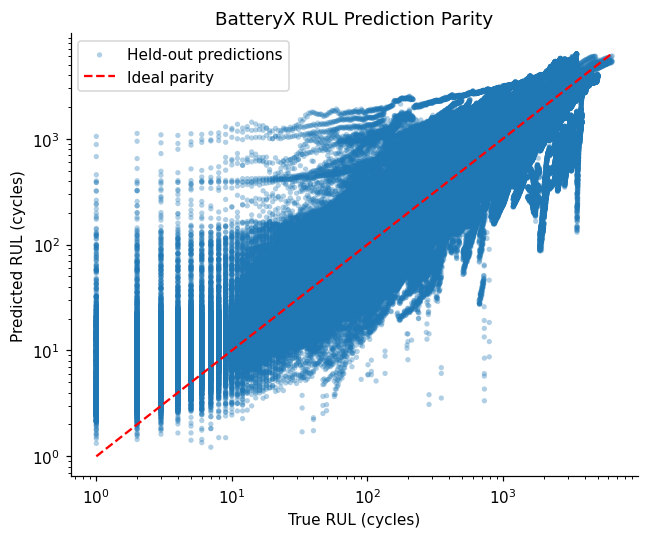

✅ Saved: parity_rul_loglog.png


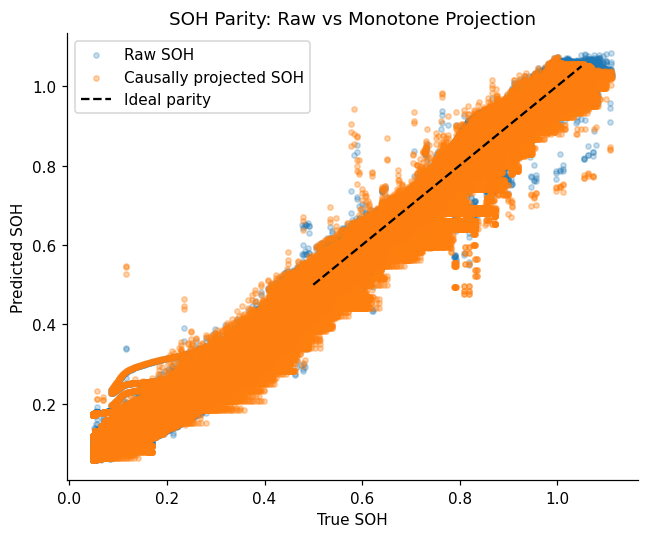

✅ Saved: parity_soh.png


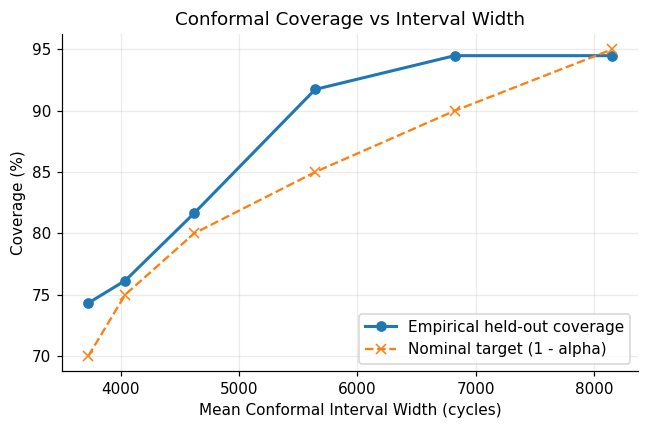

✅ Saved: coverage_vs_width.png


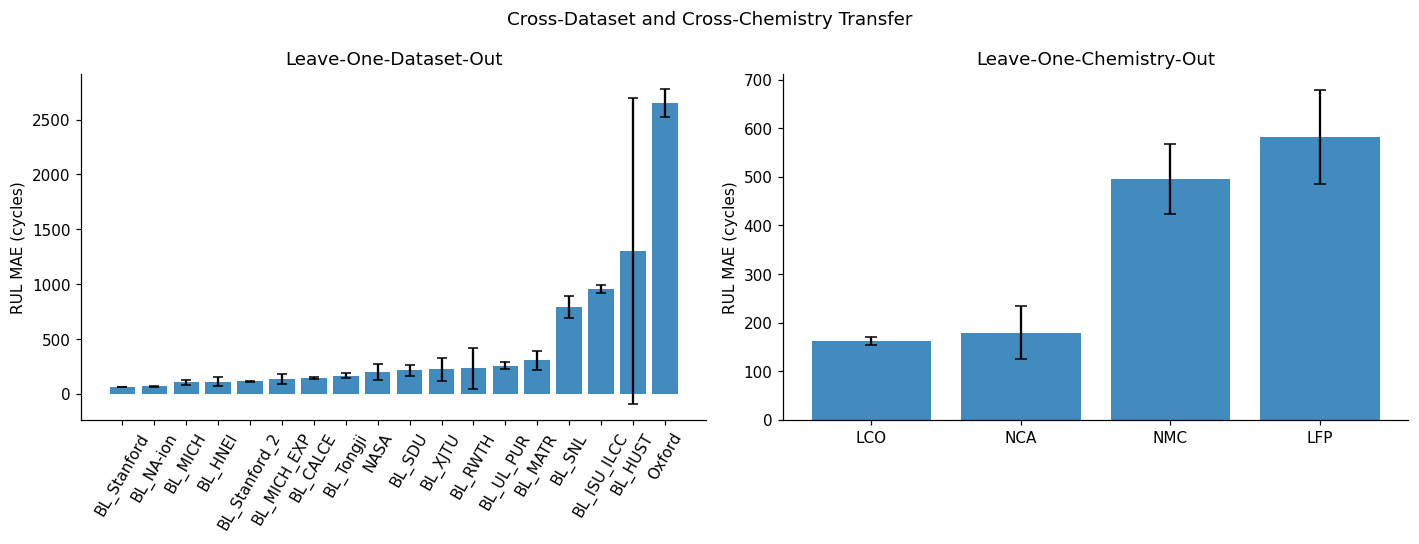

✅ Saved: lodo_loco_transfer.png


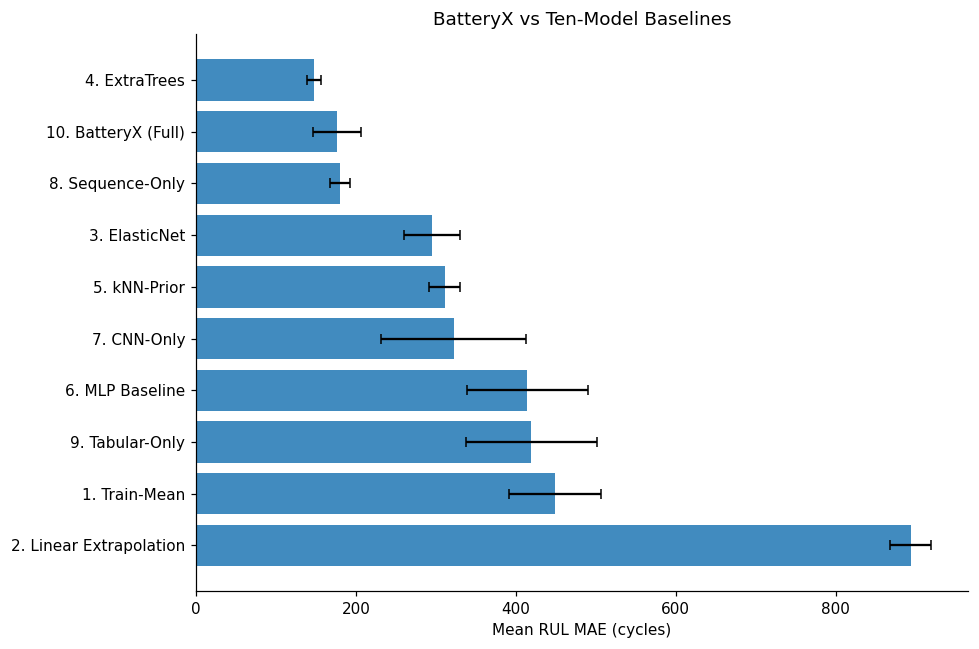

✅ Saved: baseline_comparison.png


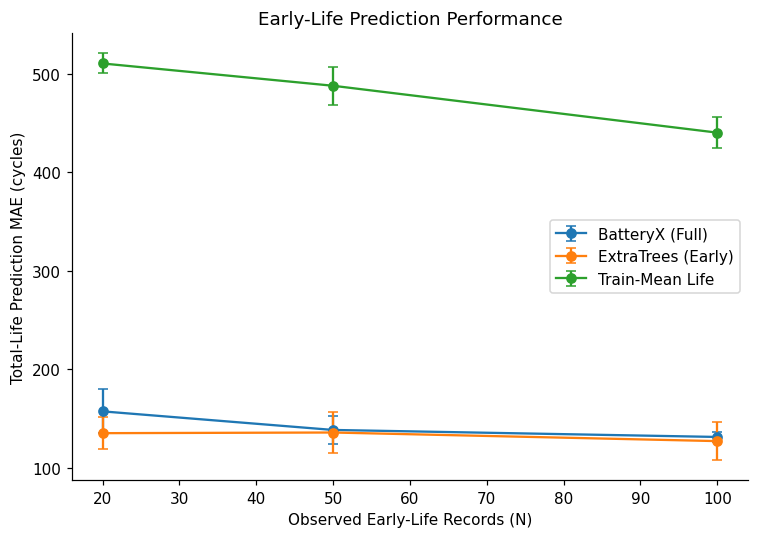

✅ Saved: early_life_baselines.png


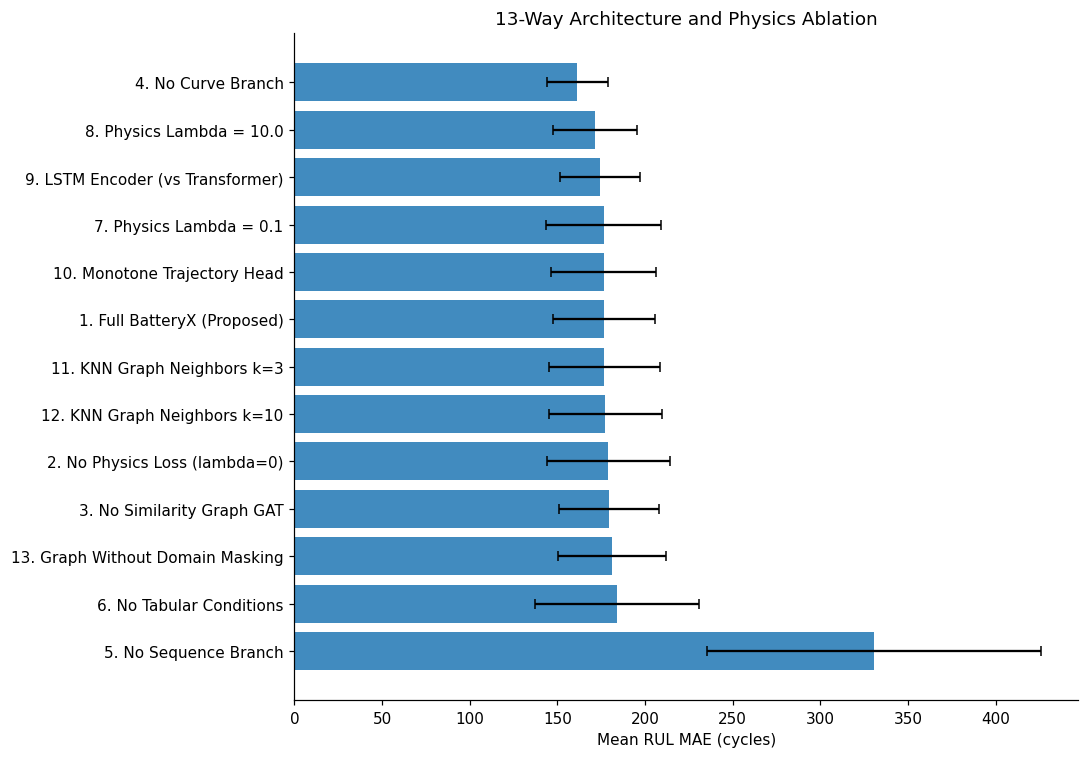

✅ Saved: ablation_study.png


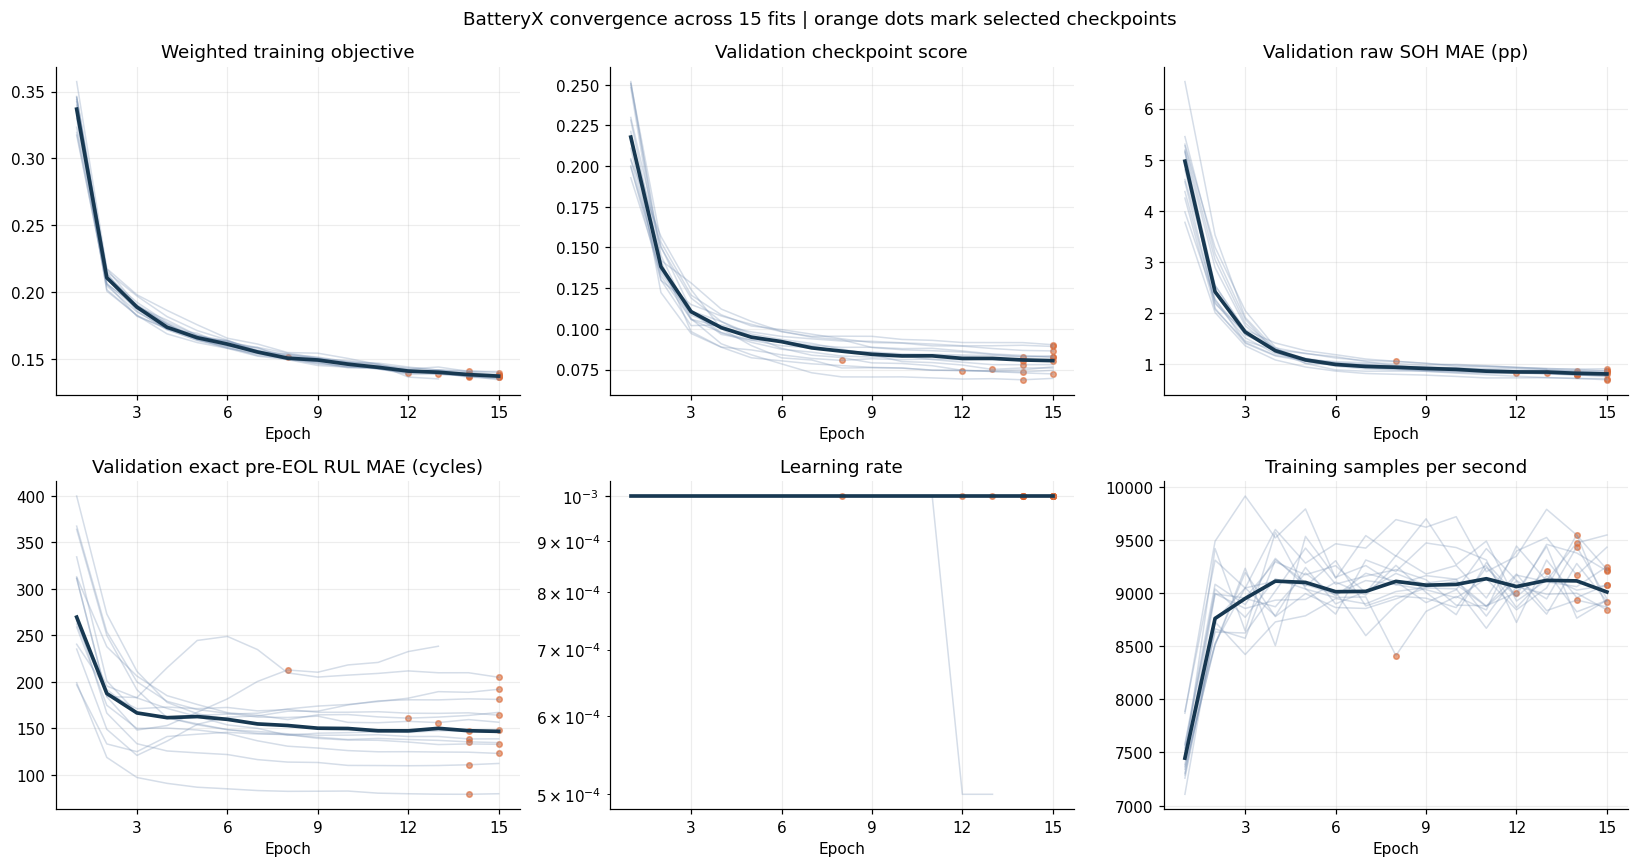

✅ Saved: training_dynamics.png


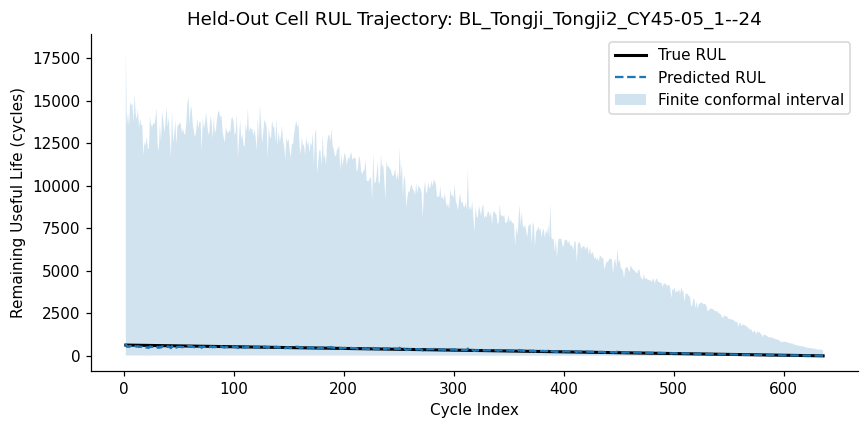

✅ Saved: conformal_trajectory_bands.png

BATTERYX — SECTION 17 COMPLETE
Plots generated: 9 / 9
Plots skipped: 0 / 9

PLOT MANIFEST


,Plot,Status,Description,Path
0,parity_rul_loglog.png,GENERATED,Held-out exact pre-EOL RUL predictions.,/kaggle/working/batteryx_training_v3/parity_ru...
1,parity_soh.png,GENERATED,Raw and causally projected SOH on held-out cells.,/kaggle/working/batteryx_training_v3/parity_so...
2,coverage_vs_width.png,GENERATED,Real calibration-curve quantiles and held-out ...,/kaggle/working/batteryx_training_v3/coverage_...
3,lodo_loco_transfer.png,GENERATED,Mean RUL MAE by held-out dataset and chemistry...,/kaggle/working/batteryx_training_v3/lodo_loco...
4,baseline_comparison.png,GENERATED,Mean and standard deviation of RUL MAE across ...,/kaggle/working/batteryx_training_v3/baseline_...
5,early_life_baselines.png,GENERATED,Mean lifetime prediction error by observed-pre...,/kaggle/working/batteryx_training_v3/early_lif...
6,ablation_study.png,GENERATED,Mean RUL MAE for completed ablation variants a...,/kaggle/working/batteryx_training_v3/ablation_...
7,training_dynamics.png,GENERATED,"All cross-validation fits, epoch metrics, and ...",/kaggle/working/batteryx_training_v3/training_...
8,conformal_trajectory_bands.png,GENERATED,"Real held-out cell trajectory, seed 42, nomina...",/kaggle/working/batteryx_training_v3/conformal...



OUTPUT DIRECTORY: /kaggle/working/batteryx_training_v3
PLOT MANIFEST: /kaggle/working/batteryx_training_v3/diagnostic_plot_manifest.csv

✅ Visualization run complete. Every generated plot uses actual saved predictions, metrics or histories.


In [59]:

# ================================================================
# BATTERYX — SECTION 17
# DIAGNOSTIC VISUALIZATIONS
#
# 9 real-data diagnostic figures
# Reads existing CSVs and recorded training histories only.
# Supports updated Section 12, 14, 15 and 16 output filenames.
# Aggregates results across seeds instead of selecting one seed.
# Reports unavailable experiments instead of fabricating plots.
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = CFG.OUT_DIR
os.makedirs(OUT_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 180,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10
})

PLOT_MANIFEST = []


# ------------------------------------------------
# 1. HELPERS
# ------------------------------------------------

def load_first_existing(filenames):

    for filename in filenames:

        path = os.path.join(OUT_DIR, filename)

        if os.path.isfile(path):

            try:
                df = pd.read_csv(path)

                if not df.empty:
                    print(f"Loaded: {filename} ({len(df)} rows)")
                    return df, path

            except Exception as exc:
                print(f"⚠️ Could not read {filename}: {exc}")

    return pd.DataFrame(), None


def numeric_column(df, col):

    if col not in df.columns:
        return pd.Series(dtype=float)

    return pd.to_numeric(
        df[col],
        errors="coerce"
    )


def complete_rows(df):

    if df.empty:
        return df

    if "status" in df.columns:
        df = df[
            df["status"].astype(str).str.lower()
            == "completed"
        ].copy()

    return df


def save_plot(fig, filename, description):

    path = os.path.join(OUT_DIR, filename)

    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    PLOT_MANIFEST.append({
        "Plot": filename,
        "Status": "GENERATED",
        "Description": description,
        "Path": path
    })

    print(f"✅ Saved: {filename}")


def skip_plot(filename, reason):

    print(f"⚠️ Skipped {filename}: {reason}")

    PLOT_MANIFEST.append({
        "Plot": filename,
        "Status": "SKIPPED",
        "Description": reason,
        "Path": ""
    })


def mean_std_by(df, group_col, value_col):

    temp = df.copy()

    temp[value_col] = numeric_column(
        temp,
        value_col
    )

    temp = temp.dropna(
        subset=[group_col, value_col]
    )

    if temp.empty:
        return pd.DataFrame()

    return temp.groupby(group_col)[value_col].agg(
        ["mean", "std", "count"]
    ).reset_index()


# ------------------------------------------------
# 2. LOAD ACTUAL PREDICTION AND RESULT STORES
# ------------------------------------------------

kfold_plot_df, kfold_source = load_first_existing([
    "kfold_predictions.csv"
])

lodo_plot_df, lodo_source = load_first_existing([
    "lodo_results.csv"
])

loco_plot_df, loco_source = load_first_existing([
    "loco_results.csv"
])

conformal_curve_df, conformal_source = load_first_existing([
    "conformal_calibration_curve.csv"
])

early_life_plot_df, early_life_source = load_first_existing([
    "early_life_results.csv"
])

baseline_plot_df, baseline_source = load_first_existing([
    "baselines_results.csv"
])

ablation_plot_df, ablation_source = load_first_existing([
    "ablation_results_v2.csv",
    "ablation_results.csv"
])

capacity_free_plot_df, capacity_free_source = load_first_existing([
    "capacity_free_results.csv"
])

print("\n" + "=" * 78)
print("BATTERYX — SECTION 17: DIAGNOSTIC VISUALIZATIONS")
print("=" * 78)

print("K-fold predictions:", len(kfold_plot_df))
print("LODO results:", len(lodo_plot_df))
print("LOCO results:", len(loco_plot_df))
print("Early-life results:", len(early_life_plot_df))
print("Baseline results:", len(baseline_plot_df))
print("Ablation results:", len(ablation_plot_df))


# ================================================================
# PLOT 1 — RUL PREDICTION PARITY
# ================================================================

try:

    required = {"rul_true", "rul_pred"}

    if (
        not kfold_plot_df.empty
        and required.issubset(kfold_plot_df.columns)
    ):

        sub = kfold_plot_df.copy()

        if "exact_mask" in sub.columns:
            sub = sub[
                numeric_column(sub, "exact_mask") > 0.5
            ]

        if "pre_eol_mask" in sub.columns:
            sub = sub[
                numeric_column(sub, "pre_eol_mask") > 0.5
            ]

        sub["rul_true"] = numeric_column(sub, "rul_true")
        sub["rul_pred"] = numeric_column(sub, "rul_pred")

        sub = sub[
            np.isfinite(sub["rul_true"])
            & np.isfinite(sub["rul_pred"])
            & (sub["rul_true"] > 0)
            & (sub["rul_pred"] > 0)
        ]

        if len(sub) > 0:

            fig, ax = plt.subplots(figsize=(6, 5))

            ax.scatter(
                sub["rul_true"],
                sub["rul_pred"],
                alpha=0.35,
                s=12,
                edgecolors="none",
                label="Held-out predictions"
            )

            upper = float(
                max(
                    sub["rul_true"].max(),
                    sub["rul_pred"].max()
                )
            )

            ax.plot(
                [1, upper],
                [1, upper],
                "r--",
                label="Ideal parity"
            )

            ax.set_xscale("log")
            ax.set_yscale("log")
            ax.set_xlabel("True RUL (cycles)")
            ax.set_ylabel("Predicted RUL (cycles)")
            ax.set_title("BatteryX RUL Prediction Parity")
            ax.legend()

            save_plot(
                fig,
                "parity_rul_loglog.png",
                "Held-out exact pre-EOL RUL predictions."
            )

        else:
            skip_plot(
                "parity_rul_loglog.png",
                "No positive finite exact pre-EOL RUL predictions."
            )

    else:
        skip_plot(
            "parity_rul_loglog.png",
            "K-fold prediction CSV or RUL columns unavailable."
        )

except Exception as exc:
    skip_plot("parity_rul_loglog.png", repr(exc))


# ================================================================
# PLOT 2 — SOH PARITY: RAW VS PROJECTED
# ================================================================

try:

    required = {
        "soh_true",
        "soh_pred_raw",
        "soh_pred_proj"
    }

    if (
        not kfold_plot_df.empty
        and required.issubset(kfold_plot_df.columns)
    ):

        sub = kfold_plot_df.copy()

        for col in required:
            sub[col] = numeric_column(sub, col)

        sub = sub.replace(
            [np.inf, -np.inf],
            np.nan
        ).dropna(
            subset=list(required)
        )

        if len(sub) > 0:

            fig, ax = plt.subplots(figsize=(6, 5))

            ax.scatter(
                sub["soh_true"],
                sub["soh_pred_raw"],
                alpha=0.25,
                s=12,
                label="Raw SOH"
            )

            ax.scatter(
                sub["soh_true"],
                sub["soh_pred_proj"],
                alpha=0.35,
                s=12,
                label="Causally projected SOH"
            )

            ax.plot(
                [0.5, 1.05],
                [0.5, 1.05],
                "k--",
                label="Ideal parity"
            )

            ax.set_xlabel("True SOH")
            ax.set_ylabel("Predicted SOH")
            ax.set_title("SOH Parity: Raw vs Monotone Projection")
            ax.legend()

            save_plot(
                fig,
                "parity_soh.png",
                "Raw and causally projected SOH on held-out cells."
            )

        else:
            skip_plot(
                "parity_soh.png",
                "No valid SOH predictions."
            )

    else:
        skip_plot(
            "parity_soh.png",
            "K-fold SOH prediction columns unavailable."
        )

except Exception as exc:
    skip_plot("parity_soh.png", repr(exc))


# ================================================================
# PLOT 3 — CONFORMAL COVERAGE VS INTERVAL WIDTH
# ================================================================

try:

    if not conformal_curve_df.empty:

        # Actual Section 10 column name:
        # empirical_test_cell_coverage%
        coverage_col = None

        for candidate in [
            "empirical_test_cell_coverage%",
            "empirical_test_cycle_coverage%",
            "empirical_test_coverage%"
        ]:

            if candidate in conformal_curve_df.columns:
                coverage_col = candidate
                break

        required = {
            "interval_width_cycles",
            "nominal_coverage%"
        }

        if (
            coverage_col is not None
            and required.issubset(conformal_curve_df.columns)
        ):

            sub = conformal_curve_df.copy()

            for col in [
                "interval_width_cycles",
                "nominal_coverage%",
                coverage_col
            ]:
                sub[col] = numeric_column(sub, col)

            sub = sub.replace(
                [np.inf, -np.inf],
                np.nan
            ).dropna(
                subset=[
                    "interval_width_cycles",
                    "nominal_coverage%",
                    coverage_col
                ]
            )

            if len(sub) > 0:

                sub = sub.sort_values(
                    "interval_width_cycles"
                )

                fig, ax = plt.subplots(figsize=(6, 4))

                ax.plot(
                    sub["interval_width_cycles"],
                    sub[coverage_col],
                    "o-",
                    linewidth=2,
                    label="Empirical held-out coverage"
                )

                ax.plot(
                    sub["interval_width_cycles"],
                    sub["nominal_coverage%"],
                    "x--",
                    linewidth=1.5,
                    label="Nominal target (1 - alpha)"
                )

                ax.set_xlabel("Mean Conformal Interval Width (cycles)")
                ax.set_ylabel("Coverage (%)")

                ax.set_title(
                    "Conformal Coverage vs Interval Width"
                )

                ax.grid(True, alpha=0.25)
                ax.legend()

                save_plot(
                    fig,
                    "coverage_vs_width.png",
                    "Real calibration-curve quantiles and held-out coverage."
                )

            else:
                skip_plot(
                    "coverage_vs_width.png",
                    "No finite empirical coverage and interval widths."
                )

        else:
            skip_plot(
                "coverage_vs_width.png",
                "Expected conformal calibration columns unavailable."
            )

    else:
        skip_plot(
            "coverage_vs_width.png",
            "conformal_calibration_curve.csv not found."
        )

except Exception as exc:
    skip_plot("coverage_vs_width.png", repr(exc))


# ================================================================
# PLOT 4 — LODO AND LOCO TRANSFER GENERALIZATION
# ================================================================

try:

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 5)
    )

    any_transfer = False

    # ------------------------
    # LODO panel
    # ------------------------

    ax = axes[0]

    if (
        not lodo_plot_df.empty
        and {"holdout_dataset", "RUL_MAE"}.issubset(
            lodo_plot_df.columns
        )
    ):

        lodo = lodo_plot_df.copy()
        lodo["RUL_MAE"] = numeric_column(lodo, "RUL_MAE")
        lodo = lodo.dropna(
            subset=["holdout_dataset", "RUL_MAE"]
        )

        if len(lodo) > 0:

            summary = (
                lodo.groupby("holdout_dataset")["RUL_MAE"]
                .agg(["mean", "std"])
                .sort_values("mean")
            )

            ax.bar(
                summary.index.astype(str),
                summary["mean"],
                yerr=summary["std"].fillna(0),
                capsize=3,
                alpha=0.85
            )

            ax.set_title("Leave-One-Dataset-Out")
            ax.set_ylabel("RUL MAE (cycles)")
            ax.tick_params(axis="x", rotation=60)

            any_transfer = True

        else:
            ax.set_title("LODO — no valid rows")

    else:
        ax.set_title("LODO — results unavailable")

    # ------------------------
    # LOCO panel
    # ------------------------

    ax = axes[1]

    if (
        not loco_plot_df.empty
        and {"holdout_chem", "RUL_MAE"}.issubset(
            loco_plot_df.columns
        )
    ):

        loco = loco_plot_df.copy()
        loco["RUL_MAE"] = numeric_column(loco, "RUL_MAE")

        loco = loco.dropna(
            subset=["holdout_chem", "RUL_MAE"]
        )

        if len(loco) > 0:

            summary = (
                loco.groupby("holdout_chem")["RUL_MAE"]
                .agg(["mean", "std"])
                .sort_values("mean")
            )

            ax.bar(
                summary.index.astype(str),
                summary["mean"],
                yerr=summary["std"].fillna(0),
                capsize=4,
                alpha=0.85
            )

            ax.set_title("Leave-One-Chemistry-Out")
            ax.set_ylabel("RUL MAE (cycles)")

            any_transfer = True

        else:
            ax.set_title("LOCO — no valid rows")

    else:
        ax.set_title("LOCO — results unavailable")

    fig.suptitle(
        "Cross-Dataset and Cross-Chemistry Transfer"
    )

    if any_transfer:

        save_plot(
            fig,
            "lodo_loco_transfer.png",
            "Mean RUL MAE by held-out dataset and chemistry across seeds."
        )

    else:

        plt.close(fig)

        skip_plot(
            "lodo_loco_transfer.png",
            "Neither LODO nor LOCO contains valid results."
        )

except Exception as exc:
    skip_plot("lodo_loco_transfer.png", repr(exc))


# ================================================================
# PLOT 5 — TEN-MODEL BASELINE COMPARISON
# ================================================================

try:

    if (
        not baseline_plot_df.empty
        and {"Model", "RUL_MAE"}.issubset(
            baseline_plot_df.columns
        )
    ):

        sub = complete_rows(
            baseline_plot_df.copy()
        )

        sub["RUL_MAE"] = numeric_column(sub, "RUL_MAE")

        sub = sub.dropna(
            subset=["Model", "RUL_MAE"]
        )

        if len(sub) > 0:

            summary = (
                sub.groupby("Model")["RUL_MAE"]
                .agg(["mean", "std", "count"])
                .sort_values("mean")
            )

            fig, ax = plt.subplots(
                figsize=(9, 6)
            )

            ax.barh(
                summary.index.astype(str),
                summary["mean"],
                xerr=summary["std"].fillna(0),
                capsize=3,
                alpha=0.85
            )

            ax.set_xlabel("Mean RUL MAE (cycles)")
            ax.set_title(
                "BatteryX vs Ten-Model Baselines"
            )

            ax.invert_yaxis()

            save_plot(
                fig,
                "baseline_comparison.png",
                "Mean and standard deviation of RUL MAE across completed seeds."
            )

        else:
            skip_plot(
                "baseline_comparison.png",
                "Baseline file contains no completed RUL metrics."
            )

    else:
        skip_plot(
            "baseline_comparison.png",
            "baselines_results.csv or expected columns unavailable."
        )

except Exception as exc:
    skip_plot("baseline_comparison.png", repr(exc))


# ================================================================
# PLOT 6 — EARLY-LIFE PREDICTION VS BASELINES
# ================================================================

try:

    required = {
        "N_cycles",
        "Model",
        "MAE"
    }

    if (
        not early_life_plot_df.empty
        and required.issubset(early_life_plot_df.columns)
    ):

        sub = complete_rows(
            early_life_plot_df.copy()
        )

        sub["N_cycles"] = numeric_column(sub, "N_cycles")
        sub["MAE"] = numeric_column(sub, "MAE")

        sub = sub.dropna(
            subset=["N_cycles", "MAE", "Model"]
        )

        if len(sub) > 0:

            summary = (
                sub.groupby(["Model", "N_cycles"])["MAE"]
                .agg(["mean", "std"])
                .reset_index()
            )

            fig, ax = plt.subplots(
                figsize=(7, 5)
            )

            for model_name in summary["Model"].unique():

                model_data = summary[
                    summary["Model"] == model_name
                ].sort_values("N_cycles")

                ax.errorbar(
                    model_data["N_cycles"],
                    model_data["mean"],
                    yerr=model_data["std"].fillna(0),
                    marker="o",
                    capsize=3,
                    label=str(model_name)
                )

            ax.set_xlabel("Observed Early-Life Records (N)")
            ax.set_ylabel("Total-Life Prediction MAE (cycles)")
            ax.set_title(
                "Early-Life Prediction Performance"
            )
            ax.legend()

            save_plot(
                fig,
                "early_life_baselines.png",
                "Mean lifetime prediction error by observed-prefix horizon and model."
            )

        else:
            skip_plot(
                "early_life_baselines.png",
                "No completed early-life metrics."
            )

    else:
        skip_plot(
            "early_life_baselines.png",
            "early_life_results.csv or required columns unavailable."
        )

except Exception as exc:
    skip_plot("early_life_baselines.png", repr(exc))


# ================================================================
# PLOT 7 — ARCHITECTURE AND PHYSICS ABLATION
# ================================================================

try:

    required = {
        "Ablation Variant",
        "RUL_MAE"
    }

    if (
        not ablation_plot_df.empty
        and required.issubset(ablation_plot_df.columns)
    ):

        sub = complete_rows(
            ablation_plot_df.copy()
        )

        sub["RUL_MAE"] = numeric_column(sub, "RUL_MAE")

        sub = sub.dropna(
            subset=["Ablation Variant", "RUL_MAE"]
        )

        if len(sub) > 0:

            summary = (
                sub.groupby("Ablation Variant")["RUL_MAE"]
                .agg(["mean", "std", "count"])
                .sort_values("mean")
            )

            fig, ax = plt.subplots(
                figsize=(10, 7)
            )

            ax.barh(
                summary.index.astype(str),
                summary["mean"],
                xerr=summary["std"].fillna(0),
                capsize=3,
                alpha=0.85
            )

            ax.set_xlabel("Mean RUL MAE (cycles)")
            ax.set_title(
                "13-Way Architecture and Physics Ablation"
            )

            ax.invert_yaxis()

            save_plot(
                fig,
                "ablation_study.png",
                "Mean RUL MAE for completed ablation variants across seeds."
            )

        else:
            skip_plot(
                "ablation_study.png",
                "No completed ablation RUL results."
            )

    else:
        skip_plot(
            "ablation_study.png",
            "Ablation results file or expected columns unavailable."
        )

except Exception as exc:
    skip_plot("ablation_study.png", repr(exc))


# ================================================================
# PLOT 8 — TRAINING CONVERGENCE DYNAMICS
# ================================================================

try:
    if KFOLD_HISTORIES:
        save_plot(training_figure(KFOLD_HISTORIES), "training_dynamics.png",
                  "All cross-validation fits, epoch metrics, and selected checkpoints.")
    else:
        skip_plot("training_dynamics.png", "No cross-validation histories available.")
except Exception as exc:
    skip_plot("training_dynamics.png", repr(exc))


# ================================================================
# PLOT 9 — REPRESENTATIVE HELD-OUT CELL TRAJECTORY
# ================================================================

try:

    required = {
        "cell_id",
        "cycle",
        "rul_true",
        "rul_pred",
        "interval_lo",
        "interval_hi"
    }

    if (
        not kfold_plot_df.empty
        and required.issubset(kfold_plot_df.columns)
    ):

        sub = kfold_plot_df.copy()

        # Select one seed so repeated seed predictions are not
        # drawn as repeated cycles on the same cell trajectory.
        if "seed" in sub.columns:

            seed_values = numeric_column(
                sub,
                "seed"
            ).dropna()

            if len(seed_values) > 0:

                selected_seed = int(seed_values.min())

                sub = sub[
                    numeric_column(sub, "seed")
                    == selected_seed
                ].copy()

        # Use exact, pre-EOL trajectory points only.
        if "exact_mask" in sub.columns:
            sub = sub[
                numeric_column(sub, "exact_mask") > 0.5
            ]

        if "pre_eol_mask" in sub.columns:
            sub = sub[
                numeric_column(sub, "pre_eol_mask") > 0.5
            ]

        for col in [
            "cycle",
            "rul_true",
            "rul_pred",
            "interval_lo",
            "interval_hi"
        ]:
            sub[col] = numeric_column(sub, col)

        sub = sub.replace(
            [np.inf, -np.inf],
            np.nan
        )

        sub = sub.dropna(
            subset=[
                "cycle",
                "rul_true",
                "rul_pred"
            ]
        )

        candidate_cells = (
            sub.groupby("cell_id")
            .size()
            .loc[lambda x: x >= 3]
        )

        if len(candidate_cells) > 0:

            # Deterministic representative: median trajectory length.
            candidate_cells = candidate_cells.sort_values()

            sample_cid = candidate_cells.index[
                len(candidate_cells) // 2
            ]

            cell_data = sub[
                sub["cell_id"] == sample_cid
            ].sort_values("cycle")

            fig, ax = plt.subplots(
                figsize=(8, 4)
            )

            ax.plot(
                cell_data["cycle"],
                cell_data["rul_true"],
                "k-",
                linewidth=2,
                label="True RUL"
            )

            ax.plot(
                cell_data["cycle"],
                cell_data["rul_pred"],
                "--",
                linewidth=1.5,
                label="Predicted RUL"
            )

            finite_intervals = (
                np.isfinite(cell_data["interval_lo"])
                & np.isfinite(cell_data["interval_hi"])
            )

            if finite_intervals.any():

                band = cell_data[finite_intervals]

                ax.fill_between(
                    band["cycle"],
                    band["interval_lo"],
                    band["interval_hi"],
                    alpha=0.2,
                    label="Finite conformal interval"
                )

            nominal = (
                100.0 * (1.0 - CFG.CONFORMAL_ALPHA)
            )

            ax.set_xlabel("Cycle Index")
            ax.set_ylabel("Remaining Useful Life (cycles)")

            ax.set_title(
                f"Held-Out Cell RUL Trajectory: {sample_cid}"
            )

            ax.legend()

            save_plot(
                fig,
                "conformal_trajectory_bands.png",
                f"Real held-out cell trajectory, seed {selected_seed if 'selected_seed' in locals() else 'available'}, nominal target {nominal:.0f}%."
            )

        else:
            skip_plot(
                "conformal_trajectory_bands.png",
                "No exact pre-EOL cell with at least three prediction records."
            )

    else:
        skip_plot(
            "conformal_trajectory_bands.png",
            "K-fold prediction file lacks required trajectory columns."
        )

except Exception as exc:
    skip_plot("conformal_trajectory_bands.png", repr(exc))


# ================================================================
# 10. EXPORT PLOT MANIFEST
# ================================================================

PLOT_MANIFEST_DF = pd.DataFrame(
    PLOT_MANIFEST
)

manifest_path = os.path.join(
    OUT_DIR,
    "diagnostic_plot_manifest.csv"
)

PLOT_MANIFEST_DF.to_csv(
    manifest_path,
    index=False
)

generated = int(
    (PLOT_MANIFEST_DF["Status"] == "GENERATED").sum()
)

skipped = int(
    (PLOT_MANIFEST_DF["Status"] == "SKIPPED").sum()
)

print("\n" + "=" * 78)
print("BATTERYX — SECTION 17 COMPLETE")
print("=" * 78)

print(f"Plots generated: {generated} / 9")
print(f"Plots skipped: {skipped} / 9")

print("\nPLOT MANIFEST")
display(PLOT_MANIFEST_DF)

print("\nOUTPUT DIRECTORY:", OUT_DIR)
print("PLOT MANIFEST:", manifest_path)

print(
    "\n✅ Visualization run complete. "
    "Every generated plot uses actual saved predictions, metrics or histories."
)


## 18. Standalone Headless Inference Module (`batteryx_infer.py`)
Per **Requirements A, P, Fix D5**:
- Exports standalone module `batteryx_infer.py` which imports `batteryx_core`.
- Loads trained checkpoint bundle with `strict=True`.
- Returns structured JSON containing raw SOH, causally projected SOH, RUL, conformal interval, physics compliance, and neighbor prototype IDs.
- Validates numerical parity against reference `predict_pool` within $1\times 10^{-5}$ on a held-out test cell.


In [60]:

# ================================================================
# BATTERYX — SECTION 18
# STANDALONE HEADLESS INFERENCE MODULE
#
# Final model training + independent calibration
# Portable deployment bundle
# Strict state-dict loading
# JSON-serializable inference output
# Numerical parity test on held-out test cell
# ================================================================

import os
import sys
import json
import math
import shutil
import importlib
import numpy as np
import pandas as pd
import torch

# ------------------------------------------------
# 1. FINAL GROUP-SAFE DEPLOYMENT SPLIT
# ------------------------------------------------

print("=" * 78)
print("BATTERYX — SECTION 18: DEPLOYMENT BUNDLE")
print("=" * 78)

seed_all(42)

final_fit_cells, final_val_cells, final_cal_cells, final_test_cells = (
    make_splits(
        ALL_CELLS,
        "in_dist",
        seed=42
    )
)

assert all([
    final_fit_cells,
    final_val_cells,
    final_cal_cells,
    final_test_cells
]), "One or more deployment partitions are empty."

# Explicit partition leakage assertions.
partition_sets = [
    {c.cell_id for c in part}
    for part in (
        final_fit_cells,
        final_val_cells,
        final_cal_cells,
        final_test_cells
    )
]

for i in range(len(partition_sets)):
    for j in range(i + 1, len(partition_sets)):
        assert partition_sets[i].isdisjoint(
            partition_sets[j]
        ), "Deployment partition leakage detected."

print(
    f"Group-safe deployment split | "
    f"Fit={len(final_fit_cells)}, "
    f"Val={len(final_val_cells)}, "
    f"Cal={len(final_cal_cells)}, "
    f"Test={len(final_test_cells)}"
)

# ------------------------------------------------
# 2. FIT-ONLY NORMALIZATION AND REFERENCE BANK
# ------------------------------------------------

final_stats = fit_stats(final_fit_cells)
final_bank = build_bank(final_fit_cells, final_stats)

# Balanced training weights.
final_ds_shares, final_cell_weights, final_weights_feasible = (
    solve_water_filling_weights(
        final_fit_cells,
        cap=0.25
    )
)

print(
    "Balanced training weights feasible:",
    final_weights_feasible
)

# ------------------------------------------------
# 3. EXPLICIT MODEL CONFIGURATION
# ------------------------------------------------

FINAL_MODEL_CONFIG = {
    "D_MODEL": int(CFG.D_MODEL),
    "SEQ_TYPE": str(CFG.SEQ_TYPE),
    "KNN": int(CFG.KNN),
    "HEADS": int(CFG.HEADS),

    "USE_CNN": True,
    "USE_SEQ": True,
    "USE_TAB": True,
    "USE_GRAPH": True,

    "USE_MONOTONE_HEAD": bool(CFG.USE_MONOTONE_HEAD),

    "CONFORMAL_ALPHA": float(CFG.CONFORMAL_ALPHA),
    "EOL_SOH": float(CFG.EOL_SOH),

    "INFERENCE_BATCH_SIZE": 512
}

# Instantiate the exact architecture that will be reconstructed
# by the standalone inference module.
final_model = bc.BatteryX(
    cond_dim=15,
    desc_dim=21,
    d_model=FINAL_MODEL_CONFIG["D_MODEL"],
    seq_type=FINAL_MODEL_CONFIG["SEQ_TYPE"],
    knn=FINAL_MODEL_CONFIG["KNN"],
    heads=FINAL_MODEL_CONFIG["HEADS"],

    use_cnn=FINAL_MODEL_CONFIG["USE_CNN"],
    use_seq=FINAL_MODEL_CONFIG["USE_SEQ"],
    use_tab=FINAL_MODEL_CONFIG["USE_TAB"],
    use_graph=FINAL_MODEL_CONFIG["USE_GRAPH"],

    use_monotone_head=FINAL_MODEL_CONFIG["USE_MONOTONE_HEAD"],

    stats=final_stats
).to(DEVICE)

# ------------------------------------------------
# 4. BUILD FINAL TRAINING AND VALIDATION POOLS
# ------------------------------------------------

final_tr_pool = bc.BatteryPool(
    final_fit_cells,
    final_stats,
    final_bank,
    is_train=True,
    cell_weights=final_cell_weights
)

final_va_pool = bc.BatteryPool(
    final_val_cells,
    final_stats,
    final_bank,
    is_train=False,
    stride=5
)

final_cal_pool = bc.BatteryPool(
    final_cal_cells,
    final_stats,
    final_bank,
    is_train=False
)

final_test_pool = bc.BatteryPool(
    final_test_cells,
    final_stats,
    final_bank,
    is_train=False
)

print("\nTraining final deployment model...")
print("Maximum epochs: 15")
print("Seed: 42")

# One final deployment training run.
final_model, final_history = train_tracked(
    'standalone_inference',
    final_tr_pool,
    final_va_pool,
    final_stats,

    model=final_model,

    epochs=min(15, int(CFG.EPOCHS)),
    patience=min(5, int(CFG.PATIENCE)),

    lambda_phys=CFG.LAMBDA_PHYS,
    huber_delta=CFG.HUBER_DELTA,

    device=DEVICE
)

print("✅ Final deployment model training complete.")

# ------------------------------------------------
# 5. INDEPENDENT CONFORMAL CALIBRATION
# ------------------------------------------------

final_cal_info = bc.calibrate_conformal_rul_detailed(
    final_model,
    final_cal_pool,
    final_stats,
    alpha=CFG.CONFORMAL_ALPHA,
    allow_insufficient=True
)

final_q = float(
    final_cal_info["q_conformal"]
)

print("\nFINAL CALIBRATION")
print("-" * 60)
print("Status:", final_cal_info["calibration_status"])
print("Quantile status:", final_cal_info["quantile_status"])
print("Eligible calibration cells:", final_cal_info["n_cal"])
print("Minimum required:", final_cal_info["n_min_required"])
print("Calibration rank:", final_cal_info["rank"])
print("Conformal quantile:", final_q)

DEPLOYMENT_BUNDLE_STATUS = "not_created"

# Do not export a bundle that claims finite conformal
# intervals when calibration is insufficient.
if (
    final_cal_info["quantile_status"] != "finite"
    or not math.isfinite(final_q)
):

    deployment_reason = (
        f"status={final_cal_info['calibration_status']}, "
        f"eligible={final_cal_info['n_cal']}, "
        f"required={final_cal_info['n_min_required']}, "
        f"rank={final_cal_info['rank']}"
    )

    DEPLOYMENT_BUNDLE_STATUS = (
        "skipped_insufficient_calibration"
    )

    print("\n⚠️ Deployment bundle not created.")
    print(deployment_reason)

    print(
        "The evaluation results remain valid, but do not "
        "claim a calibrated standalone deployment."
    )

else:

    # ------------------------------------------------
    # 6. EXPORT PORTABLE DEPLOYMENT BUNDLE
    # ------------------------------------------------

    os.makedirs(
        CFG.OUT_DIR,
        exist_ok=True
    )

    print("\nExporting deployment artifacts...")

    # Copy the exact core module currently imported and used.
    core_source_path = os.path.abspath(
        bc.__file__
    )

    if not os.path.isfile(core_source_path):
        raise FileNotFoundError(
            f"Active BatteryX core module not found: {core_source_path}"
        )

    shutil.copy2(
        core_source_path,
        os.path.join(
            CFG.OUT_DIR,
            "batteryx_core.py"
        )
    )

    # Save CPU checkpoint tensors for portability.
    model_state_cpu = {
        key: value.detach().cpu()
        for key, value in final_model.state_dict().items()
    }

    torch.save(
        {
            "model_state_dict": model_state_cpu
        },
        os.path.join(
            CFG.OUT_DIR,
            "batteryx_best.pt"
        )
    )

    # Save fitted training statistics and calibration value.
    stats_copy = dict(final_stats)
    stats_copy["q_conformal"] = final_q

    with open(
        os.path.join(CFG.OUT_DIR, "stats.json"),
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            stats_copy,
            f,
            indent=2,
            allow_nan=False
        )

    # Save reference bank.
    np.savez_compressed(
        os.path.join(
            CFG.OUT_DIR,
            "compact_bank.npz"
        ),

        descriptors=final_bank["descriptors"].detach().cpu().numpy(),

        outcomes=final_bank["outcomes"].detach().cpu().numpy(),

        bank_features=final_bank["bank_features"].detach().cpu().numpy(),

        cell_ids=np.asarray(final_bank["cell_ids"], dtype=str),

        datasets=np.asarray(final_bank["datasets"], dtype=str),

        chems=np.asarray(final_bank["chems"], dtype=str)
    )

    # Save complete model configuration.
    with open(
        os.path.join(CFG.OUT_DIR, "config.json"),
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            FINAL_MODEL_CONFIG,
            f,
            indent=2,
            allow_nan=False
        )

    # ------------------------------------------------
    # 7. GENERATE PORTABLE INFERENCE MODULE
    # ------------------------------------------------

    infer_code = r'''import json
import os

import numpy as np
import torch
import batteryx_core as bc


class BatteryXInferenceEngine:
    """
    Standalone BatteryX prediction engine.

    Required input:
        A validated BatteryX Cell object.

    Output:
        Strict JSON-serializable Python dictionary containing:
        - Raw SOH
        - Causally projected SOH
        - RUL
        - Conformal interval bounds
        - Physics compliance
        - Nearest prototype cell IDs
    """

    def __init__(self, bundle_dir, device=None):

        self.bundle_dir = os.path.abspath(bundle_dir)

        self.device = torch.device(
            device or (
                "cuda" if torch.cuda.is_available() else "cpu"
            )
        )

        with open(
            os.path.join(self.bundle_dir, "stats.json"),
            "r",
            encoding="utf-8"
        ) as f:
            self.stats = json.load(f)

        with open(
            os.path.join(self.bundle_dir, "config.json"),
            "r",
            encoding="utf-8"
        ) as f:
            self.config = json.load(f)

        self.q_conformal = float(
            self.stats["q_conformal"]
        )

        if not np.isfinite(self.q_conformal):
            raise ValueError(
                "Deployment bundle does not contain a finite calibration quantile."
            )

        # Load compact reference bank.
        with np.load(
            os.path.join(
                self.bundle_dir,
                "compact_bank.npz"
            ),
            allow_pickle=False
        ) as data:

            self.bank = {
                "descriptors": torch.as_tensor(
                    data["descriptors"].copy(),
                    dtype=torch.float32
                ),

                "outcomes": torch.as_tensor(
                    data["outcomes"].copy(),
                    dtype=torch.float32
                ),

                "bank_features": torch.as_tensor(
                    data["bank_features"].copy(),
                    dtype=torch.float32
                ),

                "cell_ids": data["cell_ids"].astype(str).tolist(),

                "datasets": data["datasets"].astype(str).tolist(),

                "chems": data["chems"].astype(str).tolist()
            }

        # Rebuild exactly the original architecture.
        self.model = bc.BatteryX(

            cond_dim=15,
            desc_dim=21,

            d_model=int(
                self.config["D_MODEL"]
            ),

            seq_type=self.config["SEQ_TYPE"],

            knn=int(
                self.config["KNN"]
            ),

            heads=int(
                self.config["HEADS"]
            ),

            use_cnn=bool(
                self.config["USE_CNN"]
            ),

            use_seq=bool(
                self.config["USE_SEQ"]
            ),

            use_tab=bool(
                self.config["USE_TAB"]
            ),

            use_graph=bool(
                self.config["USE_GRAPH"]
            ),

            use_monotone_head=bool(
                self.config["USE_MONOTONE_HEAD"]
            ),

            stats=self.stats

        ).to(self.device)

        checkpoint_path = os.path.join(
            self.bundle_dir,
            "batteryx_best.pt"
        )

        try:
            checkpoint = torch.load(
                checkpoint_path,
                map_location=self.device,
                weights_only=True
            )
        except TypeError:
            checkpoint = torch.load(
                checkpoint_path,
                map_location=self.device
            )

        state = checkpoint["model_state_dict"]

        # Strict checkpoint validation.
        self.model.load_state_dict(
            state,
            strict=True
        )

        self.model.eval()

    @staticmethod
    def _json_list(values):

        arr = np.asarray(
            values,
            dtype=np.float64
        ).reshape(-1)

        return [
            float(x) if np.isfinite(x) else None
            for x in arr
        ]

    @torch.no_grad()
    def predict_arrays(self, cell):

        """
        Internal numerical prediction method.
        Returns NumPy arrays for parity testing.
        """

        pool = bc.BatteryPool(
            [cell],
            self.stats,
            self.bank,

            knn=int(
                self.config["KNN"]
            ),

            is_train=False,
            stride=1
        )

        if len(pool) == 0:
            raise ValueError(
                "Input cell produced no valid inference samples."
            )

        soh_raw, rul, rul_lower, rul_upper = bc.predict_pool(
            self.model,
            pool,

            q_conformal=self.q_conformal,

            batch_size=int(
                self.config.get(
                    "INFERENCE_BATCH_SIZE",
                    512
                )
            )
        )

        soh_projected = bc.causal_monotone_project(
            soh_raw
        )

        # Percentage of adjacent predictions respecting
        # the expected non-increasing SOH trajectory.
        if len(soh_raw) > 1:

            raw_compliance = float(
                np.mean(
                    np.diff(soh_raw) <= 2e-3
                ) * 100.0
            )

            projected_compliance = float(
                np.mean(
                    np.diff(soh_projected) <= 2e-3
                ) * 100.0
            )

        else:

            raw_compliance = 100.0
            projected_compliance = 100.0

        # Find nearest eligible reference prototypes
        # for the first observed cycle.
        sample = pool.samples[0]

        distances = sample["dists"].detach().cpu().clone()

        self_mask = sample["self_mask"].detach().cpu().bool()

        distances[~self_mask] = float("inf")

        finite = torch.isfinite(distances)

        neighbor_ids = []

        if finite.any():

            n_neighbors = min(
                int(self.config["KNN"]),
                int(finite.sum())
            )

            indices = torch.topk(
                distances,
                n_neighbors,
                largest=False
            ).indices.tolist()

            neighbor_ids = [
                self.bank["cell_ids"][int(i)]
                for i in indices
            ]

        cycles = [
            int(s["cycle_k"])
            for s in pool.samples
        ]

        return {
            "cycles": np.asarray(cycles),
            "soh_raw": soh_raw,
            "soh_projected": soh_projected,
            "rul": rul,
            "rul_lower": rul_lower,
            "rul_upper": rul_upper,

            "raw_physics_compliance": raw_compliance,
            "projected_physics_compliance": projected_compliance,

            "neighbor_ids": neighbor_ids
        }

    @torch.no_grad()
    def predict(self, cell):

        """
        Public prediction interface.

        Every returned value is JSON-serializable.
        Infinite upper bounds are represented as null and
        identified by interval_upper_unbounded.
        """

        result = self.predict_arrays(cell)

        upper_unbounded = [
            bool(np.isposinf(x))
            for x in result["rul_upper"]
        ]

        output = {
            "cell_id": str(cell.cell_id),

            "cycles": [
                int(x) for x in result["cycles"]
            ],

            "soh_raw": self._json_list(
                result["soh_raw"]
            ),

            "soh_projected": self._json_list(
                result["soh_projected"]
            ),

            "rul": self._json_list(
                result["rul"]
            ),

            "rul_lower": self._json_list(
                result["rul_lower"]
            ),

            "rul_upper": self._json_list(
                result["rul_upper"]
            ),

            "interval_upper_unbounded": upper_unbounded,

            "conformal_alpha": float(
                self.config["CONFORMAL_ALPHA"]
            ),

            "conformal_quantile": float(
                self.q_conformal
            ),

            "physics_compliance_percent": {
                "raw_soh": float(
                    result["raw_physics_compliance"]
                ),

                "projected_soh": float(
                    result["projected_physics_compliance"]
                )
            },

            "nearest_prototype_cell_ids": list(
                result["neighbor_ids"]
            )
        }

        # Guarantee strict JSON compatibility.
        json.dumps(
            output,
            allow_nan=False
        )

        return output
'''

    infer_path = os.path.join(
        CFG.OUT_DIR,
        "batteryx_infer.py"
    )

    with open(
        infer_path,
        "w",
        encoding="utf-8"
    ) as f:

        f.write(infer_code)

    print(
        "✅ Standalone inference module exported:",
        infer_path
    )

    # ------------------------------------------------
    # 8. IMPORT THE EXPORTED MODULE
    # ------------------------------------------------

    output_path = os.path.abspath(
        CFG.OUT_DIR
    )

    if output_path in sys.path:
        sys.path.remove(output_path)

    sys.path.insert(
        0,
        output_path
    )

    importlib.invalidate_caches()

    # Avoid accidentally reusing a stale module.
    sys.modules.pop(
        "batteryx_infer",
        None
    )

    import batteryx_infer as bi

    print(
        "✅ Standalone inference module imported."
    )

    # ------------------------------------------------
    # 9. NUMERICAL PARITY TEST ON A HELD-OUT CELL
    # ------------------------------------------------

    if len(final_test_cells) == 0:
        raise RuntimeError(
            "No held-out test cell available for inference parity."
        )

    test_cell_sample = final_test_cells[0]

    # Reference prediction from the notebook model.
    reference_pool = bc.BatteryPool(
        [test_cell_sample],
        final_stats,
        final_bank,
        is_train=False,
        stride=1
    )

    ref_soh, ref_rul, ref_lo, ref_hi = bc.predict_pool(
        final_model,
        reference_pool,
        q_conformal=final_q
    )

    # Prediction from independently reconstructed checkpoint.
    inference_engine = bi.BatteryXInferenceEngine(
        bundle_dir=CFG.OUT_DIR,
        device=DEVICE
    )

    exported_arrays = inference_engine.predict_arrays(
        test_cell_sample
    )

    diff_soh = float(
        np.max(
            np.abs(
                exported_arrays["soh_raw"] - ref_soh
            )
        )
    )

    diff_rul = float(
        np.max(
            np.abs(
                exported_arrays["rul"] - ref_rul
            )
        )
    )

    diff_lower = float(
        np.max(
            np.abs(
                exported_arrays["rul_lower"] - ref_lo
            )
        )
    )

    diff_upper = float(
        np.max(
            np.abs(
                exported_arrays["rul_upper"] - ref_hi
            )
        )
    )

    assert diff_soh < 1e-5, (
        f"SOH parity failed: {diff_soh}"
    )

    assert diff_rul < 1e-5, (
        f"RUL parity failed: {diff_rul}"
    )

    assert diff_lower < 1e-5, (
        f"Lower interval parity failed: {diff_lower}"
    )

    assert diff_upper < 1e-5, (
        f"Upper interval parity failed: {diff_upper}"
    )

    # ------------------------------------------------
    # 10. STRICT JSON OUTPUT TEST
    # ------------------------------------------------

    json_prediction = inference_engine.predict(
        test_cell_sample
    )

    json_text = json.dumps(
        json_prediction,
        allow_nan=False
    )

    # Parse it again to prove it is valid JSON.
    parsed_prediction = json.loads(
        json_text
    )

    assert (
        parsed_prediction["cell_id"]
        == str(test_cell_sample.cell_id)
    )

    assert len(
        parsed_prediction["soh_raw"]
    ) == len(
        parsed_prediction["rul"]
    )

    # ------------------------------------------------
    # 11. FINAL DEPLOYMENT STATUS
    # ------------------------------------------------

    DEPLOYMENT_BUNDLE_STATUS = "created"

    print("\n" + "=" * 78)
    print("BATTERYX — DEPLOYMENT VERIFICATION")
    print("=" * 78)

    print("Bundle status:", DEPLOYMENT_BUNDLE_STATUS)

    print("\nNumerical parity errors:")
    print(f"SOH maximum difference: {diff_soh:.3e}")
    print(f"RUL maximum difference: {diff_rul:.3e}")
    print(f"Lower interval difference: {diff_lower:.3e}")
    print(f"Upper interval difference: {diff_upper:.3e}")

    print("\nPhysics compliance:")
    print(
        "Raw SOH:",
        f"{json_prediction['physics_compliance_percent']['raw_soh']:.2f}%"
    )
    print(
        "Projected SOH:",
        f"{json_prediction['physics_compliance_percent']['projected_soh']:.2f}%"
    )

    print("\nNearest reference prototypes:")
    print(
        json_prediction["nearest_prototype_cell_ids"]
    )

    print("\nJSON serialization: PASSED")

    print("\nDEPLOYMENT FILES")
    print("-" * 78)

    for filename in [
        "batteryx_core.py",
        "batteryx_infer.py",
        "batteryx_best.pt",
        "stats.json",
        "compact_bank.npz",
        "config.json"
    ]:

        path = os.path.join(
            CFG.OUT_DIR,
            filename
        )

        print(
            ("✅ " if os.path.isfile(path) else "❌ "),
            filename
        )

    print("\n✅ SECTION 18 DEPLOYMENT VERIFICATION COMPLETE.")

    # Keep the portable deployment module and engine available.
    DEPLOYMENT_ENGINE = inference_engine
    DEPLOYMENT_TEST_JSON = json_prediction


BATTERYX — SECTION 18: DEPLOYMENT BUNDLE
✅ Group-safe IN_DIST split | Fit=415, Val=90, Cal=101, Test=151
Group-safe deployment split | Fit=415, Val=90, Cal=101, Test=151
Balanced training weights feasible: True

Training final deployment model...
Maximum epochs: 15
Seed: 42
   [Epoch  1/15] Loss 0.3424 | Val score 0.2482 | SOH MAE 4.97 pp | RUL MAE 334.2 cycles | LR 1.00e-03 | Train/val 5.2/1.3s
   [Epoch  2/15] Loss 0.2055 | Val score 0.1358 | SOH MAE 2.27 pp | RUL MAE 200.9 cycles | LR 1.00e-03 | Train/val 4.2/0.7s
   [Epoch  3/15] Loss 0.1904 | Val score 0.1110 | SOH MAE 1.42 pp | RUL MAE 166.5 cycles | LR 1.00e-03 | Train/val 4.4/0.8s
   [Epoch  4/15] Loss 0.1759 | Val score 0.1045 | SOH MAE 1.17 pp | RUL MAE 161.4 cycles | LR 1.00e-03 | Train/val 4.2/0.7s
   [Epoch  5/15] Loss 0.1642 | Val score 0.0954 | SOH MAE 1.08 pp | RUL MAE 154.8 cycles | LR 1.00e-03 | Train/val 4.1/0.8s
   [Epoch  6/15] Loss 0.1587 | Val score 0.0881 | SOH MAE 1.04 pp | RUL MAE 148.6 cycles | LR 1.00e-03 | 

## 19. Model Card & Artifact Serialization
Per **Rule R1 & R5**: Model card values are populated dynamically from computed DataFrames without hardcoded constants.


In [61]:
# Dynamically construct model_card.md using computed results only
kfold_mae_val = float(KFOLD_DF['SOH_MAE_proj'].mean()) if len(KFOLD_DF) else float('nan')
kfold_rul_val = float(KFOLD_DF['RUL_MAE'].mean()) if len(KFOLD_DF) else float('nan')
kfold_cov_val = float(KFOLD_DF['Conformal_Cell_Cov%'].mean()) if len(KFOLD_DF) else float('nan')

lodo_mae_val = float(LODO_DF['SOH_MAE_proj'].mean()) if len(LODO_DF) else float('nan')
lodo_rul_val = float(LODO_DF['RUL_MAE'].mean()) if len(LODO_DF) else float('nan')

card_text = f"""# Model Card: BatteryX Degradation Prognostics

## Model Details
- **Architecture**: BatteryX (CurveCNN + Transformer SeqEnc + CellGAT with 21-dim Outcome Provenance)
- **Framework**: PyTorch with ModelEMA (training AMP: {CFG.USE_AMP})
- **Version**: 3.0 (cycle-space auxiliary objective and fade-rate supervision)
- **Run Mode**: {CFG.RUN_MODE} (Seeds: {CFG.SEEDS})

## Intended Use
Cross-chemistry battery state-of-health estimation and remaining useful life forecasting.

## Performance Metrics (Computed Dynamically from this Run)
- **5-Fold In-Distribution SOH MAE (Monotone Projected)**: {kfold_mae_val:.4f}
- **5-Fold In-Distribution RUL MAE**: {kfold_rul_val:.1f} cycles
- **5-Fold Conformal Cell-Level Coverage**: {kfold_cov_val:.1f}%
- **Leave-One-Dataset-Out (LODO) SOH MAE**: {lodo_mae_val:.4f}
- **Leave-One-Dataset-Out (LODO) RUL MAE**: {lodo_rul_val:.1f} cycles

## Scientific Limitations & Disclosures
- Capacity-derived SOH predictions rely on capacity measurements and are labeled trivial proxies.
- Cross-domain conformal coverage represents empirical transfer coverage without formal exchangeability guarantees.
"""

card_path = os.path.join(CFG.OUT_DIR, 'model_card.md')
with open(card_path, 'w', encoding='utf-8') as f:
    f.write(card_text.strip())
print(f"📋 Dynamic Model Card exported to: {card_path}")
print(card_text)


📋 Dynamic Model Card exported to: /kaggle/working/batteryx_training_v3/model_card.md
# Model Card: BatteryX Degradation Prognostics

## Model Details
- **Architecture**: BatteryX (CurveCNN + Transformer SeqEnc + CellGAT with 21-dim Outcome Provenance)
- **Framework**: PyTorch with ModelEMA (training AMP: True)
- **Version**: 3.0 (cycle-space auxiliary objective and fade-rate supervision)
- **Run Mode**: full (Seeds: [42, 43, 44])

## Intended Use
Cross-chemistry battery state-of-health estimation and remaining useful life forecasting.

## Performance Metrics (Computed Dynamically from this Run)
- **5-Fold In-Distribution SOH MAE (Monotone Projected)**: 0.0107
- **5-Fold In-Distribution RUL MAE**: 170.7 cycles
- **5-Fold Conformal Cell-Level Coverage**: 90.5%
- **Leave-One-Dataset-Out (LODO) SOH MAE**: 0.0277
- **Leave-One-Dataset-Out (LODO) RUL MAE**: 448.1 cycles

## Scientific Limitations & Disclosures
- Capacity-derived SOH predictions rely on capacity measurements and are labeled t

## 20. Final experiment accounting and interpretation

In [62]:
# Final software/data-quality audit. Missing optional experiments are reported explicitly.
print("=" * 80)
print("BATTERYX FINAL AUDIT")
print("=" * 80)

checks = {
    "unique cell IDs": len({c.cell_id for c in ALL_CELLS}) == len(ALL_CELLS),
    "minimum cycle count": all(len(c.cycles) >= CFG.MIN_CYCLES for c in ALL_CELLS),
    "aligned cell arrays": all(len(c.cycles) == len(c.q_dis) == len(c.soh) == len(c.rul) == len(c.curves) for c in ALL_CELLS),
    "deduplication report exists": os.path.exists(os.path.join(CFG.OUT_DIR, 'dedupe_report.csv')),
    "label audit exists": os.path.exists(os.path.join(CFG.OUT_DIR, 'label_audit.csv')),
    "K-fold results present": len(KFOLD_DF) > 0,
    "K-fold prediction export present": os.path.exists(os.path.join(CFG.OUT_DIR, 'kfold_predictions.csv')),
    "cell-level split code present": callable(make_splits),
    "capacity-free manifest present": os.path.exists(os.path.join(CFG.OUT_DIR, 'capacity_free_manifest.json')),
}
for label, passed in checks.items():
    print(f"{'PASS' if passed else 'NOT RUN / CHECK'} | {label}")

# Verify that the full in-distribution split is pairwise cell-disjoint and assigns
# every cell to exactly one test fold. This is a software invariant, not a model metric.
test_counts = {c.cell_id: 0 for c in ALL_CELLS}
for fold_id in range(5):
    fit_c, val_c, cal_c, test_c = make_splits(ALL_CELLS, 'in_dist', seed=42, fold=fold_id, n_splits=5)
    parts = [set(x.cell_id for x in part) for part in (fit_c, val_c, cal_c, test_c)]
    for i in range(len(parts)):
        for j in range(i + 1, len(parts)):
            assert parts[i].isdisjoint(parts[j]), f"Overlapping partitions in fold {fold_id}"
    for cell in test_c:
        test_counts[cell.cell_id] += 1
assert all(v == 1 for v in test_counts.values())
print(f"PASS | each of {len(ALL_CELLS)} cells appears in exactly one of five test folds")

# Produce a comparison only when both proposed model and at least one baseline exist.
quality_rows = []
if 'BASELINES_RESULTS' in globals() and BASELINES_RESULTS:
    b_df = pd.DataFrame(BASELINES_RESULTS)
    model_rows = b_df[b_df['Model'] == '10. BatteryX (Full)']
    baseline_rows = b_df[b_df['Model'] != '10. BatteryX (Full)'].dropna(subset=['RUL_MAE'])
    if len(model_rows) and len(baseline_rows):
        bx = float(model_rows['RUL_MAE'].mean())
        matched = b_df.loc[b_df['status'].eq('completed')].pivot(index='seed', columns='Model', values='RUL_MAE').dropna()
        if not matched.empty:
            means = matched.mean()
            bx = float(means.pop('10. BatteryX (Full)'))
            name = means.idxmin()
            best = float(means[name])
            quality_rows.append({'Metric': 'RUL MAE (matched seed means)', 'BatteryX': bx,
                                 'Best baseline': name, 'Best baseline MAE': best,
                                 'Delta (BatteryX - baseline)': bx - best})
if quality_rows:
    display(pd.DataFrame(quality_rows))
else:
    print("Baseline comparison unavailable: both the BatteryX row and at least one valid baseline are required.")


BATTERYX FINAL AUDIT
PASS | unique cell IDs
PASS | minimum cycle count
PASS | aligned cell arrays
PASS | deduplication report exists
PASS | label audit exists
PASS | K-fold results present
PASS | K-fold prediction export present
PASS | cell-level split code present
PASS | capacity-free manifest present
✅ Group-safe IN_DIST split | Fit=415, Val=90, Cal=101, Test=151
✅ Group-safe IN_DIST split | Fit=416, Val=90, Cal=101, Test=150
✅ Group-safe IN_DIST split | Fit=413, Val=91, Cal=100, Test=153
✅ Group-safe IN_DIST split | Fit=414, Val=90, Cal=102, Test=151
✅ Group-safe IN_DIST split | Fit=414, Val=90, Cal=101, Test=152
PASS | each of 757 cells appears in exactly one of five test folds


,Metric,BatteryX,Best baseline,Best baseline MAE,Delta (BatteryX - baseline)
0,RUL MAE (matched seed means),176.36324,4. ExtraTrees,148.105663,28.257578


In [64]:

# ================================================================
# BATTERYX — ACTUAL EXPERIMENT EXECUTION ACCOUNTING
# Reads completed results instead of assuming configured seeds.
# ================================================================

def completed_seed_count(df):

    if df is None or len(df) == 0:
        return 0

    if "seed" not in df.columns:
        return 0

    return int(df["seed"].nunique())


def completed_run_count(df):

    if df is None or len(df) == 0:
        return 0

    if "status" in df.columns:
        df = df[df["status"] == "completed"]

    return len(df)


summary_info = {
    "Execution_Mode": CFG.RUN_MODE,
    "Configured_Seeds": str(CFG.SEEDS),

    "Total_Unique_Cells": len(ALL_CELLS),

    "KFold_Completed_Runs": completed_run_count(KFOLD_DF),
    "KFold_Seeds_Used": completed_seed_count(KFOLD_DF),

    "LODO_Completed_Runs": completed_run_count(LODO_DF),
    "LODO_Seeds_Used": completed_seed_count(LODO_DF),

    "LOCO_Completed_Runs": completed_run_count(LOCO_DF),
    "LOCO_Seeds_Used": completed_seed_count(LOCO_DF),

    "FewShot_Completed_Runs": completed_run_count(FEW_SHOT_DF),
    "FewShot_Seeds_Used": completed_seed_count(FEW_SHOT_DF[FEW_SHOT_DF["status"] == "completed"]),

    "EarlyLife_Completed_Runs": (
        completed_run_count(EARLY_LIFE_DF)
        if "EARLY_LIFE_DF" in globals()
        else 0
    ),

    "CapacityFree_Completed_Runs": (
        completed_run_count(CAPACITY_FREE_DF)
        if "CAPACITY_FREE_DF" in globals()
        else 0
    ),

    "Baseline_Completed_Runs": (
        completed_run_count(BASELINES_DF)
        if "BASELINES_DF" in globals()
        else 0
    ),

    "Baseline_Seeds_Used": (
        completed_seed_count(BASELINES_DF)
        if "BASELINES_DF" in globals()
        else 0
    ),

    "Ablation_Completed_Runs": (
        completed_run_count(ABLATION_DF)
        if "ABLATION_DF" in globals()
        else 0
    ),

    "Ablation_Seeds_Used": (
        completed_seed_count(ABLATION_DF)
        if "ABLATION_DF" in globals()
        else 0
    )
}

SUMMARY_TABLE = pd.DataFrame([summary_info])

print("=" * 78)
print("BATTERYX — ACTUAL EXECUTION ACCOUNTING")
print("=" * 78)

display(SUMMARY_TABLE)

summary_path = os.path.join(
    CFG.OUT_DIR,
    "experiment_execution_summary.csv"
)

SUMMARY_TABLE.to_csv(
    summary_path,
    index=False
)

print("\nExecution summary saved:", summary_path)


BATTERYX — ACTUAL EXECUTION ACCOUNTING


,Execution_Mode,Configured_Seeds,Total_Unique_Cells,KFold_Completed_Runs,KFold_Seeds_Used,LODO_Completed_Runs,LODO_Seeds_Used,LOCO_Completed_Runs,LOCO_Seeds_Used,FewShot_Completed_Runs,FewShot_Seeds_Used,EarlyLife_Completed_Runs,CapacityFree_Completed_Runs,Baseline_Completed_Runs,Baseline_Seeds_Used,Ablation_Completed_Runs,Ablation_Seeds_Used
0,full,"[42, 43, 44]",757,15,3,57,3,12,3,564,3,27,3,30,3,39,3



Execution summary saved: /kaggle/working/batteryx_training_v3/experiment_execution_summary.csv


CONFORMAL CALIBRATION: ASSUMPTIONS AND LIMITATIONS
• Finite-sample split-conformal coverage is conditional on calibration and test cells being exchangeable.
• Stratifying by dataset helps preserve composition; it does not prove exchangeability across chemistries, labs, or protocols.
• LODO/LOCO results under domain shift are empirical transfer coverage, not formal conformal guarantees.
• Calibration uses one maximum pre-EOL absolute RUL residual per eligible exact-RUL calibration cell.
• Fewer than 9 eligible calibration cells is insufficient; if rank > n, the interval is unbounded.


,seed,common_exact_cells,BatteryX_minus_ExtraTrees_cycles,CI_2.5%,CI_97.5%
0,42,109,13.69,2.02,24.89
1,43,105,19.86,10.00,30.72
2,44,103,-3.04,-21.48,10.82


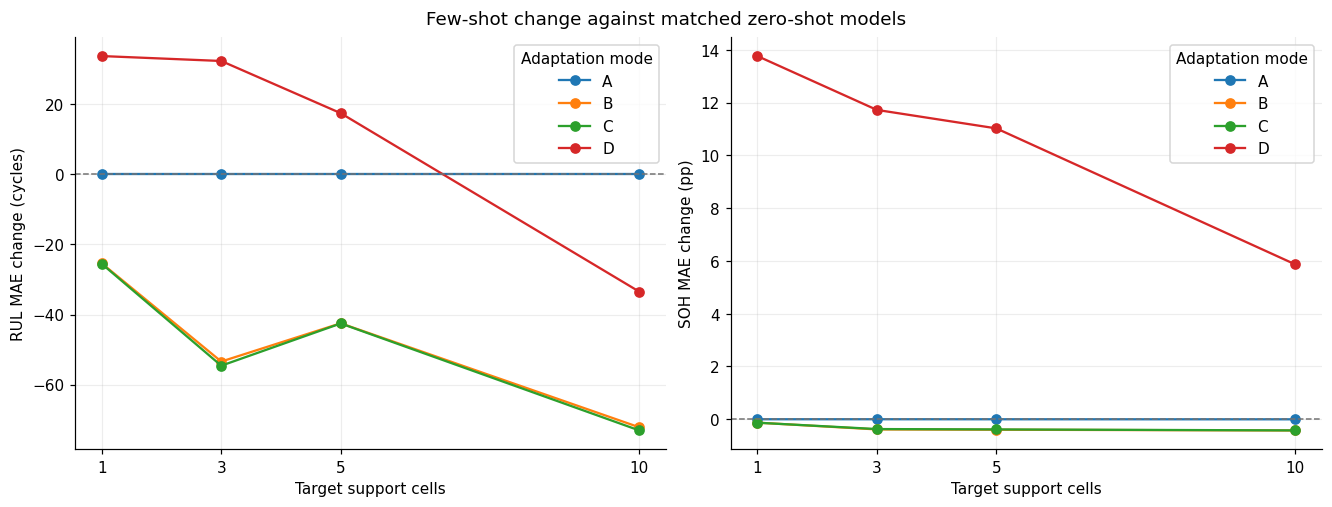

In [65]:
print("CONFORMAL CALIBRATION: ASSUMPTIONS AND LIMITATIONS")
print("• Finite-sample split-conformal coverage is conditional on calibration and test cells being exchangeable.")
print("• Stratifying by dataset helps preserve composition; it does not prove exchangeability across chemistries, labs, or protocols.")
print("• LODO/LOCO results under domain shift are empirical transfer coverage, not formal conformal guarantees.")
print("• Calibration uses one maximum pre-EOL absolute RUL residual per eligible exact-RUL calibration cell.")
print("• Fewer than 9 eligible calibration cells is insufficient; if rank > n, the interval is unbounded.")


from pathlib import Path

out = Path(CFG.OUT_DIR)
histories = sorted((out / 'training_checkpoints').glob('*_epochs.csv'))
if histories:
    pd.concat([pd.read_csv(path) for path in histories], ignore_index=True).to_csv(
        out / 'all_training_epoch_history.csv', index=False
    )

# Compare every shared seed and every shared exact pre-EOL cell for the two
# benchmark models. Point estimates and uncertainty use equal cell weight here.
def load_baseline_cell_errors(path):
    frame = pd.read_csv(path, usecols=['cell_id', 'rul_true', 'rul_pred', 'exact_mask', 'pre_eol_mask'])
    eligible = frame.loc[(frame['exact_mask'] > 0.5) & (frame['pre_eol_mask'] > 0.5)].copy()
    eligible['error'] = (eligible['rul_pred'] - eligible['rul_true']).abs()
    return eligible.groupby('cell_id')['error'].mean().to_dict()

paired_rows = []
for seed in CFG.SEEDS:
    bx_path = out / f'baseline_pred_seed{seed}_10.csv'
    et_path = out / f'baseline_pred_seed{seed}_4.csv'
    if bx_path.exists() and et_path.exists():
        bx = load_baseline_cell_errors(bx_path)
        et = load_baseline_cell_errors(et_path)
        n_shared = len(bx.keys() & et.keys())
        if n_shared:
            mean, low, high, _ = bc.paired_cell_bootstrap_ci(bx, et, n_boot=CFG.N_BOOTSTRAP, seed=seed)
            paired_rows.append({'seed': seed, 'common_exact_cells': n_shared,
                                'BatteryX_minus_ExtraTrees_cycles': mean,
                                'CI_2.5%': low, 'CI_97.5%': high})
if paired_rows:
    paired = pd.DataFrame(paired_rows)
    paired.to_csv(out / 'extra_trees_paired_rul_comparison.csv', index=False)
    display(paired.round(2))

few = FEW_SHOT_DF
if not few.empty and few['status'].eq('completed').any():
    completed_few = few.loc[few['status'].eq('completed')].copy()
    zero = completed_few.loc[completed_few['mode'].eq('Zero-shot'),
        ['target_dataset', 'seed', 'RUL_MAE', 'SOH_MAE_proj']].rename(
        columns={'RUL_MAE': 'zero_RUL_MAE', 'SOH_MAE_proj': 'zero_SOH_MAE'})
    delta = completed_few.loc[completed_few['mode'].ne('Zero-shot')].merge(
        zero, on=['target_dataset', 'seed'], how='inner', validate='many_to_one')
    delta['RUL_MAE_change_cycles'] = delta['RUL_MAE'] - delta['zero_RUL_MAE']
    delta['SOH_MAE_change_pp'] = 100 * (delta['SOH_MAE_proj'] - delta['zero_SOH_MAE'])
    delta.to_csv(out / 'few_shot_matched_deltas.csv', index=False)
    if not delta.empty:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
        for mode, part in delta.groupby('mode'):
            medians = part.groupby('k_shots')[['RUL_MAE_change_cycles', 'SOH_MAE_change_pp']].median()
            for ax, metric, label in zip(axes, medians.columns, ['RUL MAE change (cycles)', 'SOH MAE change (pp)']):
                ax.plot(medians.index, medians[metric], marker='o', label=mode)
                ax.set(xlabel='Target support cells', ylabel=label, xticks=CFG.K_SHOTS)
        for ax in axes:
            ax.axhline(0, color='0.45', linestyle='--', linewidth=1)
            ax.grid(alpha=.22)
            ax.legend(title='Adaptation mode')
        fig.suptitle('Few-shot change against matched zero-shot models')
        fig.savefig(out / 'few_shot_matched_deltas.png', dpi=160)
        plt.show()
        plt.close(fig)


In [66]:
print('Training results, charts, and standalone inference files are available in:', CFG.OUT_DIR)
print('The large frontend ZIP is deferred to the frontend stage.')

Training results, charts, and standalone inference files are available in: /kaggle/working/batteryx_training_v3
The large frontend ZIP is deferred to the frontend stage.


## Reproducibility and interpretation notes

- The setup cell embeds and writes the exact same `batteryx_core.py` source that the notebook imports.
- All train, validation, calibration and test partitions are cell-disjoint. In five-fold evaluation, every cell is assigned to exactly one test fold, including singleton dataset strata.
- SOH is supervised over valid observed cycles. Exact RUL loss, RUL metrics and cell-level conformal calibration use pre-EOL exact observations only. Post-EOL zero-RUL rows are retained in prediction exports but do not improve the pre-EOL RUL score.
- Right-censored cells contribute a lower-bound censoring loss; they are not treated as exact EOL observations.
- Operational EOL is the first observed cycle in a run of three consecutive measured SOH values at or below 80% of the initial valid discharge capacity. This is a project label rule, not a universal battery-standard definition.
- CALCE capacity is extracted as the increment in the negative-current discharge step within each `Cycle_Index`; summary sheets and cumulative workbook totals are not treated as individual cycles. C-rates are derived from measured current where available. Unobserved conditions remain missing and are imputed from the fit partition only.
- NASA records are filtered to a dominant temperature/current regime. Charge C-rate is left missing because the discharge-only record extraction does not independently establish it.
- BatteryLife cells without nominal-capacity metadata are skipped rather than assigned an arbitrary 1.1 Ah value. Missing C-rate metadata remains missing.
- Split-conformal coverage requires exchangeability between calibration and test cells. Dataset stratification does not establish that assumption; cross-domain LODO/LOCO results are empirical transfer results only.
- The included synthetic unit tests and static checks validate software invariants. They do not validate raw data parsing on the user's Kaggle files or establish scientific model performance. Run the notebook from top to bottom on Kaggle and inspect `label_audit.csv`, loader warnings, and fold outputs before using results.
